# Importing Packages

In [1]:
import os
import re
import fiona

import pandas as pd
import geopandas as gpd
import numpy as np

import plotly.graph_objects as go
import plotly.express as px
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots

import xarray as xr
import rioxarray

from scipy.stats import pearsonr
from scipy.stats import gaussian_kde


import math
from scipy.stats import mannwhitneyu
from scipy.stats import pearsonr, spearmanr
import pymannkendall as mk

from IPython.display import display, HTML
import base64
import io

from scipy.stats import genextreme as gev


# Settings

In [2]:
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None)  # Show all columns
# pd.reset_option('display.max_rows')
# pd.reset_option('display.max_columns')


# Paths

In [2]:
# hydro data preparation
hydro_data_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Data\Processed_Data"
hydro_file = 'Hydro_discharge_hist_data_slct_stations.csv'

In [3]:
# ArcGIS pro dir
on_arcgis_dir = r"C:\Ellie_Masters\Main\ArcGIS_Projects\ONTARIO_Processing"

# final drainage area geopackage and layer
drainage_area_gpkg = 'DrainageArea.gpkg'
on_process_gdb = 'ONTARIO_Processing.gdb'

drainage_area_layer = 'ON_Drainage_Area_Final_Selection'

In [4]:
# ERA5 Dir
era5_combined_dr = r"C:\Ellie_Masters\Main\ERA5\ON_Daily\combined_saved"

In [5]:
# saving directories
reprocessed_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Data\Reprocessed_Data"

# saved utputs
selected_hydro_file = "ON_Hydro_Historical_Data_1985_2020_Final_Selection.csv"

In [6]:
final_covs = "ON_Final_Complete_ECA_Climate_Cov_Data_1985_2020.csv"

# Output Files Loading

In [8]:
# Hydro selected data
os.chdir(reprocessed_dir)
clean_hydro_data = pd.read_csv("ON_Hydro_Historical_Data_1985_2020_Final_Selection.csv")

In [9]:
# Climate Cov Data
os.chdir(reprocessed_dir)
climate_covs = pd.read_csv("ON_Climate_Covariates_final_ERA5.csv")

In [10]:
os.chdir(reprocessed_dir)
final_covariates = pd.read_csv(final_covs)

# FUNCTIONS

## f / Completeness

### Completeness: finding missing years in hydro data

In [20]:
# function for choosing hydrostation data for that station
def filter_dataframe(df, column_name, target_value):
    """
    Filters a DataFrame or GeoDataFrame based on a specified column and target value.

    Parameters:
    ----------
    df : pandas.DataFrame or geopandas.GeoDataFrame
        The input DataFrame or GeoDataFrame to filter.
    
    column_name : str
        The name of the column on which to apply the filter.
    
    target_value : Any
        The target value to filter the rows. Rows where the specified column equals
        this value will be returned.

    Returns:
    -------
    filtered_df : pandas.DataFrame or geopandas.GeoDataFrame
        A subset of the original DataFrame/GeoDataFrame where the specified column 
        matches the target value.

    Raises:
    ------
    ValueError:
        If the provided column name does not exist in the DataFrame.
    
    Examples:
    --------
    >>> data = {'ID': [1, 2, 3, 4], 'Type': ['A', 'B', 'A', 'C']}
    >>> df = pd.DataFrame(data)
    >>> result = filter_dataframe(df, 'Type', 'A')
    >>> print(result)
       ID Type
    0   1    A
    2   3    A
    """
    # Check if the column exists in the DataFrame
    if column_name not in df.columns:
        raise ValueError(f"Column '{column_name}' not found in the DataFrame.")
    
    # Filter the DataFrame based on the target value
    filtered_df = df[df[column_name] == target_value]
    
    return filtered_df

# Example usage:
# data = {'ID': [1, 2, 3, 4], 'Type': ['A', 'B', 'A', 'C']}
# df = pd.DataFrame(data)
# result = filter_dataframe(df, 'Type', 'A')
# print(result)


In [8]:
# Function for checking completeness
def check_missing_years(df, year_column, start_year=1985, end_year=2020):
    """
    Checks for missing years in a specified range within a DataFrame.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing the year data.
    
    year_column : str
        The name of the column containing the years.
    
    start_year : int, optional
        The starting year of the range (default is 1985).
    
    end_year : int, optional
        The ending year of the range (default is 2020).
    
    Returns:
    -------
    int
        Number of missing years within the specified range.
    
    Examples:
    --------
    >>> data = {'Year': [1985, 1986, 1987, 1989, 1990, 2020]}
    >>> df = pd.DataFrame(data)
    >>> check_missing_years(df, 'Year')
    32
    """
    # Generate the complete range of years
    complete_years = set(range(start_year, end_year + 1))
    
    # Extract unique years from the DataFrame
    existing_years = set(df[year_column].unique())
    
    # Find the difference to get missing years
    missing_years = sorted(complete_years - existing_years)
    number_of_missing_years = len(missing_years)
    
    return number_of_missing_years

# Example usage:
# data = {'Year': [1900, 1901, 1985, 1986, 1987, 1989, 1990, 2020, 2021]}
# df = pd.DataFrame(data)
# missing = check_missing_years(df, 'Year')
# print("Number of missing years:", missing)


In [9]:
def compute_missing_years_for_stations(hydro_df, selected_stations, year_column='Year', start_year=1985, end_year=2020):
    """
    Computes the missing years and their count for each station and returns a DataFrame.

    Parameters:
    ----------
    hydro_df : pandas.DataFrame
        The input DataFrame containing hydro data.
    
    selected_stations : list
        List of station IDs to check.
    
    year_column : str, optional
        The name of the column containing the years (default is 'Year').
    
    start_year : int, optional
        The starting year of the range (default is 1985).
    
    end_year : int, optional
        The ending year of the range (default is 2020).
    
    Returns:
    -------
    pandas.DataFrame
        A DataFrame containing station IDs, number of missing years, and the specific missing years,
        sorted in descending order by the number of missing years.
    """
    results = []
    for station in selected_stations:
        selected_df = filter_dataframe(hydro_df, 'hydro_station_id', station)
        
        # Generate the complete range of years
        complete_years = set(range(start_year, end_year + 1))
        # Extract unique years from the filtered DataFrame
        existing_years = set(selected_df[year_column].unique())
        
        # Find the missing years
        missing_years = sorted(complete_years - existing_years)
        number_of_years_missing = len(missing_years)
        
        results.append({
            'Station ID': station,
            'Missing Years Count': number_of_years_missing,
            'Missing Years': missing_years
        })
    
    # Convert results to DataFrame and sort by 'Missing Years Count' in descending order
    result_df = pd.DataFrame(results).sort_values(by='Missing Years Count', ascending=False).reset_index(drop=True)
    
    return result_df

# Example usage:
# selected_stations = ['04CA003', '04CA004', '04CA005']
# result_df = compute_missing_years_for_stations(hydro_df, selected_stations)
# print(result_df)


## f / Homogenity

In [10]:

def pettitt_test(data):
    """
    Perform Pettitt's test for a change point in a time series.
    
    Parameters:
    ----------
    data : array-like
        Time series data (must be 1D).
    
    Returns:
    -------
    change_point : int
        Index of the detected change point.
    
    p_value : float
        p-value associated with the change point.
    
    k_statistic : float
        Test statistic at the change point.
    """
    n = len(data)
    rank = np.argsort(np.argsort(data))
    U = np.zeros(n)

    for t in range(n):
        U[t] = 2 * np.sum(rank[:t + 1]) - (t + 1) * n

    K = np.abs(U).max()
    change_point = np.abs(U).argmax()
    p_value = 2 * np.exp((-6 * K**2) / (n**3 + n**2))

    return change_point, p_value, K

In [11]:
def snht_test(data):
    """
    Perform Standard Normal Homogeneity Test (SNHT) on a time series.
    
    Parameters:
    ----------
    data : array-like
        Time series data (must be 1D).
    
    Returns:
    -------
    change_point : int
        Index of the detected change point.
    
    max_stat : float
        Maximum test statistic.
    """
    n = len(data)
    overall_mean = np.mean(data)
    T = np.zeros(n)

    for i in range(1, n - 1):
        mean1 = np.mean(data[:i])
        mean2 = np.mean(data[i:])
        std_dev = np.std(data)
        T[i] = i * ((mean1 - overall_mean) / std_dev)**2 + (n - i) * ((mean2 - overall_mean) / std_dev)**2

    change_point = np.argmax(T)
    max_stat = T[change_point]
    
    return change_point, max_stat


In [12]:
def buishand_test(data):
    """
    Perform Buishand Range Test for homogeneity in a time series.
    
    Parameters:
    ----------
    data : array-like
        Time series data (must be 1D).
    
    Returns:
    -------
    change_point : int
        Index of the detected change point.
    
    Q : float
        Test statistic for Buishand's test.
    """
    n = len(data)
    mean_data = np.mean(data)
    cumulative_deviation = np.cumsum(data - mean_data)
    Q = np.max(np.abs(cumulative_deviation))
    
    change_point = np.argmax(np.abs(cumulative_deviation))
    return change_point, Q


In [13]:
def check_selected_stations_homogeneity(df, selected_stations, station_column='hydro_station_id', 
                                        value_column='Max_discharge', start_year=None, end_year=None):
    """
    Checks homogeneity of maximum discharge data for a list of selected stations using multiple tests.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing hydro data.
    
    selected_stations : list
        List of station IDs to check for homogeneity.
    
    station_column : str, optional
        The name of the column containing station IDs (default is 'hydro_station_id').
    
    value_column : str, optional
        The name of the column containing the time series data (default is 'Max_discharge').
    
    start_year : int, optional
        Start year for filtering the data (default is None).
    
    end_year : int, optional
        End year for filtering the data (default is None).

    Returns:
    -------
    pandas.DataFrame
        A DataFrame containing station IDs, test results, and homogeneity status.
    """
    results = []

    for station in selected_stations:
        # Filter data for the current station
        selected_df = df[df[station_column] == station]
        
        # Filter by year range if specified
        if start_year and end_year:
            selected_df = selected_df[(selected_df['Year'] >= start_year) & (selected_df['Year'] <= end_year)]
        
        max_discharge_series = selected_df[value_column].dropna().values
        
        if len(max_discharge_series) < 10:
            print(f"Station {station} skipped due to insufficient data.")
            continue

        # Run Pettitt's test
        change_point_pettitt, p_value_pettitt, _ = pettitt_test(max_discharge_series)
        status_pettitt = 'Non-Homogeneous' if p_value_pettitt < 0.01 else 'Homogeneous'
        
        # Run SNHT
        change_point_snht, max_stat_snht = snht_test(max_discharge_series)
        status_snht = 'Non-Homogeneous' if max_stat_snht > 7.5 else 'Homogeneous'  # Threshold of 7.5 is commonly used
        
        # # Run Buishand's test
        # change_point_buishand, Q_buishand = buishand_test(max_discharge_series)
        # status_buishand = 'Non-Homogeneous' if Q_buishand > 5 else 'Homogeneous'  # Example threshold
        
        results.append({
            'Station ID': station,
            'Pettitt P-Value': p_value_pettitt,
            'Pettitt Change Point': change_point_pettitt,
            'Pettitt Status': status_pettitt,
            'SNHT Change Point': change_point_snht,
            'SNHT Statistic': max_stat_snht,
            'SNHT Status': status_snht,
            # 'Buishand Change Point': change_point_buishand,
            # 'Buishand Statistic': Q_buishand,
            # 'Buishand Status': status_buishand
        })

    result_df = pd.DataFrame(results).sort_values(by='Pettitt P-Value')
    return result_df


## f / Cleaning Hydrollgical data and saving 

In [14]:
def subset_and_rearrange_hydro_df(hydro_df, selected_stations, start_year=1984, end_year=2021, 
                                  save=False, save_dir=None, file_name=None):
    """
    Subsets hydro_df for the selected stations and years, rearranges columns in a specified order,
    and optionally saves the resulting DataFrame as a CSV file.

    Parameters:
    ----------
    hydro_df : pandas.DataFrame
        The input DataFrame containing hydrological data.
    
    selected_stations : list
        List of station IDs to subset.
    
    start_year : int, optional
        The starting year for the subset (default is 1985).
    
    end_year : int, optional
        The ending year for the subset (default is 2020).
    
    save : bool, optional
        Whether to save the resulting DataFrame as a CSV file (default is False).
    
    save_dir : str, optional
        The directory where the CSV file should be saved (required if save=True).
    
    file_name : str, optional
        The name of the CSV file (required if save=True).

    Returns:
    -------
    pandas.DataFrame
        A subset of the original DataFrame with selected stations and years, and reordered columns.

    Raises:
    ------
    ValueError:
        If save=True but either save_dir or file_name is not provided.
    """
    # Subset for selected stations
    subset_df = hydro_df[hydro_df['hydro_station_id'].isin(selected_stations)]
    
    # Subset for the years between start_year and end_year (inclusive)
    subset_df = subset_df[(subset_df['Year'] >= start_year) & (subset_df['Year'] <= end_year)]
    
    # Specify the desired column order
    column_order = [
        'hydro_station_id', 'hydro_station_name', 'Province', 'Region', 'Basin', 
        'Year', 'MM-DD', 'Month', 'Day', 'Date', 
        'Max_discharge', 'MIN_discharge', 'Discharge_unit'
    ]
    
    # Reorder the columns
    subset_df = subset_df[column_order]
    
    # Save to CSV if save=True
    if save:
        if not save_dir or not file_name:
            raise ValueError("Both 'save_dir' and 'file_name' must be provided when save=True.")
        
        # Ensure the directory exists
        os.makedirs(save_dir, exist_ok=True)
        
        # Construct the full file path
        file_path = os.path.join(save_dir, file_name)
        
        # Save the DataFrame as a CSV file
        subset_df.to_csv(file_path, index=False)
        print(f"File saved at: {file_path}")
    
    return subset_df

# Example usage:
# selected_stations = ['05QE008', '02BF001', '05QA004', '04MF001']
# result_df = subset_and_rearrange_hydro_df(hydro_df, selected_stations, save=True, save_dir='output', file_name='hydro_subset.csv')
# result_df.head()


## f / ECA calculations

In [7]:
def convert_to_long_format(df, id_column, value_name):
    """
    Converts a wide-format DataFrame to a long format with a specified value column name,
    and sorts the result by the identifier column and year.

    Parameters:
    - df (pd.DataFrame): The input DataFrame in wide format, where columns represent years and rows represent unique IDs.
    - id_column (str): The name of the identifier column in `df` (e.g., 'ID_hydro_st') that groups data by unique IDs.
    - value_name (str): The name for the values in the new long-format column (e.g., 'harvest_area_m2').

    Returns:
    - pd.DataFrame: A long-format DataFrame with three columns:
        - The identifier column specified by `id_column`.
        - A 'Year' column representing the former column names (years) from the wide-format DataFrame.
        - A column with the name provided in `value_name`, containing the corresponding values from `df`.

    Example:
    >>> data = {
    ...     'ID_hydro_st': [1, 2],
    ...     '1985': [1000, 2000],
    ...     '1986': [1500, 2500],
    ...     '1987': [1200, 2200]
    ... }
    >>> df = pd.DataFrame(data)
    >>> convert_to_long_format(df, 'ID_hydro_st', 'harvest_area_m2')
       ID_hydro_st  Year  harvest_area_m2
    0            1  1985             1000
    1            1  1986             1500
    2            1  1987             1200
    3            2  1985             2000
    4            2  1986             2500
    5            2  1987             2200
    """
    # Convert to long format
    df_long = pd.melt(df, id_vars=[id_column], var_name='Year', value_name=value_name)
    
    # Sort by id_column and Year to group same IDs together
    df_long = df_long.sort_values(by=[id_column, 'Year']).reset_index(drop=True)
    
    return df_long

In [8]:
# Function to merge the two DataFrames
def merge_harvest_fire_data(harvest_df, fire_df):
    """
    Merges two DataFrames on 'ID_hydro_st' and 'Year' columns.

    Parameters:
    - harvest_df (pd.DataFrame): DataFrame containing harvest area data with columns 'ID_hydro_st', 'Year', and 'harvest_area_m2'.
    - fire_df (pd.DataFrame): DataFrame containing fire area data with columns 'ID_hydro_st', 'Year', and 'fire_area_m2'.

    Returns:
    - pd.DataFrame: A merged DataFrame with 'ID_hydro_st', 'Year', 'harvest_area_m2', and 'fire_area_m2' columns.
    """
    merged_df = pd.merge(harvest_df, fire_df, on=['ID_hydro_st', 'Year'], how='inner')
    return merged_df


In [9]:
def calculate_ECA_harvest(df, harvest_area_column, output_column):
    """
    Calculates the Equivalent Clearcut Area (ECA) for each year in a DataFrame using a specified area column.
    
    Parameters:
    - df (pd.DataFrame): A DataFrame with a 'Year' column and an area column specified by the user.
    - harvest_area_column (str): The name of the column to use for area values.
    - output_column (str): The name of the new column to store the calculated ECA values.
    
    Returns:
    - pd.DataFrame: The input DataFrame with an additional column for the calculated ECA, using the specified output column name.
    """
    # Sort by year to ensure proper cumulative calculations
    df = df.sort_values('Year').reset_index(drop=True)
    
    # Initialize the ECA column with the specified output column name
    df[output_column] = 0.0
    
    # Loop through each year to calculate cumulative ECA
    for i, row in df.iterrows():
        year = row['Year']
        area = row[harvest_area_column]
        
        # Start with the current year's ECA contribution
        current_year_ECA = area * (1 - 0)  # Since current year HR is always zero
        cumulative_ECA = current_year_ECA
        
        # Add contributions from previous years
        for j in range(i):
            tsd = i - j  # Time since disturbance
            prev_area = df.at[j, harvest_area_column]
            
            # Calculate HR based on TSD
            if tsd <= 8:
                hr = 0
            else:
                hr = max(0, 16.71 - 2.19 * tsd + 0.12 * tsd**2)  # HR should not go negative
            
            # Add adjusted area to cumulative ECA
            cumulative_ECA += prev_area * (1 - hr / 100)
        
        # Update the ECA for the current year with the specified output column
        df.at[i, output_column] = cumulative_ECA

    return df


In [10]:
def calculate_ECA_fire(df, fire_area_column, output_column):
    """
    Calculates the Equivalent Clearcut Area (ECA) for each year in a DataFrame using a specified area column.
    
    Parameters:
    - df (pd.DataFrame): A DataFrame with a 'Year' column and an area column specified by the user.
    - harvest_area_column (str): The name of the column to use for area values.
    - output_column (str): The name of the new column to store the calculated ECA values.
    
    Returns:
    - pd.DataFrame: The input DataFrame with an additional column for the calculated ECA, using the specified output column name.
    """
    # Sort by year to ensure proper cumulative calculations
    df = df.sort_values('Year').reset_index(drop=True)
    
    # Initialize the ECA column with the specified output column name
    df[output_column] = 0.0
    
    # Loop through each year to calculate cumulative ECA
    for i, row in df.iterrows():
        year = row['Year']
        area = row[fire_area_column]
        
        # Start with the current year's ECA contribution
        current_year_ECA = area * (1 - 0)  # Since current year HR is always zero
        cumulative_ECA = current_year_ECA
        
        # Add contributions from previous years
        for j in range(i):
            tsd = i - j  # Time since disturbance
            prev_area = df.at[j, fire_area_column]
            
            # Calculate HR based on TSD
            if tsd <= 8:
                hr = 0
            else:
                # we use wildfire basal area furmula and the reference basal area we assumed is 
                hr = max(0, 5.81 + 0.26 * tsd - 0.001 * tsd**2)  # HR should not go negative
            
            # Add adjusted area to cumulative ECA
            cumulative_ECA += prev_area * (1 - hr / 15)
        
        # Update the ECA for the current year with the specified output column
        df.at[i, output_column] = cumulative_ECA

    return df


In [11]:
def calculate_ECA_for_all_stations(df, id_column='ID_hydro_st', harvest_area_column='harvest_area_ha', 
                                   fire_area_column='fire_area_ha', drainage_area_column='drainage_area_ha', 
                                   save=False, save_path=None, file_name='ECA_results.csv'):
    """
    Function to calculate ECA percentages for harvest and fire for all stations 
    using existing functions and return a new DataFrame with results.
    
    Parameters:
    - df: DataFrame containing station data.
    - id_column: Column name representing station IDs.
    - harvest_area_column: Column name representing harvest area in hectares.
    - fire_area_column: Column name representing fire area in hectares.
    - drainage_area_column: Column name representing drainage area in hectares.
    - save: Boolean indicating whether to save the resulting DataFrame to a CSV file.
    - save_path: Directory path where the CSV file should be saved (required if save=True).
    - file_name: Name of the CSV file to be saved (default is 'ECA_results.csv').
    
    Returns:
    - A new DataFrame with ECA and percentage columns for all stations.
    """
    
    result_list = []  # List to store results for each station
    
    # Get unique station IDs
    unique_stations = df[id_column].unique()
    
    # Loop through each station
    for station_id in unique_stations:
        # Filter DataFrame for the current station
        station_df = filter_dataframe(df, column_name=id_column, target_value=station_id)
        
        # Calculate ECA for harvest
        station_df = calculate_ECA_harvest(station_df, harvest_area_column=harvest_area_column, output_column='ECA_Harvest_ha')
        station_df['ECA_harvest_perc'] = station_df['ECA_Harvest_ha'] / station_df[drainage_area_column] * 100
        
        # Calculate ECA for fire
        station_df = calculate_ECA_fire(station_df, fire_area_column=fire_area_column, output_column='ECA_Fire_ha')
        station_df['fire_perc'] = station_df['ECA_Fire_ha'] / station_df[drainage_area_column] * 100

        station_df['Total_ECA_percentage'] = station_df['fire_perc'] + station_df['ECA_harvest_perc']
        
        # Append the processed DataFrame to the result list
        result_list.append(station_df)
    
    # Concatenate all results into a single DataFrame
    final_df = pd.concat(result_list, ignore_index=True)
    
    # Save the final DataFrame if save=True
    if save:
        if save_path is None:
            raise ValueError("save_path must be provided if save=True")
        full_path = f"{save_path}/{file_name}"
        final_df.to_csv(full_path, index=False)
        print(f"File saved successfully at: {full_path}")
    
    return final_df


In [12]:
def plot_ECA_station_data(df):
    # Get unique station IDs
    unique_stations = df['ID_hydro_st'].unique()
    
    for station_id in unique_stations:
        # Subset the dataframe for the current station ID
        station_df = df[df['ID_hydro_st'] == station_id]
        
        # Convert the drainage area to hectares
        drainage_area_ha = station_df['drainage_area_ha'].iloc[0] / 10_000
        
        # Create the figure
        fig = go.Figure()
        
        # Add bar for 'fire_area%' (color: f87060)
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['fire_area_ha'] / drainage_area_ha * 100 ,
            name='Fire Area %',
            yaxis='y2',
            marker_color='#f87060'
        ))
        
        # Add bar for 'harvest_area%' (color: fed766, beb7a4)
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['harvest_area_ha'] / drainage_area_ha * 100,
            name='Harvest Area %',
            yaxis='y2',
            marker_color='#beb7a4'
        ))
        
        # Add line with dots for 'total_ECA_%' over 'Year' (color: 102542)
        fig.add_trace(go.Scatter(
            x=station_df['Year'],
            y=station_df['Total_ECA_percentage'],
            mode='lines+markers',
            name='Total ECA %',
            line=dict(color='#102542'),
            marker=dict(symbol='circle', size=8)
        ))
        
        # Update layout for dual y-axes and formatting
        fig.update_layout(
            title=f'Station {station_id} - Total ECA %, Harvest Area %, and Fire Area % Over Years (Drainage Area: {drainage_area_ha:.2f} ha)',
            xaxis=dict(
                title='Year',
                tickangle=45,
                tickmode='linear'
            ),
            yaxis=dict(
                title='Total ECA %',
                showgrid=True
            ),
            yaxis2=dict(
                title='Harvest and Fire Area %',
                overlaying='y',
                side='right'
            ),
            plot_bgcolor='whitesmoke',
            font=dict(family='Times New Roman', size=14),
            legend=dict(x=0.01, y=0.99)
        )

        # Show and export the plot as PDF
        fig.write_image(f"station_{station_id}_eca_plot.pdf")
        fig.show()


## f / Climate Covariates

In [35]:
def extract_variable_full_names(ds):
    """
    Extracts the GRIB_name attribute from each variable in the dataset and stores them 
    in a dictionary with the key 'variable_full_name'.

    Parameters:
    ds (xarray.Dataset): The NetCDF dataset containing variables with GRIB_name attributes.

    Returns:
    dict: A dictionary where the keys are variable names and the values are their corresponding GRIB_name,
    with the key 'variable_full_name'.
    """
    variable_full_names = {}
    
    # Loop through each variable in the dataset
    for var_name in ds.data_vars:
        # Check if the variable has a 'GRIB_name' attribute
        if 'GRIB_name' in ds[var_name].attrs:
            # Store the variable name and its GRIB_name as 'variable_full_name' in the dictionary
            variable_full_names[var_name] = ds[var_name].attrs['GRIB_name']
    
    return variable_full_names

In [36]:
def clip_netcdf_by_geometry(ds, geometry_gdf, station_id, output_file=None):
    """
    Clips a NetCDF file by the geometry corresponding to the given station ID in the GeoDataFrame 
    and returns the clipped dataset.

    Parameters:
    ds (xarray.Dataset): The NetCDF dataset with multiple days.
    geometry_gdf (geopandas.GeoDataFrame): A GeoDataFrame containing the geometry for clipping.
    station_id (int or str): The station ID in the 'ID_hydro_st' column to use for clipping.
    output_file (str, optional): If provided, the clipped dataset will be saved to this NetCDF file.
    
    Returns:
    xr.Dataset: Clipped xarray dataset.
    """
    # Ensure CRS is set for the NetCDF data
    if not ds.rio.crs:
        ds = ds.rio.write_crs("EPSG:4326", inplace=True)
    
    # Align GeoDataFrame CRS to match NetCDF
    if geometry_gdf.crs != ds.rio.crs:
        geometry_gdf = geometry_gdf.to_crs(ds.rio.crs)
    
    # Subset the GeoDataFrame by station ID
    selected_geometry_gdf = geometry_gdf[geometry_gdf['ID_hydro_st'] == station_id]
    if selected_geometry_gdf.empty:
        raise ValueError(f"No geometry found for station ID {station_id}")
    
    # Dictionary to store clipped variables
    masked_data = {}
    
    # Loop through all variables
    for var in ds.data_vars:
        if 'longitude' in ds[var].dims and 'latitude' in ds[var].dims:
            try:
                ds[var] = ds[var].rio.set_spatial_dims(x_dim='longitude', y_dim='latitude', inplace=True)
                ds[var] = ds[var].rio.write_crs("EPSG:4326", inplace=True)
                masked_data[var] = ds[var].rio.clip(
                    selected_geometry_gdf.geometry,
                    geometry_gdf.crs,
                    drop=True,
                    all_touched=True  # Include cells that are partially touched
                )
            except Exception as e:
                print(f"Error clipping variable {var}: {e}")
    
    # Combine clipped variables
    clipped_ds = xr.Dataset(masked_data)
    
    # Save output if specified
    if output_file:
        clipped_ds.to_netcdf(output_file)
        print(f"Clipped dataset saved to {output_file}")
    
    return clipped_ds


In [37]:
def subset_netcdf_by_date(ds, date, days):
    """
    Subsets a NetCDF dataset based on the given date and number of days.

    Parameters:
    ds (xarray.Dataset): The NetCDF dataset with a 'time' dimension.
    date (str or pd.Timestamp): The end date for the subset (e.g., '2024-10-01').
    days (int): The number of days to include in the subset. For 10 days, input 9.

    Returns:
    xarray.Dataset: The subsetted dataset.
    """
    # Convert date to a pandas Timestamp if it's not already
    date = pd.to_datetime(date)
    
    # Calculate the start date by subtracting the given number of days
    start_date = date - pd.Timedelta(days=days)
    
    # Subset the dataset by the time dimension using the calculated start and end dates
    subset_ds = ds.sel(valid_time=slice(start_date, date))
    
    return subset_ds

In [38]:
def calculate_climate_metrics(subset_ds, peak_date, drainage_area_m2=None, periods=[1, 3, 7, 15, 30, 40, 60, 80], debug=False):
    """
    Calculate various climate metrics for specified periods before a peak discharge date.

    Parameters:
    - subset_ds (xr.Dataset): The clipped NetCDF dataset containing all variables.
    - peak_date (str): The peak discharge date (format: YYYY-MM-DD).
    - drainage_area_m2 (float, optional): The area of the drainage basin in square meters (used for some calculations).
    - periods (list): List of periods in days for cumulative calculations.
    - debug (bool): Whether to print debugging information.

    Returns:
    - dict: A dictionary with calculated metrics for each period.
    """
    # Convert peak_date to numpy datetime
    peak_date = np.datetime64(peak_date)
    
    # Initialize results dictionary
    results = {}
    
    # Loop through each period
    for period in periods:
        # Subset data for the period before the peak date
        start_date = peak_date - np.timedelta64(period, 'D')
        period_subset = subset_ds.sel(valid_time=slice(start_date, peak_date))
        
        if debug:
            print(f"\nProcessing period: {period} days\n")
        
        # 1. Temperature Metrics
        if 't2m' in period_subset:
            temperatures = period_subset['t2m'].mean(dim=('latitude', 'longitude'))  # Keep as kelvin to avoid - values
            temperatures = temperatures.values
            if len(temperatures) > 1:
                # Calculate temperature change
                temp_change = (temperatures[-1] - temperatures[0]) / period
                # Keep WR positive if warming, otherwise set to 0
                results[f"WR_{period}_days"] = max(temp_change, 0)
                results[f"Max_temp_{period}_days_K"] = np.nanmax(temperatures)
        
        # 2. Evaporation
        if 'e' in period_subset:
            total_evaporation_sum = period_subset['e'].sum(dim=('latitude', 'longitude', 'valid_time')) * 1000 # -1 is because evaporation is - in values
            results[f"Evaporation_Sum_{period}_days_mm"] = abs(total_evaporation_sum.item())  # in mm
        
        # 3. Snow Evaporation
        if 'es' in period_subset:
            total_snow_evaporation_sum = period_subset['es'].sum(dim=('latitude', 'longitude', 'valid_time')) * 1000
            results[f"Snow_Evaporation_Sum_{period}_days_mm"] = abs(total_snow_evaporation_sum.item())  # in mm
        
        # 4. Snowfall
        if 'sf' in period_subset:
            total_snowfall_sum = period_subset['sf'].sum(dim=('latitude', 'longitude', 'valid_time')) * 1000
            results[f"Snowfall_Sum_{period}_days_mm"] = total_snowfall_sum.item()  # in mm
        
        # 5. Snow Depth (spatial sum, temporal average, reported in cm)
        if 'sd' in period_subset:
            spatial_sum = period_subset['sd'].sum(dim=('latitude', 'longitude'))
            avg_snow_depth_cm = spatial_sum.mean(dim='valid_time') * 100  # Convert to cm
            results[f"Snow_Depth_Avg_{period}_days_cm"] = avg_snow_depth_cm.item()  # in cm

        # 6. Snowmelt (cumulative decrease in snow depth over time, reported in cm)
        if 'sd' in period_subset:
            # Calculate snow depth differences over time
            snow_depth_diff = period_subset['sd'].diff(dim='valid_time')
            # Select only the negative differences (i.e., decreases in snow depth)
            snowmelt_only = snow_depth_diff.where(snow_depth_diff < 0, 0)
            # Sum the negative differences over time and take the mean over latitude and longitude
            total_snowmelt = snowmelt_only.sum(dim='valid_time').mean(dim=('latitude', 'longitude'))
            # Convert from meters to centimeters
            total_snowmelt_cm = total_snowmelt * 100  # Convert to cm
            results[f"Snowmelt_{period}_days_cm"] = abs(total_snowmelt_cm.item())  # Use abs to ensure positive result
        
        # 7. Surface Runoff (spatial sum, temporal total, reported in mm)
        if 'sro' in period_subset:
            spatial_sum = period_subset['sro'].sum(dim=('latitude', 'longitude'))
            temporal_sum = spatial_sum.sum(dim='valid_time')
            total_runoff_mm = temporal_sum * 1000  # Convert to mm
            results[f"Surface_Runoff_Sum_{period}_days_mm"] = total_runoff_mm.item()  # in mm
        
        # 8. Total Column Rainwater (spatial mean, temporal sum, reported in mm)
        if 'tcrw' in period_subset:
            spatial_mean = period_subset['tcrw'].mean(dim=('latitude', 'longitude'))
            temporal_sum = spatial_mean.sum(dim='valid_time')
            results[f"Total_Rainwater_{period}_days_mm"] = temporal_sum.item()  # in mm
        
        # 9. Total Precipitation
        if 'tp' in period_subset:
            total_precipitation_sum = period_subset['tp'].sum(dim=('latitude', 'longitude', 'valid_time')) * 1000
            results[f"Total_Precipitation_Sum_{period}_days_mm"] = total_precipitation_sum.item()  # in mm
        
        # 10. Soil Moisture (max over time, converted to %)
        cumulative_moisture = 0
        for layer in ['swvl1', 'swvl2', 'swvl3']:
            if layer in period_subset:
                spatial_mean = period_subset[layer].mean(dim=('latitude', 'longitude'))
                temporal_max = spatial_mean.max(dim='valid_time') * 100  # Convert to %
                cumulative_moisture += temporal_max
                results[f"{layer}_Soil_Moisture_Max_{period}_days_percent"] = temporal_max.item()  # in %
        if cumulative_moisture:
            results[f"Total_Soil_Moisture_Max_{period}_days_percent"] = cumulative_moisture.item()  # in %

    return results


In [39]:
def process_stations(hydro_hist_data, on_drainage_areas, main_ds, test_st_id=None, save_csv=False, output_dir=None, periods=[1, 3, 5, 7, 15, 30, 40, 60, 80], debug=False):
    """
    Processes climate covariates for given stations using historical hydrological data and NetCDF climate data.

    Parameters:
    - hydro_hist_data (pd.DataFrame): Historical hydrological data containing peak discharge information.
    - on_drainage_areas (gpd.GeoDataFrame): GeoDataFrame containing drainage areas.
    - main_ds (xr.Dataset): The NetCDF dataset containing climate data.
    - test_st_id (list, optional): List of station IDs to process. Defaults to all unique IDs in `on_drainage_areas`.
    - save_csv (bool, optional): Whether to save the resulting DataFrame to a CSV file. Defaults to False.
    - output_dir (str, optional): Directory to save the CSV file if `save_csv` is True. Defaults to None.
    - periods (list, optional): List of periods in days for climate metric calculations. Defaults to [1, 3, 7, 15, 30, 60].
    - debug (bool, optional): Whether to print debugging information. Defaults to False.

    Returns:
    - pd.DataFrame: Final DataFrame containing hydrological and climate covariates.
    """
    # Default to all station IDs if not provided
    if test_st_id is None:
        test_st_id = on_drainage_areas['ID_hydro_st'].unique().tolist()

    # Initialize final DataFrame
    final_df = pd.DataFrame()

    # Loop through each station
    for station in test_st_id:
        if debug:
            print(f"Processing station: {station}")

        # Select hydrological data for the current station
        slcted_hydro_data = hydro_hist_data[
            (hydro_hist_data['hydro_station_id'] == station) #&
            # (hydro_hist_data['Year'] > 1984) &
            # (hydro_hist_data['Year'] < 2021)
        ].copy()

        # Get the drainage area (in m²) for the station
        area_ha = on_drainage_areas.loc[on_drainage_areas['ID_hydro_st'] == station, 'drainage_area_ha'].iloc[0]

        # Clip the NetCDF dataset to the drainage area
        clipped_ds = clip_netcdf_by_geometry(main_ds, on_drainage_areas, station)

        # Loop through each peak date in the selected hydrological data
        for index, row in slcted_hydro_data.iterrows():
            date = row['Date']

            # Subset the NetCDF dataset for the specific date and periods
            subset_ds = subset_netcdf_by_date(clipped_ds, date, max(periods))

            # Calculate climate metrics
            metrics = calculate_climate_metrics(subset_ds, peak_date=date, drainage_area_m2=area_ha, periods=periods, debug=debug)

            # Assign metrics to the corresponding columns (create columns on-the-fly)
            for metric, value in metrics.items():
                slcted_hydro_data.at[index, metric] = value

        # Append the processed data for this station to the final DataFrame
        final_df = pd.concat([final_df, slcted_hydro_data], ignore_index=True)

    # Save the final DataFrame to a CSV file if requested
    if save_csv:
        if output_dir is not None:
            output_filename = "ON_Climate_Covariates_final_ERA5.csv"
            final_df.to_csv(f"{output_dir}/{output_filename}", index=False)
            print(f"Saved results to {output_dir}/{output_filename}")
        else:
            print("Output directory not provided. Skipping file save.")

    return final_df


In [40]:
def process_stations(hydro_hist_data, on_drainage_areas, main_ds, test_st_id=None, save_csv=False, output_dir=None, periods=[1, 3, 5, 7, 15, 30, 40, 60, 80], debug=False):
    """
    Processes climate covariates for given stations using historical hydrological data and NetCDF climate data.

    Parameters:
    - hydro_hist_data (pd.DataFrame): Historical hydrological data containing peak discharge information.
    - on_drainage_areas (gpd.GeoDataFrame): GeoDataFrame containing drainage areas.
    - main_ds (xr.Dataset): The NetCDF dataset containing climate data.
    - test_st_id (list, optional): List of station IDs to process. Defaults to all unique IDs in `on_drainage_areas`.
    - save_csv (bool, optional): Whether to save the resulting DataFrame to a CSV file. Defaults to False.
    - output_dir (str, optional): Directory to save the CSV file if `save_csv` is True. Defaults to None.
    - periods (list, optional): List of periods in days for climate metric calculations. Defaults to [1, 3, 5, 7, 15, 30, 40, 60, 80].
    - debug (bool, optional): Whether to print debugging information. Defaults to False.

    Returns:
    - pd.DataFrame: Final DataFrame containing hydrological and climate covariates.
    """
    # Default to all station IDs if not provided
    if test_st_id is None:
        test_st_id = on_drainage_areas['ID_hydro_st'].unique().tolist()

    # Initialize a list to collect all processed data
    all_stations_data = []

    # Loop through each station
    for station in test_st_id:
        if debug:
            print(f"Processing station: {station}")

        # Select hydrological data for the current station
        slcted_hydro_data = hydro_hist_data[
            (hydro_hist_data['hydro_station_id'] == station)
        ].copy()

        # Get the drainage area (in m²) for the station
        area_ha = on_drainage_areas.loc[on_drainage_areas['ID_hydro_st'] == station, 'drainage_area_ha'].iloc[0]

        # Clip the NetCDF dataset to the drainage area
        clipped_ds = clip_netcdf_by_geometry(main_ds, on_drainage_areas, station)

        # List to store metrics for each row
        station_metrics = []

        # Loop through each peak date in the selected hydrological data
        for index, row in slcted_hydro_data.iterrows():
            date = row['Date']

            # Subset the NetCDF dataset for the specific date and periods
            subset_ds = subset_netcdf_by_date(clipped_ds, date, max(periods))

            # Calculate climate metrics
            metrics = calculate_climate_metrics(subset_ds, peak_date=date, drainage_area_m2=area_ha, periods=periods, debug=debug)

            # Add the index and original row data to the metrics
            row_metrics = row.to_dict()  # Convert the original row to a dictionary
            row_metrics.update(metrics)  # Add the climate metrics
            station_metrics.append(row_metrics)

        # Convert the list of metrics to a DataFrame
        station_df = pd.DataFrame(station_metrics)

        # Append the processed data for this station to the final list
        all_stations_data.append(station_df)

    # Concatenate all station data into a single DataFrame
    final_df = pd.concat(all_stations_data, ignore_index=True)

    # Save the final DataFrame to a CSV file if requested
    if save_csv:
        if output_dir is not None:
            output_filename = "ON_Climate_Covariates_final_ERA5.csv"
            final_df.to_csv(f"{output_dir}/{output_filename}", index=False)
            print(f"Saved results to {output_dir}/{output_filename}")
        else:
            print("Output directory not provided. Skipping file save.")

    return final_df


In [41]:
def calculate_correlations_with_custom_styling(df, station_col='hydro_station_id', target_col='Max_discharge', cmap='coolwarm', font_size=13):
    """
    Calculate the correlation between Max_discharge and other columns for each station,
    excluding the 'Basin' column, and apply custom cell styling for a heatmap-like appearance with adjustable font size.

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - station_col (str): The column representing station IDs.
    - target_col (str): The column for which correlations are calculated with other columns.
    - cmap (str): Colormap to use for background styling.
    - font_size (int): The font size to use for table text.

    Returns:
    - pd.Styler: A Styler object with styled cells and customized formatting.
    """
    # Drop the 'Basin' column if it exists
    df = df.drop(columns=['Basin'], errors='ignore')

    correlations = {}

    # Group by the station column
    grouped = df.groupby(station_col)

    for station, group in grouped:
        # Select only numeric columns
        numeric_data = group.select_dtypes(include='number')

        # Calculate correlation with the target column
        if target_col in numeric_data:
            corr_with_target = numeric_data.corr()[target_col]
            # correlations[station] = corr_with_target.to_dict()
            correlations[station] = corr_with_target.drop(target_col).to_dict()  # Drop self-correlation

    # Convert correlations to a DataFrame
    correlations_df = pd.DataFrame(correlations).transpose()
    correlations_df.index.name = station_col

    # Apply background gradient styling
    styled_df = correlations_df.style.background_gradient(cmap=cmap, axis=None)

    # Add custom CSS for cell size, word wrapping, and font
    styled_df = styled_df.set_table_styles([
        {'selector': 'th', 'props': [('word-wrap', 'break-word'), ('max-width', '100px'), (f'font-size', f'{font_size}px'), ('font-family', 'Times New Roman')]},
        {'selector': 'td', 'props': [('max-width', '50px'), ('height', '30px'), (f'font-size', f'{font_size}px'), ('text-align', 'center'), ('font-family', 'Times New Roman')]},
        {'selector': 'table', 'props': [('table-layout', 'fixed'), ('width', '100%'), ('font-family', 'Times New Roman')]}
    ])

    return styled_df


## f/ Attribution

In [2]:
def extract_station_ids(directory):
    """
    Extracts station IDs from filenames in the given directory.
    Assumes station IDs are the 6-character sequences in the filenames.
    """
    station_ids = set()
    pattern = re.compile(r'_(\d{2}[A-Z]{2}\d{3})')  # Pattern to capture station IDs
    
    for filename in os.listdir(directory):
        match = pattern.search(filename)
        if match:
            station_ids.add(match.group(1))
    
    return sorted(station_ids)  # Sorting for consistency

In [3]:
def get_dataframe(station_id, directory):
    """
    Given a station ID and directory, finds and returns the corresponding dataframe.
    """
    pattern = re.compile(rf'_(\d{{2}}[A-Z]{{2}}\d{{3}})')  # Pattern to match station ID
    
    for filename in os.listdir(directory):
        match = pattern.search(filename)
        if match and match.group(1) == station_id:
            file_path = os.path.join(directory, filename)
            return pd.read_csv(file_path)
    
    return None  # Return None if no matching file is found

I need one function to go and get min rps, max rp and real rps and return them in a list for min_rp_5 yesr or 10 years based on the input return periods series and paths. 

then a function to plot them 
another function to runa test for significant difference between groups of highest and lowest ECA + a test for trend in minumum eca and variable eca

In [26]:
def get_return_levels_across_scenarios(station_id, 
                                       max_path, 
                                       min_path, 
                                       real_scenario_path, 
                                       return_years=[5, 10, 20]):
    """
    Loads return level data for a station from three different scenarios (paths) 
    and organizes them into a dictionary with uniquely accessible variable names.
    
    Handles CSV and Excel files, and adjusts for different column name patterns.
    
    Returns:
    - dict: A dictionary where keys are descriptive variable names (e.g., 'max_eca_rp_5') 
      and values are the corresponding pandas DataFrame (Year + Return Level columns).
    """
    
    # Load max and min scenarios (CSV assumed)
    df_max = get_dataframe(station_id, max_path)
    df_min = get_dataframe(station_id, min_path)
    
    # Load real scenario (might be XLSX or CSV)
    pattern = re.compile(rf'_(\d{{2}}[A-Z]{{2}}\d{{3}})')
    real_file = None
    
    for filename in os.listdir(real_scenario_path):
        match = pattern.search(filename)
        if match and match.group(1) == station_id:
            real_file = os.path.join(real_scenario_path, filename)
            break
    
    if real_file is None:
        raise ValueError(f"No file found for station {station_id} in {real_scenario_path}")
    
    if real_file.endswith(".csv"):
        df_real = pd.read_csv(real_file)
    elif real_file.endswith((".xlsx", ".xls")):
        df_real = pd.read_excel(real_file)
    else:
        raise ValueError(f"Unsupported file format for real scenario: {real_file}")
    
    # Check if any dataset is missing
    if df_max is None or df_min is None or df_real is None:
        raise ValueError(f"Data missing for station {station_id} in one or more scenarios.")
    
    result = {}
    
    for year in return_years:
        col_name_max_min = f"Return_Level_{year}Yrs"
        col_name_real = f"Return_Level_{year}"
        
        if (col_name_max_min not in df_max.columns) or (col_name_max_min not in df_min.columns) or (col_name_real not in df_real.columns):
            print(f"Warning: Column mismatch for year {year} in one or more datasets for station {station_id}. Skipping.")
            continue
        
        result[f"max_eca_rp_{year}"] = df_max[["Year", col_name_max_min]]
        result[f"min_eca_rp_{year}"] = df_min[["Year", col_name_max_min]]
        result[f"real_eca_rp_{year}"] = df_real[["Year", col_name_real]]
    
    return result

In [9]:
def plot_return_levels_batch(return_levels_dict, 
                              scenarios_to_plot='all', 
                              return_years_to_plot=None, 
                              width=900, 
                              height=600,
                              y_tick_step=None,
                              save=False,
                              save_path=None,
                              save_name=None,
                              save_format="svg"):
    """
    Plots return levels from a dictionary in one combined plot, with option to save as vector file.
    Customizes legend labels to show return period and scenario in professional format.
    """
    # Setup base colors
    base_colors = {
        'max': '#f87060',  # Salmonish
        'min': '#102542',  # Navy
        'real': '#beb7a4'  # Brownish
    }
    
    # Slight variations for return periods (lighter/darker)
    color_variations = {
        'max': ['#f87060', '#fa9a8a', '#c94d39'],  # main, lighter, darker salmon
        'min': ['#102542', '#3c5a7d', '#0a1733'],  # main, lighter, darker navy
        'real': ['#beb7a4', '#d6d1c2', '#9b9485']  # main, lighter, darker brown
    }
    
    # Decide which scenarios to plot
    if scenarios_to_plot == 'all':
        scenarios = ['max', 'min', 'real']
    else:
        scenarios = [scenarios_to_plot] if isinstance(scenarios_to_plot, str) else scenarios_to_plot
    
    # Find all return periods available
    available_return_periods = set()
    for key in return_levels_dict.keys():
        _, rp = key.rsplit('_rp_', 1)
        available_return_periods.add(rp)
    available_return_periods = sorted(available_return_periods, key=lambda x: float(x))
    
    # Decide which return periods to plot
    if return_years_to_plot is None:
        return_years = available_return_periods
    else:
        return_years = [str(rp) for rp in return_years_to_plot]  # Make sure as strings
    
    fig = go.Figure()
    
    for scenario in scenarios:
        for idx, rp in enumerate(return_years):
            key = f"{scenario}_eca_rp_{rp}"
            if key in return_levels_dict:
                df = return_levels_dict[key]
                
                # Pick color based on index (cycle if needed)
                variation_list = color_variations[scenario]
                color = variation_list[idx % len(variation_list)]  # Rotate if more RPs than colors
                
                # Fancy legend label
                legend_label = f"{rp}-Year Event in {scenario.title()} ECA Scenario"
                
                fig.add_trace(go.Scatter(
                    x=df["Year"],
                    y=df.iloc[:, 1],  # second column = Return_Level
                    mode='lines+markers',
                    name=legend_label,
                    line=dict(color=color, width=3),
                    marker=dict(color=color, size=6)
                ))
    
    # Adjust layout
    fig.update_layout(
        title= f"{station}",
        xaxis_title="Year",
        yaxis_title="Discharge (m³/s)",
        font=dict(family="Times New Roman", size=16),
        width=width,
        height=height,
        legend_title_text=None,
        plot_bgcolor='white',
        xaxis=dict(showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
    )
    
    # Manually set y-ticks if requested
    if y_tick_step is not None:
        fig.update_yaxes(dtick=y_tick_step)
    
    # Save if requested
    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Plot saved successfully at: {full_save_path}")
    
    # Show plot
    return fig

In [28]:
def plot_scenario_boxplots(return_levels_dict,
                            scenarios_to_plot='all',
                            width=600,
                            height=600,
                            save=False,
                            save_path=None,
                            save_name=None,
                            save_format="svg"):
    """
    Creates a standalone boxplot figure summarizing return levels for each scenario.
    
    Parameters:
    - return_levels_dict (dict): Output from get_return_levels_across_scenarios.
    - scenarios_to_plot (str or list): 'all', or list like ['max', 'min', 'real'].
    - width (int): Width of the plot.
    - height (int): Height of the plot.
    - save (bool): Whether to save the figure.
    - save_path (str): Directory where to save the file if save=True.
    - save_name (str): Filename without extension if save=True.
    - save_format (str): Format to save ('svg', 'pdf', 'eps', 'png', etc.). Default 'svg'.
    
    Returns:
    - fig: Plotly Figure
    """
    
    # Base colors
    base_colors = {
        'max': '#f87060',  # Salmonish
        'min': '#102542',  # Navy
        'real': '#beb7a4'  # Brownish
    }
    
    # Decide scenarios
    if scenarios_to_plot == 'all':
        scenarios = ['max', 'min', 'real']
    else:
        scenarios = [scenarios_to_plot] if isinstance(scenarios_to_plot, str) else scenarios_to_plot

    # Prepare boxplot traces
    box_traces = []
    
    for scenario in scenarios:
        all_values = []
        for key, df in return_levels_dict.items():
            if key.startswith(scenario):
                all_values.extend(df.iloc[:, 1].values)  # second column = Return_Level
        
        trace = go.Box(
            y=all_values,
            name=f"{scenario.title()} ECA",
            marker_color=base_colors[scenario],
            boxmean=True,
            boxpoints='outliers',
            showlegend = False
        )
        
        box_traces.append(trace)
    
    # Create figure
    fig = go.Figure(data=box_traces)
    
    fig.update_layout(
        title=None,
        yaxis_title="Discharge (m³/s)",
        font=dict(family="Times New Roman", size=16),
        width=width,
        height=height,
        plot_bgcolor='white',
        xaxis=dict(showgrid=False),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
    )
    
    # Save if requested
    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Boxplot saved successfully at: {full_save_path}")
    
    return fig


In [12]:
def plot_combined_return_levels_and_boxplots(return_levels_dict, station,
                                              scenarios_to_plot='all',
                                              return_years_to_plot=None,
                                              width=1000,
                                              height=600,
                                              save=False,
                                              save_path=None,
                                              save_name=None,
                                              save_format="svg"):
    """
    Creates a combined plot with return levels line plot on the left and small boxplots on the right (optimized layout with independent y-axes).
    """

    # First, generate the line plot figure
    line_fig = plot_return_levels_batch(
        return_levels_dict,
        scenarios_to_plot=scenarios_to_plot,
        return_years_to_plot=return_years_to_plot,
        width=500,
        height=height,
        save=False
    )
    
    # Then, generate the boxplot figure
    boxplot_fig = plot_scenario_boxplots(
        return_levels_dict,
        scenarios_to_plot=scenarios_to_plot,
        width=300,
        height=height,
        save=False
    )
    
    # Create combined figure
    fig = make_subplots(
        rows=1, cols=2,
        column_widths=[0.84, 0.16],  # <<< narrower boxplot
        shared_yaxes=False,
        horizontal_spacing=0.02,
        specs=[[{"type": "scatter"}, {"type": "box"}]],
        subplot_titles=(None, None)
    )
    
    # Add traces from line_fig
    for trace in line_fig.data:
        fig.add_trace(trace, row=1, col=1)
    
    # Add traces from boxplot_fig
    for trace in boxplot_fig.data:
        fig.add_trace(trace, row=1, col=2)
    
    # Update layout
    fig.update_layout(
        width=width,
        height=height,
        font=dict(family="Times New Roman", size=18),
        plot_bgcolor='white',
        showlegend=True,
        legend=dict(
            x=0.68,  # More to the left
            y=1.02,  # Slightly higher
            bgcolor='rgba(0,0,0,0)',
            bordercolor='rgba(0,0,0,0)',
            xanchor='left'
        ),
        xaxis=dict(title='Year', showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(title='Discharge (m³/s)', showgrid=True, gridcolor='lightgrey'),
        xaxis2=dict(showgrid=False),
        yaxis2=dict(
            title=None,
            domain=[0.15, 0.7],
            showticklabels=True,
            side="right",
            showgrid=True,
            gridcolor='lightgrey',
            titlefont=dict(family="Times New Roman", size=18)
        ),
        margin=dict(t=50, b=50, l=50, r=50),
        annotations=[
            dict(
                text=f"<b>{station}</b>",
                x=0.45,  # Slightly to the left
                y=1.05,
                xref="paper",
                yref="paper",
                showarrow=False,
                font=dict(family="Times New Roman", size=22),
                xanchor="center"
            )
        ]
    )

    # Add background rectangle exactly behind boxplot
    fig.add_shape(
        type="rect",
        xref="paper", yref="paper",
        x0=0.84, x1=1,
        y0=0.15, y1=0.7,
        fillcolor="whitesmoke",
        line=dict(width=0),
        layer="below"
    )

    # Save if requested
    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Combined plot saved successfully at: {full_save_path}")
    
    # fig.show(config={'responsive': True'})
    
    return fig

In [13]:
def mann_whitney_test_return_levels(station, 
                                     return_levels_dict, 
                                     return_periods_of_interest=None,
                                     save=False,
                                     save_name=None,
                                     save_dir="./"):
    """
    Runs Mann-Whitney U tests to check if:
    - Reality > Min ECA
    - Max ECA > Min ECA
    for the given return periods.

    Parameters:
    - station: station name (string)
    - return_levels_dict: dictionary with return levels data
    - return_periods_of_interest: list of return periods to test (e.g., [5, 10, 20]).
      If None, it will automatically detect all available periods.
    - save: Whether to save the result DataFrame to CSV (default False)
    - save_name: Name of the output file without extension (e.g., "mann_whitney_results")
    - save_dir: Directory where to save the file (default current directory)

    Returns:
    - results_df: Pandas DataFrame containing U-statistics and p-values for each comparison
    """
    # Auto-detect return periods if not provided
    if return_periods_of_interest is None:
        return_periods_of_interest = sorted(
            set(int(key.split("_rp_")[1]) for key in return_levels_dict if "_eca_rp_" in key)
        )
    
    results = {
        "Return_Period": [],
        "Real_vs_Min_U_statistic": [],
        "Real_vs_Min_p_value": [],
        "Max_vs_Min_U_statistic": [],
        "Max_vs_Min_p_value": []
    }
    
    for rp in return_periods_of_interest:
        min_key = f"min_eca_rp_{rp}"
        max_key = f"max_eca_rp_{rp}"
        real_key = f"real_eca_rp_{rp}"
        
        # Check if all required keys exist
        if not (min_key in return_levels_dict and 
                max_key in return_levels_dict and 
                real_key in return_levels_dict):
            print(f"Warning: One or more datasets missing for return period {rp} years. Skipping.")
            continue
        
        # Correct column names
        min_col_name = f"Return_Level_{rp}Yrs"
        max_col_name = f"Return_Level_{rp}Yrs"
        real_col_name = f"Return_Level_{rp}"
        
        min_levels = return_levels_dict[min_key][min_col_name].values
        max_levels = return_levels_dict[max_key][max_col_name].values
        real_levels = return_levels_dict[real_key][real_col_name].values
        
        # Perform Mann-Whitney U tests
        stat_real_min, p_real_min = mannwhitneyu(real_levels, min_levels, 
                                                 use_continuity=False)
        
        stat_max_min, p_max_min = mannwhitneyu(max_levels, min_levels, 
                                               use_continuity=False)
        
        # Save results
        results["Return_Period"].append(rp)
        results["Real_vs_Min_U_statistic"].append(stat_real_min)
        results["Real_vs_Min_p_value"].append(p_real_min)
        results["Max_vs_Min_U_statistic"].append(stat_max_min)
        results["Max_vs_Min_p_value"].append(p_max_min)
    
    # Create a DataFrame
    results_df = pd.DataFrame(results)
    
    print(f"\nMann-Whitney U Test Results for station {station}:")

    # Save if requested
    if save:
        if save_name is None:
            save_name = f"{station}_mann_whitney_results"
        
        save_path = os.path.join(save_dir, f"{save_name}.csv")
        results_df.to_csv(save_path, index=False)
        print(f"\nSaved successfully to: {save_path}")
    
    return results_df

In [14]:
def trend_test_return_levels(station, 
                              return_levels_dict, 
                              return_periods_of_interest=None, 
                              scenarios_to_consider=['real', 'min', 'max']):
    """
    Runs trend tests (Spearman, Mann-Kendall) on return levels for selected scenarios.

    Parameters:
    - station: station name (string)
    - return_levels_dict: dictionary with return levels
    - return_periods_of_interest: list of return periods to test. If None, auto-detect all.
    - scenarios_to_consider: list of scenarios to consider (e.g., ['real', 'min', 'max'])

    Returns:
    - results_df: pandas DataFrame summarizing trend test results
    """
    
    if return_periods_of_interest is None:
        return_periods_of_interest = sorted(
            set(int(key.split("_rp_")[1]) for key in return_levels_dict if "_eca_rp_" in key)
        )
    
    results = {
        "Scenario": [],
        "Return_Period": [],
        "Spearman_rho": [],
        "Spearman_p": [],
        "MannKendall_tau": [],
        "MannKendall_p": []
    }
    
    for scenario in scenarios_to_consider:
        for rp in return_periods_of_interest:
            key = f"{scenario}_eca_rp_{rp}"
            
            if key not in return_levels_dict:
                print(f"Warning: Missing data for {scenario} at {rp} years. Skipping.")
                continue
            
            # Correct column names
            if scenario == "real":
                col_name = f"Return_Level_{rp}"
            else:
                col_name = f"Return_Level_{rp}Yrs"
            
            data = return_levels_dict[key][col_name].values
            
            # Run Spearman's rank correlation
            spearman_rho, spearman_p = spearmanr(range(len(data)), data)
            # Run Mann-Kendall
            mk_result = mk.original_test(data)
            mann_kendall_tau = mk_result.Tau
            mann_kendall_p = mk_result.p
            
            # Save results
            results["Scenario"].append(scenario)
            results["Return_Period"].append(rp)
            results["Spearman_rho"].append(spearman_rho)
            results["Spearman_p"].append(spearman_p)
            results["MannKendall_tau"].append(mann_kendall_tau)
            results["MannKendall_p"].append(mann_kendall_p)
    
    results_df = pd.DataFrame(results)
    
    print(f"\nTrend Test Results for station {station}:")
    
    return results_df

Now functions for when everything are fixed (climate covs) except eca being variable to see if it causes significant trend

In [12]:
def get_RL_variabe_eca_fixed_climate(station_id, 
                                     path, 
                                     return_years=[5, 10, 20]):
    """
    Loads return level data for a single scenario (e.g., fixed climate, varying ECA),
    and organizes it into a dictionary with descriptive keys.

    Parameters:
    - station_id (str): The station ID to look for in filenames.
    - path (str): Directory containing the files.
    - return_years (list): Return periods to extract.

    Returns:
    - dict: Dictionary with keys like 'real_eca_rp_20' and DataFrame values.
    """
    pattern = re.compile(rf'_(\d{{2}}[A-Z]{{2}}\d{{3}})')
    fixed_climate_file = None

    for filename in os.listdir(path):
        match = pattern.search(filename)
        if match and match.group(1) == station_id:
            fixed_climate_file = os.path.join(path, filename)
            break

    if fixed_climate_file is None:
        raise ValueError(f"No file found for station {station_id} in {path}")

    df = pd.read_csv(fixed_climate_file)

    result = {}

    for year in return_years:
        col_name = f"Return_Level_{year}Yrs"
        if col_name not in df.columns:
            print(f"Warning: Column {col_name} not found for station {station_id}. Skipping.")
            continue

        result[f"real_eca_rp_{year}"] = df[["Year", col_name]]

    return result


In [16]:
custom_palette = [
    "#102542", "#f87060", "#3c5a7d", "#fa9a8a",
    "#6a88a1", "#c94d39", "#beb7a4", "#d6d1c2",
    "#9b9485", "#daa520", "#e0c068", "#a88b10"
]

brown_trend_color = "#9b9485"  # consistent brown for all trend lines

def plot_single_scenario_return_levels(return_levels_dict, 
                                       station,
                                       return_years_to_plot=None,
                                       width=900, 
                                       height=600,
                                       y_tick_step=None,
                                       save=False,
                                       save_path=None,
                                       save_name=None,
                                       save_format="svg"):
    """
    Plots return levels from a single-scenario dictionary in one combined plot,
    with brown trend lines (shared legend) and optional saving.

    Parameters:
    - return_levels_dict: Dictionary with keys like 'real_eca_rp_20' and DataFrames.
    - station (str): Station name for plot title.
    - return_years_to_plot (list): Subset of return periods to plot. If None, use all.
    - width, height: Plot size.
    - y_tick_step (float): Custom Y-tick spacing.
    - save (bool): Whether to save the plot.
    - save_path (str): Folder to save plot.
    - save_name (str): Filename without extension.
    - save_format (str): Format to save (svg, png, pdf, etc.).
    
    Returns:
    - fig: The Plotly figure.
    """
    if return_years_to_plot is None:
        return_years_to_plot = sorted([
            int(key.split("_rp_")[1]) 
            for key in return_levels_dict.keys() if "_eca_rp_" in key
        ])
    
    return_years = [str(rp) for rp in return_years_to_plot]
    
    palette = custom_palette
    fig = go.Figure()

    for idx, rp in enumerate(return_years):
        key = f"real_eca_rp_{rp}"
        if key in return_levels_dict:
            df = return_levels_dict[key]
            years = df["Year"].values
            values = df.iloc[:, 1].values
            color = palette[idx % len(palette)]
            
            # Return level line
            fig.add_trace(go.Scatter(
                x=years,
                y=values,
                mode='lines+markers',
                name=f"{rp}-Year Return Level",
                line=dict(color=color, width=3),
                marker=dict(color=color, size=6),
                legendgroup=f"rp_{rp}",
                showlegend=True
            ))

            # Brown trend line (no legend per RP)
            slope, intercept = np.polyfit(years, values, 1)
            trend_line = slope * years + intercept

            fig.add_trace(go.Scatter(
                x=years,
                y=trend_line,
                mode='lines',
                line=dict(color=brown_trend_color, width=2, dash='solid'),
                showlegend=False,
                hoverinfo="skip"
            ))

    # Add single dummy trace for "Trend Line" in legend
    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode='lines',
        line=dict(color=brown_trend_color, width=2, dash='solid'),
        name="Trend Line"
    ))

    # Layout
    fig.update_layout(
        title=f"{station}",
        xaxis_title="Year",
        yaxis_title="Discharge (m³/s)",
        font=dict(family="Times New Roman", size=16),
        width=width,
        height=height,
        legend_title_text=None,
        plot_bgcolor='white',
        xaxis=dict(showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
    )

    if y_tick_step is not None:
        fig.update_yaxes(dtick=y_tick_step)
    
    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Plot saved successfully at: {full_save_path}")
    
    return fig

In [17]:
def trend_test_fixed_climate_complete(station,
                             return_levels_dict,
                             return_periods_of_interest=None,
                             save=False,
                             save_name=None,
                             save_dir=None):
    """
    Runs Spearman and Mann-Kendall trend tests on return levels from a fixed-climate scenario.

    Parameters:
    - station (str): Name of the station (used in the plot and output file naming).
    - return_levels_dict (dict): Output from get_RL_variabe_eca_fixed_climate().
    - return_periods_of_interest (list): List of return periods to include. If None, all detected.
    - save (bool): Whether to save the results as a CSV.
    - save_name (str): Base filename for saved file (without extension).
    - save_dir (str): Directory where to save if save=True.

    Returns:
    - results_df: Pandas DataFrame of trend test results.
    """
    if return_periods_of_interest is None:
        return_periods_of_interest = sorted(
            int(key.split("_rp_")[1]) for key in return_levels_dict.keys()
        )
    
    results = {
        "Return_Period": [],
        "Spearman_rho": [],
        "Spearman_p": [],
        "MannKendall_tau": [],
        "MannKendall_p": []
    }

    for rp in return_periods_of_interest:
        key = f"real_eca_rp_{rp}"
        if key not in return_levels_dict:
            print(f"Warning: Data for return period {rp} not found. Skipping.")
            continue

        col_name = f"Return_Level_{rp}Yrs"
        data = return_levels_dict[key][col_name].values

        # Spearman test
        spearman_rho, spearman_p = spearmanr(range(len(data)), data)

        # Mann-Kendall test
        mk_result = mk.original_test(data)
        mk_tau = mk_result.Tau
        mk_p = mk_result.p

        results["Return_Period"].append(rp)
        results["Spearman_rho"].append(spearman_rho)
        results["Spearman_p"].append(spearman_p)
        results["MannKendall_tau"].append(mk_tau)
        results["MannKendall_p"].append(mk_p)

    results_df = pd.DataFrame(results)
    print(f"\nTrend Test Results for station {station}:")

    if save:
        if save_name is None or save_dir is None:
            raise ValueError("To save results, both save_name and save_dir must be provided.")
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, f"{save_name}.csv")
        results_df.to_csv(save_path, index=False)
        print(f"Results saved to: {save_path}")

    return results_df

In [18]:
def trend_test_fixed_climate(station,
                             return_levels_dict,
                             return_periods_of_interest=None,
                             save=False,
                             save_name=None,
                             save_dir=None):
    """
    Runs Spearman and Mann-Kendall trend tests on return levels from a fixed-climate scenario.

    Parameters:
    - station (str): Name of the station (used in print and file naming).
    - return_levels_dict (dict): Output from get_RL_variabe_eca_fixed_climate().
    - return_periods_of_interest (list): Return periods to include. If None, all detected.
    - save (bool): Whether to save the results as a CSV.
    - save_name (str): Base filename (without extension).
    - save_dir (str): Directory to save the CSV if save=True.

    Returns:
    - results_df: Styled DataFrame (in Jupyter) or plain DataFrame with scientific notation.
    """
    if return_periods_of_interest is None:
        return_periods_of_interest = sorted(
            int(key.split("_rp_")[1]) for key in return_levels_dict.keys()
        )
    
    results = {
        "Return_Period": [],
        "Spearman_p": [],
        "MannKendall_p": []
    }

    for rp in return_periods_of_interest:
        key = f"real_eca_rp_{rp}"
        if key not in return_levels_dict:
            print(f"Warning: Data for return period {rp} not found. Skipping.")
            continue

        col_name = f"Return_Level_{rp}Yrs"
        data = return_levels_dict[key][col_name].values

        # Spearman test
        _, spearman_p = spearmanr(range(len(data)), data)

        # Mann-Kendall test
        mk_result = mk.original_test(data)
        mk_p = mk_result.p

        results["Return_Period"].append(rp)
        results["Spearman_p"].append(spearman_p)
        results["MannKendall_p"].append(mk_p)

    results_df = pd.DataFrame(results)

    # Format p-values in scientific notation with 3 decimals
    results_df["Spearman_p"] = results_df["Spearman_p"].map(lambda x: f"{x:.3e}")
    results_df["MannKendall_p"] = results_df["MannKendall_p"].map(lambda x: f"{x:.3e}")

    print(f"\nTrend Test P-Values for station {station}:")

    if save:
        if save_name is None or save_dir is None:
            raise ValueError("To save results, both save_name and save_dir must be provided.")
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, f"{save_name}.csv")
        results_df.to_csv(save_path, index=False)
        print(f"Results saved to: {save_path}")

    # Return styled DataFrame with Times New Roman
    try:
        from IPython.display import display
        return results_df.style.set_table_styles(
            [{'selector': 'td, th', 'props': [('font-family', 'Times New Roman')]}]
        )
    except ImportError:
        return results_df

In [13]:
def display_trend_analysis_combined(station,
                                     return_levels_dict,
                                     return_periods_to_plot=None,
                                     width=900,
                                     height=600,
                                     save_plot=False,
                                     plot_save_name=None,
                                     plot_save_dir=None,
                                     plot_save_format="svg"):
    """
    Displays the trend test table and the return level plot with trend lines side by side in Jupyter.

    Parameters:
    - station (str): Station name.
    - return_levels_dict (dict): Output from get_RL_variabe_eca_fixed_climate().
    - return_periods_to_plot (list): Return periods to consider. If None, all available will be used.
    - width, height: Size for the plot.
    - save_plot (bool): Whether to save the plot.
    - plot_save_name, plot_save_dir: Path and name if saving the plot.
    - plot_save_format: Format to save the plot.
    """
    # Generate trend table (styled HTML)
    styled_table = trend_test_fixed_climate(
        station,
        return_levels_dict,
        return_periods_of_interest=return_periods_to_plot,
        save=False
    )

    # Generate plot
    fig = plot_single_scenario_return_levels(
        return_levels_dict,
        station,
        return_years_to_plot=return_periods_to_plot,
        width=width,
        height=height,
        save=save_plot,
        save_name=plot_save_name,
        save_path=plot_save_dir,
        save_format=plot_save_format
    )

    # Render styled table HTML
    table_html = styled_table.to_html()
    
    # Convert plot to base64 image to embed in HTML
    img_bytes = fig.to_image(format="svg")
    base64_plot = base64.b64encode(img_bytes).decode()
    plot_html = f'<img src="data:image/svg+xml;base64,{base64_plot}" width="{width}">'

    # Combine into a single HTML view
    combined_html = f"""
    <div style="display: flex; gap: 40px;">
        <div style="flex: 0.4;">{table_html}</div>
        <div style="flex: 0.6;">{plot_html}</div>
    </div>
    """
    
    display(HTML(combined_html))


In [20]:
def plot_trend_table_with_graph(station, return_levels_dict, return_periods_of_interest=None,
                                 save=False, save_path=None, save_name=None, save_format="svg"):
    if return_periods_of_interest is None:
        return_periods_of_interest = sorted(
            int(key.split("_rp_")[1]) for key in return_levels_dict.keys()
        )

    results = {
        "Return Period": [],
        "Spearman p-value": [],
        "Mann-Kendall p-value": []
    }

    for rp in return_periods_of_interest:
        key = f"real_eca_rp_{rp}"
        df = return_levels_dict[key]
        values = df[f"Return_Level_{rp}Yrs"].values

        _, spearman_p = spearmanr(range(len(values)), values)
        mk_p = mk.original_test(values).p

        results["Return Period"].append(f"{rp}-Year")
        results["Spearman p-value"].append(f"{spearman_p:.3e}")
        results["Mann-Kendall p-value"].append(f"{mk_p:.3e}")

    results_df = pd.DataFrame(results)

    palette = [
        "#102542", "#f87060", "#3c5a7d", "#fa9a8a", "#6a88a1", "#c94d39",
        "#beb7a4", "#d6d1c2", "#9b9485", "#daa520", "#e0c068", "#a88b10"
    ]
    trend_color = "#9b9485"

    fig = make_subplots(
        rows=1, cols=2,
        column_widths=[0.30, 0.70],
        specs=[[{"type": "domain"}, {"type": "xy"}]],
        horizontal_spacing=0.08
    )

    fig.add_trace(
        go.Table(
            columnwidth=[110, 125, 155],  # Wider Return Period column
            header=dict(values=list(results_df.columns),
                        fill_color='whitesmoke',
                        align='left',
                        font=dict(family='Times New Roman', size=14)),
            cells=dict(values=[results_df[col] for col in results_df.columns],
                       fill_color='white',
                       align='left',
                       font=dict(family='Times New Roman', size=14))
        ),
        row=1, col=1
    )

    for idx, rp in enumerate(return_periods_of_interest):
        key = f"real_eca_rp_{rp}"
        df = return_levels_dict[key]
        years = df["Year"].values
        values = df.iloc[:, 1].values
        color = palette[idx % len(palette)]

        fig.add_trace(go.Scatter(
            x=years,
            y=values,
            mode='lines+markers',
            name=f"{rp}-Year Return Level",
            line=dict(color=color, width=2),
            marker=dict(size=6),
            legendgroup=f"rp_{rp}",
            showlegend=True
        ), row=1, col=2)

        slope, intercept = np.polyfit(years, values, 1)
        trend = slope * years + intercept
        fig.add_trace(go.Scatter(
            x=years,
            y=trend,
            mode='lines',
            line=dict(color=trend_color, width=2, dash='solid'),
            showlegend=False,
            hoverinfo='skip'
        ), row=1, col=2)

    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode='lines',
        line=dict(color=trend_color, width=2, dash='solid'),
        name="Trend Line"
    ), row=1, col=2)

    fig.update_layout(
        title=f"{station}",
        font=dict(family="Times New Roman", size=16),
        width=950,
        height=400,
        plot_bgcolor='white',
        showlegend=True,
        xaxis=dict(title='Year', showgrid=True, gridcolor='lightgrey'),
        yaxis=dict(title='Discharge (m³/s)', showgrid=True, gridcolor='lightgrey'),
        margin=dict(t=50, b=40, l=10, r=20)
    )

    if save:
        if save_path is None or save_name is None:
            raise ValueError("You must specify both save_path and save_name when save=True.")
        os.makedirs(save_path, exist_ok=True)
        full_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_path)
        print(f"Plot saved successfully at: {full_path}")

    fig.show()


## f/ Quantification

In [28]:
def get_dataframe(station_id, directory):
    """
    Given a station ID and directory, finds and returns the corresponding dataframe.
    """
    pattern = re.compile(rf'_(\d{{2}}[A-Z]{{2}}\d{{3}})')  # Pattern to match station ID
    
    for filename in os.listdir(directory):
        match = pattern.search(filename)
        if match and match.group(1) == station_id:
            file_path = os.path.join(directory, filename)
            return pd.read_csv(file_path)
    
    return None  # Return None if no matching file is found

In [29]:
def plot_quantification_graph(df, station, return_periods=None,
                              save=False, save_path=None, save_name=None, save_format="svg",
                              log_y=False, highlight_rps=None):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    
    if highlight_rps is None:
        highlight_rps = []

    # Colors
    min_color = "#102542"  # Dark Navy
    max_color = "#f87060"  # Vibrant Salmon
    highlight_color = "#5e503f"  # Brown for annotation lines

    # Extract ECA values from available column format
    if "Valid_ECA_Min" in df.columns:
        min_eca_val = df["Valid_ECA_Min"].unique()[0]
        max_eca_val = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        min_eca_val = df["ECA_Min_Valid"].unique()[0]
        max_eca_val = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Convert ECA values to percentages with 2 decimal places
    min_eca_label = f"Return levels (Min ECA = {min_eca_val:.2f}%)"
    max_eca_label = f"Return levels (Max ECA = {max_eca_val:.2f}%)"


    fig = go.Figure()

    # Prepare min/max series
    min_vals = []
    max_vals = []

    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    # Convert to numpy arrays for easier interpolation
    min_rps = np.array([rp for rp, _ in min_vals])
    min_discharges = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_discharges = np.array([val for _, val in max_vals])

    # Add Min ECA trace
    fig.add_trace(go.Scatter(
        x=min_rps,
        y=min_discharges,
        mode='lines+markers',
        name=min_eca_label,
        line=dict(color=min_color, width=2),
        marker=dict(symbol='circle', color=min_color, size=8)
    ))

    # Add Max ECA trace
    fig.add_trace(go.Scatter(
        x=max_rps,
        y=max_discharges,
        mode='lines+markers',
        name=max_eca_label,
        line=dict(color=max_color, width=2),
        marker=dict(symbol='square', color=max_color, size=8)
    ))

    # Determine vertical line base y-value
    y_min_line = min(min_discharges.min(), max_discharges.min()) - 100
    y_min_line = max(0, y_min_line)

    # Add highlight lines and annotations
    for rp in highlight_rps:
        if rp not in min_rps:
            continue
        discharge = min_discharges[min_rps == rp][0]

        # Interpolate to find new return period in max ECA for the same discharge
        if log_y:
            interp_rp = np.interp(np.log(discharge), np.log(max_discharges), max_rps)
        else:
            interp_rp = np.interp(discharge, max_discharges, max_rps)

        # Vertical line from x=rp down to discharge
        fig.add_shape(
            type="line",
            x0=rp, y0=y_min_line, x1=rp, y1=discharge,
            line=dict(color=highlight_color, width=2, dash='dash')
        )

        # Horizontal line from min to interpolated max
        fig.add_shape(
            type="line",
            x0=rp, y0=discharge, x1=interp_rp, y1=discharge,
            line=dict(color=highlight_color, width=2, dash='dash')
        )

        # Text annotation: placed near the base
        fig.add_trace(go.Scatter(
            x=[rp - 5],
            y=[y_min_line + 20],
            mode='text',
            text=[f"{interp_rp:.1f} yr←{rp} yr"],
            textposition="bottom right",
            showlegend=False,
            textfont=dict(size=14, color=min_color)
        ))

    # Layout
    fig.update_layout(
        title=dict(text=f"{station}"),
        xaxis_title="Return Period (Years)",
        yaxis_title="Discharge (m³/s)",
        xaxis=dict(
            tickmode='array',
            tickvals=return_periods,
            ticktext=[str(rp) for rp in return_periods],
            showgrid=True,
            gridcolor='lightgrey'
        ),
        yaxis=dict(
            type='log' if log_y else 'linear',
            showgrid=True,
            gridcolor='lightgrey'
        ),
        font=dict(family="Times New Roman", size=18),
        plot_bgcolor='white',
        width=900,
        height=500,
        legend=dict(
            bgcolor='whitesmoke',
            orientation="h",
            x=1,
            y=1.05,
            xanchor='center',
            yanchor='bottom',
            bordercolor='lightgrey',
            borderwidth=1,
            traceorder="normal",
            itemsizing='constant',
            tracegroupgap=5,
            font=dict(family="Times New Roman", size=18),
            valign="top"
        )
    )

    # Save if requested
    if save:
        if save_path is None or save_name is None:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        full_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_path)
        print(f"Plot saved to: {full_path}")

    return fig


In [30]:
def plot_quantification_v2_increased_percentage(df, station, return_periods=None,
                                              save=False, save_path=None, save_name=None, save_format="svg",
                                              log_y=False, highlight_rps=None):
    import numpy as np
    import pandas as pd
    import plotly.graph_objects as go
    import os

    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    
    if highlight_rps is None:
        highlight_rps = []

    # Colors
    min_color = "#102542"
    max_color = "#f87060"
    highlight_color = "#5e503f"

    # Extract ECA values from available column format
    if "Valid_ECA_Min" in df.columns:
        min_eca_val = df["Valid_ECA_Min"].unique()[0]
        max_eca_val = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        min_eca_val = df["ECA_Min_Valid"].unique()[0]
        max_eca_val = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    min_eca_label = f"Return levels (Min ECA = {min_eca_val:.2f}%)"
    max_eca_label = f"Return levels (Max ECA = {max_eca_val:.2f}%)"

    fig = go.Figure()

    # Prepare min/max series
    min_vals = []
    max_vals = []

    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    min_rps = np.array([rp for rp, _ in min_vals])
    min_discharges = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_discharges = np.array([val for _, val in max_vals])

    # Add traces
    fig.add_trace(go.Scatter(
        x=min_rps,
        y=min_discharges,
        mode='lines+markers',
        name=min_eca_label,
        line=dict(color=min_color, width=2),
        marker=dict(symbol='circle', color=min_color, size=8)
    ))

    fig.add_trace(go.Scatter(
        x=max_rps,
        y=max_discharges,
        mode='lines+markers',
        name=max_eca_label,
        line=dict(color=max_color, width=2),
        marker=dict(symbol='square', color=max_color, size=8)
    ))

    # Add vertical highlight lines
    for rp in highlight_rps:
        row = df[df["Return_Period"] == rp]
        if row.empty:
            continue

        y_min = row["Discharge_ECA_Min"].values[0]
        y_max = row["Discharge_ECA_Max"].values[0]
        perc_change = row["ECA_Flood_Risk_Increase_Percentage"].values[0]

        # Determine which discharge is higher
        if y_max > y_min:
            change_text = f"{perc_change:.1f}% increase"
        elif y_max < y_min:
            change_text = f"{perc_change:.1f}% decrease"
        else:
            change_text = f"No change"

        # Draw vertical lines
        fig.add_shape(
            type="line",
            x0=rp,
            y0=0,
            x1=rp,
            y1=y_min,
            line=dict(color=highlight_color, width=2, dash="dash")
        )
        fig.add_shape(
            type="line",
            x0=rp,
            y0=0,
            x1=rp,
            y1=y_max,
            line=dict(color=highlight_color, width=2, dash="dash")
        )

        # Add text annotation above the highest point
        y_top = max(y_min, y_max)
        fig.add_trace(go.Scatter(
            x=[rp],
            y=[y_top + 30],
            mode='text',
            text=[change_text],
            textposition="top center",
            showlegend=False,
            textfont=dict(size=16, color=highlight_color)
        ))

    # Layout
    fig.update_layout(
        title=dict(text=f"{station}"),
        xaxis_title="Return Period (Years)",
        yaxis_title="Discharge (m³/s)",
        xaxis=dict(
            tickmode='array',
            tickvals=return_periods,
            ticktext=[str(rp) for rp in return_periods],
            showgrid=True,
            gridcolor='lightgrey'
        ),
        yaxis=dict(
            type='log' if log_y else 'linear',
            showgrid=True,
            gridcolor='lightgrey'
        ),
        font=dict(family="Times New Roman", size=18),
        plot_bgcolor='white',
        width=900,
        height=500,
        legend=dict(
            bgcolor='whitesmoke',
            orientation="h",
            x=1,
            y=1.05,
            xanchor='center',
            yanchor='bottom',
            bordercolor='lightgrey',
            borderwidth=1,
            traceorder="normal",
            itemsizing='constant',
            tracegroupgap=5,
            font=dict(family="Times New Roman", size=18),
            valign="top"
        )
    )

    if save:
        if save_path is None or save_name is None:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        full_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_path)
        print(f"Plot saved to: {full_path}")

    return fig


In [31]:
def plot_quantification_graph_v3(df, station, return_periods=None,
                                 save=False, save_path=None, save_name=None, save_format="svg",
                                 log_y=False, highlight_rps=None):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]

    if highlight_rps is None:
        highlight_rps = []

    # Colors
    min_color = "#102542"
    max_color = "#f87060"
    highlight_color = "#5e503f"

    # Flexible column names
    if "Valid_ECA_Min" in df.columns:
        min_eca_val = df["Valid_ECA_Min"].unique()[0]
        max_eca_val = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        min_eca_val = df["ECA_Min_Valid"].unique()[0]
        max_eca_val = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    min_eca_label = f"Return levels (Min ECA = {min_eca_val:.2f}%)"
    max_eca_label = f"Return levels (Max ECA = {max_eca_val:.2f}%)"

    fig = go.Figure()

    # Collect values
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    min_rps = np.array([rp for rp, _ in min_vals])
    min_discharges = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_discharges = np.array([val for _, val in max_vals])

    # Plot base lines
    fig.add_trace(go.Scatter(x=min_rps, y=min_discharges, mode='lines+markers',
                             name=min_eca_label,
                             line=dict(color=min_color, width=2),
                             marker=dict(symbol='circle', color=min_color, size=8)))

    fig.add_trace(go.Scatter(x=max_rps, y=max_discharges, mode='lines+markers',
                             name=max_eca_label,
                             line=dict(color=max_color, width=2),
                             marker=dict(symbol='square', color=max_color, size=8)))

    # Base Y for vertical lines
    y_min_line = max(0, min(min_discharges.min(), max_discharges.min()) - 100)

    # Annotations for each highlighted RP
    for rp in highlight_rps:
        row = df[df["Return_Period"] == rp]
        if row.empty or rp not in min_rps:
            continue

        y_min = row["Discharge_ECA_Min"].values[0]
        y_max = row["Discharge_ECA_Max"].values[0]
        perc_change = row["ECA_Flood_Risk_Increase_Percentage"].values[0]
        discharge = y_min

        # Interpolation for return period shift
        if log_y:
            interp_rp = np.interp(np.log(discharge), np.log(max_discharges), max_rps)
        else:
            interp_rp = np.interp(discharge, max_discharges, max_rps)

        # Draw horizontal return period shift line
        fig.add_shape(type="line", x0=rp, y0=discharge, x1=interp_rp, y1=discharge,
                      line=dict(color=highlight_color, width=2, dash="dash"))

        # Vertical lines from base to both scenarios
        fig.add_shape(type="line", x0=rp, y0=y_min_line, x1=rp, y1=y_min,
                      line=dict(color=highlight_color, width=2, dash="dash"))
        fig.add_shape(type="line", x0=rp, y0=y_min_line, x1=rp, y1=y_max,
                      line=dict(color=highlight_color, width=2, dash="dash"))

        # Text for return period shift
        fig.add_trace(go.Scatter(
            x=[rp - 5],
            y=[y_min_line + 20],
            mode='text',
            text=[f"{interp_rp:.1f} yr←{rp} yr"],
            textposition="bottom right",
            showlegend=False,
            textfont=dict(size=16, color=min_color)
        ))

        # Text for percent change (above higher value)
        change_text = (
            f"{abs(perc_change):.1f}% increase" if perc_change > 0 else
            f"{abs(perc_change):.1f}% decrease" if perc_change < 0 else
            "No change"
        )
        fig.add_trace(go.Scatter(
            x=[rp],
            y=[max(y_min, y_max) + 30],
            mode='text',
            text=[change_text],
            textposition="top center",
            showlegend=False,
            textfont=dict(size=16, color=highlight_color)
        ))

    # Layout
    fig.update_layout(
        title=dict(text=f"{station}"),
        xaxis_title="Return Period (Years)",
        yaxis_title="Discharge (m³/s)",
        xaxis=dict(
            tickmode='array',
            tickvals=return_periods,
            ticktext=[str(rp) for rp in return_periods],
            showgrid=True,
            gridcolor='lightgrey'
        ),
        yaxis=dict(
            type='log' if log_y else 'linear',
            showgrid=True,
            gridcolor='lightgrey'
        ),
        font=dict(family="Times New Roman", size=18),
        plot_bgcolor='white',
        width=900,
        height=500,
        legend=dict(
            bgcolor='whitesmoke',
            orientation="h",
            x=1,
            y=1.05,
            xanchor='center',
            yanchor='bottom',
            bordercolor='lightgrey',
            borderwidth=1,
            traceorder="normal",
            itemsizing='constant',
            tracegroupgap=5,
            font=dict(family="Times New Roman", size=18),
            valign="top"
        )
    )

    if save:
        if save_path is None or save_name is None:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        full_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_path)
        print(f"Plot saved to: {full_path}")

    return fig


In [32]:
def compute_average_risk_per_station(station_ids, quant_dir, return_periods_to_include):
    """
    Computes the average ECA flood risk increase for each station across specified return periods,
    by automatically finding the quant_dir for each station using `get_quant_dir()`.

    Parameters:
        station_ids (list of str): List of station IDs.
        return_periods_to_include (list of int): Return periods to average over.

    Returns:
        pd.DataFrame: DataFrame with ['Station_ID', 'Average_Risk_Increase_Percentage']
    """
    results = []

    for station_id in station_ids:
        try:
            df = get_dataframe(station_id, quant_dir)
        except Exception as e:
            print(f"⚠️ Failed to load data for station {station_id}: {e}")
            continue

        filtered = df[df["Return_Period"].isin(return_periods_to_include)]

        if not filtered.empty:
            avg_risk = filtered["ECA_Flood_Risk_Increase_Percentage"].mean()
            results.append({
                "Station_ID": station_id,
                "Average_Risk_Increase_Percentage": avg_risk
            })
        else:
            print(f"⚠️ No matching return periods found for station {station_id}")

    return pd.DataFrame(results)


In [33]:
def compute_average_hazard_per_ECA(station_ids, quant_dir, return_periods_to_include):
    """
    Computes the average ECA flood risk increase for each station across specified return periods,
    by automatically finding the quant_dir for each station using `get_dataframe()`.

    Parameters:
        station_ids (list of str): List of station IDs.
        return_periods_to_include (list of int): Return periods to average over.

    Returns:
        pd.DataFrame: DataFrame with ['Station_ID', 'Average_magnitude_Increase_Per_1_eca']
    """
    results = []

    for station_id in station_ids:
        try:
            df = get_dataframe(station_id, quant_dir)
        except Exception as e:
            print(f"⚠️ Failed to load data for station {station_id}: {e}")
            continue

        filtered = df[df["Return_Period"].isin(return_periods_to_include)]

        if not filtered.empty:
            # Handle possible column name variations
            if "Valid_ECA_Min" in filtered.columns:
                eca_min = filtered["Valid_ECA_Min"].unique()[0]
                eca_max = filtered["Valid_ECA_Max"].unique()[0]
            elif "ECA_Min_Valid" in filtered.columns:
                eca_min = filtered["ECA_Min_Valid"].unique()[0]
                eca_max = filtered["ECA_Max_Valid"].unique()[0]
            else:
                print(f"⚠️ ECA columns not found for station {station_id}")
                continue

            eca_diff = eca_max - eca_min

            if eca_diff == 0:
                print(f"⚠️ ECA difference is zero for station {station_id}")
                continue

            avg_risk = filtered["ECA_Flood_Risk_Increase_Percentage"].mean() / eca_diff
            results.append({
                "Station_ID": station_id,
                "Average_magnitude_Increase_Per_1_eca": avg_risk
            })
        else:
            print(f"⚠️ No matching return periods found for station {station_id}")

    return pd.DataFrame(results)


# Station Selection

## Completeness

if the data has considerable gap without being well distributed they'll be removed. removed stations are shown as commented

In [108]:
# list of selected stations
selected_stations = [
    "05QE008",
    # "04ME003",
    "02BF001",
    "05QA004",
    "04MF001",
    # "02CC008",
    # "04LD001",
    "02CD006",
    # "04CA003",
    # "04DA001",
    "04GB004",
    "04JD005",
    ## "02KB001",
    "02BB003",
    "02BF002",
    "05QA002",
    "05QC001",
    "02KF013",
    # "02AC001",
    "05QD016",
    "04GA002",
    "02JC008",
    "02AD010",
    "02AC002",
    "02HL003",
    # "04DB001",
    "02CE002",
    "02EB013",
    "02DC004",
    "05QE009",
    "02EA010",
    "04JC002",
    ## "02BD002",
    "04LM001",
    ## "02BE002",
    ### "04KA001", not in the sheild forests ecozone!
    "02AB006",
    "02EA011",
    ## "02KD004",
    "02CC005",
    "02BA003"
]

In [62]:
os.chdir(hydro_data_dir)
hydro_df = pd.read_csv(hydro_file)
hydro_df = hydro_df.drop(columns='Unnamed: 0', inplace=False)

In [71]:
hydro_df.head()

,PARAM,Year,MM-DD,Max_discharge,SYM,MIN_discharge,SYM.1,hydro_station_id,Number_of_Years,hydro_start_year,...,Region,Basin,hydro_station_Latitude,hydro_station_Longitude,Operating Agency,Status,Discharge_unit,Month,Day,Date
0,1.0,1915.0,12-07,157.0,NaN,0.198,NaN,08HA003,65,1915,...,PYR,8,48.72783,-123.67081,WATER SURVEY OF CANADA (DOE) (CANADA),Active,m3/s,12,7,1915-12-07
1,1.0,1916.0,03-08,56.1,NaN,0.057,NaN,08HA003,65,1915,...,PYR,8,48.72783,-123.67081,WATER SURVEY OF CANADA (DOE) (CANADA),Active,m3/s,3,8,1916-03-08
2,1.0,1960.0,01-29,157.0,NaN,0.289,NaN,08HA003,65,1915,...,PYR,8,48.72783,-123.67081,WATER SURVEY OF CANADA (DOE) (CANADA),Active,m3/s,1,29,1960-01-29
3,1.0,1961.0,01-15,190.0,NaN,0.227,NaN,08HA003,65,1915,...,PYR,8,48.72783,-123.67081,WATER SURVEY OF CANADA (DOE) (CANADA),Active,m3/s,1,15,1961-01-15
4,1.0,1962.0,11-19,108.0,NaN,0.278,NaN,08HA003,65,1915,...,PYR,8,48.72783,-123.67081,WATER SURVEY OF CANADA (DOE) (CANADA),Active,m3/s,11,19,1962-11-19


In [66]:
missing_years = compute_missing_years_for_stations(hydro_df, selected_stations, year_column='Year', start_year=1985, end_year=2020)

In [67]:
missing_years

,Station ID,Missing Years Count,Missing Years
0,04ME003,14,"[1998, 1999, 2000, 2001, 2002, 2003, 2004, 200..."
1,04LD001,13,"[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200..."
2,04CA003,12,"[1992, 1993, 1994, 1995, 1996, 1997, 1998, 199..."
3,02CC008,9,"[2012, 2013, 2014, 2015, 2016, 2017, 2018, 201..."
4,04DB001,7,"[1995, 1996, 1997, 1998, 1999, 2005, 2018]"
5,04GA002,4,"[1997, 1998, 2003, 2006]"
6,02AC001,4,"[1996, 1997, 1998, 2003]"
7,02BE002,4,"[1997, 1998, 2006, 2011]"
8,02BD002,4,"[1997, 1998, 2005, 2006]"
9,04DA001,4,"[1995, 1997, 1998, 1999]"


In [69]:
missing_years2 = compute_missing_years_for_stations(hydro_df, selected_stations, year_column='Year', start_year=1985, end_year=2020)

In [70]:
missing_years2

,Station ID,Missing Years Count,Missing Years
0,02BE002,4,"[1997, 1998, 2006, 2011]"
1,02BD002,4,"[1997, 1998, 2005, 2006]"
2,04GA002,4,"[1997, 1998, 2003, 2006]"
3,04JC002,3,"[2012, 2013, 2015]"
4,04LM001,2,"[1998, 2006]"
5,02BA003,2,"[1997, 1999]"
6,04GB004,2,"[1998, 2006]"
7,02EA011,2,"[1998, 2013]"
8,04JD005,1,[1997]
9,02AB006,1,[2006]


### Visual inspection of data gaps for linear interpolation feasibility

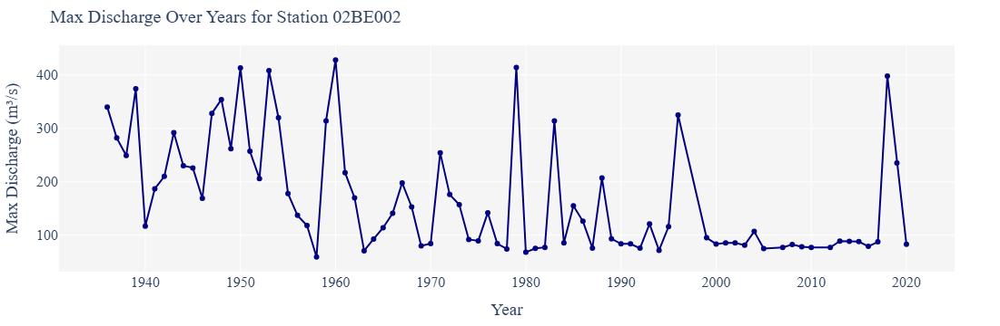

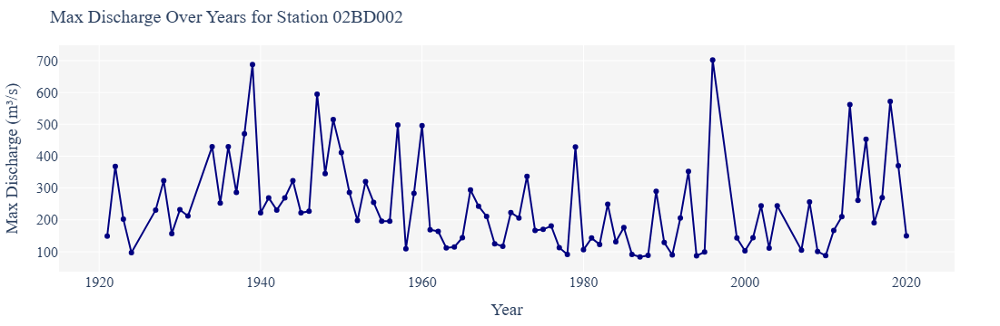

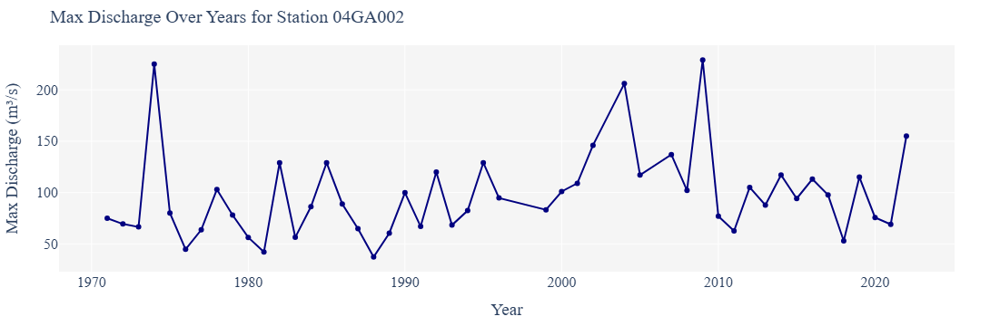

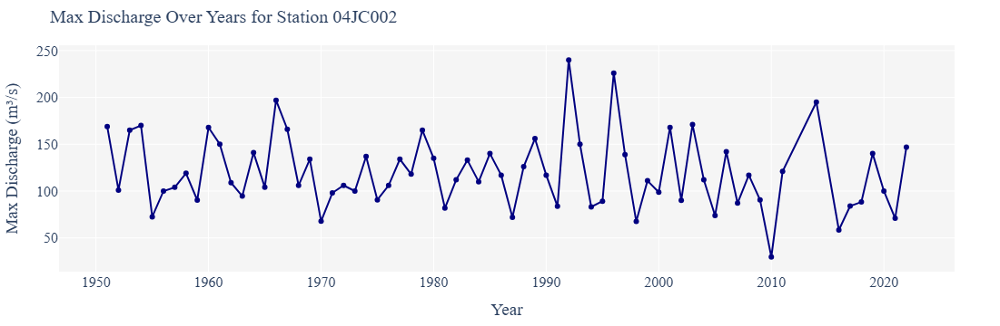

In [76]:
stations_with_gap = ['02BE002', '02BD002', '04GA002', '04JC002']

for station in stations_with_gap:
    # Selecting the hydro df for a particular station
    selected_df = filter_dataframe(hydro_df, column_name='hydro_station_id', target_value=station)
    
    # Sorting the DataFrame by 'Year' to ensure proper line plotting
    selected_df = selected_df.sort_values(by='Year')
    
    # Creating the line plot with dots
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=selected_df['Year'], 
        y=selected_df['Max_discharge'],
        mode='lines+markers',
        line=dict(color='navy', width=2),
        marker=dict(size=6, color='navy'),
        name=f'Station {station}'
    ))
    
    # Updating the layout for a nicer look
    fig.update_layout(
        title=f'Max Discharge Over Years for Station {station}',
        title_font=dict(family='Times New Roman', size=20),
        xaxis_title='Year',
        yaxis_title='Max Discharge (m³/s)',
        font=dict(family='Times New Roman', size=16),
        plot_bgcolor='whitesmoke',
        margin=dict(l=50, r=50, t=50, b=50)
    )
    
    # Showing the figure
    fig.show()


if we want to complete the data we need a date! to find the climate covariates and that will bring some errors. So we leave things as it is with considering that there is no gap more than two years in a row in the data. After having all data we can make data with interpolation for all parameters.

## Homogenity test

In [77]:
os.chdir(hydro_data_dir)
hydro_df = pd.read_csv(hydro_file)
hydro_df = hydro_df.drop(columns='Unnamed: 0', inplace=False)

homogenity test considering the whole time period

In [86]:
result_df = check_selected_stations_homogeneity(hydro_df, selected_stations, threshold = 0.01)
result_df

,Station ID,P-Value,Change Point Index,Status
27,02BE002,0.000004,26,Non-Homogeneous
25,02BD002,0.000665,35,Non-Homogeneous
31,02KD004,0.001247,38,Non-Homogeneous
7,02KB001,0.003416,48,Non-Homogeneous
14,04GA002,0.031943,23,Homogeneous
30,02EA011,0.051943,15,Homogeneous
0,05QE008,0.084330,29,Homogeneous
5,04GB004,0.117905,15,Homogeneous
18,02HL003,0.217420,59,Homogeneous
15,02JC008,0.231782,14,Homogeneous


In [105]:
homogenity_result = check_selected_stations_homogeneity(hydro_df, selected_stations, station_column='hydro_station_id', 
                                        value_column='Max_discharge', start_year=None, end_year=None)
homogenity_result

,Station ID,Pettitt P-Value,Pettitt Change Point,Pettitt Status,SNHT Change Point,SNHT Statistic,SNHT Status
27,02BE002,0.000016,26,Non-Homogeneous,26,27.617788,Non-Homogeneous
31,02KD004,0.000542,38,Non-Homogeneous,39,13.288666,Non-Homogeneous
25,02BD002,0.001582,35,Non-Homogeneous,36,11.011410,Non-Homogeneous
7,02KB001,0.001746,48,Non-Homogeneous,49,12.973966,Non-Homogeneous
14,04GA002,0.014722,23,Homogeneous,24,5.512152,Homogeneous
0,05QE008,0.048568,29,Homogeneous,30,3.984127,Homogeneous
5,04GB004,0.049563,15,Homogeneous,16,4.674012,Homogeneous
30,02EA011,0.122988,15,Homogeneous,3,7.111663,Homogeneous
18,02HL003,0.195372,59,Homogeneous,61,16.251975,Non-Homogeneous
13,05QD016,0.203363,32,Homogeneous,33,3.519384,Homogeneous


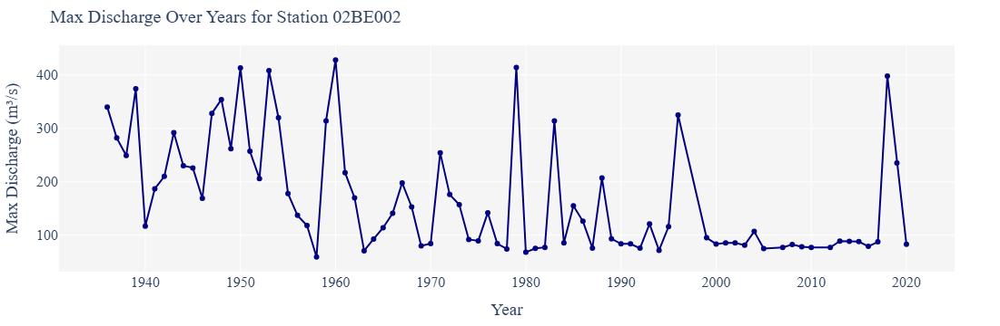

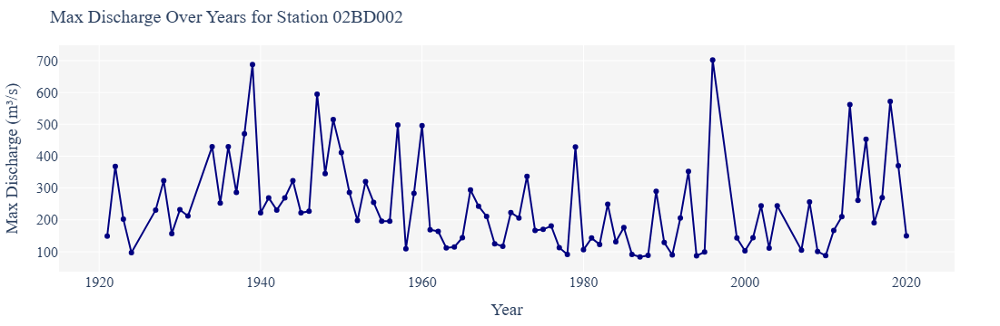

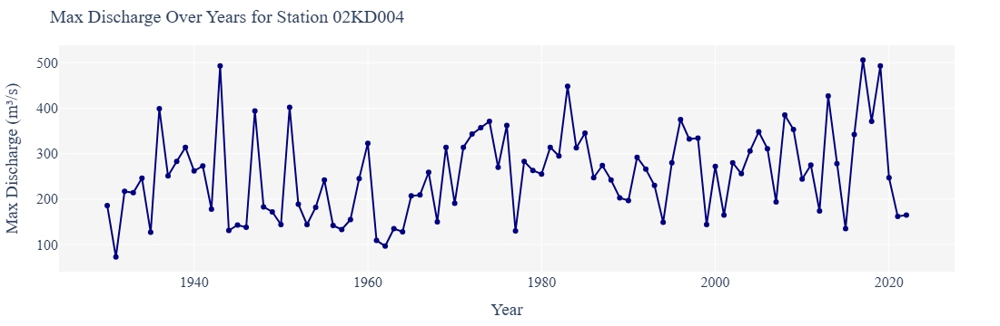

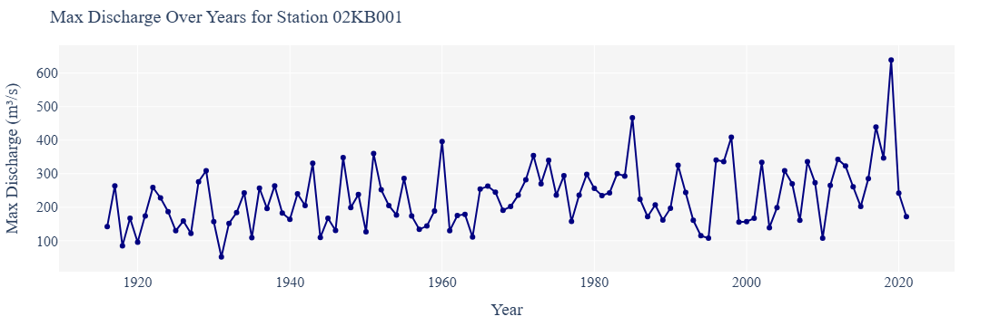

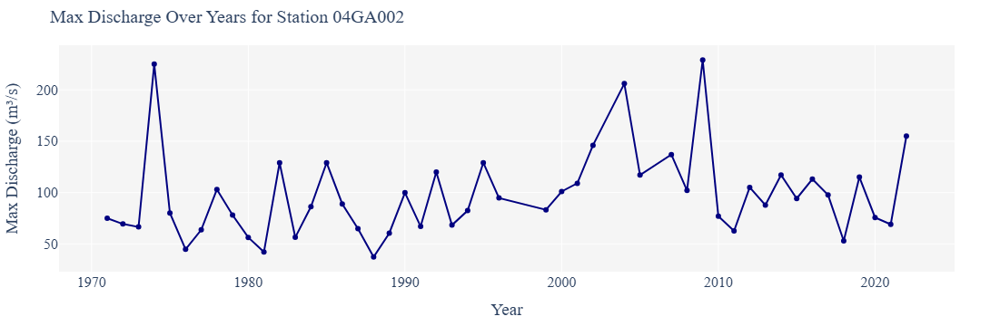

In [88]:
non_homogenous_data = ['02BE002', '02BD002', '02KD004', '02KB001', '04GA002']

for station in non_homogenous_data:
    # Selecting the hydro df for a particular station
    selected_df = filter_dataframe(hydro_df, column_name='hydro_station_id', target_value=station)
    
    # Sorting the DataFrame by 'Year' to ensure proper line plotting
    selected_df = selected_df.sort_values(by='Year')
    
    # Creating the line plot with dots
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=selected_df['Year'], 
        y=selected_df['Max_discharge'],
        mode='lines+markers',
        line=dict(color='navy', width=2),
        marker=dict(size=6, color='navy'),
        name=f'Station {station}'
    ))
    
    # Updating the layout for a nicer look
    fig.update_layout(
        title=f'Max Discharge Over Years for Station {station}',
        title_font=dict(family='Times New Roman', size=20),
        xaxis_title='Year',
        yaxis_title='Max Discharge (m³/s)',
        font=dict(family='Times New Roman', size=16),
        plot_bgcolor='whitesmoke',
        margin=dict(l=50, r=50, t=50, b=50)
    )
    
    # Showing the figure
    fig.show()


Non homogenous stations has been removed and double commented ##

## Saving a Clean hydro data for final selected stations

In [31]:
# list of selected stations
selected_stations = [
    "05QE008",
    # "04ME003",
    "02BF001",
    "05QA004",
    "04MF001",
    # "02CC008",
    # "04LD001",
    "02CD006",
    # "04CA003",
    # "04DA001",
    "04GB004",
    "04JD005",
    ## "02KB001",
    "02BB003",
    "02BF002",
    "05QA002",
    "05QC001",
    "02KF013",
    # "02AC001",
    "05QD016",
    "04GA002",
    "02JC008",
    "02AD010",
    "02AC002",
    "02HL003",
    # "04DB001",
    "02CE002",
    "02EB013",
    "02DC004",
    "05QE009",
    "02EA010",
    "04JC002",
    ## "02BD002",
    "04LM001",
    ## "02BE002",
    ### "04KA001", not in the sheild forests ecozone!
    "02AB006",
    "02EA011",
    ## "02KD004",
    "02CC005",
    "02BA003"
]

In [32]:
os.chdir(hydro_data_dir)
hydro_df = pd.read_csv(hydro_file)
hydro_df = hydro_df.drop(columns='Unnamed: 0', inplace=False)

In [33]:
hydro_df.columns

Index(['PARAM', 'Year', 'MM-DD', 'Max_discharge', 'SYM', 'MIN_discharge',
       'SYM.1', 'hydro_station_id', 'Number_of_Years', 'hydro_start_year',
       'hydro_end_year', 'hydro_station_name', 'Province', 'Region', 'Basin',
       'hydro_station_Latitude', 'hydro_station_Longitude', 'Operating Agency',
       'Status', 'Discharge_unit', 'Month', 'Day', 'Date'],
      dtype='object')

In [34]:
clean_hydro_data = subset_and_rearrange_hydro_df(hydro_df, selected_stations, start_year=1984, end_year=2021, save = False)
clean_hydro_data

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit
4538,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1984.0,06-11,6,11,1984-06-11,124.0,3.930,m3/s
4539,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1985.0,04-24,4,24,1985-04-24,103.0,3.280,m3/s
4540,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1986.0,04-20,4,20,1986-04-20,94.1,3.490,m3/s
4541,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1987.0,04-18,4,18,1987-04-18,47.8,3.160,m3/s
4542,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1988.0,11-17,11,17,1988-11-17,95.0,2.700,m3/s
...,...,...,...,...,...,...,...,...,...,...,...,...,...
45777,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2017.0,10-25,10,25,2017-10-25,11.7,0.179,m3/s
45778,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2018.0,05-05,5,5,2018-05-05,12.0,NaN,m3/s
45779,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2019.0,04-24,4,24,2019-04-24,18.6,0.154,m3/s
45780,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2020.0,10-24,10,24,2020-10-24,19.7,0.345,m3/s


In [18]:
clean_hydro_data = subset_and_rearrange_hydro_df(hydro_df, selected_stations, start_year=1984, end_year=2021, save = True, save_dir = reprocessed_dir, 
                                                file_name = "ON_Hydro_Historical_Data_1984_2021_Final_Selection.csv")
clean_hydro_data

File saved at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Data\Reprocessed_Data\ON_Hydro_Historical_Data_1984_2021_Final_Selection.csv


,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit
4538,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1984.0,06-11,6,11,1984-06-11,124.0,3.930,m3/s
4539,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1985.0,04-24,4,24,1985-04-24,103.0,3.280,m3/s
4540,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1986.0,04-20,4,20,1986-04-20,94.1,3.490,m3/s
4541,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1987.0,04-18,4,18,1987-04-18,47.8,3.160,m3/s
4542,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1988.0,11-17,11,17,1988-11-17,95.0,2.700,m3/s
...,...,...,...,...,...,...,...,...,...,...,...,...,...
45777,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2017.0,10-25,10,25,2017-10-25,11.7,0.179,m3/s
45778,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2018.0,05-05,5,5,2018-05-05,12.0,NaN,m3/s
45779,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2019.0,04-24,4,24,2019-04-24,18.6,0.154,m3/s
45780,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2020.0,10-24,10,24,2020-10-24,19.7,0.345,m3/s


In [19]:
len(clean_hydro_data.hydro_station_id.unique())

29

# ECA Calculations

In [27]:
os.chdir(on_arcgis_dir)
# os.listdir()
# fiona.listlayers(drainage_area_gpkg)
# fiona.listlayers(on_process_gdb)

In [28]:
on_drainage_areas = gpd.read_file(drainage_area_gpkg, layer='ON_Drainage_Area_Final_Selection') #drainage_area_layer
# Calculate the area in square meters and add it as a new column (we need this for the next steps)
on_drainage_areas['area_m2'] = on_drainage_areas['geometry'].area
on_drainage_areas['drainage_area_ha'] = on_drainage_areas['area_m2']/10000

In [73]:
on_drainage_areas

,ID_hydro_st,validated_by_subWS_bounds,Is_Forested_or_Urban,pourpointID,name_hydro_st,grid_code,Province,Region,Basin,snap_distance,is_stationary,Stationarity_category,geometry,area_m2,drainage_area_ha
0,02CD006,yes,forested / lots of lakes,77,SERPENT RIVER ABOVE QUIRKE LAKE,77,ON,ONT,2,900,stationary,Expected Stationary,"MULTIPOLYGON (((6915311.971 1210242.543, 69153...",2.151308e+08,2.151308e+04
1,04GB004,yes,forested,73,OGOKI RIVER ABOVE WHITECLAY LAKE,73,ON,ONT,4,900,stationary,Resolvable Stationary,"MULTIPOLYGON (((6371361.648 1664828.052, 63713...",1.132405e+10,1.132405e+06
2,04JD005,yes,forested,72,PAGWACHUAN RIVER AT HIGHWAY NO. 11,72,ON,ONT,4,0,stationary,Unresolvable Stionary,"MULTIPOLYGON (((6663235.168 1548437.340, 66632...",1.851531e+09,1.851531e+05
3,02BB003,yes,forested,70,PIC RIVER NEAR MARATHON,70,ON,ONT,2,0,stationary,Resolvable Stationary,"MULTIPOLYGON (((6599628.448 1533409.209, 65996...",3.535245e+09,3.535245e+05
4,02BF002,yes,forested (pest effected),68,GOULAIS RIVER NEAR SEARCHMONT,68,ON,ONT,2,300,stationary,Expected Stationary,"MULTIPOLYGON (((6828791.989 1281548.861, 68287...",1.158000e+09,1.158000e+05
5,05QA002,yes,forested / many lakes,66,ENGLISH RIVER AT UMFREVILLE,66,ON,ONT,5,900,stationary,Resolvable Stationary,"MULTIPOLYGON (((6235459.103 1530595.300, 62354...",4.910628e+07,4.910628e+03
6,05QC001,yes,~forested,65,CHUKUNI RIVER NEAR EAR FALLS,65,ON,ONT,5,300,stationary,Resolvable Stationary,"MULTIPOLYGON (((6102184.935 1719034.460, 61021...",4.184173e+09,4.184173e+05
7,02KF013,yes,~forested,64,CLYDE RIVER AT GORDON RAPIDS,64,ON,ONT,2,900,stationary,Expected Stationary,"MULTIPOLYGON (((7397727.353 1149295.122, 73977...",2.679356e+08,2.679356e+04
8,05QD016,yes,minimally affected by urbvanizatgion and agric...,55,WABIGOON RIVER AT DRYDEN,55,ON,ONT,5,600,stationary,Resolvable Stationary,"MULTIPOLYGON (((6151969.485 1523174.000, 61519...",2.335163e+09,2.335163e+05
9,05QE008,corrected,forested / many lakes,51,CEDAR RIVER BELOW WABASKANG LAKE,51,ON,ONT,5,0,stationary,Resolvable Stationary,"MULTIPOLYGON (((6092537.245 1563218.095, 60925...",1.628829e+09,1.628829e+05


In [29]:
on_drainage_areas.explore()

## Disturbed Area Prep

In [43]:
os.chdir(on_arcgis_dir)
# fiona.listlayers(on_process_gdb)

# the tables we need for disturbance data are:
# 'Final_ON_Harv_85_2020_SummarizeCate'
# 'Final_ON_Fire_85_2020_SummarizeCate'

In [62]:
on_harvest = gpd.read_file(on_process_gdb, driver='FileGDB', layer='Final_ON_Harv_85_2020_SummarizeCate')
on_fire = gpd.read_file(on_process_gdb, driver='FileGDB', layer='Final_ON_Fire_85_2020_SummarizeCate')

# I want to remove 'C_' part first
on_harvest.columns = [col.replace('C_', '') if col.startswith('C_') else col for col in on_harvest.columns]
# Remove the 'geometry' column
on_harvest = on_harvest.drop('geometry', axis=1)
on_fire.columns = [col.replace('C_', '') if col.startswith('C_') else col for col in on_fire.columns]
# Remove the 'geometry' column
on_fire = on_fire.drop('geometry', axis=1)

In [63]:
on_harvest.columns

Index(['ID_hydro_st', '1985', '1986', '1987', '1988', '1989', '1990', '1991',
       '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000',
       '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009',
       '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018',
       '2019', '2020'],
      dtype='object')

In [66]:
on_harvest_long = convert_to_long_format(on_harvest, id_column = 'ID_hydro_st', value_name = 'harvest_pixel_count' )
# turn Year column to numeric
on_harvest_long['Year'] = pd.to_numeric(on_harvest_long['Year'])
on_fire_long = convert_to_long_format(on_fire, id_column = 'ID_hydro_st', value_name = 'fire_pixel_count' )
# turn Year column to numeric
on_fire_long['Year'] = pd.to_numeric(on_fire_long['Year'])

In [67]:
on_harvest_long

,ID_hydro_st,Year,harvest_pixel_count
0,02AB006,1985,46882.0
1,02AB006,1986,50389.0
2,02AB006,1987,49829.0
3,02AB006,1988,57730.0
4,02AB006,1989,37268.0
...,...,...,...
1039,05QE009,2016,108.0
1040,05QE009,2017,60.0
1041,05QE009,2018,83.0
1042,05QE009,2019,138.0


In [68]:
on_fire_long

,ID_hydro_st,Year,fire_pixel_count
0,02AB006,1985,3829.0
1,02AB006,1986,26.0
2,02AB006,1987,443.0
3,02AB006,1988,323.0
4,02AB006,1989,97.0
...,...,...,...
1039,05QE009,2016,2634.0
1040,05QE009,2017,0.0
1041,05QE009,2018,286.0
1042,05QE009,2019,30.0


In [70]:
# merging fire and harvest pixel count
merged_harv_fire = merge_harvest_fire_data(on_harvest_long, on_fire_long)

# Adding area in hectares
## each pixrl is 900 m2 and each hectare is 10,000 m2
merged_harv_fire['harvest_area_ha'] = merged_harv_fire['harvest_pixel_count'] * 900 / 10000
merged_harv_fire['fire_area_ha'] = merged_harv_fire['fire_pixel_count'] * 900 / 10000

In [75]:
# Adding drainage area (ha) to the data
merged_harv_fire = merged_harv_fire.merge(on_drainage_areas[['ID_hydro_st', 'drainage_area_ha']], on='ID_hydro_st', how='left')

In [76]:
merged_harv_fire

,ID_hydro_st,Year,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha
0,02AB006,1985,46882.0,3829.0,4219.38,344.61,643527.055648
1,02AB006,1986,50389.0,26.0,4535.01,2.34,643527.055648
2,02AB006,1987,49829.0,443.0,4484.61,39.87,643527.055648
3,02AB006,1988,57730.0,323.0,5195.70,29.07,643527.055648
4,02AB006,1989,37268.0,97.0,3354.12,8.73,643527.055648
...,...,...,...,...,...,...,...
1039,05QE009,2016,108.0,2634.0,9.72,237.06,172791.163562
1040,05QE009,2017,60.0,0.0,5.40,0.00,172791.163562
1041,05QE009,2018,83.0,286.0,7.47,25.74,172791.163562
1042,05QE009,2019,138.0,30.0,12.42,2.70,172791.163562


In [77]:
# saving the output
os.chdir(reprocessed_dir)

merged_harv_fire.to_csv('ON_Forest_Disturbance_Area_by_Station.csv', index = False)

## ECA Calculations

In [85]:
# basal area formla (Fire)
bs_formula = 5.81 + 0.26 * tsd - 0.001 * tsd**2
for tsd in range (0, 37):
    ba_formula = 5.81 + 0.26 * tsd - 0.001 * tsd**2
    print(f' in year {tsd}, basal area is {ba_formula}')

 in year 0, basal area is 5.81
 in year 1, basal area is 6.068999999999999
 in year 2, basal area is 6.3260000000000005
 in year 3, basal area is 6.5809999999999995
 in year 4, basal area is 6.834
 in year 5, basal area is 7.084999999999999
 in year 6, basal area is 7.334
 in year 7, basal area is 7.5809999999999995
 in year 8, basal area is 7.826
 in year 9, basal area is 8.068999999999999
 in year 10, basal area is 8.31
 in year 11, basal area is 8.549
 in year 12, basal area is 8.786
 in year 13, basal area is 9.020999999999999
 in year 14, basal area is 9.254
 in year 15, basal area is 9.485000000000001
 in year 16, basal area is 9.713999999999999
 in year 17, basal area is 9.941
 in year 18, basal area is 10.165999999999999
 in year 19, basal area is 10.389
 in year 20, basal area is 10.61
 in year 21, basal area is 10.828999999999999
 in year 22, basal area is 11.046000000000001
 in year 23, basal area is 11.261
 in year 24, basal area is 11.474
 in year 25, basal area is 11.6849

In [84]:
# forest cover formla (Havest)
bs_formula = 5.81 + 0.26 * tsd - 0.001 * tsd**2
for tsd in range (0, 37):
    ba_formula = 16.71 - 2.19 * tsd + 0.12 * tsd**2
    print(f' in year {tsd}, cover is {ba_formula}')

 in year 0, cover is 16.71
 in year 1, cover is 14.64
 in year 2, cover is 12.810000000000002
 in year 3, cover is 11.22
 in year 4, cover is 9.870000000000001
 in year 5, cover is 8.760000000000002
 in year 6, cover is 7.890000000000001
 in year 7, cover is 7.260000000000001
 in year 8, cover is 6.870000000000001
 in year 9, cover is 6.719999999999999
 in year 10, cover is 6.810000000000002
 in year 11, cover is 7.140000000000001
 in year 12, cover is 7.710000000000001
 in year 13, cover is 8.52
 in year 14, cover is 9.57
 in year 15, cover is 10.86
 in year 16, cover is 12.39
 in year 17, cover is 14.160000000000004
 in year 18, cover is 16.169999999999995
 in year 19, cover is 18.42
 in year 20, cover is 20.910000000000004
 in year 21, cover is 23.639999999999993
 in year 22, cover is 26.61
 in year 23, cover is 29.82
 in year 24, cover is 33.27
 in year 25, cover is 36.96
 in year 26, cover is 40.88999999999999
 in year 27, cover is 45.059999999999995
 in year 28, cover is 49.47
 i

Based on the models we have for recovery after 8 years they start to show a exponential trend and before that we will consider HR as 0 Since there is a threshold for descriptor where below that the HR is assumed 0. Additionally 8 years is where our model starts to behave exponentially.

In [102]:
eca_df = calculate_ECA_for_all_stations(merged_harv_fire, id_column='ID_hydro_st', harvest_area_column='harvest_area_ha', 
                                   fire_area_column='fire_area_ha', drainage_area_column='drainage_area_ha', 
                                   save=True, save_path= reprocessed_dir, file_name='ON_final_ECA_Results_by_Station.csv')

File saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Data\Reprocessed_Data/ON_final_ECA_Results_by_Station.csv


In [103]:
eca_df

,ID_hydro_st,Year,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,02AB006,1985,46882.0,3829.0,4219.38,344.61,643527.055648,4219.380000,0.655665,344.610000,0.053550,0.709215
1,02AB006,1986,50389.0,26.0,4535.01,2.34,643527.055648,8754.390000,1.360376,346.950000,0.053914,1.414290
2,02AB006,1987,49829.0,443.0,4484.61,39.87,643527.055648,13239.000000,2.057256,386.820000,0.060109,2.117366
3,02AB006,1988,57730.0,323.0,5195.70,29.07,643527.055648,18434.700000,2.864635,415.890000,0.064627,2.929261
4,02AB006,1989,37268.0,97.0,3354.12,8.73,643527.055648,21788.820000,3.385844,424.620000,0.065983,3.451827
...,...,...,...,...,...,...,...,...,...,...,...,...
1039,05QE009,2016,108.0,2634.0,9.72,237.06,172791.163562,14422.797999,8.346953,902.254800,0.522165,8.869118
1040,05QE009,2017,60.0,0.0,5.40,0.00,172791.163562,13766.622021,7.967203,858.758544,0.496992,8.464195
1041,05QE009,2018,83.0,286.0,7.47,25.74,172791.163562,13077.460890,7.568362,841.010352,0.486721,8.055083
1042,05QE009,2019,138.0,30.0,12.42,2.70,172791.163562,12343.650003,7.143681,801.768096,0.464010,7.607691


In [108]:
len(eca_df['ID_hydro_st'].unique())

29

## Plotting and ECA visual

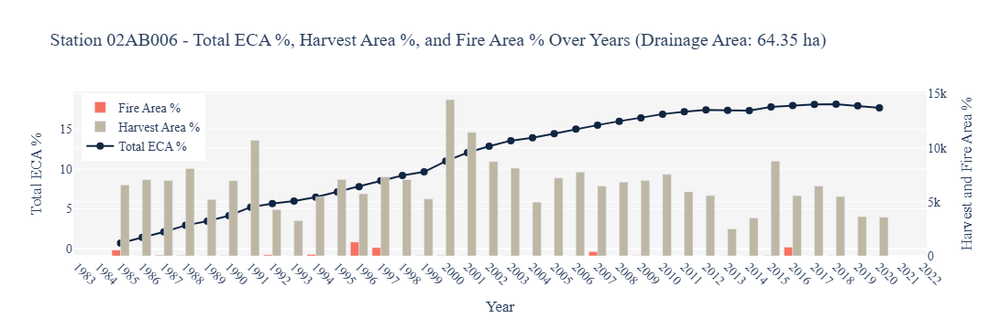

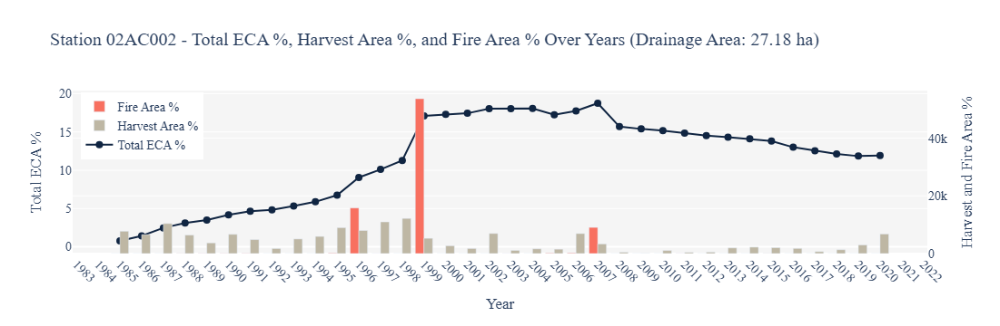

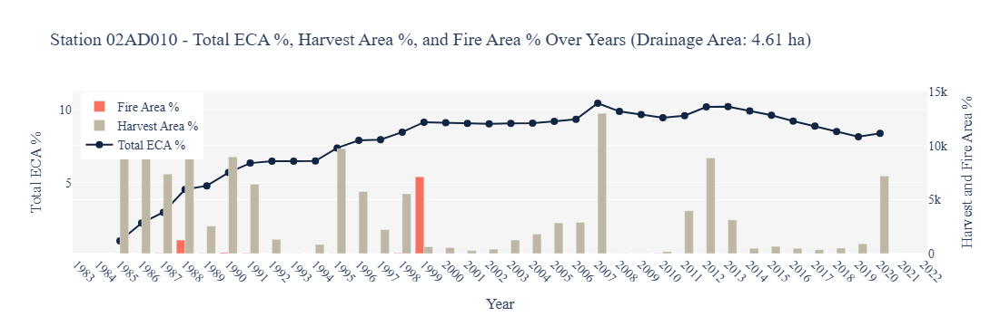

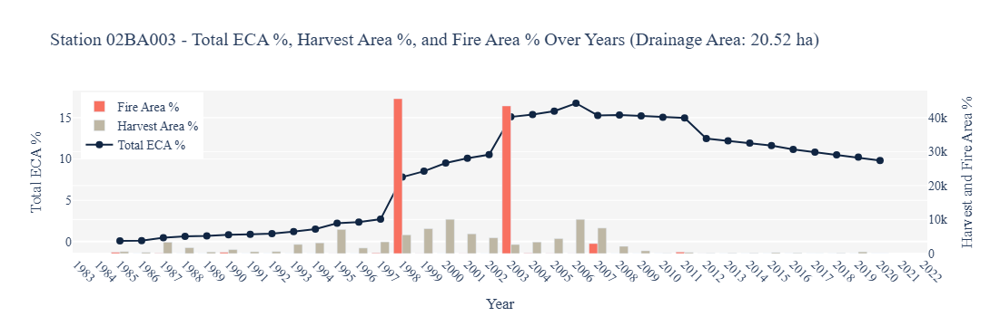

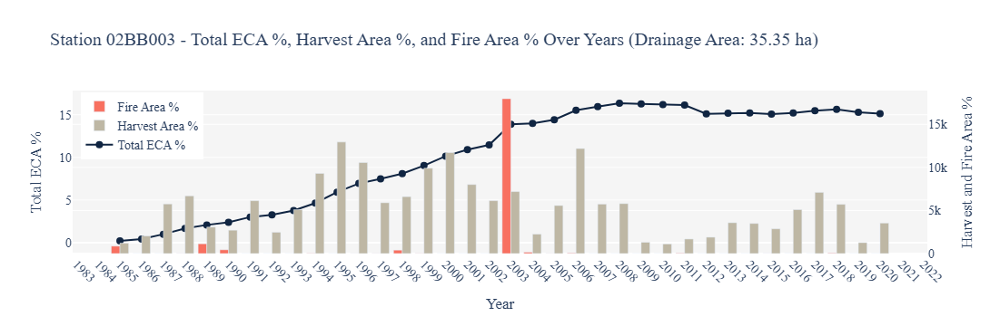

...

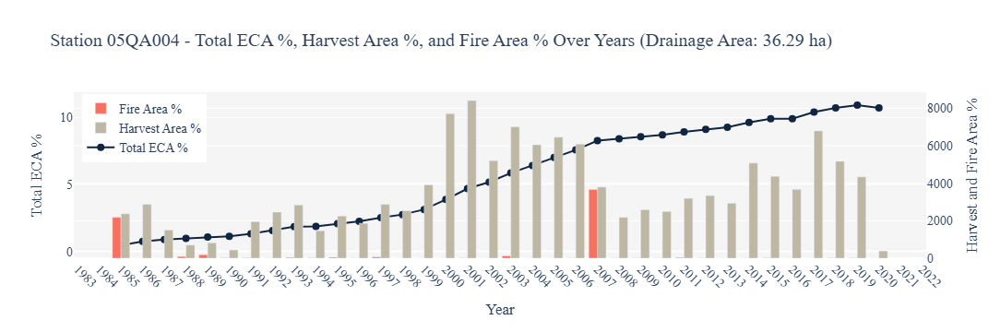

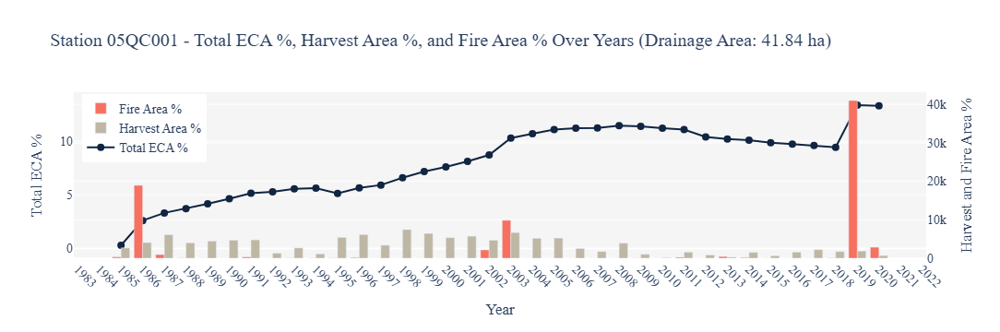

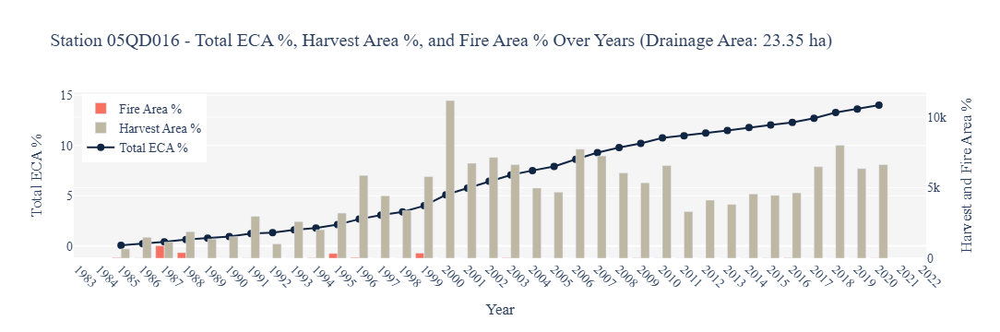

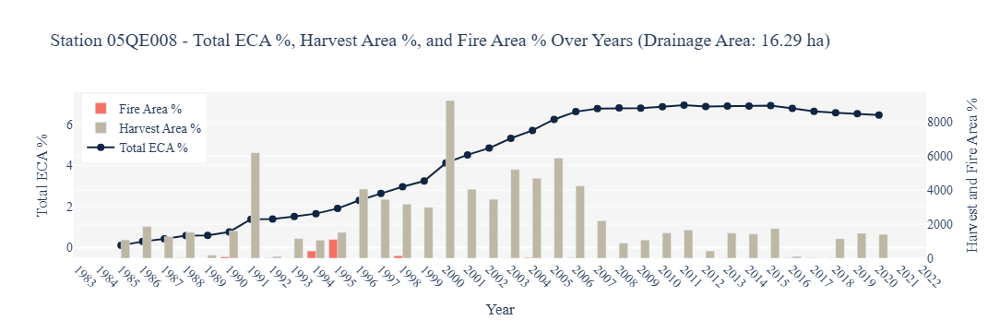

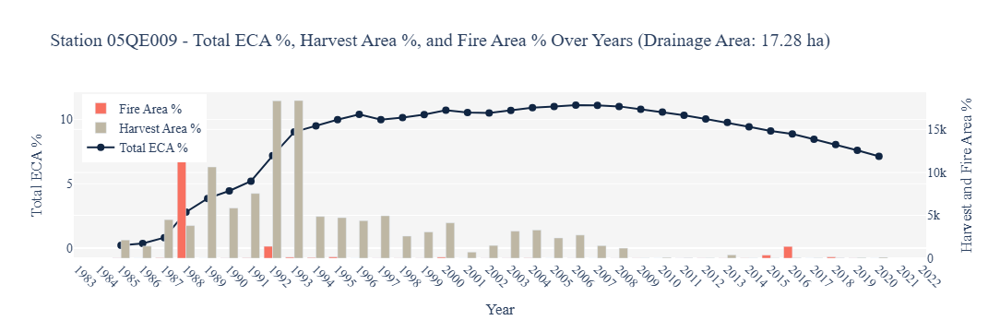

In [110]:
plot_ECA_station_data(eca_df)

In [64]:
final_covariates.head()

,Unnamed: 0,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,...,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1985.0,04-25,4,25,...,20.0,0.0,1.80,0.0,21513.078724,1.80,0.008367,0.0,0.0,0.008367
1,1,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1986.0,04-09,4,9,...,0.0,0.0,0.00,0.0,21513.078724,1.80,0.008367,0.0,0.0,0.008367
2,2,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1987.0,04-12,4,12,...,0.0,0.0,0.00,0.0,21513.078724,1.80,0.008367,0.0,0.0,0.008367
3,3,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1988.0,04-08,4,8,...,14.0,0.0,1.26,0.0,21513.078724,3.06,0.014224,0.0,0.0,0.014224
4,4,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1989.0,04-28,4,28,...,82.0,0.0,7.38,0.0,21513.078724,10.44,0.048529,0.0,0.0,0.048529


In [10]:
eca_fig_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\ECAs"

In [11]:
import plotly.graph_objects as go
import os

def plot_ECA_station_data(df, station_list, output_dir):
    # Ensure output directory exists
    os.makedirs(output_dir, exist_ok=True)
    
    # Filter dataframe to only include selected stations
    df = df[df['ID_hydro_st'].isin(station_list)]
    unique_stations = df['ID_hydro_st'].unique()
    
    # Loop through each station and save individual plots
    for station_id in unique_stations:
        station_df = df[df['ID_hydro_st'] == station_id]
        drainage_area_ha = station_df['drainage_area_ha'].iloc[0] / 10_000
        
        # Create the figure
        fig = go.Figure()
        
        # Add bar for 'fire_area%'
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['fire_area_ha'] / drainage_area_ha * 100,
            name='Fire Area %',
            marker_color='#f87060',
            yaxis='y2',
            showlegend=False
        ))
        
        # Add bar for 'harvest_area%'
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['harvest_area_ha'] / drainage_area_ha * 100,
            name='Harvest Area %',
            marker_color='#beb7a4',
            yaxis='y2',
            showlegend=False
        ))
        
        # Add line for 'total_ECA_%'
        fig.add_trace(go.Scatter(
            x=station_df['Year'],
            y=station_df['Total_ECA_percentage'],
            mode='lines+markers',
            name='Total ECA %',
            line=dict(color='#102542'),
            marker=dict(symbol='circle', size=8),
            yaxis='y1',
            showlegend=False
        ))
        
        # Update layout to be square, high resolution, and remove axis labels
        fig.update_layout(
            title = f"{station_id}",
            xaxis=dict(title='', showticklabels=False, showgrid=False, zeroline=False),  # Remove x-axis labels completely
            yaxis=dict(title='', showgrid=True, showticklabels=True, zeroline=False, tickfont=dict(size=30)),  # Keep y-axis numbers but remove title
            yaxis2=dict(title='', overlaying='y', side='right', showticklabels=True, tickfont=dict(size=30)),
            plot_bgcolor='whitesmoke',
            font=dict(family='Times New Roman', size=30),
            width=1000,
            height=500
        )
        
        # Save the figure as high-resolution JPEG
        fig.write_image(os.path.join(output_dir, f"station_{station_id}_eca_plot.jpg"), scale=5)
    
    # Create separate legend image
    legend_fig = go.Figure()
    legend_fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers', name='Fire Area %', marker=dict(color='#f87060', size=40)))
    legend_fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers', name='Harvest Area %', marker=dict(color='#beb7a4', size=40)))
    legend_fig.add_trace(go.Scatter(x=[None], y=[None], mode='lines+markers', name='Total ECA %', line=dict(color='#102542', width=6), marker=dict(symbol='circle', size=40)))
    
    legend_fig.update_layout(
        showlegend=True,
        legend=dict(x=0.5, y=0.5, xanchor='center', yanchor='middle', font=dict(size=40)),
        width=1200,
        height=1200,
        plot_bgcolor='whitesmoke',
        font=dict(family='Times New Roman', size=40),
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False)
    )
    
    # Save legend as high-resolution JPEG
    legend_fig.write_image(os.path.join(output_dir, "legend.jpg"), scale=5)


In [12]:
station_list = ["02AB006", "02AC002", "02AD010", "02BA003", "02BB003", "02BF001", "02CC005", "02CD006", "02CE002",
                "02DC004", "02JC008", "04GA002", "04GB004", "04JC002", "04JD005", "04LM001", "04MF001", "05QA002",
                "05QA004", "05QC001", "05QD016", "05QE008", "05QE009"] # list of 23 disturbed stations

plot_ECA_station_data(final_covariates, station_list, eca_fig_dir)

# Climate Covariates Calculations

## Loading data and reproject

In [26]:
os.chdir(era5_combined_dr)
main_ds = xr.open_dataset('ERA5_1985_2020_daily_all_variables_combined.nc')

# assiging WGS84 to ds as it does not have an attached crs
main_ds.rio.write_crs("EPSG:4326", inplace=True)  # Assuming the original CRS is WGS84 (EPSG:4326)
# print(main_ds.rio.crs)

<xarray.Dataset> Size: 4GB
Dimensions:      (valid_time: 13149, latitude: 69, longitude: 94)
Coordinates:
    number       int64 8B ...
  * latitude     (latitude) float64 552B 57.93 57.68 57.43 ... 41.43 41.18 40.93
  * longitude    (longitude) float64 752B -96.71 -96.46 -96.21 ... -73.71 -73.46
  * valid_time   (valid_time) datetime64[ns] 105kB 1985-01-01 ... 2020-12-31
    spatial_ref  int32 4B 0
Data variables:
    t2m          (valid_time, latitude, longitude) float32 341MB ...
    e            (valid_time, latitude, longitude) float32 341MB ...
    sf           (valid_time, latitude, longitude) float32 341MB ...
    sd           (valid_time, latitude, longitude) float32 341MB ...
    es           (valid_time, latitude, longitude) float32 341MB ...
    slt          (valid_time, latitude, longitude) float32 341MB ...
    sro          (valid_time, latitude, longitude) float32 341MB ...
    tcrw         (valid_time, latitude, longitude) float32 341MB ...
    tp           (valid_time, latitude, longitude) float32 341MB ...
    swvl1        (valid_time, latitude, longitude) float32 341MB ...
    swvl2        (valid_time, latitude, longitude) float32 341MB ...
    swvl3        (valid_time, latitude, longitude) float32 341MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2024-11-04T00:54 GRIB to CDM+CF via cfgrib-0.9.1...

In [29]:
# changing the crs of drainage area
on_drainage_areas_wgs = on_drainage_areas.to_crs(epsg=4326)

In [168]:
# checking crs of drainage area
# on_drainage_areas.crs

geometry_bounds = on_drainage_areas_wgs.total_bounds  # [minx, miny, maxx, maxy]
print(f"Longitude range in GeoDataFrame: {geometry_bounds[0]} to {geometry_bounds[2]}")

# Get the bounding box of the NetCDF dataset
netcdf_bounds = main_ds.rio.bounds()
print(f"NetCDF bounds: {netcdf_bounds}")

# reprojected_ds = main_ds.rio.reproject("EPSG:3347")
# on_drainage_areas

Longitude range in GeoDataFrame: -94.66779812714798 to -76.60369216915166
NetCDF bounds: (-96.831, 40.801, -73.331, 58.051)


In [58]:
os.chdir(reprocessed_dir)
os.listdir()
hydro_hist_data = pd.read_csv('ON_Hydro_Historical_Data_1985_2020_Final_Selection.csv')

In [59]:
hydro_hist_data 

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit
0,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1985.0,04-24,4,24,1985-04-24,103.00,3.280,m3/s
1,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1986.0,04-20,4,20,1986-04-20,94.10,3.490,m3/s
2,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1987.0,04-18,4,18,1987-04-18,47.80,3.160,m3/s
3,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1988.0,11-17,11,17,1988-11-17,95.00,2.700,m3/s
4,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1989.0,05-06,5,6,1989-05-06,116.00,1.640,m3/s
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2016.0,04-22,4,22,2016-04-22,6.56,0.022,m3/s
1017,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2017.0,10-25,10,25,2017-10-25,11.70,0.179,m3/s
1018,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2018.0,05-05,5,5,2018-05-05,12.00,NaN,m3/s
1019,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2019.0,04-24,4,24,2019-04-24,18.60,0.154,m3/s


In [169]:
os.chdir(on_arcgis_dir)
# fiona.listlayers(on_process_gdb)
WS_on_bounds = gpd.read_file(on_process_gdb, layer='ON_WS_NAD_Diss_EliminatePoly')

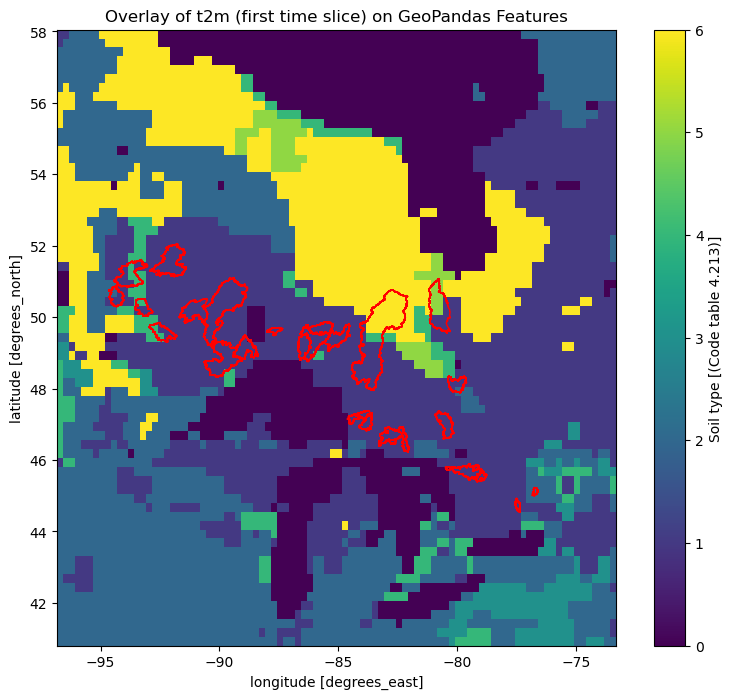

In [172]:
# visual check that reproject has been done successfully
ds_sample = main_ds['slt'].isel(valid_time = 0)

# Plot the xarray dataset sample
fig, ax = plt.subplots(figsize=(10, 8))
ds_sample.plot(ax=ax, cmap='viridis')  # Plot the xarray data with a colormap

# Overlay the GeoPandas features
on_drainage_areas_wgs.plot(ax=ax, edgecolor='red', facecolor='none', linewidth=1)

plt.title(f"Overlay of t2m (first time slice) on GeoPandas Features")
plt.show()

## prep: clipping, subsetting, extracting the variables

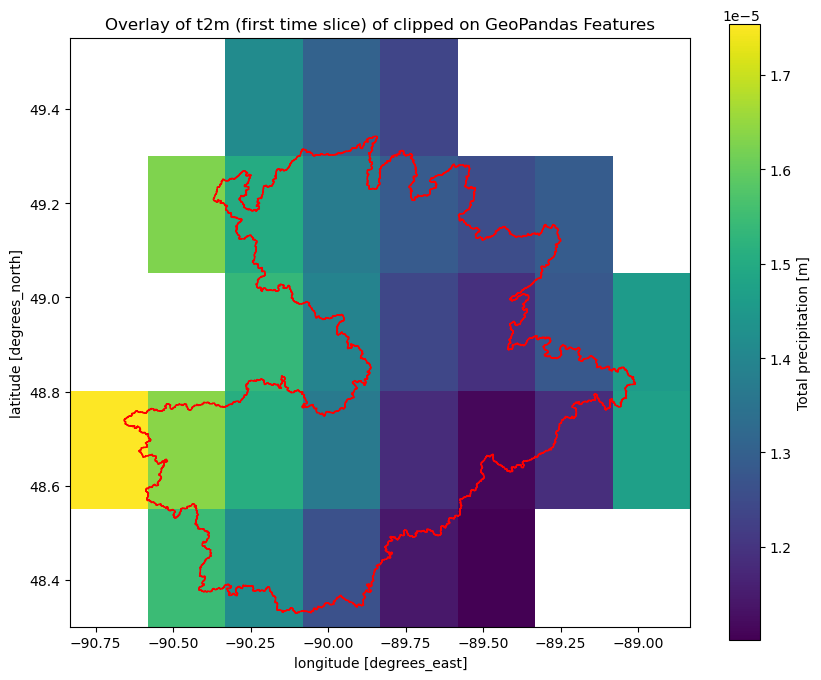

In [46]:
# clip function test
test = clip_netcdf_by_geometry(main_ds, on_drainage_areas_wgs, '02AB006', output_file=None)

# visual check that reproject has been done successfully
ds_sample = test['tp'].isel(valid_time = 0)

# Plot the xarray dataset sample
fig, ax = plt.subplots(figsize=(10, 8))
ds_sample.plot(ax=ax, cmap='viridis')  # Plot the xarray data with a colormap

# Overlay the GeoPandas features
test_drainage = on_drainage_areas_wgs[on_drainage_areas_wgs['ID_hydro_st'] == '02AB006']
test_drainage.plot(ax=ax, edgecolor='red', facecolor='none', linewidth=1)

plt.title(f"Overlay of t2m (first time slice) of clipped on GeoPandas Features")
plt.show()

In [47]:
# time subset function test
date_test = subset_netcdf_by_date(test, '2020-12-29', days=10)

In [55]:
# testing calculate climate covariates
calculate_climate_metrics(date_test, '2020-12-29', drainage_area_m2=None, periods=[1, 3, 7], debug=True)


Processing period: 1 days


Processing period: 3 days


Processing period: 7 days



{'WR_1_days': 0,
 'Max_temp_1_days_K': 257.12006,
 'Evaporation_Sum_1_days_mm': 0.3451579250395298,
 'Snow_Evaporation_Sum_1_days_mm': 0.24472351651638746,
 'Snowfall_Sum_1_days_mm': 0.14939594257157296,
 'Snow_Depth_Avg_1_days_cm': 116.97268486022949,
 'Snowmelt_1_days_cm': 0.02987778279930353,
 'Surface_Runoff_Sum_1_days_mm': 0.0,
 'Total_Rainwater_1_days_mm': 0.0,
 'Total_Precipitation_Sum_1_days_mm': 0.14907743025105447,
 'swvl1_Soil_Moisture_Max_1_days_percent': 22.96316921710968,
 'swvl2_Soil_Moisture_Max_1_days_percent': 22.848425805568695,
 'swvl3_Soil_Moisture_Max_1_days_percent': 24.039064347743988,
 'Total_Soil_Moisture_Max_1_days_percent': 69.85065937042236,
 'WR_3_days': 0,
 'Max_temp_3_days_K': 261.29718,
 'Evaporation_Sum_3_days_mm': 0.6927012000232935,
 'Snow_Evaporation_Sum_3_days_mm': 0.4676495445892215,
 'Snowfall_Sum_3_days_mm': 0.5718094180338085,
 'Snow_Depth_Avg_3_days_cm': 117.8126335144043,
 'Snowmelt_3_days_cm': 0.08008120348677039,
 'Surface_Runoff_Sum_3_days

In [180]:
extract_variable_full_names(main_ds)

{'t2m': '2 metre temperature',
 'e': 'Evaporation',
 'sf': 'Snowfall',
 'sd': 'Snow depth',
 'es': 'Snow evaporation',
 'slt': 'Soil type',
 'sro': 'Surface runoff',
 'tcrw': 'Total column rain water',
 'tp': 'Total precipitation',
 'swvl1': 'Volumetric soil water layer 1',
 'swvl2': 'Volumetric soil water layer 2',
 'swvl3': 'Volumetric soil water layer 3'}

In [78]:
proc1 = process_stations(hydro_hist_data = hydro_hist_data,
                 on_drainage_areas = on_drainage_areas_wgs, 
                 main_ds = main_ds, 
                 test_st_id= ['02AB006'], save_csv=False, output_dir=None, periods=[1, 3, 5])

In [79]:
proc2 = process_stations2(hydro_hist_data = hydro_hist_data,
                 on_drainage_areas = on_drainage_areas_wgs, 
                 main_ds = main_ds, 
                 test_st_id= ['02AB006'], save_csv=False, output_dir=None, periods=[1, 3, 5])

In [80]:
proc1

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent
0,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1985.0,10-09,10,9,1985-10-09,193.0,18.40,m3/s,0.000000,277.428528,2.447529,7.182181e-02,8.383311,9.824272,0.153675,0.378046,0.030193,28.245499,31.440169,31.417322,29.300445,92.157936,0.000000,277.428528,5.841931,0.061999,8.688740,5.198971,0.154485,0.391417,0.030493,30.414479,31.440169,31.417322,29.300445,92.157936,0.000000,279.476654,9.333607,0.076039,8.688746,4.018752,0.202754,0.422004,0.034600,32.743335,31.440169,31.417322,29.300445,92.157936
1,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1986.0,04-30,4,30,1986-04-30,217.0,19.60,m3/s,0.000000,281.379059,4.478473,8.180310e-04,0.225881,0.140980,0.000026,0.141435,0.039084,16.281540,28.882900,26.246706,23.266044,78.395650,0.000000,282.859344,6.819455,0.000799,0.225881,0.070490,0.000026,0.215506,0.062970,26.596384,28.882900,26.246706,23.266044,78.395650,0.217114,282.859344,10.806204,0.000826,0.225881,0.046993,0.000026,0.260795,0.077519,33.956036,28.882900,26.246706,23.361495,78.491101
2,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1987.0,02-09,2,9,1987-02-09,61.9,15.50,m3/s,6.693390,265.708923,1.284605,9.713536e-01,2.928384,105.274785,0.008436,0.000000,0.000000,2.928354,22.940567,23.208785,23.058097,69.207449,0.000000,271.939728,2.432641,1.843066,6.200165,109.692335,0.282465,0.000562,0.000001,6.341502,23.011565,23.233087,23.131490,69.376142,0.596552,271.939728,2.891615,2.282258,6.503808,112.894475,0.395069,0.000562,0.000001,6.644374,23.077497,23.235980,23.204418,69.517894
3,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1988.0,09-02,9,2,1988-09-02,92.8,11.80,m3/s,0.000000,290.584991,5.005074,7.387087e-06,0.000000,0.000000,0.000000,0.262522,0.028938,23.564182,29.869714,30.176467,28.812578,88.858759,1.521922,290.584991,10.136044,0.000002,0.000000,0.000000,0.000000,0.265175,0.029120,24.032170,29.869714,30.176467,29.087034,89.133215,1.128650,290.584991,16.248366,0.000006,0.000000,0.000000,0.000000,0.292121,0.034278,27.990453,29.869714,30.176467,29.343751,89.389932
4,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1989.0,04-28,4,28,1989-04-28,147.0,25.60,m3/s,0.000000,279.409210,2.400736,2.077896e-02,0.010194,1.226282,0.010078,0.002993,0.000006,0.060419,24.324986,25.503901,24.969360,74.798247,0.000000,282.017426,4.598530,0.006883,0.010194,2.986870,0.138706,0.041869,0.001748,0.598475,26.627263,26.766741,24.999598,78.393602,0.242285,282.017426,7.759400,0.340074,0.010194,7.087725,0.428168,0.115620,0.005583,3.708765,26.627263,27.239221,24.999598,78.866082
5,02AB006,KAMINISTIQUIA RIVER AT KAMINISTIQUIA,ON,ONT,2,1990.0,06-30,6,30,1990-06-30,201.0,22.70,m3/s,0.331543,290.845215,6.646627,5.746902e-06,0.000000,0.00

In [82]:
proc1.equals(proc2)

True

## final climate covariate calculations

In [84]:
climate_covs = process_stations(hydro_hist_data = hydro_hist_data,
                 on_drainage_areas = on_drainage_areas_wgs, 
                 main_ds = main_ds, 
                 test_st_id= None, save_csv=True, output_dir= reprocessed_dir, periods=[1, 3, 5, 7, 15, 30, 40, 60, 80], debug = True)

Processing station: 02CD006

Processing period: 1 days


Processing period: 3 days


Processing period: 5 days


Processing period: 7 days


Processing period: 15 days


Processing period: 30 days


Processing period: 40 days


Processing period: 60 days


Processing period: 80 days


Processing period: 1 days


Processing period: 3 days


Processing period: 5 days


Processing period: 7 days


Processing period: 15 days


Processing period: 30 days


Processing period: 40 days


Processing period: 60 days


Processing period: 80 days


Processing period: 1 days


Processing period: 3 days


Processing period: 5 days


Processing period: 7 days


Processing period: 15 days


Processing period: 30 days


Processing period: 40 days


Processing period: 60 days


Processing period: 80 days


Processing period: 1 days


Processing period: 3 days


Processing period: 5 days


Processing period: 7 days


Processing period: 15 days


Processing period: 30 days


Processing period: 40 days


P

In [85]:
climate_covs

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent
0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1985.0,04-25,4,25,1985-04-25,18.90,1.010,m3/s,0.0,283.986176,0.655121,0.007320,0.000000,0.568530,0.087517,0.035596,0.059991,2.387390,29.398319,28.858399,32.195166,90.451884,0.000

## Climate Covs understanding

When putting 8 years as treashold for FR, the reason is thar in ROS we need Threashold as Depth _ 0.5 for height to reach that and 2.5 meter is the peak depth and forest needs to reach this height and for boreal forest we assumed 8 years on avarage.

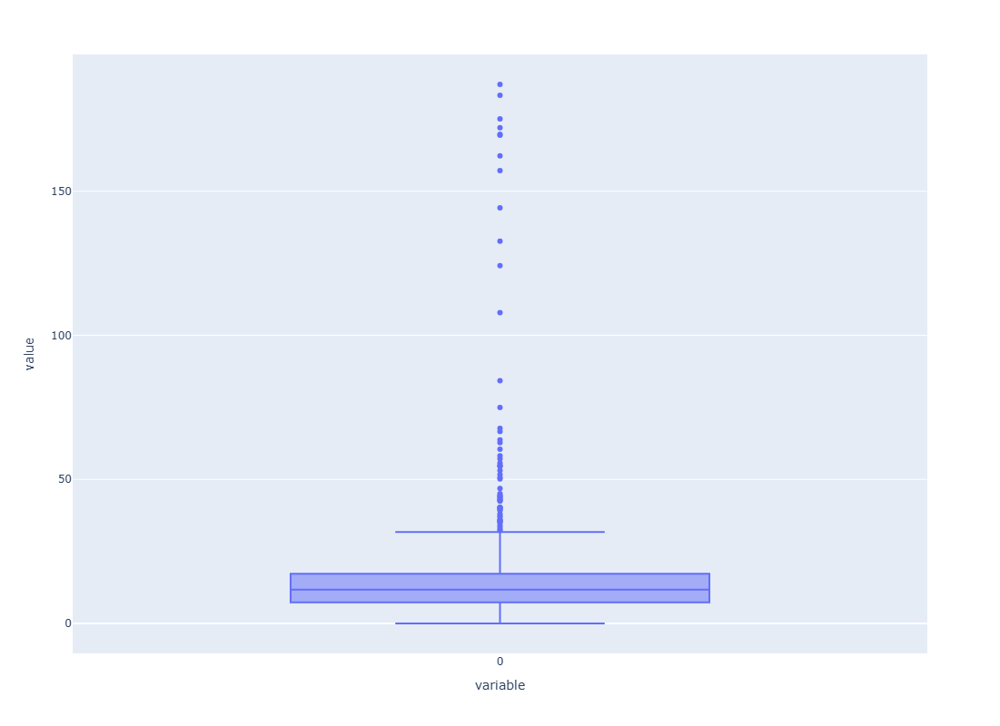

In [16]:
snow_depth_day = climate_covs['Snow_Depth_Avg_1_days_cm']
snowmelt = climate_covs['Snowmelt_80_days_cm']

# Now I want to see 80 days before peak date how much is the snowdepth that forest can moderate the process
sd_80 = snow_depth_day + snowmelt

# Now I want to have a box plot with plotly
fig = px.box(sd_80)
fig.update_layout(
    width = 300,
    height = 800
)
fig.show()

# Combining results

In [99]:
os.chdir(reprocessed_dir)
os.listdir()

['desktop.ini',
 'ON_Climate_Covariates_final_ERA5.csv',
 'ON_Final_Complete_ECA_Climate_Cov_Data_1985_2020.csv',
 'ON_final_ECA_Results_by_Station.csv',
 'ON_Forest_Disturbance_Area_by_Station.csv',
 'ON_Hydro_Historical_Data_1984_2021_Final_Selection.csv',
 'ON_Hydro_Historical_Data_1985_2020_Final_Selection.csv']

In [87]:
climate_covs = pd.read_csv('ON_Climate_Covariates_final_ERA5.csv')
eca_df = pd.read_csv('ON_final_ECA_Results_by_Station.csv')

In [88]:
climate_covs

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent
0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1985.0,04-25,4,25,1985-04-25,18.90,1.010,m3/s,0.0,283.98618,0.655121,0.007320,0.000000,0.568530,0.087517,0.035596,0.059991,2.387390,29.398319,28.858399,32.195166,90.451884,0.0000

In [90]:
len(climate_covs['hydro_station_id'].unique())

29

In [89]:
eca_df

,ID_hydro_st,Year,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,02AB006,1985,46882.0,3829.0,4219.38,344.61,643527.055648,4219.380000,0.655665,344.610000,0.053550,0.709215
1,02AB006,1986,50389.0,26.0,4535.01,2.34,643527.055648,8754.390000,1.360376,346.950000,0.053914,1.414290
2,02AB006,1987,49829.0,443.0,4484.61,39.87,643527.055648,13239.000000,2.057256,386.820000,0.060109,2.117366
3,02AB006,1988,57730.0,323.0,5195.70,29.07,643527.055648,18434.700000,2.864635,415.890000,0.064627,2.929261
4,02AB006,1989,37268.0,97.0,3354.12,8.73,643527.055648,21788.820000,3.385844,424.620000,0.065983,3.451827
...,...,...,...,...,...,...,...,...,...,...,...,...
1039,05QE009,2016,108.0,2634.0,9.72,237.06,172791.163562,14422.797999,8.346953,902.254800,0.522165,8.869118
1040,05QE009,2017,60.0,0.0,5.40,0.00,172791.163562,13766.622021,7.967203,858.758544,0.496992,8.464195
1041,05QE009,2018,83.0,286.0,7.47,25.74,172791.163562,13077.460890,7.568362,841.010352,0.486721,8.055083
1042,05QE009,2019,138.0,30.0,12.42,2.70,172791.163562,12343.650003,7.143681,801.768096,0.464010,7.607691


In [96]:
merged_df = pd.merge(climate_covs, eca_df, left_on = ['hydro_station_id', 'Year'], right_on = ['ID_hydro_st', 'Year'], how = 'outer')

There is a difference between the number of rows and I want to find where there is less climate covs for it!
in the discharge gaps! we have forest ECA but no data for discharge and climate covs

In [94]:
nan_rows = merged_df[merged_df.isna().any(axis=1)]
nan_rows

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent,ID_hydro_st,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
21,NaN,NaN,NaN,NaN,NaN,2006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

In [98]:
merged_df = pd.merge(climate_covs, eca_df, left_on = ['hydro_station_id', 'Year'], right_on = ['ID_hydro_st', 'Year'], how = 'inner')
os.chdir(reprocessed_dir)
merged_df.to_csv('ON_Final_Complete_ECA_Climate_Cov_Data_1985_2020.csv')

In [101]:
merged_df

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent,ID_hydro_st,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,1985.0,0

# Correlation calculation & Peak Month

In [141]:
correlations = calculate_correlations_with_custom_styling(merged_df, station_col='hydro_station_id', target_col='Max_discharge', cmap='coolwarm', font_size=13)

In [142]:
correlations

In [143]:
# Saving the correlation output
os.chdir(reprocessed_dir)
# os.listdir()
correlations.to_excel("Final_Correlations_With_Max_Discharge.xlsx", engine="openpyxl", index=True)

**Finding the peak month**

In [8]:
clean_hydro_data

,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit
0,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1985.0,04-24,4,24,1985-04-24,103.00,3.280,m3/s
1,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1986.0,04-20,4,20,1986-04-20,94.10,3.490,m3/s
2,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1987.0,04-18,4,18,1987-04-18,47.80,3.160,m3/s
3,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1988.0,11-17,11,17,1988-11-17,95.00,2.700,m3/s
4,02BA003,LITTLE PIC RIVER NEAR COLDWELL,ON,ONT,2,1989.0,05-06,5,6,1989-05-06,116.00,1.640,m3/s
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2016.0,04-22,4,22,2016-04-22,6.56,0.022,m3/s
1017,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2017.0,10-25,10,25,2017-10-25,11.70,0.179,m3/s
1018,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2018.0,05-05,5,5,2018-05-05,12.00,NaN,m3/s
1019,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,ONT,2,2019.0,04-24,4,24,2019-04-24,18.60,0.154,m3/s


In [14]:
# Group by 'hydro_station_id' and 'Month', and count occurrences
month_counts = clean_hydro_data.groupby(['hydro_station_id', 'Month']).size().reset_index(name='Count')
month_counts

,hydro_station_id,Month,Count
0,02AB006,2,1
1,02AB006,3,1
2,02AB006,4,6
3,02AB006,5,10
4,02AB006,6,9
5,02AB006,7,3
6,02AB006,9,1
7,02AB006,10,4
8,02AC002,4,1
9,02AC002,5,23


In [15]:
# Define a mapping of months to seasons
month_to_season = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Fall', 10: 'Fall', 11: 'Fall'
}

# Add a 'Season' column based on the 'Month' column
month_counts['Season'] = month_counts['Month'].map(month_to_season)

# Group by 'hydro_station_id' and 'Season' and sum the counts
season_counts = month_counts.groupby(['hydro_station_id', 'Season'])['Count'].sum().reset_index()

# Find the most frequent season for each station
max_seasons = season_counts.loc[season_counts.groupby('hydro_station_id')['Count'].idxmax()]

In [17]:
max_seasons

,hydro_station_id,Season,Count
1,02AB006,Spring,17
5,02AC002,Spring,24
8,02AD010,Spring,27
11,02BA003,Spring,26
15,02BB003,Spring,27
18,02BF001,Spring,33
20,02BF002,Spring,30
22,02CC005,Spring,31
25,02CD006,Spring,31
28,02CE002,Spring,33


### Find ECA and Discharge Corelation among different Stations

In [12]:
final_covariates.head(2)

,Unnamed: 0,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent,ID_hydro_st,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,O

In [ ]:
'Total_ECA_percentage'
'hydro_station_id'
'Max_discharge'

Station: 02AB006
Pearson Correlation: 0.1605
P-value: 0.3570


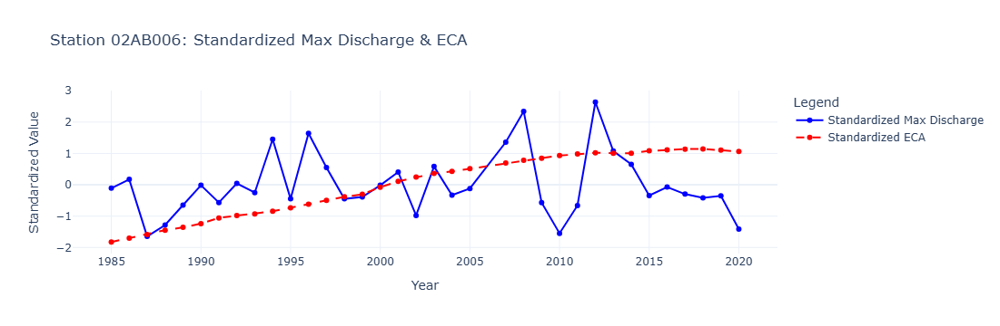

Station: 02AC002
Pearson Correlation: 0.0809
P-value: 0.6392


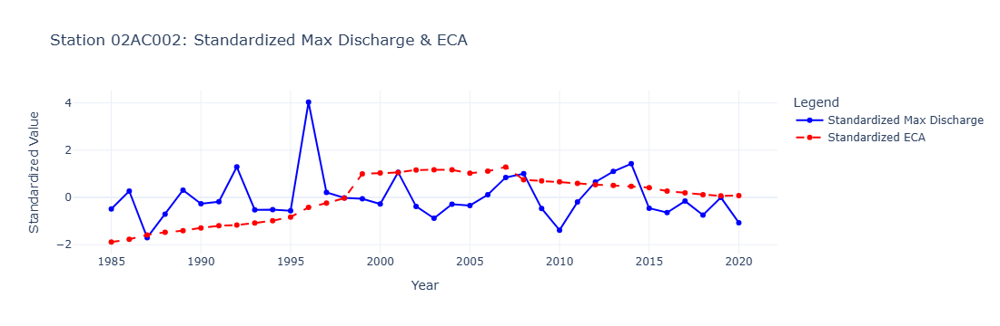

Station: 02AD010
Pearson Correlation: -0.0558
P-value: 0.7465


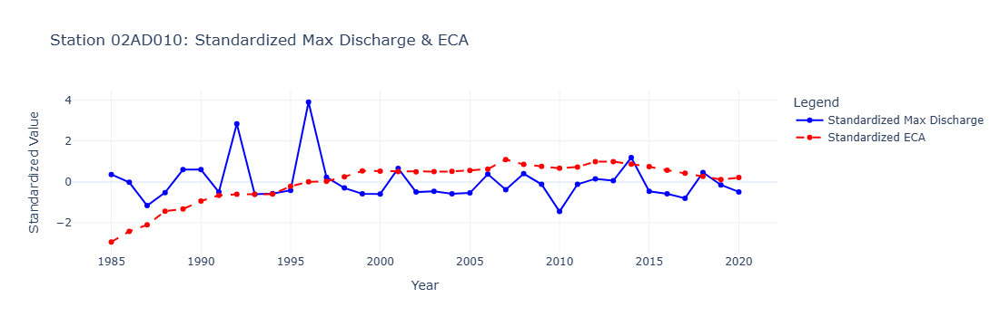

Station: 02BA003
Pearson Correlation: 0.1352
P-value: 0.4459


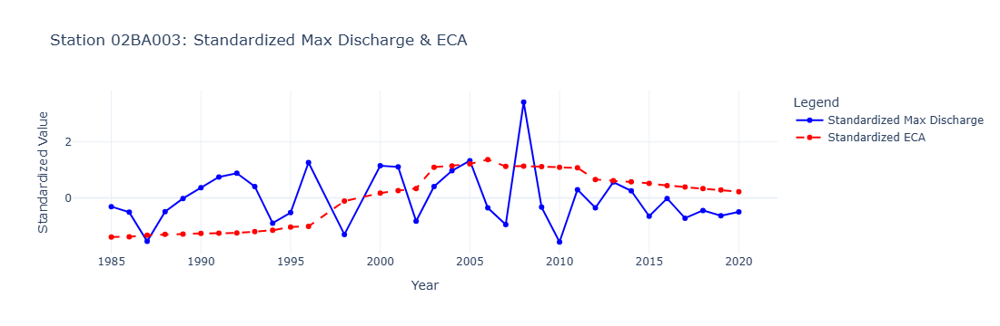

Station: 02BB003
Pearson Correlation: 0.0091
P-value: 0.9587


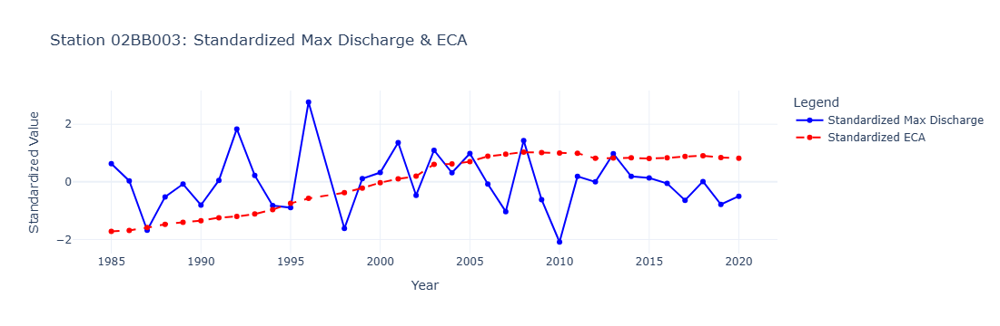

Station: 02BF001
Pearson Correlation: 0.0897
P-value: 0.6027


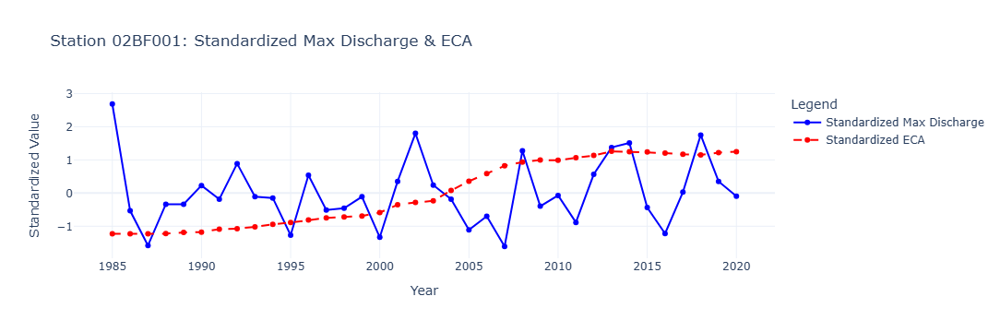

Station: 02BF002
Pearson Correlation: -0.0179
P-value: 0.9174


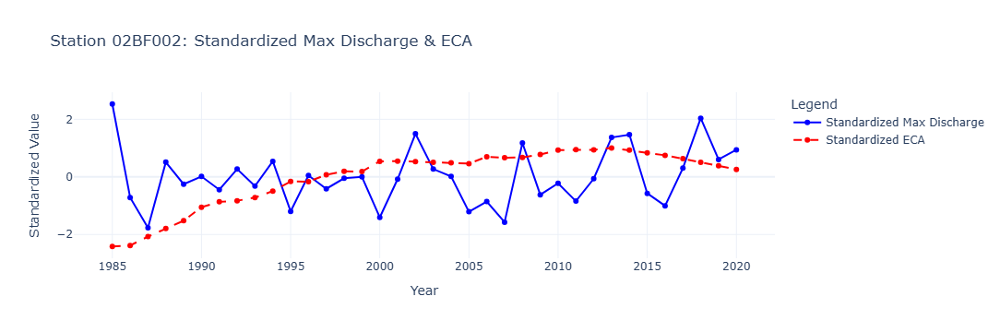

Station: 02CC005
Pearson Correlation: 0.1117
P-value: 0.5229


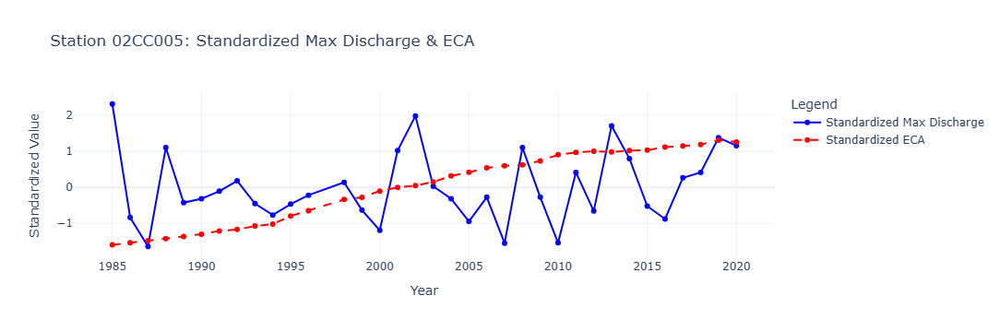

Station: 02CD006
Pearson Correlation: -0.0387
P-value: 0.8226


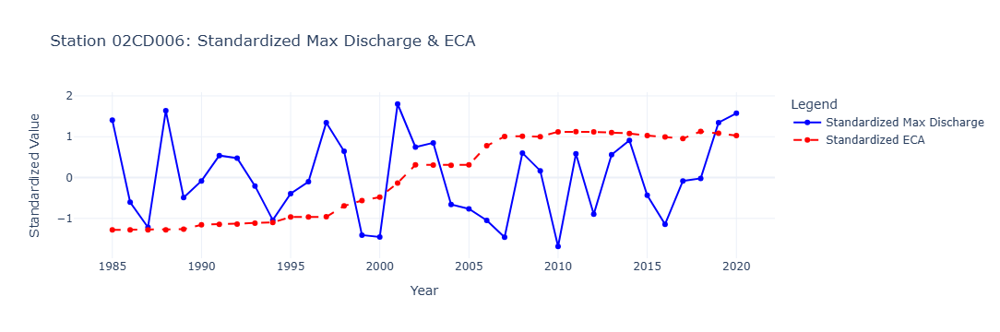

Station: 02CE002
Pearson Correlation: 0.0586
P-value: 0.7343


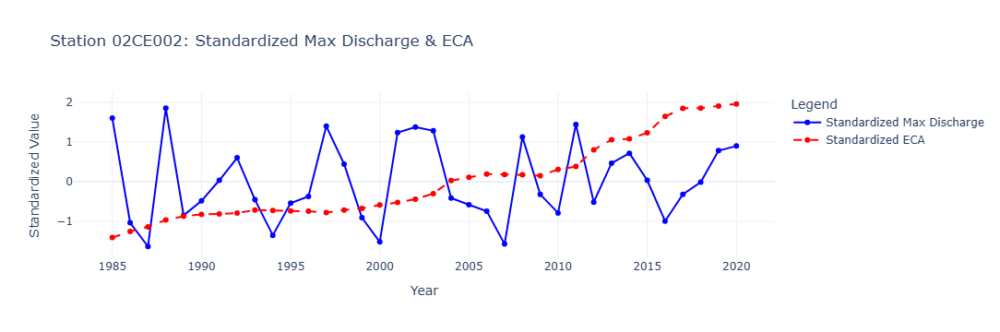

Station: 02DC004
Pearson Correlation: 0.1208
P-value: 0.4895


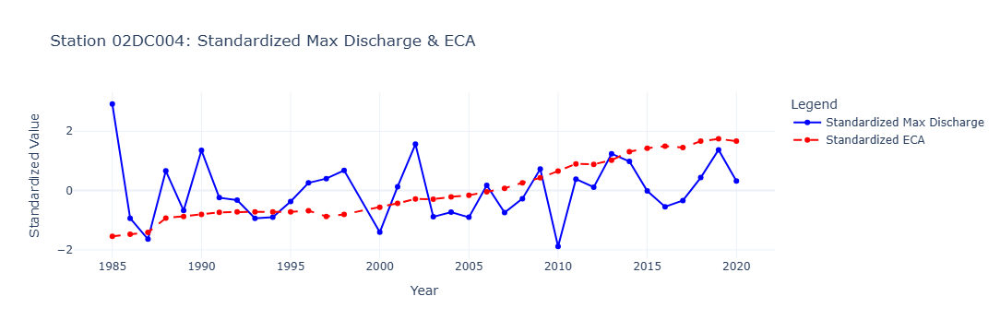

Station: 02EA010
Pearson Correlation: 0.0659
P-value: 0.7026


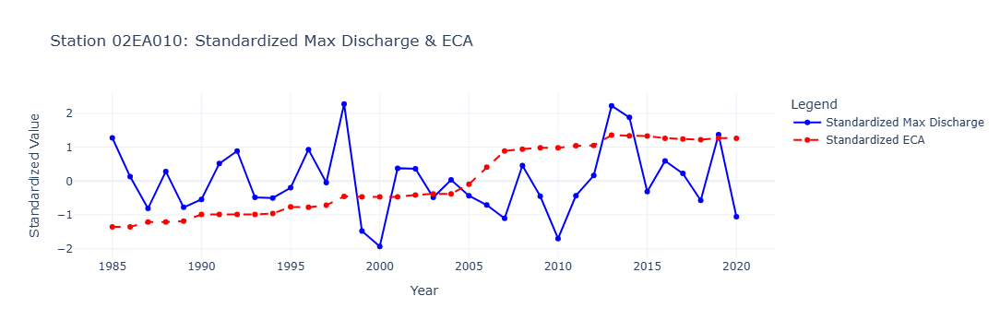

Station: 02EA011
Pearson Correlation: 0.0756
P-value: 0.6708


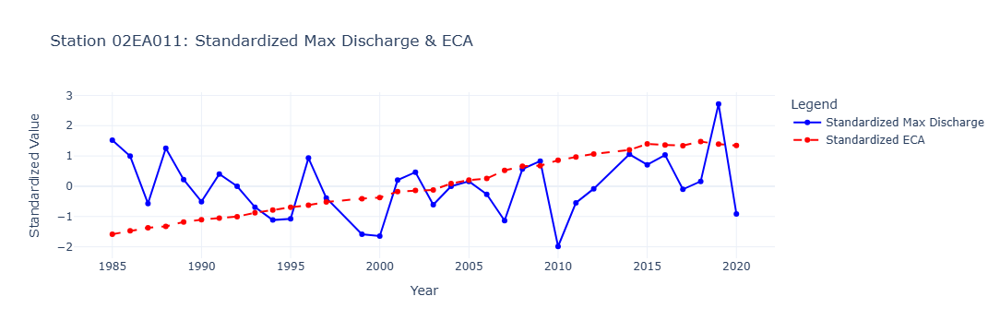

Station: 02EB013
Pearson Correlation: 0.2899
P-value: 0.0864


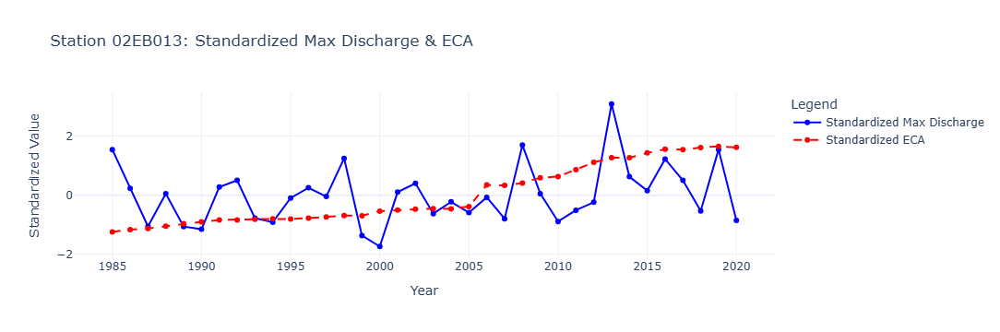

Station: 02HL003
Pearson Correlation: 0.2609
P-value: 0.1244


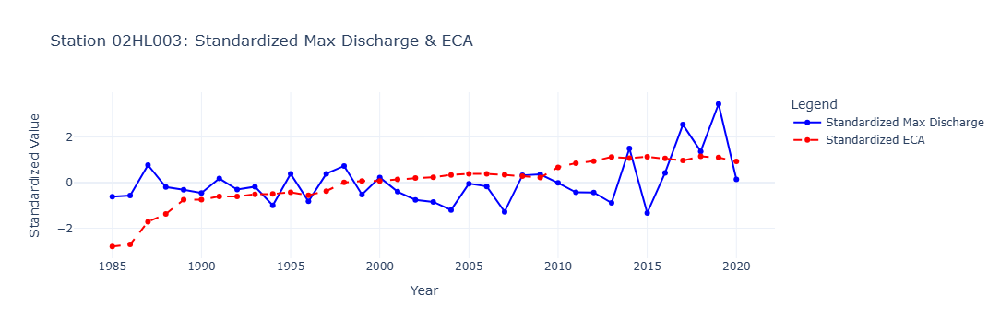

Station: 02JC008
Pearson Correlation: 0.3567
P-value: 0.0354


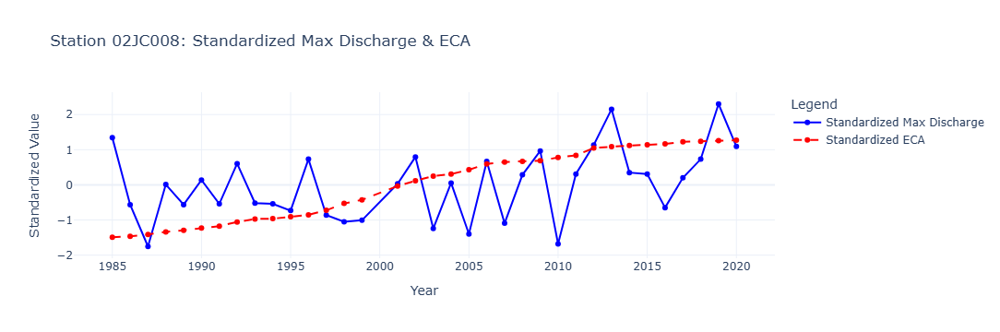

Station: 02KF013
Pearson Correlation: 0.1215
P-value: 0.4868


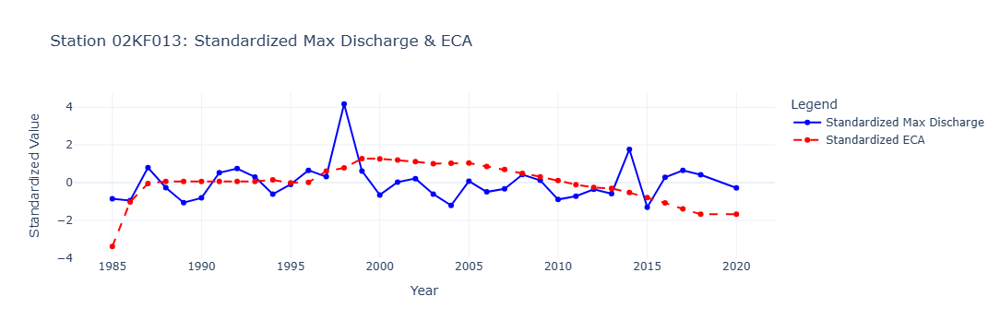

Station: 04GA002
Pearson Correlation: -0.0328
P-value: 0.8585


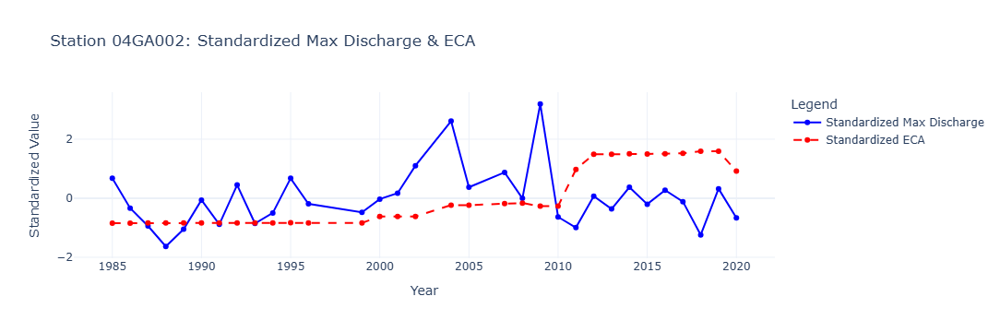

Station: 04GB004
Pearson Correlation: 0.0570
P-value: 0.7487


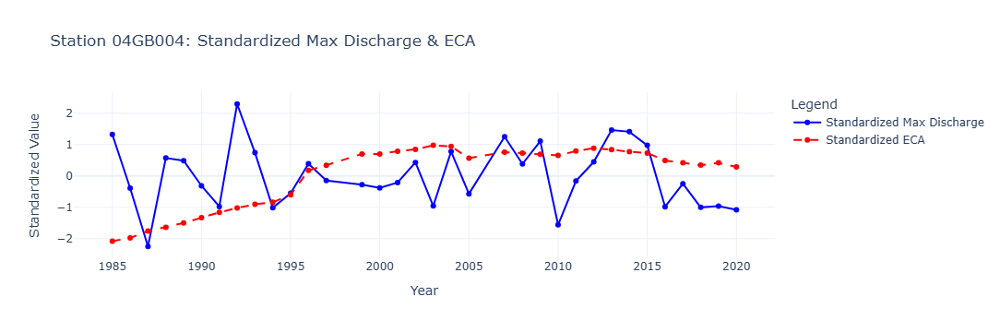

Station: 04JC002
Pearson Correlation: -0.2054
P-value: 0.2516


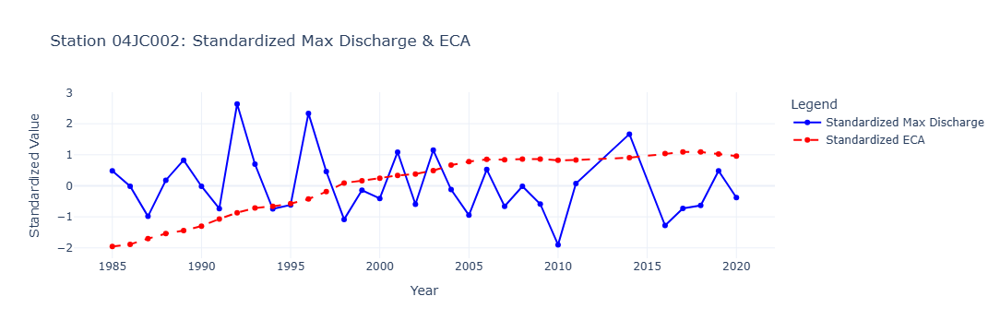

Station: 04JD005
Pearson Correlation: 0.0217
P-value: 0.9014


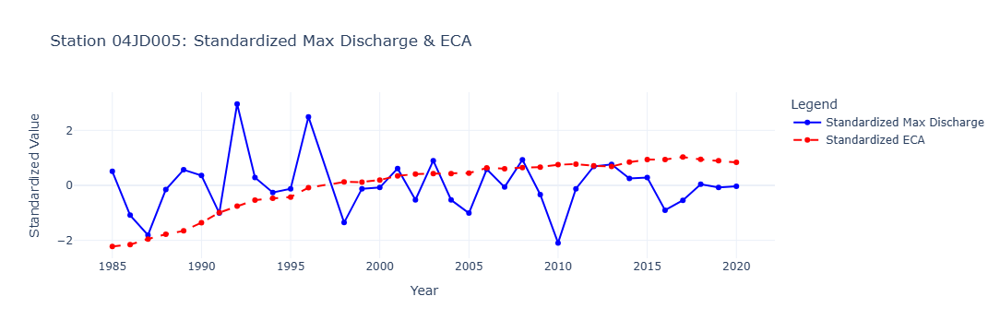

Station: 04LM001
Pearson Correlation: -0.1144
P-value: 0.5194


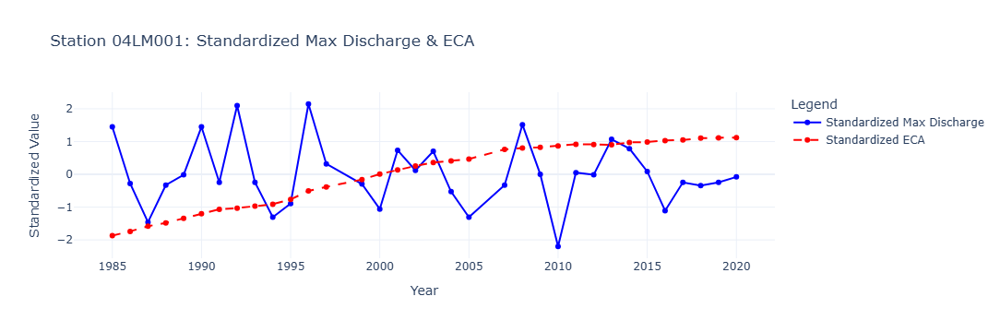

Station: 04MF001
Pearson Correlation: 0.0060
P-value: 0.9723


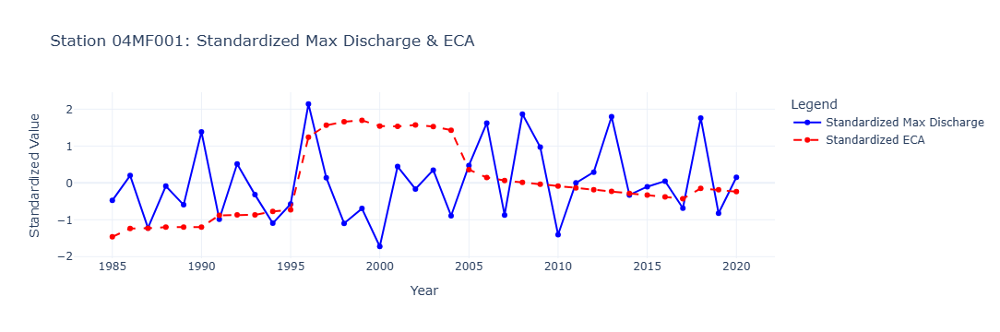

Station: 05QA002
Pearson Correlation: -0.1040
P-value: 0.5462


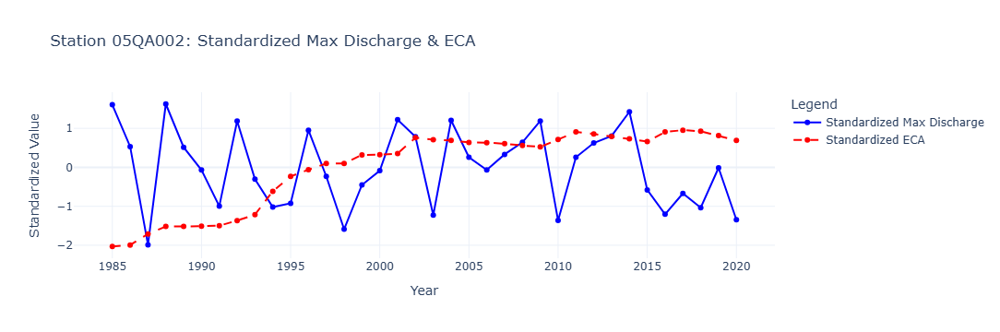

Station: 05QA004
Pearson Correlation: 0.1250
P-value: 0.4678


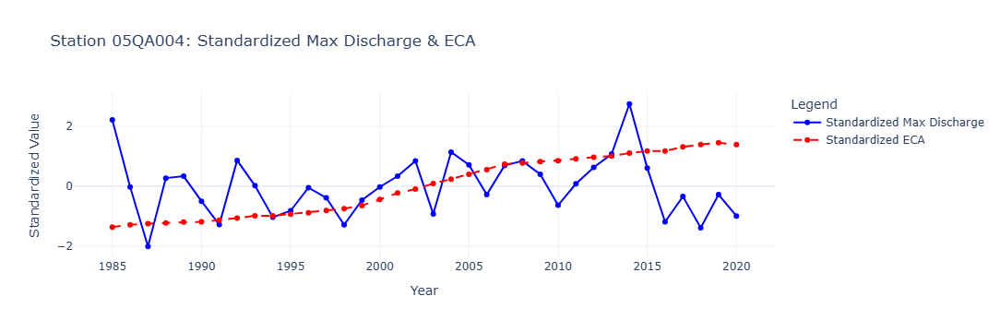

Station: 05QC001
Pearson Correlation: 0.3348
P-value: 0.0493


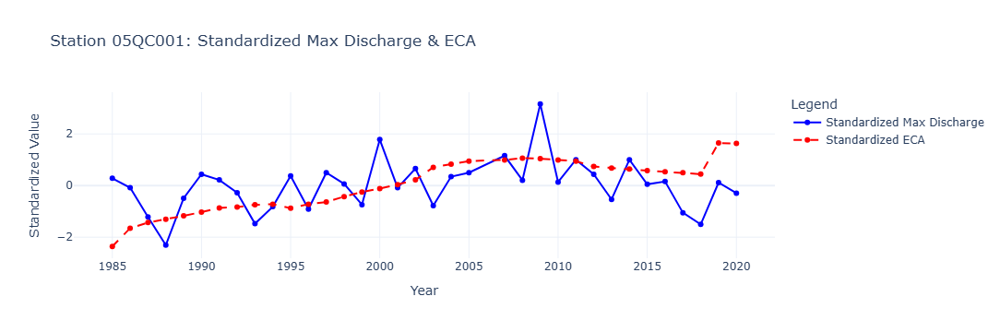

Station: 05QD016
Pearson Correlation: 0.0759
P-value: 0.6600


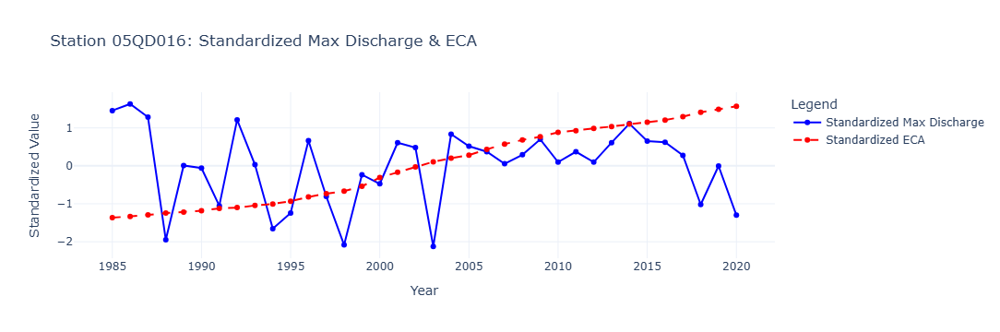

Station: 05QE008
Pearson Correlation: 0.3337
P-value: 0.0467


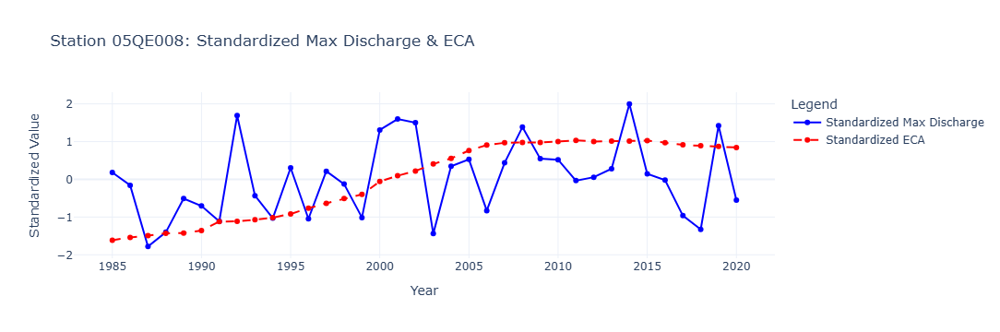

Station: 05QE009
Pearson Correlation: 0.3541
P-value: 0.0341


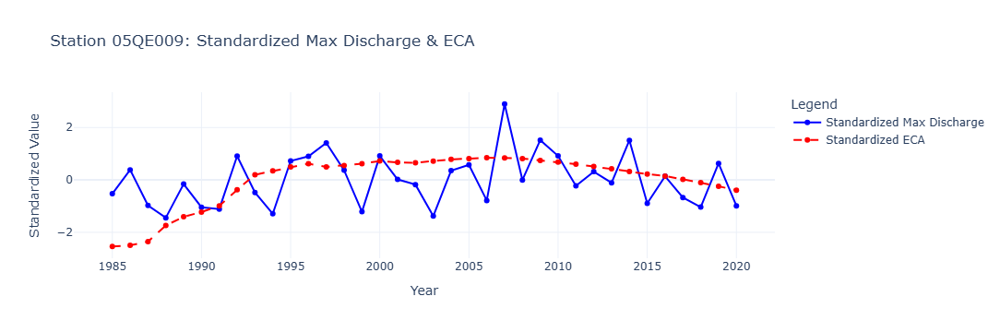

In [21]:
stations = sorted(final_covariates['hydro_station_id'].unique())

for station in stations:
    # filtering the df
    df = final_covariates[final_covariates['hydro_station_id'] == station].copy()
    
    # standardize the variables for better plot
    q = (df['Max_discharge'] - df['Max_discharge'].mean()) / df['Max_discharge'].std()
    eca = (df['Total_ECA_percentage'] - df['Total_ECA_percentage'].mean()) / df['Total_ECA_percentage'].std()
    
    
    # calculate pearson test result
    correlation, p_value = pearsonr(q, eca)
    
    # results:
    print(f"Station: {station}")
    print(f"Pearson Correlation: {correlation:.4f}")
    print(f"P-value: {p_value:.4f}")
    
    # Create interactive plot using Plotly
    fig = go.Figure()
    
    # Add standardized Max Discharge
    fig.add_trace(go.Scatter(x=df['Year'], y=q,
                             mode='lines+markers', name='Standardized Max Discharge',
                             line=dict(color='blue'), marker=dict(size=6)))
    
    # Add standardized ECA
    fig.add_trace(go.Scatter(x=df['Year'], y=eca,
                             mode='lines+markers', name='Standardized ECA',
                             line=dict(color='red', dash='dash'), marker=dict(size=6)))
    
    # Add layout configurations
    fig.update_layout(
        title=f"Station {station}: Standardized Max Discharge & ECA",
        xaxis_title="Year",
        yaxis_title="Standardized Value",
        legend_title="Legend",
        template="plotly_white",
        hovermode="x",
    )
    
    # Show the plot
    fig.show()

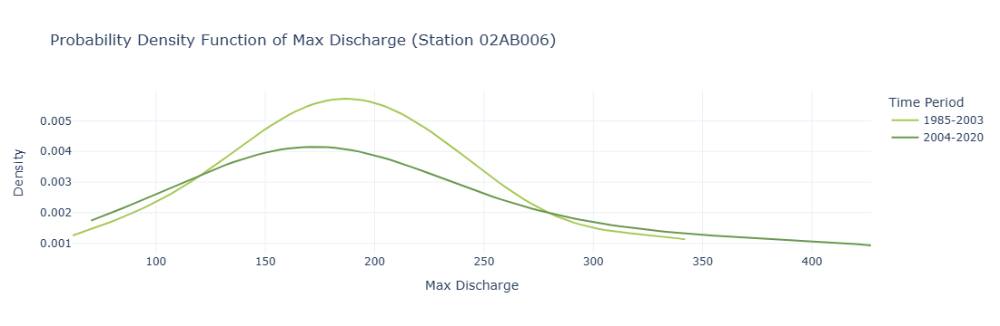

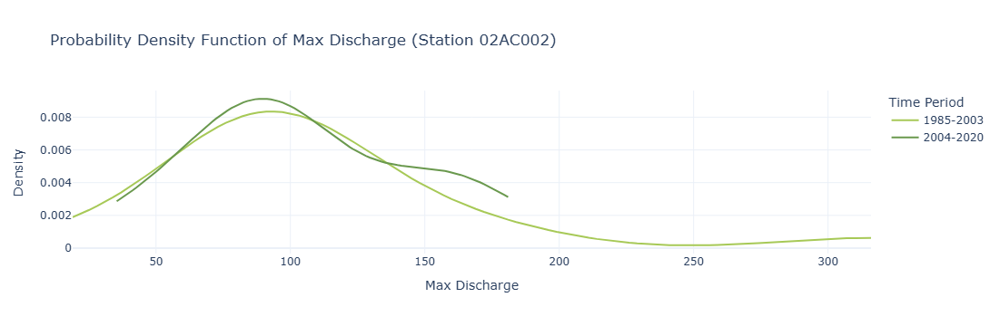

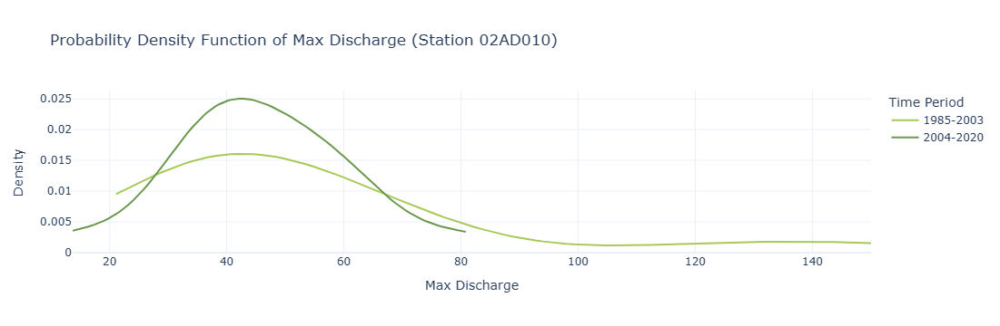

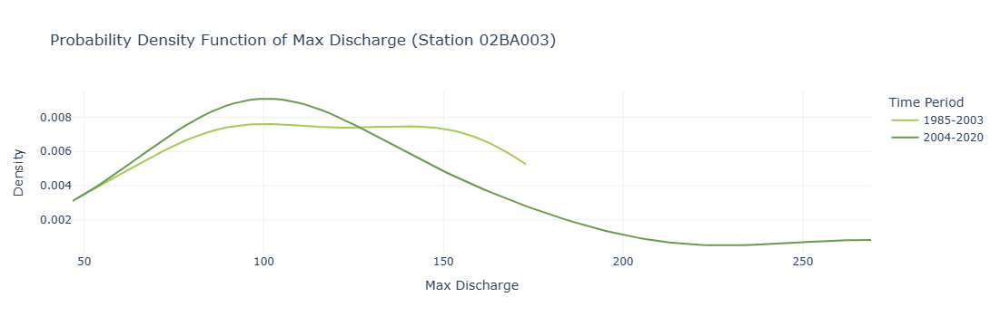

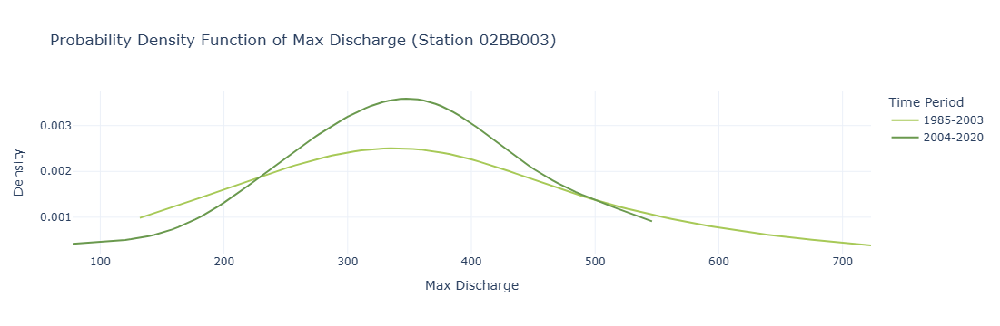

...

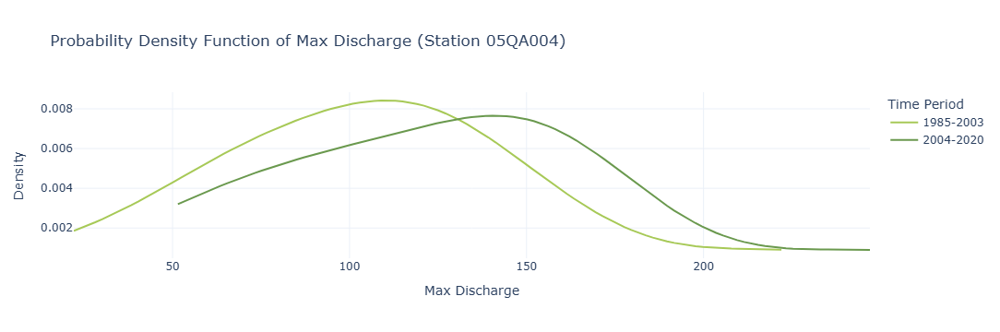

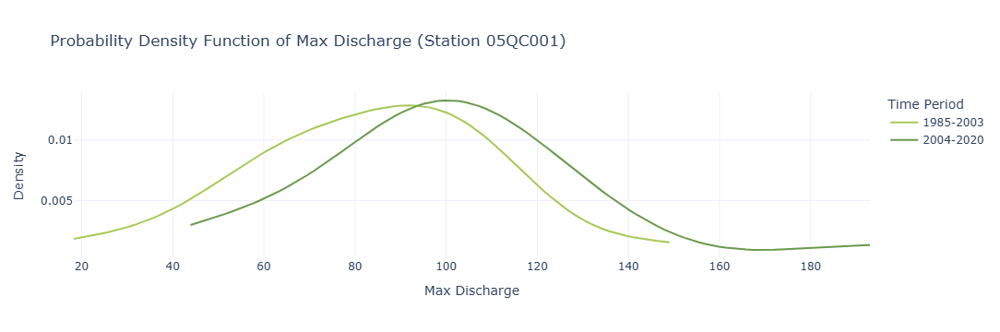

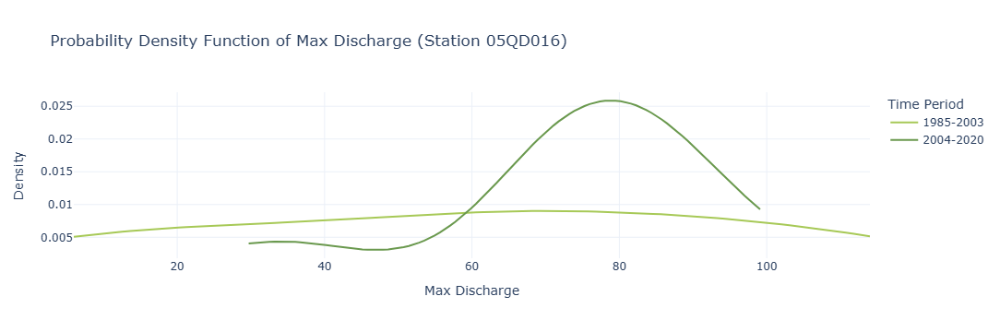

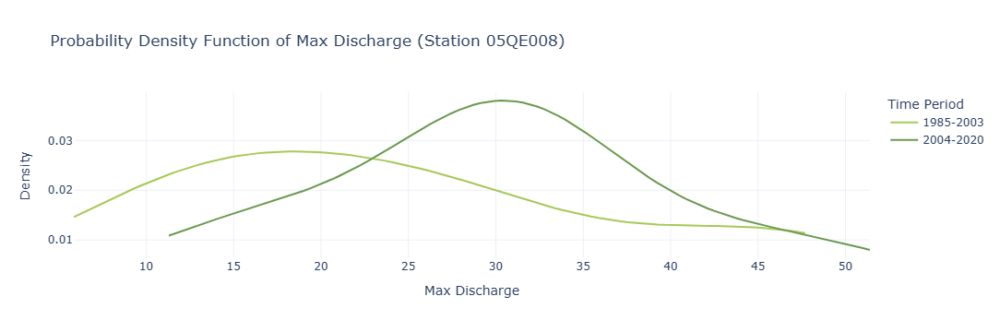

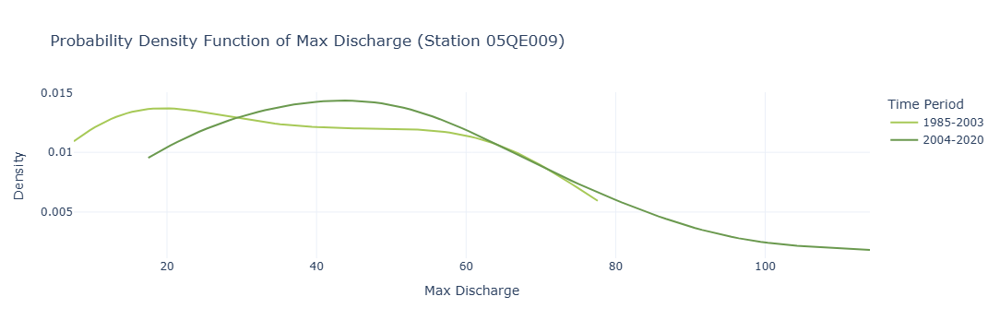

In [30]:

# Get unique station IDs (sorted)
stations = sorted(final_covariates['hydro_station_id'].unique())

# Define time intervals
# bins = [(1985, 1996), (1997, 2008), (2009, 2020)]
# labels = ["1985-1996", "1997-2008", "2009-2020"]
bins = [(1985, 2003), (2004, 2020)]
labels = ["1985-2003", "2004-2020"]
colors = ['#a7c957', '#6a994e', '#386641']  # Different colors for periods

for station in stations:
    # Filter data for the current station
    df = final_covariates[final_covariates['hydro_station_id'] == station]

    # Create figure for PDF plots
    fig = go.Figure()

    for i, (start, end) in enumerate(bins):
        # Select discharge data for the given time period
        period_data = df[(df['Year'] >= start) & (df['Year'] <= end)]['Max_discharge'].dropna()

        if len(period_data) > 1:  # Ensure there's enough data for KDE
            # Compute Kernel Density Estimation (PDF)
            kde = gaussian_kde(period_data)
            x_range = np.linspace(period_data.min(), period_data.max(), 100)
            pdf_values = kde(x_range)

            # Add PDF curve to the plot
            fig.add_trace(go.Scatter(x=x_range, y=pdf_values, mode='lines', 
                                     name=labels[i], line=dict(color=colors[i], width=2)))

    # Customize layout
    fig.update_layout(
        title=f"Probability Density Function of Max Discharge (Station {station})",
        xaxis_title="Max Discharge",
        yaxis_title="Density",
        template="plotly_white",
        legend_title="Time Period"
    )

    # Show plot if at least one time period had valid data
    if len(fig.data) > 0:
        fig.show()
    else:
        print(f"Skipping Station {station}: Not enough data for KDE.")


# Finding which station is disturbed or undisturbed

In this section, I try to find what stations are undisturbed for GEV and which ones can be considered as disturbed

In [10]:
final_covariates.head()

,Unnamed: 0,hydro_station_id,hydro_station_name,Province,Region,Basin,Year,MM-DD,Month,Day,Date,Max_discharge,MIN_discharge,Discharge_unit,WR_1_days,Max_temp_1_days_K,Evaporation_Sum_1_days_mm,Snow_Evaporation_Sum_1_days_mm,Snowfall_Sum_1_days_mm,Snow_Depth_Avg_1_days_cm,Snowmelt_1_days_cm,Surface_Runoff_Sum_1_days_mm,Total_Rainwater_1_days_mm,Total_Precipitation_Sum_1_days_mm,swvl1_Soil_Moisture_Max_1_days_percent,swvl2_Soil_Moisture_Max_1_days_percent,swvl3_Soil_Moisture_Max_1_days_percent,Total_Soil_Moisture_Max_1_days_percent,WR_3_days,Max_temp_3_days_K,Evaporation_Sum_3_days_mm,Snow_Evaporation_Sum_3_days_mm,Snowfall_Sum_3_days_mm,Snow_Depth_Avg_3_days_cm,Snowmelt_3_days_cm,Surface_Runoff_Sum_3_days_mm,Total_Rainwater_3_days_mm,Total_Precipitation_Sum_3_days_mm,swvl1_Soil_Moisture_Max_3_days_percent,swvl2_Soil_Moisture_Max_3_days_percent,swvl3_Soil_Moisture_Max_3_days_percent,Total_Soil_Moisture_Max_3_days_percent,WR_5_days,Max_temp_5_days_K,Evaporation_Sum_5_days_mm,Snow_Evaporation_Sum_5_days_mm,Snowfall_Sum_5_days_mm,Snow_Depth_Avg_5_days_cm,Snowmelt_5_days_cm,Surface_Runoff_Sum_5_days_mm,Total_Rainwater_5_days_mm,Total_Precipitation_Sum_5_days_mm,swvl1_Soil_Moisture_Max_5_days_percent,swvl2_Soil_Moisture_Max_5_days_percent,swvl3_Soil_Moisture_Max_5_days_percent,Total_Soil_Moisture_Max_5_days_percent,WR_7_days,Max_temp_7_days_K,Evaporation_Sum_7_days_mm,Snow_Evaporation_Sum_7_days_mm,Snowfall_Sum_7_days_mm,Snow_Depth_Avg_7_days_cm,Snowmelt_7_days_cm,Surface_Runoff_Sum_7_days_mm,Total_Rainwater_7_days_mm,Total_Precipitation_Sum_7_days_mm,swvl1_Soil_Moisture_Max_7_days_percent,swvl2_Soil_Moisture_Max_7_days_percent,swvl3_Soil_Moisture_Max_7_days_percent,Total_Soil_Moisture_Max_7_days_percent,WR_15_days,Max_temp_15_days_K,Evaporation_Sum_15_days_mm,Snow_Evaporation_Sum_15_days_mm,Snowfall_Sum_15_days_mm,Snow_Depth_Avg_15_days_cm,Snowmelt_15_days_cm,Surface_Runoff_Sum_15_days_mm,Total_Rainwater_15_days_mm,Total_Precipitation_Sum_15_days_mm,swvl1_Soil_Moisture_Max_15_days_percent,swvl2_Soil_Moisture_Max_15_days_percent,swvl3_Soil_Moisture_Max_15_days_percent,Total_Soil_Moisture_Max_15_days_percent,WR_30_days,Max_temp_30_days_K,Evaporation_Sum_30_days_mm,Snow_Evaporation_Sum_30_days_mm,Snowfall_Sum_30_days_mm,Snow_Depth_Avg_30_days_cm,Snowmelt_30_days_cm,Surface_Runoff_Sum_30_days_mm,Total_Rainwater_30_days_mm,Total_Precipitation_Sum_30_days_mm,swvl1_Soil_Moisture_Max_30_days_percent,swvl2_Soil_Moisture_Max_30_days_percent,swvl3_Soil_Moisture_Max_30_days_percent,Total_Soil_Moisture_Max_30_days_percent,WR_40_days,Max_temp_40_days_K,Evaporation_Sum_40_days_mm,Snow_Evaporation_Sum_40_days_mm,Snowfall_Sum_40_days_mm,Snow_Depth_Avg_40_days_cm,Snowmelt_40_days_cm,Surface_Runoff_Sum_40_days_mm,Total_Rainwater_40_days_mm,Total_Precipitation_Sum_40_days_mm,swvl1_Soil_Moisture_Max_40_days_percent,swvl2_Soil_Moisture_Max_40_days_percent,swvl3_Soil_Moisture_Max_40_days_percent,Total_Soil_Moisture_Max_40_days_percent,WR_60_days,Max_temp_60_days_K,Evaporation_Sum_60_days_mm,Snow_Evaporation_Sum_60_days_mm,Snowfall_Sum_60_days_mm,Snow_Depth_Avg_60_days_cm,Snowmelt_60_days_cm,Surface_Runoff_Sum_60_days_mm,Total_Rainwater_60_days_mm,Total_Precipitation_Sum_60_days_mm,swvl1_Soil_Moisture_Max_60_days_percent,swvl2_Soil_Moisture_Max_60_days_percent,swvl3_Soil_Moisture_Max_60_days_percent,Total_Soil_Moisture_Max_60_days_percent,WR_80_days,Max_temp_80_days_K,Evaporation_Sum_80_days_mm,Snow_Evaporation_Sum_80_days_mm,Snowfall_Sum_80_days_mm,Snow_Depth_Avg_80_days_cm,Snowmelt_80_days_cm,Surface_Runoff_Sum_80_days_mm,Total_Rainwater_80_days_mm,Total_Precipitation_Sum_80_days_mm,swvl1_Soil_Moisture_Max_80_days_percent,swvl2_Soil_Moisture_Max_80_days_percent,swvl3_Soil_Moisture_Max_80_days_percent,Total_Soil_Moisture_Max_80_days_percent,ID_hydro_st,harvest_pixel_count,fire_pixel_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage
0,0,02CD006,SERPENT RIVER ABOVE QUIRKE LAKE,ON,O

In [13]:
station_list = final_covariates["hydro_station_id"].unique()
station_list

array(['02CD006', '04GB004', '04JD005', '02BB003', '02BF002', '05QA002',
       '05QC001', '02KF013', '05QD016', '05QE008', '04GA002', '02JC008',
       '02AD010', '02AC002', '02HL003', '02CE002', '02BF001', '02EB013',
       '02DC004', '05QE009', '05QA004', '02EA010', '04MF001', '04JC002',
       '04LM001', '02AB006', '02EA011', '02CC005', '02BA003'],
      dtype=object)

In [17]:
eca_data = []

for station in station_list:
    selected_df = final_covariates[final_covariates['hydro_station_id'] == station]
    min_eca = selected_df['Total_ECA_percentage'].min()
    median_eca = selected_df['Total_ECA_percentage'].median()
    max_eca = selected_df['Total_ECA_percentage'].max()

    eca_data.append({
        'hydro_station_id': station,
        'Min_ECA': min_eca,
        'Median_ECA': median_eca,
        'Max_ECA': max_eca
    })

# Create DataFrame from the list of dictionaries
ECA_range_df = pd.DataFrame(eca_data)


In [33]:
ECA_range_df.sort_values(by = 'Max_ECA')

,hydro_station_id,Min_ECA,Median_ECA,Max_ECA
17,02EB013,0.000000,0.064437,0.240145
7,02KF013,0.108832,0.307350,0.376968
21,02EA010,0.000000,0.161737,0.456252
14,02HL003,0.003201,0.426245,0.558446
26,02EA011,0.009223,0.291439,0.602782
4,02BF002,0.001632,1.978683,2.342541
18,02DC004,0.095584,1.430752,3.578022
22,04MF001,0.000435,1.659618,4.106056
0,02CD006,0.008367,3.783689,5.752492
27,02CC005,0.089607,3.809342,6.279319


In [29]:
# Define the threshold
threshold = 3

# Function to apply row-wise style
def highlight_low_max(row):
    if row['Max_ECA'] < threshold:
        return ['background-color: #FFFADC'] * len(row)
    return [''] * len(row)

# Apply the style to the DataFrame
styled_df = ECA_range_df.style.apply(highlight_low_max, axis=1)

styled_df

,hydro_station_id,Min_ECA,Median_ECA,Max_ECA
0,02CD006,0.008367,3.783689,5.752492
1,04GB004,0.301861,7.418566,8.885115
2,04JD005,0.751243,13.643904,16.570232
3,02BB003,0.206795,13.877216,16.347424
4,02BF002,0.001632,1.978683,2.342541
5,05QA002,0.109966,16.994520,19.697265
6,05QC001,0.302920,8.695122,13.323619
7,02KF013,0.108832,0.307350,0.376968
8,05QD016,0.069875,6.755029,14.017095
9,05QE008,0.107967,5.077990,6.932039


In [ ]:
#list of stations without disturbance
undisturbed_stations = ['02EB013', '02KF013', '02EA010', '02HL003', '02EA011', '02BF002']

# BC ECA Repeatition Test

In [13]:
bc_dir = r"C:\Ellie_Masters\Main\ArcGIS_Projects\BC_Processing"
os.chdir(bc_dir)
# os.listdir()
# fiona.listlayers('BC_Processing.gdb')

In [14]:
harv_deadman = gpd.read_file('BC_Processing.gdb', layer = 'Harv_deadman' )
harv_deadman.columns = [col.replace('C_', '') if col.startswith('C_') else col for col in harv_deadman.columns]
harv_deadman = harv_deadman.drop(['geometry', '0'], axis=1)
fire_deadman = gpd.read_file('BC_Processing.gdb', layer = 'Fire_deadman' )
fire_deadman.columns = [col.replace('C_', '') if col.startswith('C_') else col for col in fire_deadman.columns]
fire_deadman = fire_deadman.drop(['geometry', '0'], axis=1)

In [15]:
harv_deadman_long = convert_to_long_format(harv_deadman, 'gridcode', 'Harvest_count')
fire_deadman_long = convert_to_long_format(fire_deadman, 'gridcode', 'Fire_count')

In [16]:
harv_deadman_long

,gridcode,Year,Harvest_count
0,196,1985,2327.0
1,196,1986,3478.0
2,196,1987,2811.0
3,196,1988,4753.0
4,196,1989,2153.0
5,196,1990,3318.0
6,196,1991,4919.0
7,196,1992,3643.0
8,196,1993,4338.0
9,196,1994,6223.0


In [17]:
# merging fire and harvest pixel count
merged_harv_fire_deadman = pd.merge(harv_deadman_long, fire_deadman_long, on = 'Year')

merged_harv_fire_deadman['Year'] = pd.to_numeric(merged_harv_fire_deadman['Year'])
# Adding area in hectares
## each pixrl is 900 m2 and each hectare is 10,000 m2
merged_harv_fire_deadman['harvest_area_ha'] = merged_harv_fire_deadman['Harvest_count'] * 900 / 10000
merged_harv_fire_deadman['fire_area_ha'] = merged_harv_fire_deadman['Fire_count'] * 900 / 10000

merged_harv_fire_deadman['drainage_area_ha'] = 841787984.820367 / 10000
merged_harv_fire_deadman['ID_hydro_st'] = '08LF027'

In [66]:
def BC_calculate_ECA_harvest(df, harvest_area_column, output_column):
    """
    Calculates the Equivalent Clearcut Area (ECA) for each year in a DataFrame using a specified area column.
    
    Parameters:
    - df (pd.DataFrame): A DataFrame with a 'Year' column and an area column specified by the user.
    - harvest_area_column (str): The name of the column to use for area values.
    - output_column (str): The name of the new column to store the calculated ECA values.
    
    Returns:
    - pd.DataFrame: The input DataFrame with an additional column for the calculated ECA, using the specified output column name.
    """
    # Sort by year to ensure proper cumulative calculations
    df = df.sort_values('Year').reset_index(drop=True)
    
    # Initialize the ECA column with the specified output column name
    df[output_column] = 0.0
    
    # Loop through each year to calculate cumulative ECA
    for i, row in df.iterrows():
        year = row['Year']
        area = row[harvest_area_column]
        
        # Start with the current year's ECA contribution
        current_year_ECA = area * (1 - 0)  # Since current year HR is always zero
        cumulative_ECA = current_year_ECA
        
        # Add contributions from previous years
        for j in range(i):
            tsd = i - j  # Time since disturbance
            prev_area = df.at[j, harvest_area_column]
            
            # Calculate HR based on TSD
            if tsd <= 25:
                hr = 0
            else:
                hr = max(0, -37.37 + 7.41 * tsd - 0.017 * tsd**2)  # HR should not go negative
            
            # Add adjusted area to cumulative ECA
            cumulative_ECA += prev_area * (1 - hr / 80)
        
        # Update the ECA for the current year with the specified output column
        df.at[i, output_column] = cumulative_ECA

    return df

def BC_calculate_ECA_for_all_stations(df, id_column='ID_hydro_st', harvest_area_column='harvest_area_ha', 
                                   fire_area_column='fire_area_ha', drainage_area_column='drainage_area_ha', 
                                   save=False, save_path=None, file_name='ECA_results.csv'):
    """
    Function to calculate ECA percentages for harvest and fire for all stations 
    using existing functions and return a new DataFrame with results.
    
    Parameters:
    - df: DataFrame containing station data.
    - id_column: Column name representing station IDs.
    - harvest_area_column: Column name representing harvest area in hectares.
    - fire_area_column: Column name representing fire area in hectares.
    - drainage_area_column: Column name representing drainage area in hectares.
    - save: Boolean indicating whether to save the resulting DataFrame to a CSV file.
    - save_path: Directory path where the CSV file should be saved (required if save=True).
    - file_name: Name of the CSV file to be saved (default is 'ECA_results.csv').
    
    Returns:
    - A new DataFrame with ECA and percentage columns for all stations.
    """
    
    result_list = []  # List to store results for each station
    
    # Get unique station IDs
    unique_stations = df[id_column].unique()
    
    # Loop through each station
    for station_id in unique_stations:
        # Filter DataFrame for the current station
        station_df = filter_dataframe(df, column_name=id_column, target_value=station_id)
        
        # Calculate ECA for harvest
        station_df = BC_calculate_ECA_harvest(station_df, harvest_area_column=harvest_area_column, output_column='ECA_Harvest_ha')
        station_df['ECA_harvest_perc'] = station_df['ECA_Harvest_ha'] / station_df[drainage_area_column] * 100
        
        # Calculate ECA for fire
        station_df = calculate_ECA_fire(station_df, fire_area_column=fire_area_column, output_column='ECA_Fire_ha')
        station_df['fire_perc'] = station_df['ECA_Fire_ha'] / station_df[drainage_area_column] * 100

        station_df['Total_ECA_percentage'] = station_df['fire_perc'] + station_df['ECA_harvest_perc']
        
        # Append the processed DataFrame to the result list
        result_list.append(station_df)
    
    # Concatenate all results into a single DataFrame
    final_df = pd.concat(result_list, ignore_index=True)
    
    # Save the final DataFrame if save=True
    if save:
        if save_path is None:
            raise ValueError("save_path must be provided if save=True")
        full_path = f"{save_path}/{file_name}"
        final_df.to_csv(full_path, index=False)
        print(f"File saved successfully at: {full_path}")
    
    return final_df


In [67]:
deadman_eca = BC_calculate_ECA_for_all_stations(merged_harv_fire_deadman, id_column='ID_hydro_st', harvest_area_column='harvest_area_ha', 
                                   fire_area_column='fire_area_ha', drainage_area_column='drainage_area_ha', 
                                   save=False)

deadman_eca['Harvest_perc'] = deadman_eca['harvest_area_ha'] / deadman_eca['drainage_area_ha'] * 100
deadman_eca['Fire_perc'] = deadman_eca['fire_area_ha'] / deadman_eca['drainage_area_ha'] * 100

In [68]:
deadman_eca

,gridcode_x,Year,Harvest_count,gridcode_y,Fire_count,harvest_area_ha,fire_area_ha,drainage_area_ha,ID_hydro_st,ECA_Harvest_ha,ECA_harvest_perc,ECA_Fire_ha,fire_perc,Total_ECA_percentage,Harvest_perc,Fire_perc
0,196,1985,2327.0,196,0.0,209.43,0.00,84178.798482,08LF027,209.430000,0.248792,0.000000,0.000000,0.248792,0.248792,0.000000
1,196,1986,3478.0,196,0.0,313.02,0.00,84178.798482,08LF027,522.450000,0.620643,0.000000,0.000000,0.620643,0.371851,0.000000
2,196,1987,2811.0,196,0.0,252.99,0.00,84178.798482,08LF027,775.440000,0.921182,0.000000,0.000000,0.921182,0.300539,0.000000
3,196,1988,4753.0,196,0.0,427.77,0.00,84178.798482,08LF027,1203.210000,1.429350,0.000000,0.000000,1.429350,0.508168,0.000000
4,196,1989,2153.0,196,0.0,193.77,0.00,84178.798482,08LF027,1396.980000,1.659539,0.000000,0.000000,1.659539,0.230189,0.000000
5,196,1990,3318.0,196,0.0,298.62,0.00,84178.798482,08LF027,1695.600000,2.014284,0.000000,0.000000,2.014284,0.354745,0.000000
6,196,1991,4919.0,196,0.0,442.71,0.00,84178.798482,08LF027,2138.310000,2.540200,0.000000,0.000000,2.540200,0.525916,0.000000
7,196,1992,3643.0,196,0.0,327.87,0.00,84178.798482,08LF027,2466.180000,2.929693,0.000000,0.000000,2.929693,0.389492,0.000000
8,196,1993,4338.0,196,0.0,390.42,0.00,84178.798482,08LF027,2856.600000,3.393491,0.000000,0.000000,3.393491,0.463798,0.000000
9,196,1994,6223.0,196,0.0,560.07,0.00,84178.798482,08LF027,3416.670000,4.058825,0.000000,0.000000,4.058825,0.665334,0.000000


In [69]:
def plot_ECA_station_data(df):
    # Get unique station IDs
    unique_stations = df['ID_hydro_st'].unique()
    
    for station_id in unique_stations:
        # Subset the dataframe for the current station ID
        station_df = df[df['ID_hydro_st'] == station_id]
        
        # Convert the drainage area to hectares
        drainage_area_ha = station_df['drainage_area_ha'].iloc[0] / 10_000
        
        # Create the figure
        fig = go.Figure()
        
        # Add bar for 'fire_area%' (color: f87060)
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['Fire_perc'] / drainage_area_ha * 100 ,
            name='Fire Area %',
            yaxis='y2',
            marker_color='#f87060'
        ))
        
        # Add bar for 'harvest_area%' (color: fed766, beb7a4)
        fig.add_trace(go.Bar(
            x=station_df['Year'],
            y=station_df['Harvest_perc'] / drainage_area_ha * 100,
            name='Harvest Area %',
            yaxis='y2',
            marker_color='#beb7a4'
        ))
        
        # Add line with dots for 'total_ECA_%' over 'Year' (color: 102542)
        fig.add_trace(go.Scatter(
            x=station_df['Year'],
            y=station_df['Total_ECA_percentage'],
            mode='lines+markers',
            name='Total ECA %',
            line=dict(color='#102542'),
            marker=dict(symbol='circle', size=8)
        ))
        
        # Update layout for dual y-axes and formatting
        fig.update_layout(
            title=f'Station {station_id} - Total ECA %, Harvest Area %, and Fire Area % Over Years (Drainage Area: {drainage_area_ha:.2f} ha)',
            xaxis=dict(
                title='Year',
                tickangle=45,
                tickmode='linear'
            ),
            yaxis=dict(
                title='Total ECA %',
                showgrid=True
            ),
            yaxis2=dict(
                title='Harvest and Fire Area %',
                overlaying='y',
                side='right'
            ),
            plot_bgcolor='whitesmoke',
            font=dict(family='Times New Roman', size=14),
            legend=dict(x=0.01, y=0.99),
            height = 600
        )

        # Show and export the plot as PDF
        fig.write_image(f"station_{station_id}_eca_plot.pdf")
        fig.show()


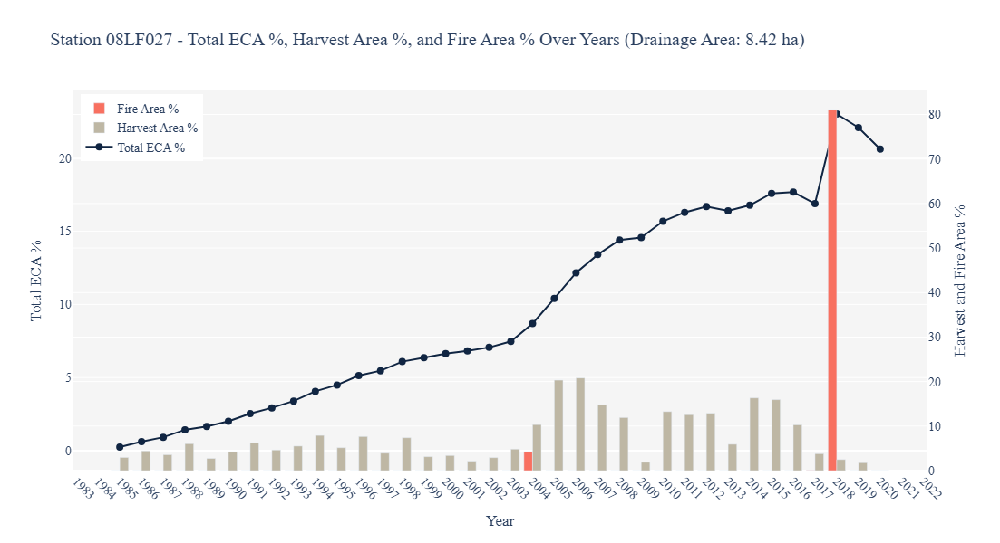

In [70]:
plot_ECA_station_data(deadman_eca)

**Comparing the method to ECA calculated using Hodson and Horel HR curves**

In [71]:
# making a df out of johnson's raw data
Johnsons_eca = [
    2.903693, 2.899140, 3.136499, 3.299838, 3.494151, 4.420776, 4.750535, 4.861927,
    5.709196, 6.181938, 6.543406, 7.406067, 7.714285, 8.185574, 8.675309, 8.682696,
    9.154295, 9.522547, 9.898110, 10.270626, 10.892289, 11.780042, 11.920839, 12.598344,
    12.764728, 12.874268, 13.208579, 13.179450, 13.407145, 14.065559, 15.727853, 17.211211,
    18.437621, 19.365115, 19.679955, 20.232667, 21.446338, 23.298260, 24.317767, 
    # 26.215934, 29.384391
]

johnsons_year = [
    1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989,
    1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
    2006, 2007, 2008, 2009, 2010, 2011, 2012, 
    # 2013, 2014
]

johnsons_df = pd.DataFrame({'Year': johnsons_year, 'Johnsons_eca': Johnsons_eca})

Looking at the difference happening after **2012**, I checked the total disturbance area johnson has made eca based on 2012 is much higher than 2011 and 2013 is much higher than 2012! and 2014 the highest of them. (this is due to consideration fo moutain pine beetle. in out data (considering fire and harvest) 2013 is less than 2012 not higher! so that is the reason of the difference there. (so I excluded 2012 aafter)

In [50]:
johnsons_df

,Year,Johnsons_eca
0,1974,2.903693
1,1975,2.899140
2,1976,3.136499
3,1977,3.299838
4,1978,3.494151
5,1979,4.420776
6,1980,4.750535
7,1981,4.861927
8,1982,5.709196
9,1983,6.181938


In [72]:
my_df = deadman_eca[['Year', 'Total_ECA_percentage']]

In [66]:
my_df

,Year,Total_ECA_percentage
0,1985,0.248792
1,1986,0.620643
2,1987,0.921182
3,1988,1.429350
4,1989,1.659539
5,1990,2.014284
6,1991,2.540200
7,1992,2.929693
8,1993,3.393491
9,1994,4.042106


In [73]:
# joining my df and johnson df
comparison_df = pd.merge(my_df, johnsons_df, on = 'Year', how= 'inner')


# removing the eca from years before that for better comparison of the behavior
difference = comparison_df['Johnsons_eca'].iloc[0] - comparison_df['Total_ECA_percentage'].iloc[0]

comparison_df['johnson_eca_85_2014'] = comparison_df['Johnsons_eca'] - difference

In [74]:
comparison_df

,Year,Total_ECA_percentage,Johnsons_eca,johnson_eca_85_2014
0,1985,0.248792,7.406067,0.248792
1,1986,0.620643,7.714285,0.557010
2,1987,0.921182,8.185574,1.028299
3,1988,1.429350,8.675309,1.518034
4,1989,1.659539,8.682696,1.525421
5,1990,2.014284,9.154295,1.997020
6,1991,2.540200,9.522547,2.365272
7,1992,2.929693,9.898110,2.740835
8,1993,3.393491,10.270626,3.113351
9,1994,4.058825,10.892289,3.735014


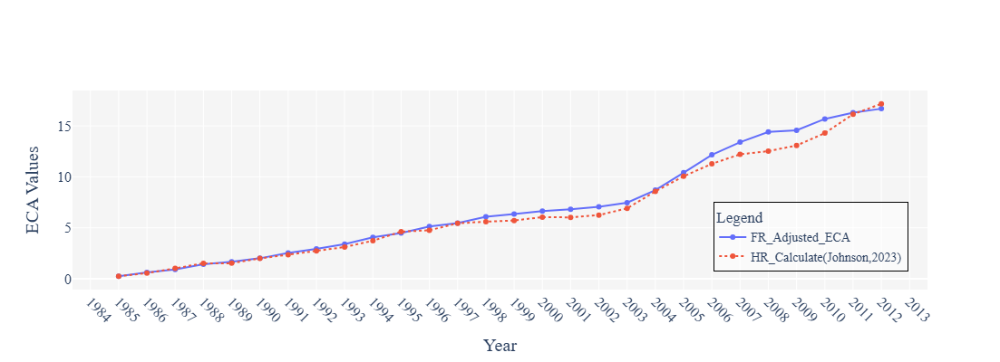

In [75]:
import plotly.graph_objects as go
import plotly.io as pio

# Create Figure
fig = go.Figure()

# Add traces for each column
fig.add_trace(go.Scatter(
    x=comparison_df['Year'], 
    y=comparison_df['Total_ECA_percentage'], 
    mode='lines+markers',
    name='FR_Adjusted_ECA',
    line=dict(width=2),
    marker=dict(size=6)
))

fig.add_trace(go.Scatter(
    x=comparison_df['Year'], 
    y=comparison_df['johnson_eca_85_2014'], 
    mode='lines+markers',
    name='HR_Calculate(Johnson,2023)',
    line=dict(width=2, dash='dot'),
    marker=dict(size=6)
))

# Update layout with improved legend
fig.update_layout(
    xaxis=dict(
        title='Year', 
        title_font=dict(family='Times New Roman', size=20),
        tickangle=45,
        tickmode='linear',
        dtick=1  
    ),
    yaxis=dict(
        title='ECA Values', 
        title_font=dict(family='Times New Roman', size=20)
    ),
    font=dict(family='Times New Roman', size=16),
    plot_bgcolor='whitesmoke',
    width=900,
    height=400,
    legend=dict(
        title='Legend',
        font=dict(family='Times New Roman', size=14),
        x=0.75,  # Adjust horizontal position (0 = left, 1 = right)
        y=0.09,  # Adjust vertical position (0 = bottom, 1 = top)
        bgcolor='rgba(255,255,255,0.5)',  # Semi-transparent background
        bordercolor='black',
        borderwidth=1
    )
)

# Show the plot
fig.show()


In [76]:
os.chdir(r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures")

# Save as a high-resolution PNG
pio.write_image(fig, "HR_FR_comparison2_plot_Carolinean.png", scale=3)  # Higher scale = better resolution

'C:\\Ellie_Masters\\Main\\ArcGIS_Projects\\BC_Processing'

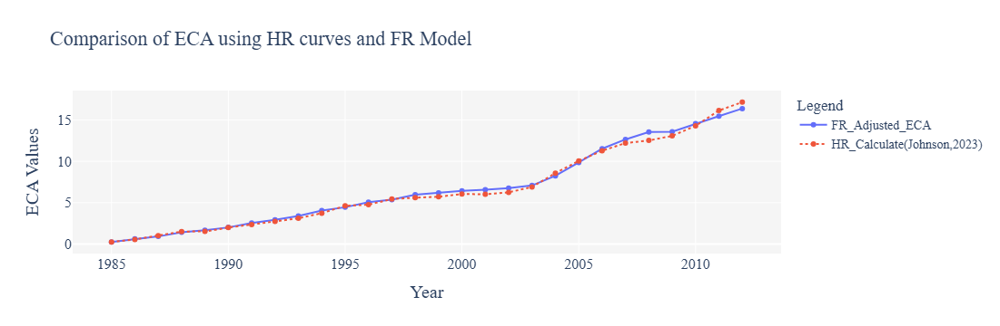

In [72]:
# Comparison Plot!:

fig = go.Figure()

# Add traces for each column
fig.add_trace(go.Scatter(
    x=comparison_df['Year'], 
    y=comparison_df['Total_ECA_percentage'], 
    mode='lines+markers',
    name='FR_Adjusted_ECA',
    line=dict(width=2),
    marker=dict(size=6)
))

fig.add_trace(go.Scatter(
    x=comparison_df['Year'], 
    y=comparison_df['johnson_eca_85_2014'], 
    mode='lines+markers',
    name='HR_Calculate(Johnson,2023)',
    line=dict(width=2, dash='dot'),
    marker=dict(size=6)
))

# Update layout
fig.update_layout(
    title='Comparison of ECA using HR curves and FR Model',
    xaxis=dict(title='Year', title_font=dict(family='Times New Roman', size=20)),
    yaxis=dict(title='ECA Values', title_font=dict(family='Times New Roman', size=20)),
    font=dict(family='Times New Roman', size=16),
    plot_bgcolor='whitesmoke',
    legend=dict(title='Legend', font=dict(family='Times New Roman', size=14)),
    height = 350
)

# Show the plot
fig.show()

**use the BC HR curves for making ECA for Ontario**

**ECA being calculated using basal area models**

# Attribution

In [27]:
# file paths for attribution when counter factual scenarioes with fixed eca and changing colimate covs were in the play
counter_max_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Counter_Factual\Return_Levels_Max_ECA"
# return periods with variables covs both in eca and climate covs (like real scenario)
counter_min_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Counter_Factual\Return_Levels_Min_ECA"
#moving covs both in climate and eca
real_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Return_Levels_Vriable_Climatic_ECA"
# return periods in case of isolating the effect of eca so only eca being variable with fixed climatic covs
isolate_eca_rp_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Return_Levels_Fixed_Climatic_Changing_ECA"
#attr_trend_test_path = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Trend_Test_Results"

In [28]:
save_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals"

In [29]:
#station_list = extract_station_ids(real_dir)
#station_list

# station_list = [
#     "02AB006",
#     "02AC002",
#     "02AD010",
#     "02CC005",
#     "02CE002",
#     "02JC008",
#     "04JD005",
#     "04LM001",
#     "04MF001",
#     "05QD016",
#     "05QE009"
# ]

station_list = [
    "02AD010",
    "04JD005",
    "05QD016"
]

In [30]:
year_return = [2, 5, 7, 10, 15, 20, 30, 35, 50, 100]

for station in station_list:
    return_levels_dict = get_return_levels_across_scenarios(
        station, 
        counter_max_dir, 
        counter_min_dir, 
        real_dir, 
        return_years=year_return
    )
    
    for year in year_return:
        plot_combined_return_levels_and_boxplots(
            return_levels_dict=return_levels_dict,
            station=station,
            scenarios_to_plot=['max', 'min'],
            return_years_to_plot=[year],
            save=True,
            save_path=save_dir,
            save_name=f"Counterfactual_{year}Yr_scenarios_{station}_station_results",
            save_format="svg"
        )

    
    mann_whitney_test_return_levels(
        station, 
        return_levels_dict, 
        return_periods_of_interest=None,
        save=True,
        save_name=f"Mann_Whitney_U_test_{station}_station_results",
        save_dir=r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Data\Reprocessed_Data\Mann_Whitnet_Results_Apr_2025"
    )


Combined plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals\Counterfactual_2Yr_scenarios_02AD010_station_results.svg
Combined plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals\Counterfactual_5Yr_scenarios_02AD010_station_results.svg
Combined plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals\Counterfactual_7Yr_scenarios_02AD010_station_results.svg
Combined plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals\Counterfactual_10Yr_scenarios_02AD010_station_results.svg
Combined plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Counter_Facuals\Counterfactual_15Yr_scenarios_02AD010_station_results.svg
Combined plot saved successfully at: C

Plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Trend_attibution\Trend_with_fixed_climatic_covs_02AD010_station.svg


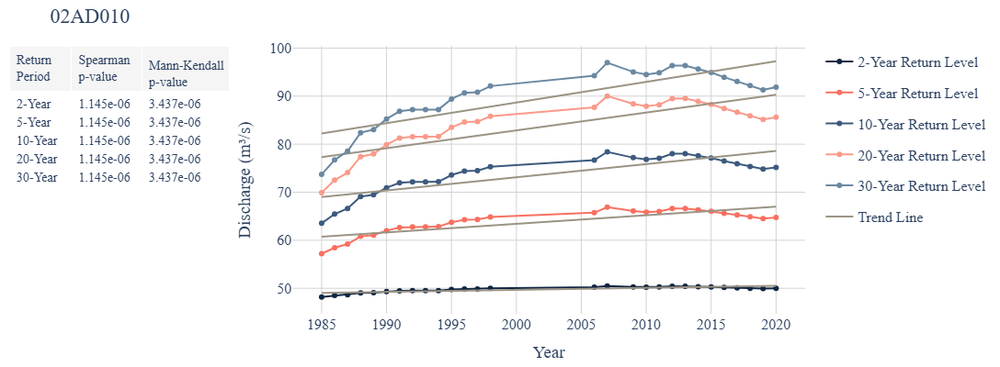

Plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Trend_attibution\Trend_with_fixed_climatic_covs_04JD005_station.svg


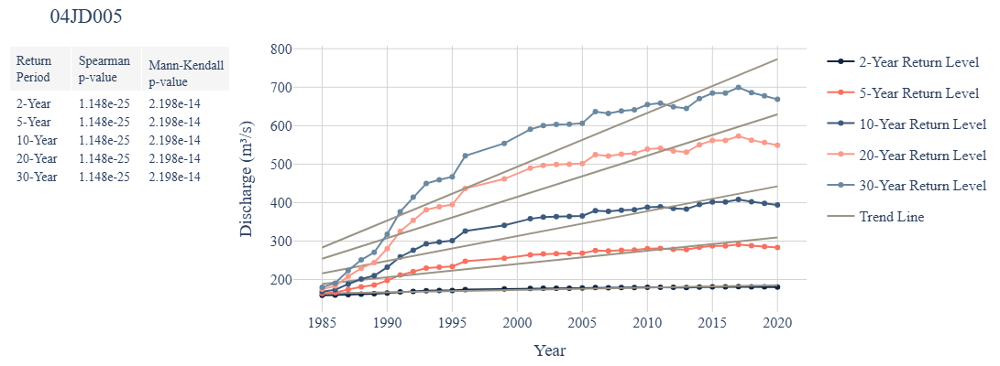

Plot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Trend_attibution\Trend_with_fixed_climatic_covs_05QD016_station.svg


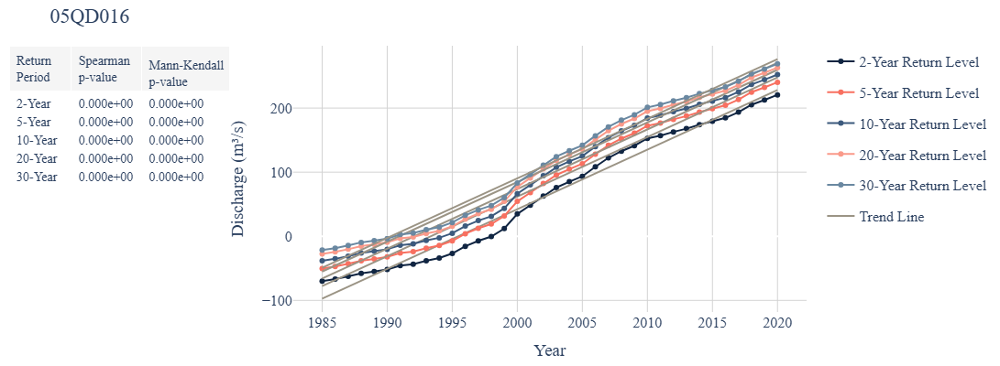

In [31]:
for station in station_list:
    RL_dict = get_RL_variabe_eca_fixed_climate(station, 
                                     isolate_eca_rp_dir, 
                                     return_years=[2, 5, 10, 20, 30])
    
    plot_trend_table_with_graph(station, RL_dict, return_periods_of_interest=None, save = True, 
                                save_path = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Trend_attibution",
                                save_name = f"Trend_with_fixed_climatic_covs_{station}_station"
                               )

In [442]:
station = "02AB006"

test = get_RL_variabe_eca_fixed_climate(station, 
                                     isolate_eca_rp_dir, 
                                     return_years=[2, 5, 10, 20, 30])

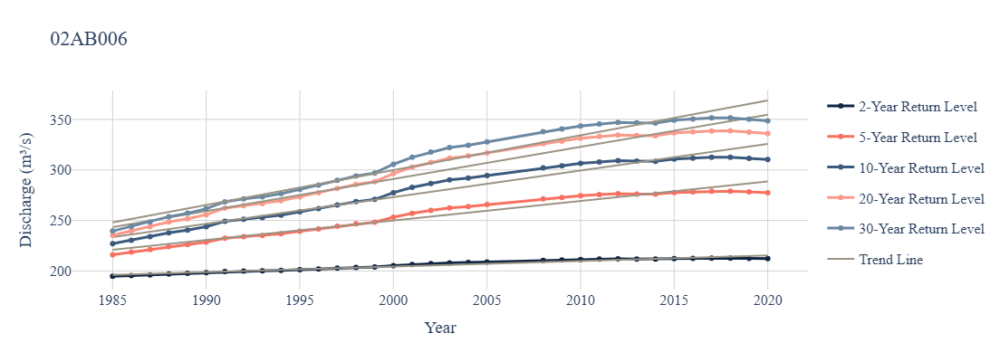

In [387]:
plot_single_scenario_return_levels(test, 
                                       station,
                                       return_years_to_plot=None,
                                       width=800, 
                                       height=400,
                                       y_tick_step=None,
                                       save=False,
                                       save_path=None,
                                       save_name=None,
                                       save_format="svg")

In [392]:
trend_test_fixed_climate(station,
                             test,
                             return_periods_of_interest=None,
                             save=False,
                             save_name=None,
                             save_dir=None)


Trend Test P-Values for station 02AB006:


,Return_Period,Spearman_p,MannKendall_p
0,2,1.169e-30,1.554e-15
1,5,1.169e-30,1.554e-15
2,10,1.169e-30,1.554e-15
3,20,1.169e-30,1.554e-15
4,30,1.169e-30,1.554e-15


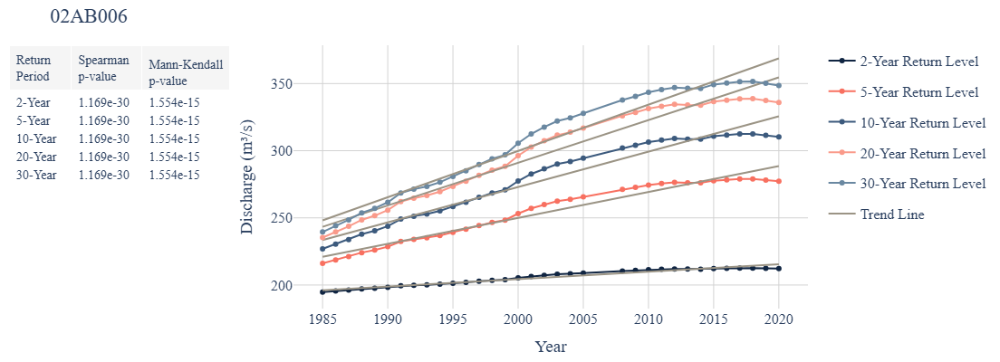

In [443]:
plot_trend_table_with_graph(station, test, return_periods_of_interest=None)

# Quantification

In [32]:
quant_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Quantification"

os.chdir(quant_dir)
os.listdir()

quant_out_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure"

In [4]:
station_list = [
    "02AB006",
    "02AC002",
    "02AD010",
    "02CC005",
    "02CE002",
    "02JC008",
    "04JD005",
    "04LM001",
    "04MF001",
    "05QD016",
    "05QE009"
]

In [11]:
station = "02AB006"

quant_df = get_dataframe(station, quant_dir)

In [12]:
quant_df

,Station_ID,Return_Period,Exceedance_Probability,Valid_ECA_Min,Valid_ECA_Max,Discharge_ECA_Min,Discharge_ECA_Max,ECA_Flood_Risk_Increase_Percentage
0,02AB006,1.5,0.666667,0.709215,18.125181,183.940904,179.042977,-2.662772
1,02AB006,2.0,0.500000,0.709215,18.125181,194.761997,212.656748,9.188010
2,02AB006,5.0,0.200000,0.709215,18.125181,216.106884,278.960783,29.084636
3,02AB006,7.0,0.142857,0.709215,18.125181,221.720504,296.398481,33.681133
4,02AB006,10.0,0.100000,0.709215,18.125181,226.916039,312.537473,37.732649
5,02AB006,15.0,0.066667,0.709215,18.125181,232.077516,328.570667,41.577984
6,02AB006,20.0,0.050000,0.709215,18.125181,235.341602,338.709961,43.922689
7,02AB006,30.0,0.033333,0.709215,18.125181,239.467577,351.526557,46.795053
8,02AB006,35.0,0.028571,0.709215,18.125181,240.906491,355.996284,47.773637
9,02AB006,50.0,0.020000,0.709215,18.125181,243.991614,365.579662,49.832880


In [10]:
quant_df["Valid_ECA_Min"].unique()[0]

0.709214936644166

In [21]:
quant_df.columns

Index(['Station_ID', 'Return_Period', 'Exceedance_Probability',
       'Valid_ECA_Min', 'Valid_ECA_Max', 'Discharge_ECA_Min',
       'Discharge_ECA_Max', 'ECA_Flood_Risk_Increase_Percentage'],
      dtype='object')

In [33]:
quant_df["Return_Period"]

rp = [2, 5, 10, 20, 30, 35, 50]

NameError: name 'quant_df' is not defined

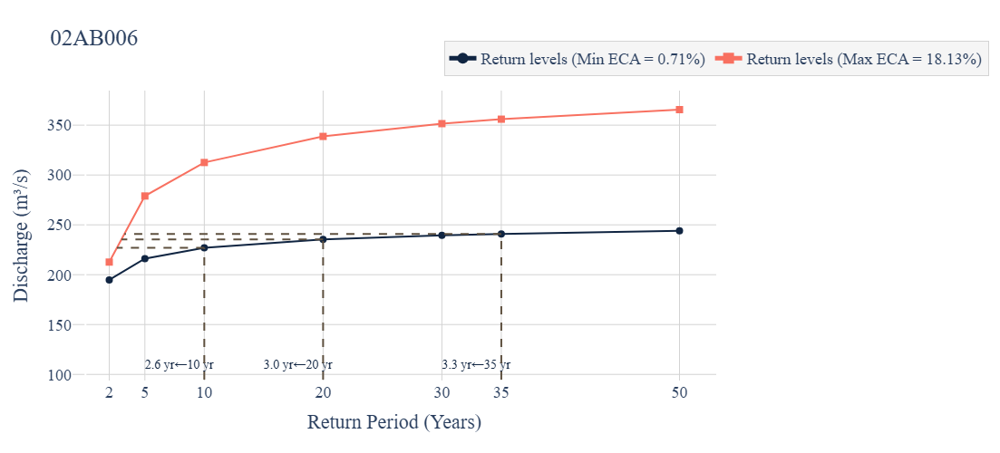

In [17]:
plot_quantification_graph(quant_df, station, return_periods = rp, log_y=False, highlight_rps=[10, 20, 35])

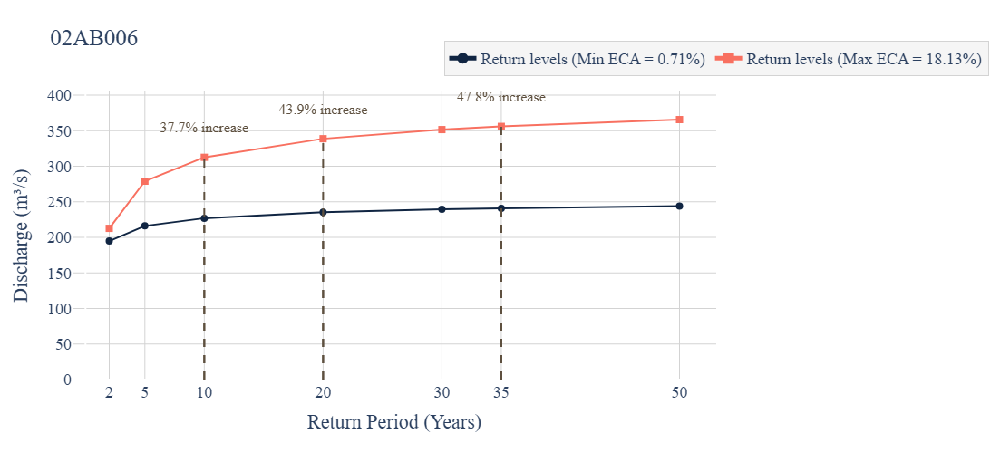

In [30]:
plot_quantification_v2_increased_percentage(quant_df, station, return_periods = rp, log_y=False, highlight_rps=[10, 20, 35])

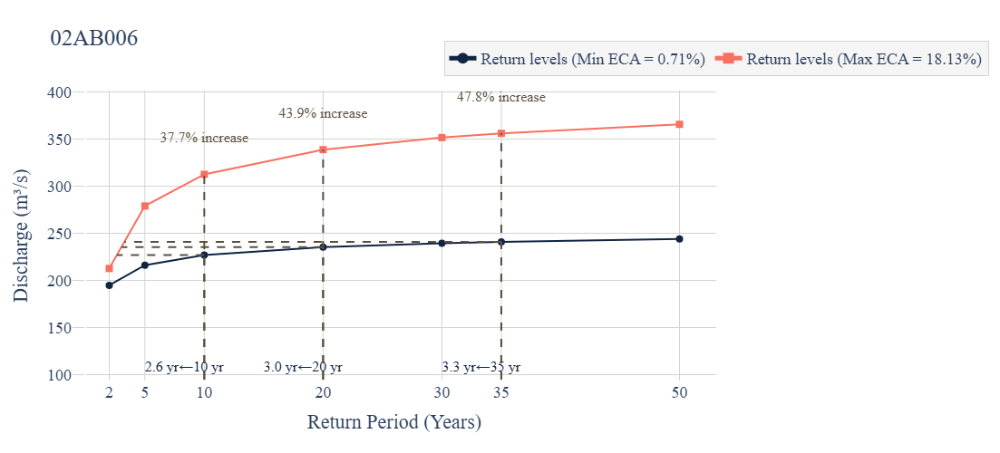

In [13]:
plot_quantification_graph_v3(quant_df, station, return_periods = rp, highlight_rps=[10, 20, 35])

In [35]:
rp = [2, 5, 10, 20, 30, 35, 50]
for station in station_list:
    
    quant_df = get_dataframe(station, quant_dir)
    
    plot_quantification_graph(quant_df, station, return_periods = rp, log_y=False, highlight_rps=[10, 20, 35], 
                          save = True, save_path = quant_out_dir, save_name = f"Quantification_results_{station}")

Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\Quantification_results_02AD010.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\Quantification_results_04JD005.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\Quantification_results_05QD016.svg


In [36]:
for station in station_list:
    
    quant_df = get_dataframe(station, quant_dir)
    
    plot_quantification_v2_increased_percentage(quant_df, station, return_periods = rp, log_y=False, highlight_rps=[10, 20, 35], 
                          save = True, save_path = quant_out_dir, save_name = f"V2_Quantification_results_{station}")

Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V2_Quantification_results_02AD010.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V2_Quantification_results_04JD005.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V2_Quantification_results_05QD016.svg


In [37]:
for station in station_list:
    
    quant_df = get_dataframe(station, quant_dir)
    
    plot_quantification_graph_v3(quant_df, station, return_periods = rp, log_y=False, highlight_rps=[10, 20, 35], 
                          save = True, save_path = quant_out_dir, save_name = f"V3_Quantification_results_{station}")

Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V3_Quantification_results_02AD010.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V3_Quantification_results_04JD005.svg
Plot saved to: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Quantification_figure\V3_Quantification_results_05QD016.svg


Now, for mapping I need the average increased or decreased percentage to be clculated

In [17]:
quantif = compute_average_risk_per_station(station_list, quant_dir, return_periods_to_include = rp)
quantif

,Station_ID,Average_Risk_Increase_Percentage
0,02AB006,37.761365
1,02AC002,18.996442
2,02AD010,141.664669
3,02CC005,3.183073
4,02CE002,11.186149
5,02JC008,30.144800
6,04JD005,80.076214
7,04LM001,-25.066304
8,04MF001,6.715294
9,05QD016,404.158930


In [27]:
quantif = compute_average_hazard_per_ECA(station_list, quant_dir, return_periods_to_include = rp)
quantif

,Station_ID,Average_magnitude_Increase_Per_1_eca
0,02AB006,2.168204
1,02AC002,1.056637
2,02AD010,24.001904
3,02CC005,0.514252
4,02CE002,1.651095
5,02JC008,2.333197
6,04JD005,5.062031
7,04LM001,-3.176459
8,04MF001,1.705060
9,05QD016,28.977742


# Publication

## Counter Factual Boxplots

In [4]:
# file paths for attribution when counter factual scenarioes with fixed eca and changing colimate covs were in the play
counter_max_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Counter_Factual\Return_Levels_Max_ECA"
# return periods with variables covs both in eca and climate covs (like real scenario)
counter_min_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Counter_Factual\Return_Levels_Min_ECA"
real_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Return_Levels_Vriable_Climatic_ECA"

In [5]:
save_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual"
save_dir2 = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot"

In [6]:
extract_station_ids(counter_max_dir) == extract_station_ids(counter_min_dir)
station_list = extract_station_ids(counter_max_dir)

station_list

['02AB006',
 '02AC002',
 '02AD010',
 '02BA003',
 '02CC005',
 '02CE002',
 '02DC004',
 '02JC008',
 '04GA002',
 '04JC002',
 '04JD005',
 '04LM001',
 '04MF001',
 '05QC001',
 '05QD016',
 '05QE008',
 '05QE009']

In [7]:
station_list = [
    "02AB006",
    "02AC002",
    "02AD010",
    "02CC005",
    "02CE002",
    "02JC008",
    "04JD005",
    "04LM001",
    "04MF001",
    "05QD016",
    "05QE009"
]

In [19]:
get_dataframe(station, counter_max_dir).head(1)

NameError: name 'station' is not defined

In [48]:
get_dataframe(station, counter_min_dir).head(1)

,Year,ECA,Return_Level_1.5Yrs,Return_Level_2Yrs,Return_Level_5Yrs,Return_Level_7Yrs,Return_Level_10Yrs,Return_Level_15Yrs,Return_Level_20Yrs,Return_Level_30Yrs,Return_Level_35Yrs,Return_Level_50Yrs,Return_Level_100Yrs
0,1985,0.709215,143.676135,164.224343,204.756215,215.415937,225.281755,235.082899,241.281082,249.115909,251.848267,257.706617,267.475231


Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\05QD016_counterfactural_boxplot.svg


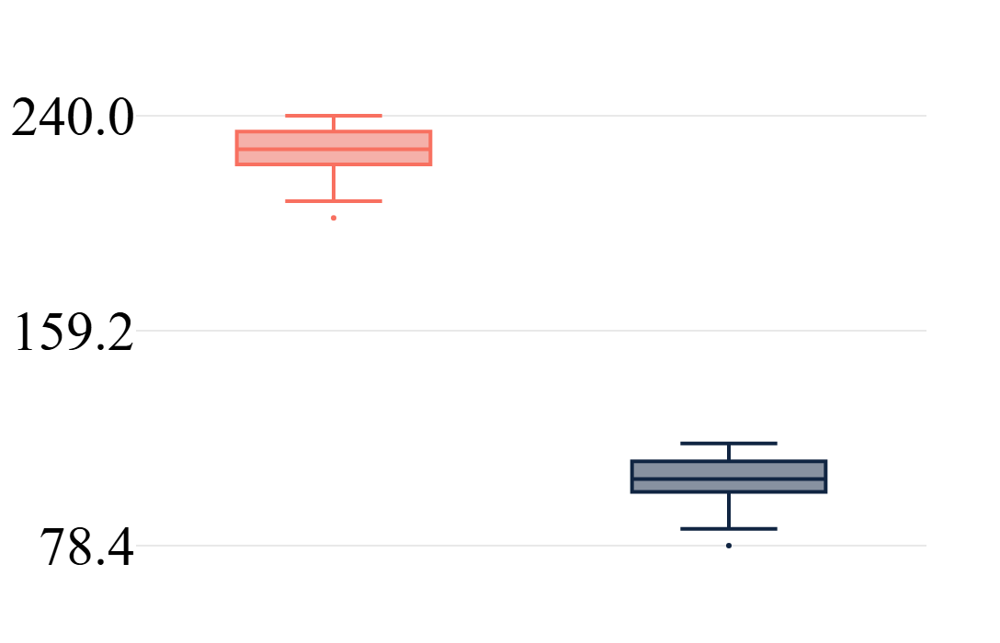

In [20]:
station = "05QD016"

q_return_period = 20
width = 500
height = 700
font_size = 60

save = True
save_path = save_dir
save_format = "svg" 
save_name = f"{station}_counterfactural_boxplot"

max_df = get_dataframe(station, counter_max_dir)
min_df = get_dataframe(station, counter_min_dir)
column_name = f"Return_Level_{q_return_period}Yrs"

eca_max_rl = max_df[['Year', column_name]].copy()
eca_max_rl.rename(columns={column_name: f"Max_{q_return_period}yr"}, inplace = True)
eca_min_rl = min_df[['Year', column_name]].copy()
eca_min_rl.rename(columns={column_name: f"Min_{q_return_period}yr"}, inplace = True)

# merged_df = pd.merge(eca_max_rl, eca_min_rl, on = "Year", how = "inner")
merged_df = pd.merge(eca_max_rl, eca_min_rl, on = "Year", how = "outer")

# here I calculate min and max and mid point for graphing purposes
if merged_df['Min_20yr'].min() < merged_df['Max_20yr'].max():
    y_min = merged_df['Min_20yr'].min()
    y_max = merged_df['Max_20yr'].max()
    y_mid = (y_min + y_max) / 2
else:
    y_min = merged_df[['Min_20yr', 'Max_20yr']].min().min()
    y_max = merged_df[['Min_20yr', 'Max_20yr']].max().max()
    y_mid = (y_min + y_max) / 2

# now with this df I want to make the boxplots
# trace_max = go.Box(y=merged_df['Max_20yr'], name=f'{q_return_period}-Year Flood (Max ECA)', boxpoints='outliers', marker_color= "#f87060")
# trace_min = go.Box(y=merged_df['Min_20yr'], name=f'{q_return_period}-Year Flood (min ECA)', boxpoints='outliers', marker_color='#102542')


trace_min = go.Box(
    y=merged_df['Min_20yr'],
    name=f'{q_return_period}-Year Flood (Min ECA)',
    boxpoints='outliers',
    line=dict(width = 4),
    marker_color="#102542",  # For outliers
    line_color="#102542",    # Outline
    fillcolor="#8791a0"   # Fully opaque fill
)

trace_max = go.Box(
    y=merged_df['Max_20yr'],
    name=f'{q_return_period}-Year Flood (Max ECA)',
    boxpoints='outliers',
    line=dict(width = 4),
    marker_color="#f87060",  # For outliers
    line_color="#f87060",    # Outline
    fillcolor="#f5b0a9"  # Fully opaque fill
)


fig = go.Figure(data=[trace_max, trace_min])

fig.update_layout(
        title=None,
        # yaxis_title="Discharge (m³/s)",
        font=dict(family="Times New Roman", size=font_size, color = "black"),
        width=width,
        height=height,
        paper_bgcolor='rgba(0,0,0,0)',  # Transparent 
        plot_bgcolor='rgba(0,0,0,0)', # Transparent
    
        xaxis=dict(
            showgrid=False,
            showticklabels=False,
            tickvals=[0.25, 0.75],
            ticktext =[station],
            tickfont=dict(size=font_size)
        ),
        yaxis=dict(
            showgrid=True,
            gridcolor='lightgrey',
            tickvals=[y_min, y_mid, y_max],
            ticktext=[f"{y_min:.1f}", f"{y_mid:.1f}", f"{y_max:.1f}"],
            tickfont=dict(size=font_size),
        ),
        showlegend = False,
    )

if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Boxplot saved successfully at: {full_save_path}")

fig.show()

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02AB006_counterfactural_boxplot.svg


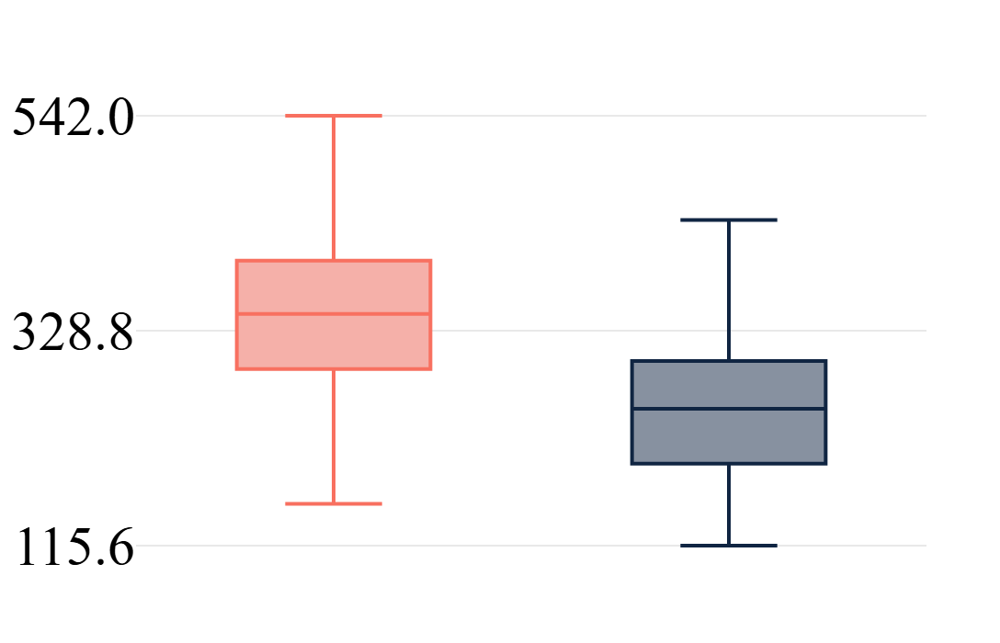

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02AC002_counterfactural_boxplot.svg


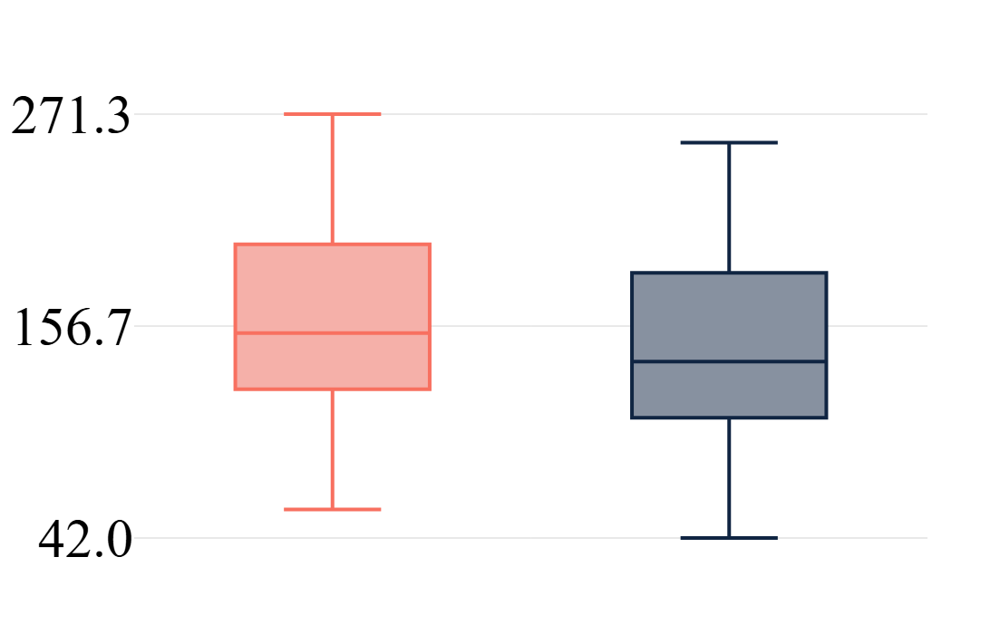

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02AD010_counterfactural_boxplot.svg


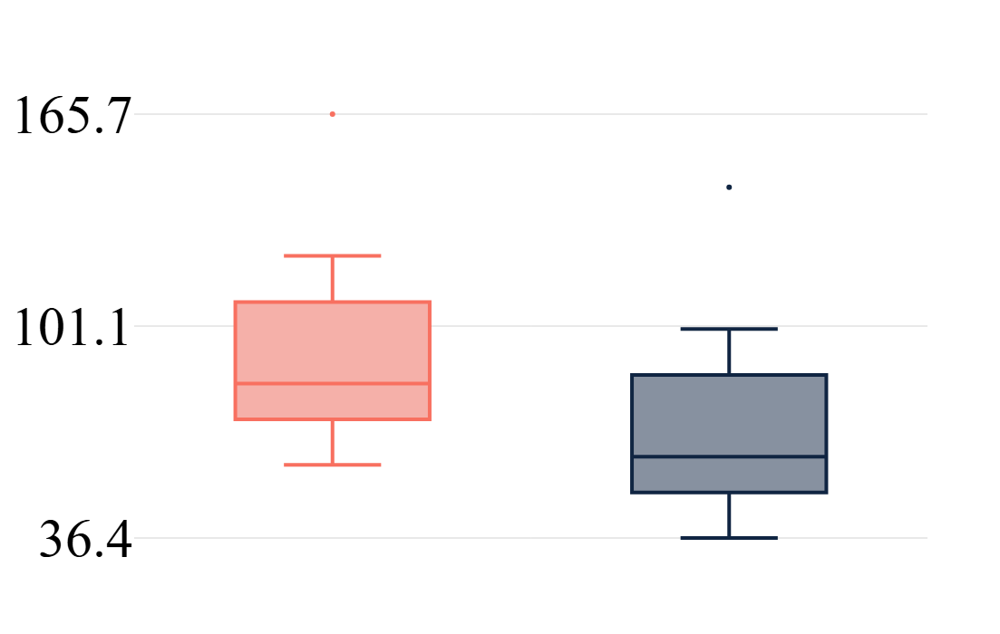

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02BA003_counterfactural_boxplot.svg


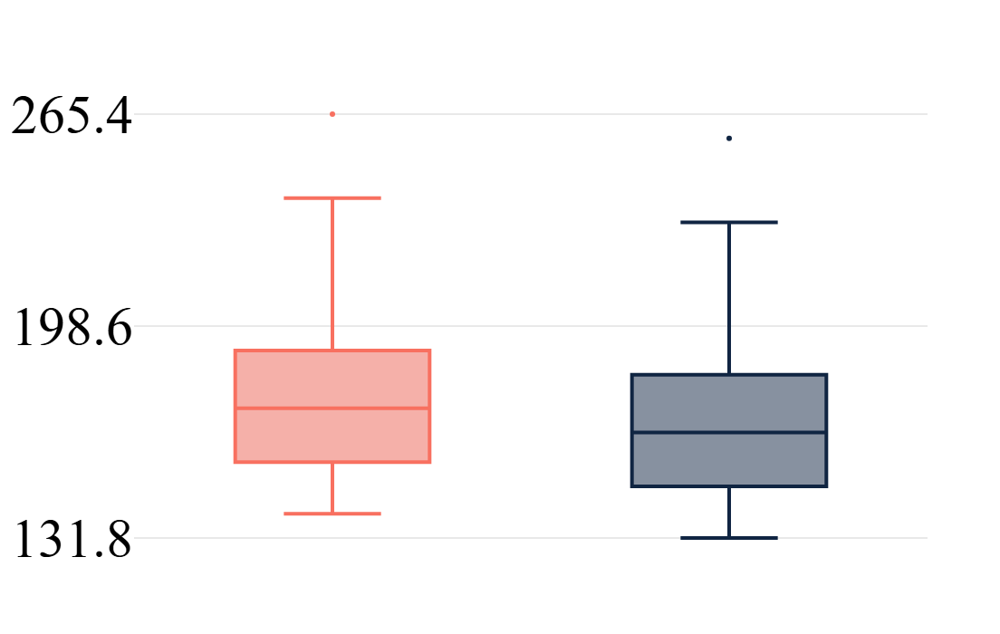

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02CC005_counterfactural_boxplot.svg


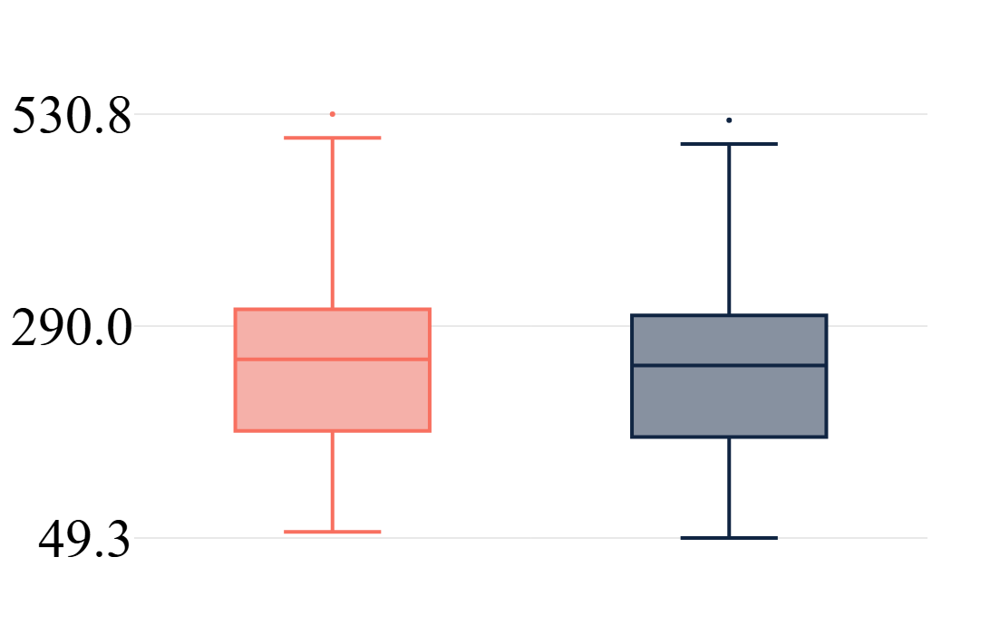

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02CE002_counterfactural_boxplot.svg


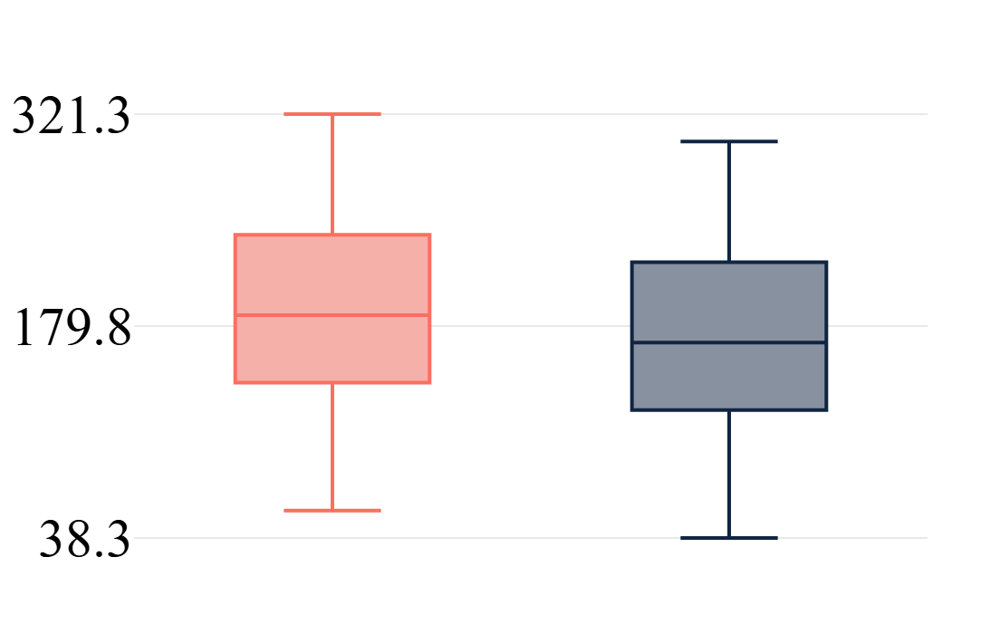

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02DC004_counterfactural_boxplot.svg


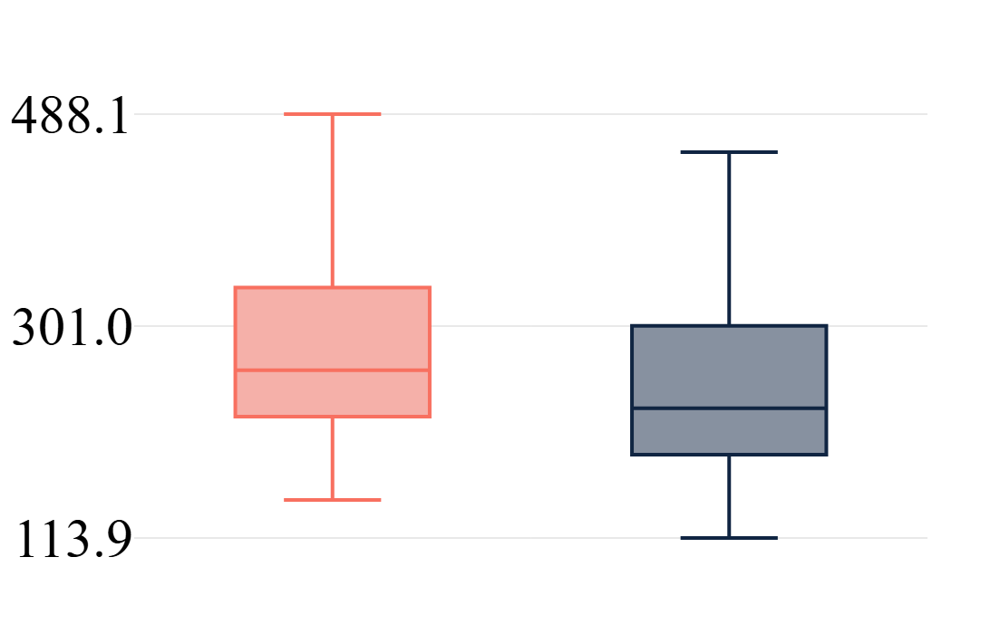

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\02JC008_counterfactural_boxplot.svg


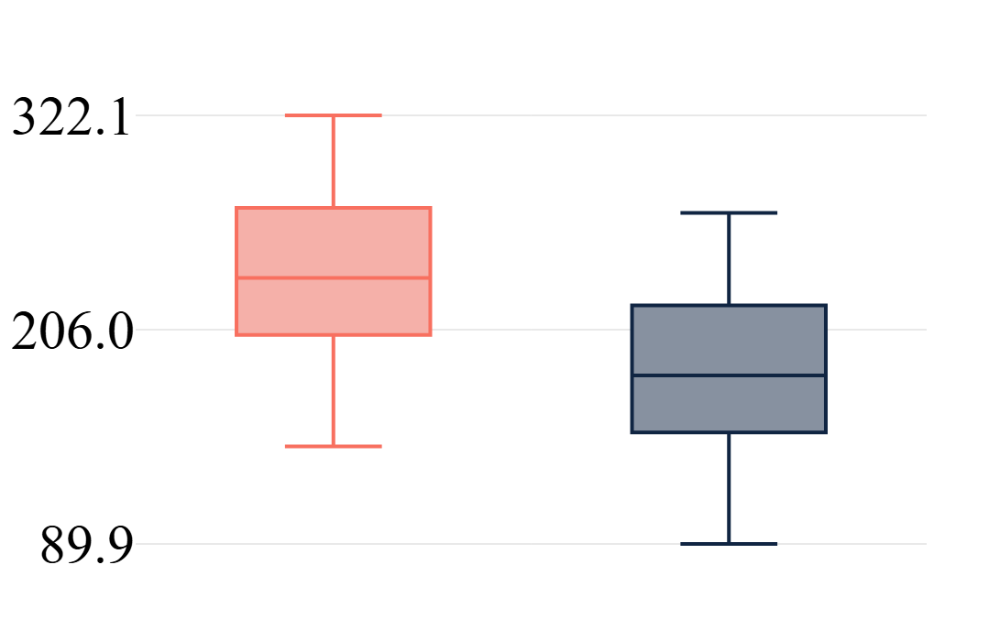

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\04GA002_counterfactural_boxplot.svg


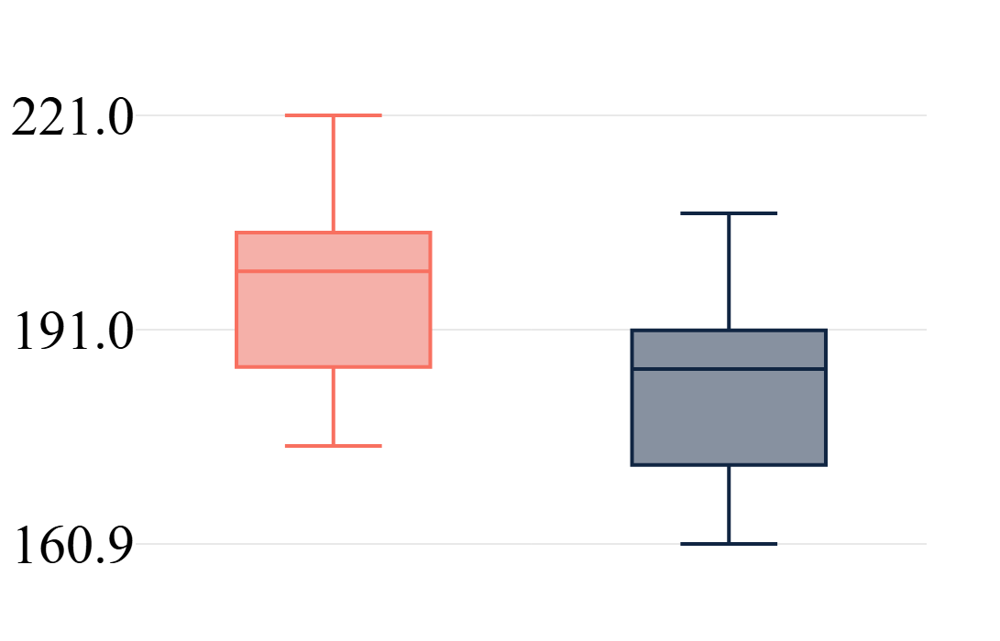

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\04JC002_counterfactural_boxplot.svg


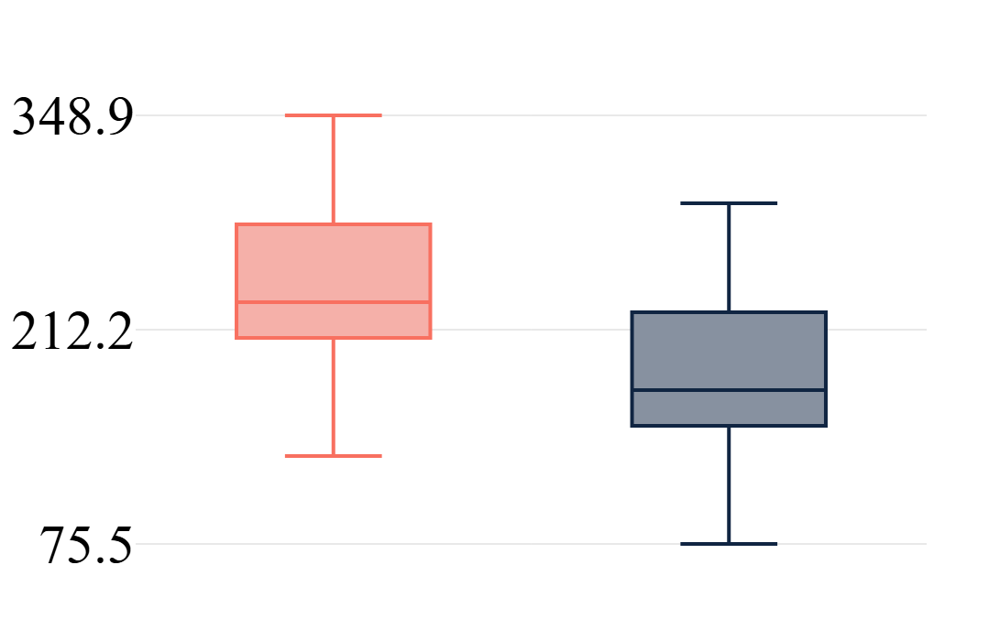

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\04JD005_counterfactural_boxplot.svg


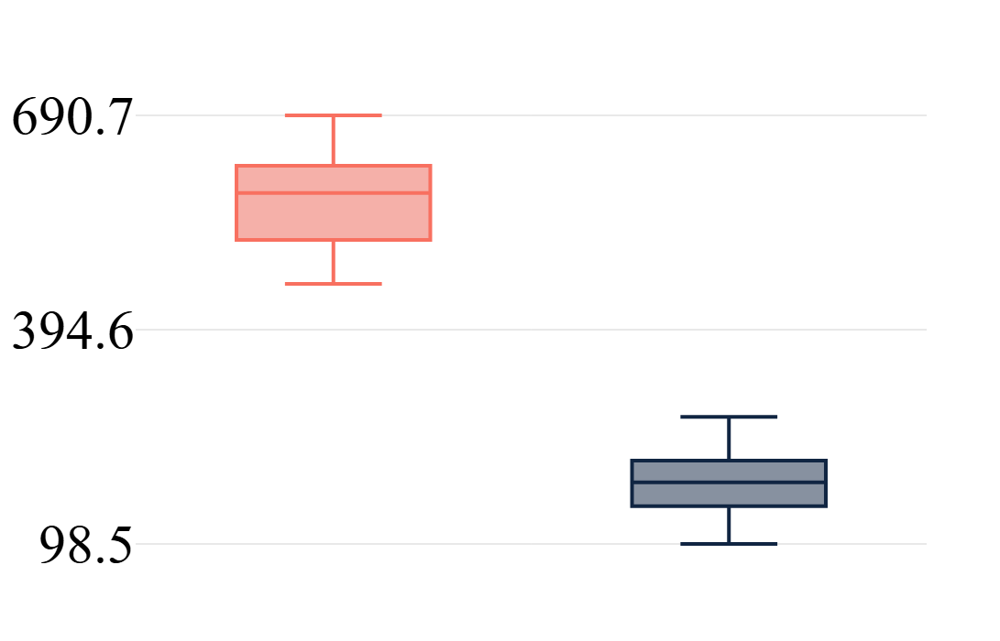

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\04LM001_counterfactural_boxplot.svg


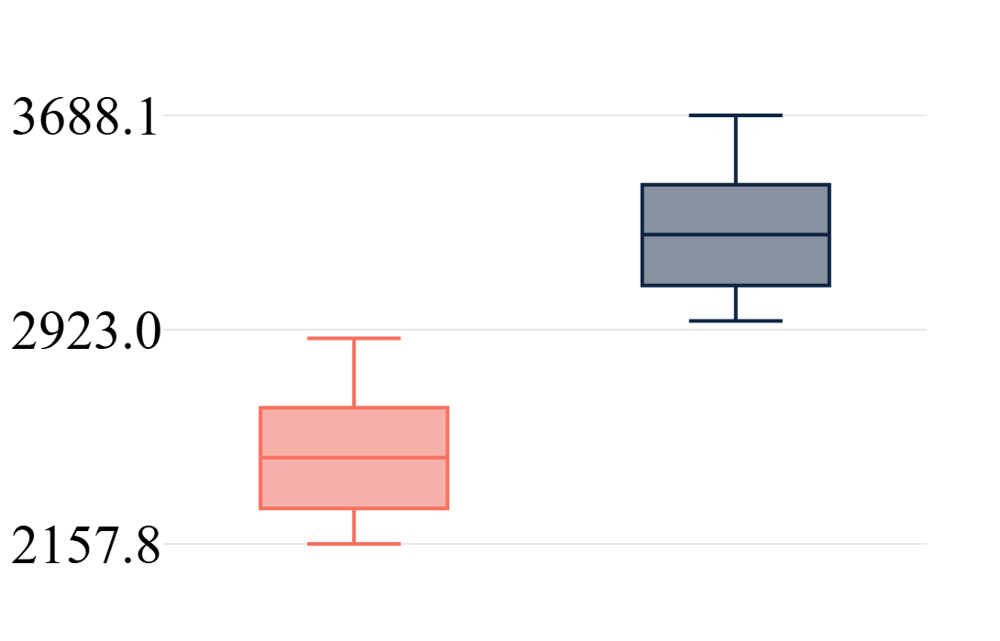

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\04MF001_counterfactural_boxplot.svg


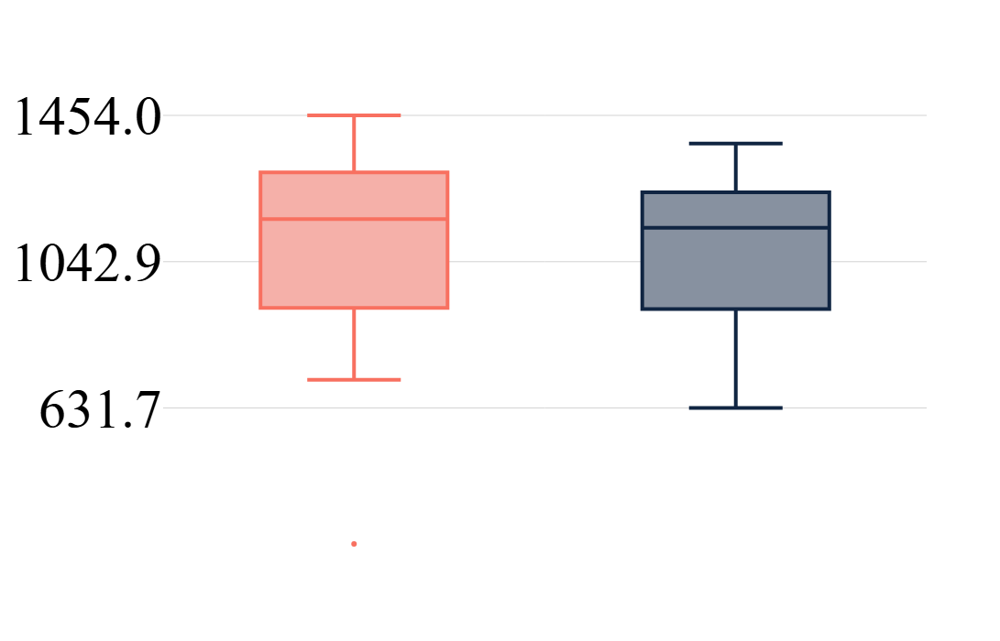

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\05QC001_counterfactural_boxplot.svg


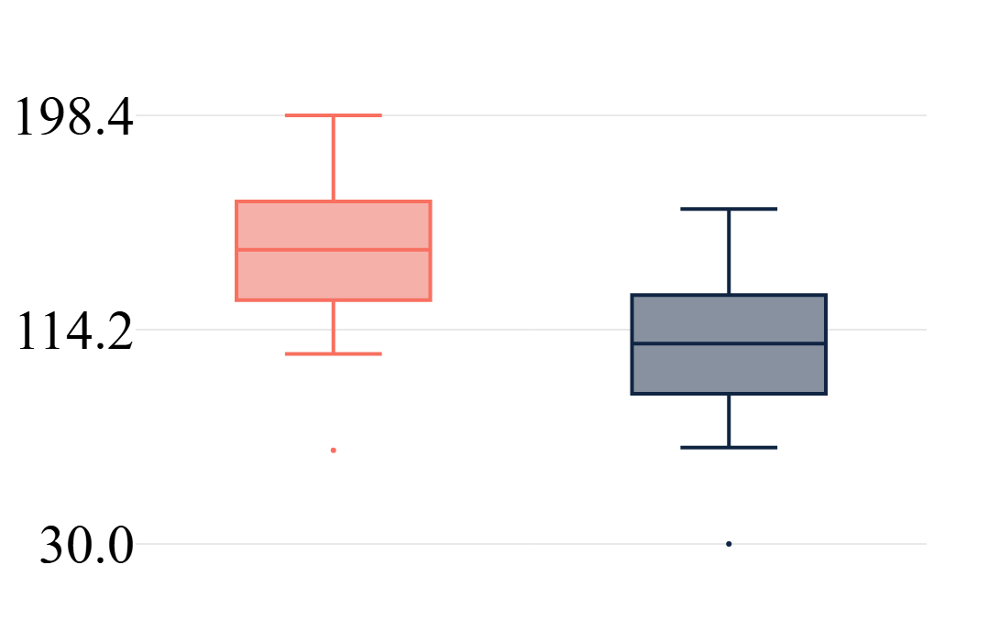

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\05QD016_counterfactural_boxplot.svg


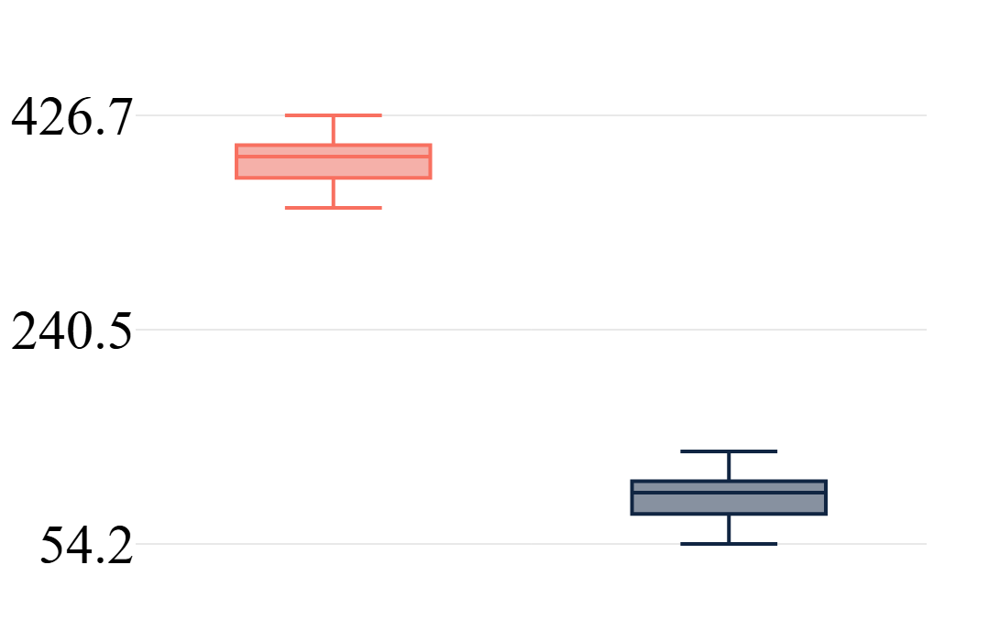

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\05QE008_counterfactural_boxplot.svg


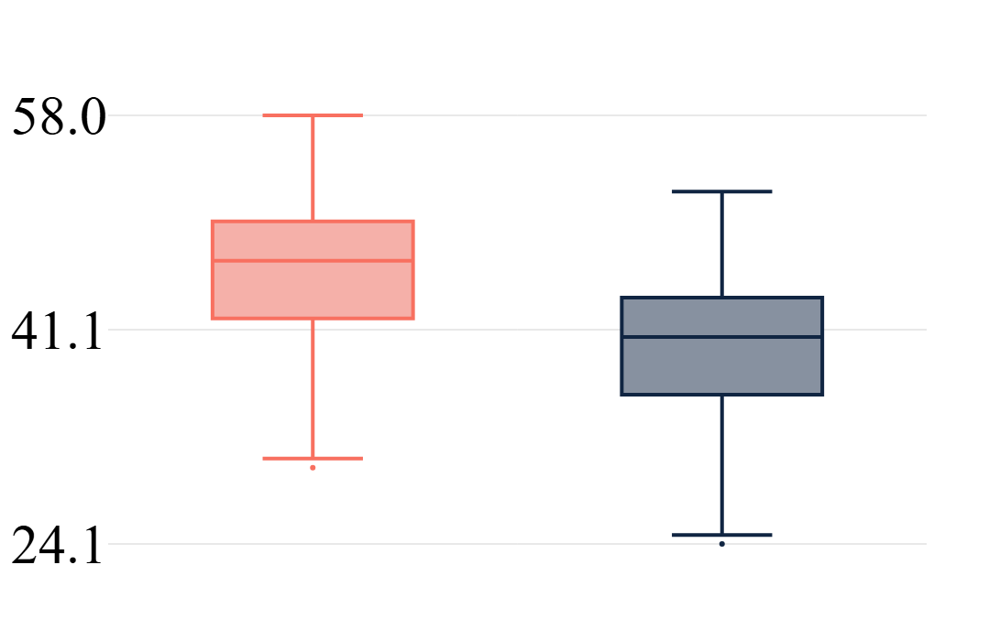

Boxplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_attribution_counterfactual\05QE009_counterfactural_boxplot.svg


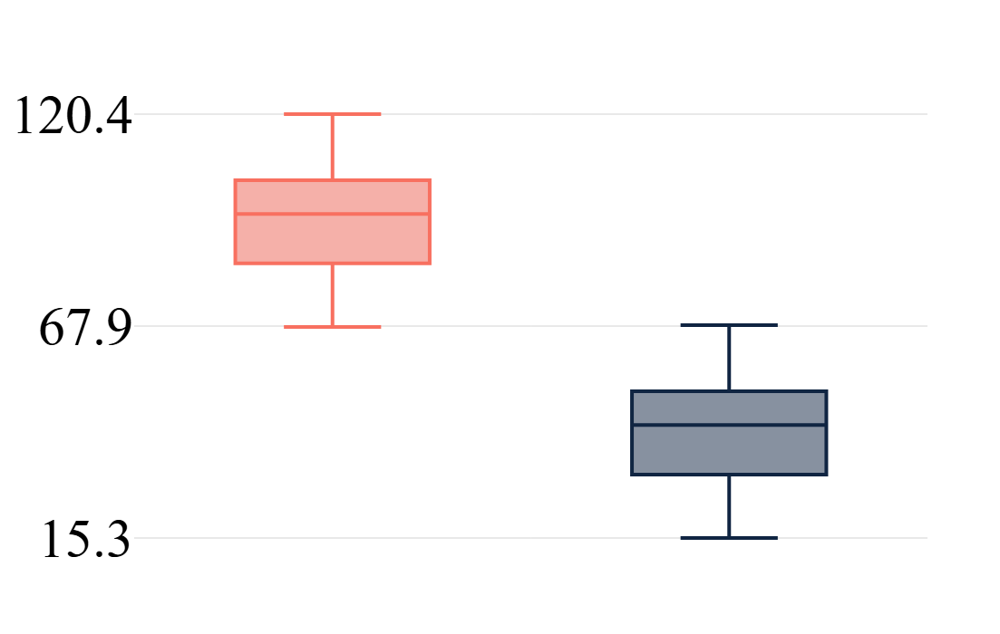

In [139]:
for station in station_list:
# station = station_list[0]

    q_return_period = 20
    width = 500
    height = 700
    font_size = 60

    save = True
    save_path = save_dir
    save_format = "svg" 
    save_name = f"{station}_counterfactural_boxplot"

    max_df = get_dataframe(station, counter_max_dir)
    min_df = get_dataframe(station, counter_min_dir)
    column_name = f"Return_Level_{q_return_period}Yrs"

    eca_max_rl = max_df[['Year', column_name]].copy()
    eca_max_rl.rename(columns={column_name: f"Max_{q_return_period}yr"}, inplace = True)
    eca_min_rl = min_df[['Year', column_name]].copy()
    eca_min_rl.rename(columns={column_name: f"Min_{q_return_period}yr"}, inplace = True)

# merged_df = pd.merge(eca_max_rl, eca_min_rl, on = "Year", how = "inner")
    merged_df = pd.merge(eca_max_rl, eca_min_rl, on = "Year", how = "outer")

# here I calculate min and max and mid point for graphing purposes
    if merged_df['Min_20yr'].min() < merged_df['Max_20yr'].max():
        y_min = merged_df['Min_20yr'].min()
        y_max = merged_df['Max_20yr'].max()
        y_mid = (y_min + y_max) / 2
    else:
        y_min = merged_df[['Min_20yr', 'Max_20yr']].min().min()
        y_max = merged_df[['Min_20yr', 'Max_20yr']].max().max()
        y_mid = (y_min + y_max) / 2

# now with this df I want to make the boxplots
# trace_max = go.Box(y=merged_df['Max_20yr'], name=f'{q_return_period}-Year Flood (Max ECA)', boxpoints='outliers', marker_color= "#f87060")
# trace_min = go.Box(y=merged_df['Min_20yr'], name=f'{q_return_period}-Year Flood (min ECA)', boxpoints='outliers', marker_color='#102542')


    trace_min = go.Box(
        y=merged_df['Min_20yr'],
        name=f'{q_return_period}-Year Flood (Min ECA)',
        boxpoints='outliers',
        line=dict(width = 4),
        marker_color="#102542",  # For outliers
        line_color="#102542",    # Outline
        fillcolor="#8791a0"   # Fully opaque fill
    )

    trace_max = go.Box(
        y=merged_df['Max_20yr'],
        name=f'{q_return_period}-Year Flood (Max ECA)',
        boxpoints='outliers',
        line=dict(width = 4),
        marker_color="#f87060",  # For outliers
        line_color="#f87060",    # Outline
        fillcolor="#f5b0a9"  # Fully opaque fill
    )
    
    
    fig = go.Figure(data=[trace_max, trace_min])
    
    fig.update_layout(
            title=None,
            # yaxis_title="Discharge (m³/s)",
            font=dict(family="Times New Roman", size=font_size, color = "black"),
            width=width,
            height=height,
            paper_bgcolor='rgba(0,0,0,0)',  # Transparent 
            plot_bgcolor='rgba(0,0,0,0)', # Transparent
        
            xaxis=dict(
                showgrid=False,
                showticklabels=False,
                tickvals=[0.25, 0.75],
                ticktext =[station],
                tickfont=dict(size=font_size)
            ),
            yaxis=dict(
                showgrid=True,
                gridcolor='lightgrey',
                tickvals=[y_min, y_mid, y_max],
                ticktext=[f"{y_min:.1f}", f"{y_mid:.1f}", f"{y_max:.1f}"],
                tickfont=dict(size=font_size),
            ),
            showlegend = False,
        )
    
    if save:
            if save_path is None or save_name is None:
                raise ValueError("To save the plot, you must specify both save_path and save_name.")
            full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
            fig.write_image(full_save_path)
            print(f"Boxplot saved successfully at: {full_save_path}")
    
    fig.show()

In [57]:
merged_df.columns

Index(['Year', 'Max_20yr', 'Min_20yr'], dtype='object')

In [58]:
trace_max = go.Box(y=merged_df['Max_20yr'], name='Max 20yr', boxpoints='outliers', marker_color='royalblue')

In [54]:
eca_max_rl

,Year,Max_20yr
0,1985,344.649441
1,1986,353.985028
2,1987,156.980301
3,1988,370.233197
4,1989,234.135049
5,1990,280.559666
6,1991,330.030291
7,1992,290.789538
8,1993,384.480661
9,1994,402.145486


In [ ]:
def plot_scenario_boxplots(return_levels_dict,
                            scenarios_to_plot='all',
                            width=600,
                            height=600,
                            save=False,
                            save_path=None,
                            save_name=None,
                            save_format="svg"):
    """
    Creates a standalone boxplot figure summarizing return levels for each scenario.
    
    Parameters:
    - return_levels_dict (dict): Output from get_return_levels_across_scenarios.
    - scenarios_to_plot (str or list): 'all', or list like ['max', 'min', 'real'].
    - width (int): Width of the plot.
    - height (int): Height of the plot.
    - save (bool): Whether to save the figure.
    - save_path (str): Directory where to save the file if save=True.
    - save_name (str): Filename without extension if save=True.
    - save_format (str): Format to save ('svg', 'pdf', 'eps', 'png', etc.). Default 'svg'.
    
    Returns:
    - fig: Plotly Figure
    """
    
    # Base colors
    base_colors = {
        'max': '#f87060',  # Salmonish
        'min': '#102542',  # Navy
        'real': '#beb7a4'  # Brownish
    }
    
    # Decide scenarios
    if scenarios_to_plot == 'all':
        scenarios = ['max', 'min', 'real']
    else:
        scenarios = [scenarios_to_plot] if isinstance(scenarios_to_plot, str) else scenarios_to_plot

    # Prepare boxplot traces
    box_traces = []
    
    for scenario in scenarios:
        all_values = []
        for key, df in return_levels_dict.items():
            if key.startswith(scenario):
                all_values.extend(df.iloc[:, 1].values)  # second column = Return_Level
        
        trace = go.Box(
            y=all_values,
            name=f"{scenario.title()} ECA",
            marker_color=base_colors[scenario],
            boxmean=True,
            boxpoints='outliers',
            showlegend = False
        )
        
        box_traces.append(trace)
    
    # Create figure
    fig = go.Figure(data=box_traces)
    
    fig.update_layout(
        title=None,
        yaxis_title="Discharge (m³/s)",
        font=dict(family="Times New Roman", size=16),
        width=width,
        height=height,
        plot_bgcolor='white',
        xaxis=dict(showgrid=False),
        yaxis=dict(showgrid=True, gridcolor='lightgrey'),
    )
    
    # Save if requested
    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Boxplot saved successfully at: {full_save_path}")
    
    return fig


Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02AB006_counterfactual_barplot_average.svg


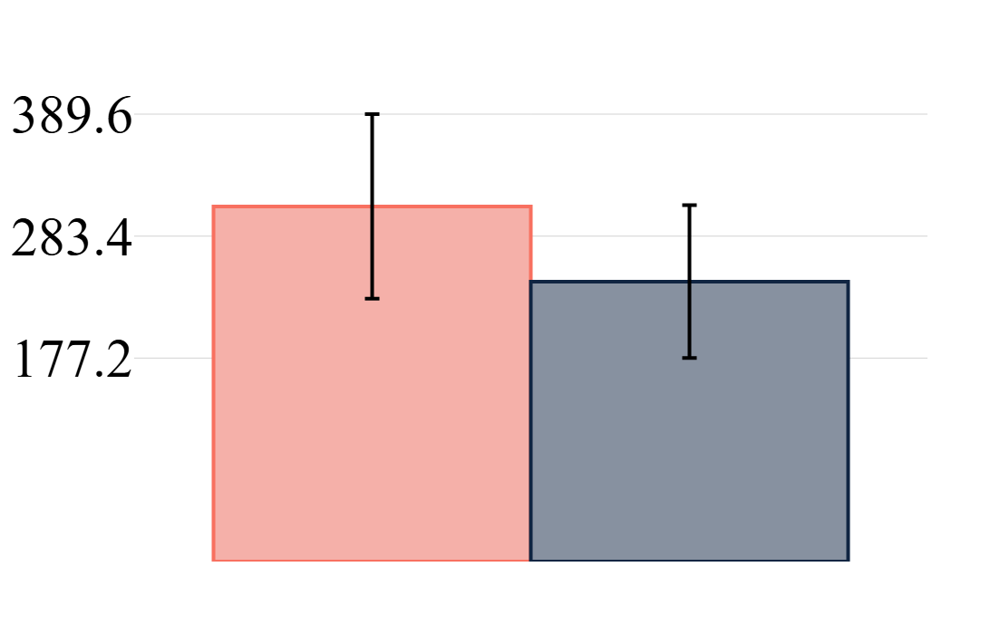

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02AC002_counterfactual_barplot_average.svg


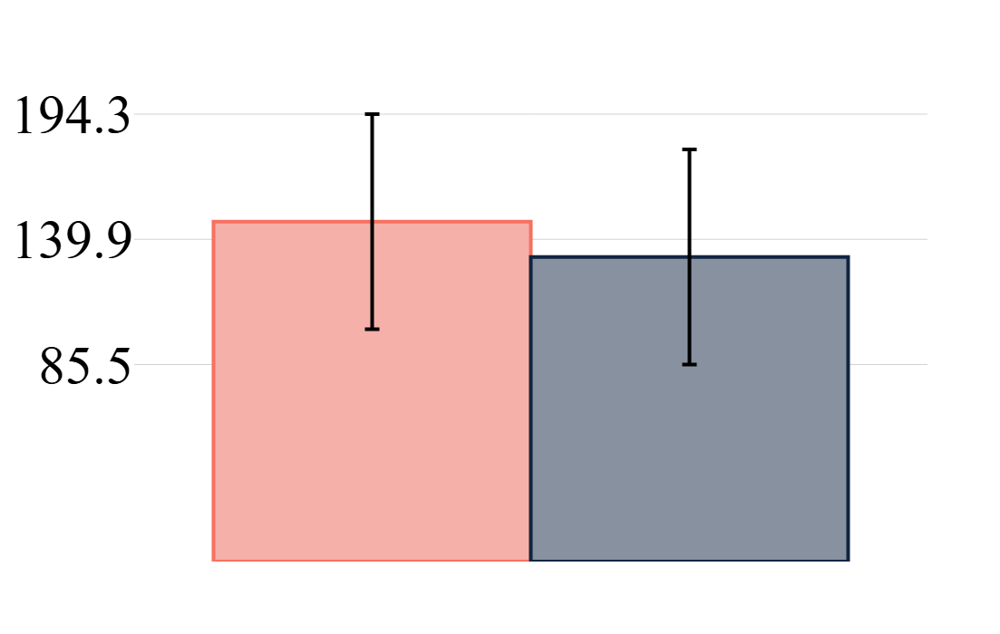

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02AD010_counterfactual_barplot_average.svg


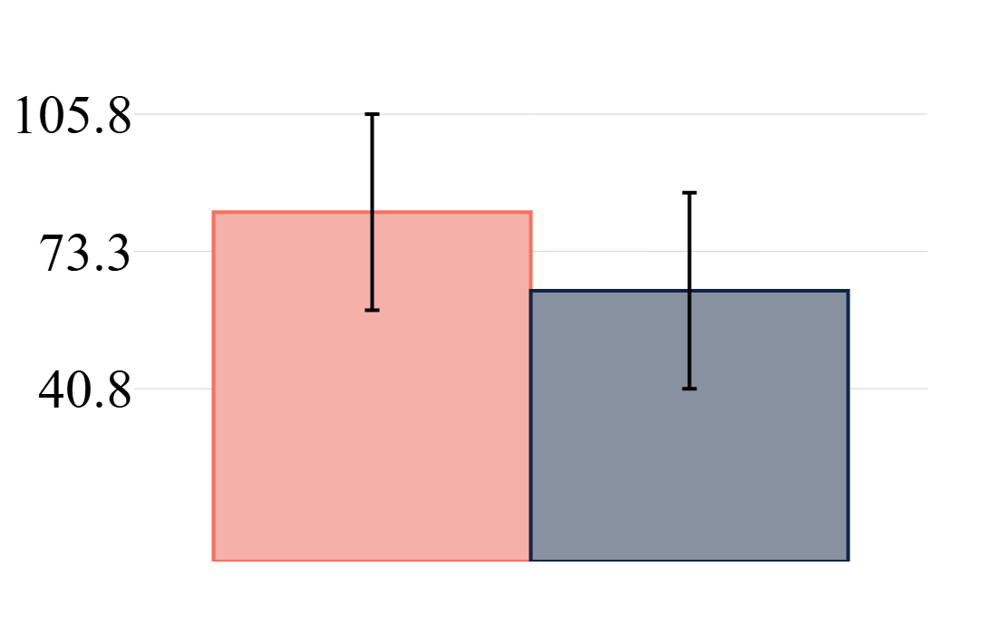

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02BA003_counterfactual_barplot_average.svg


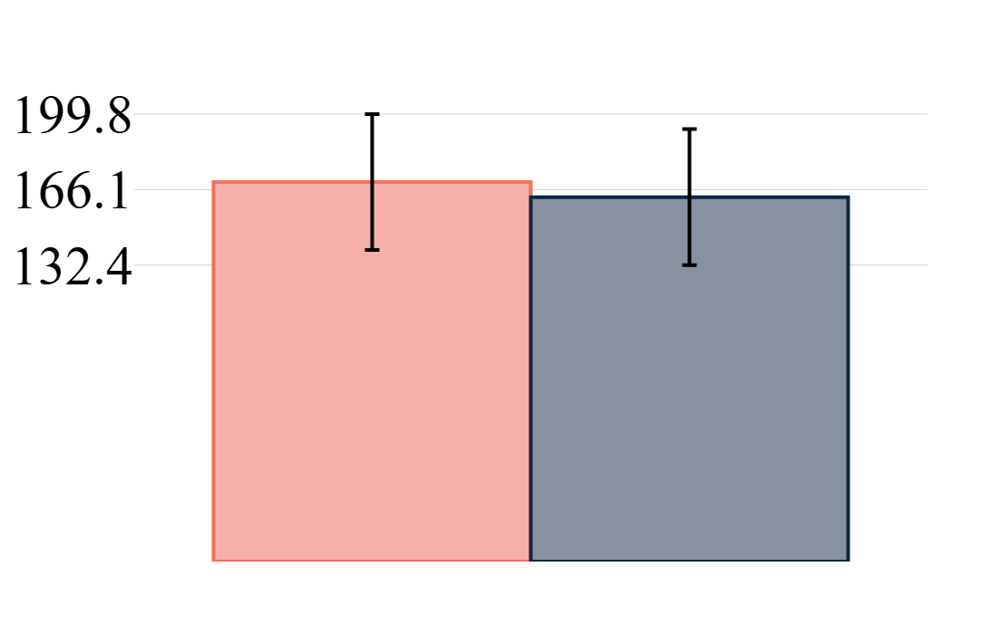

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02CC005_counterfactual_barplot_average.svg


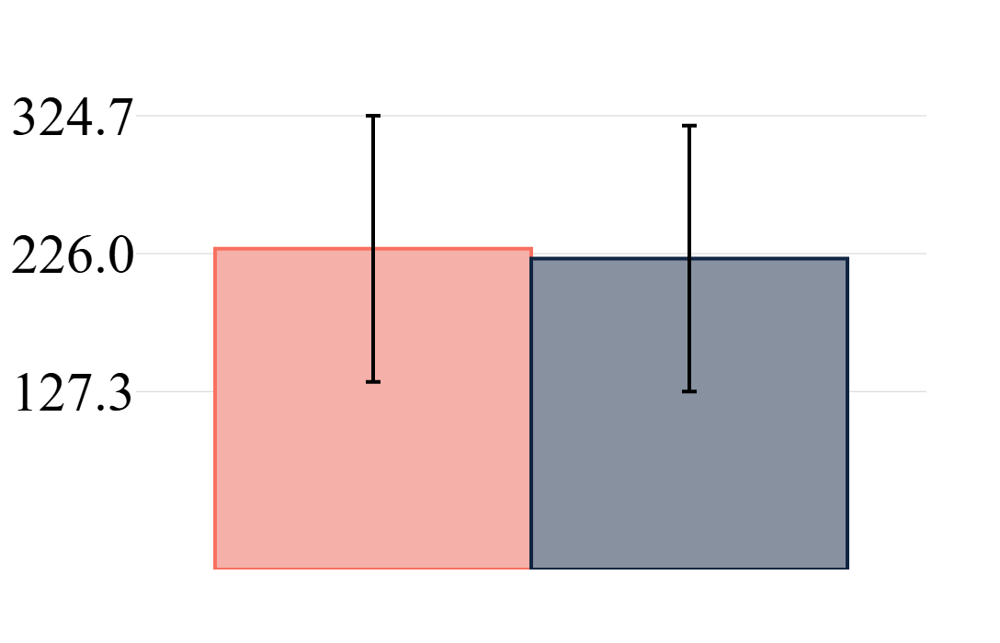

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02CE002_counterfactual_barplot_average.svg


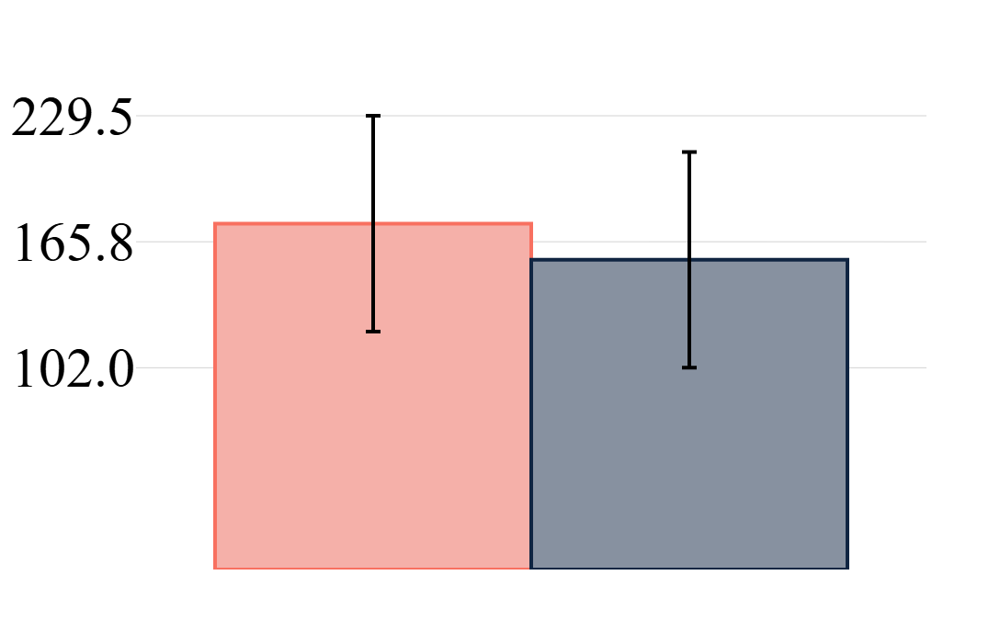

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02DC004_counterfactual_barplot_average.svg


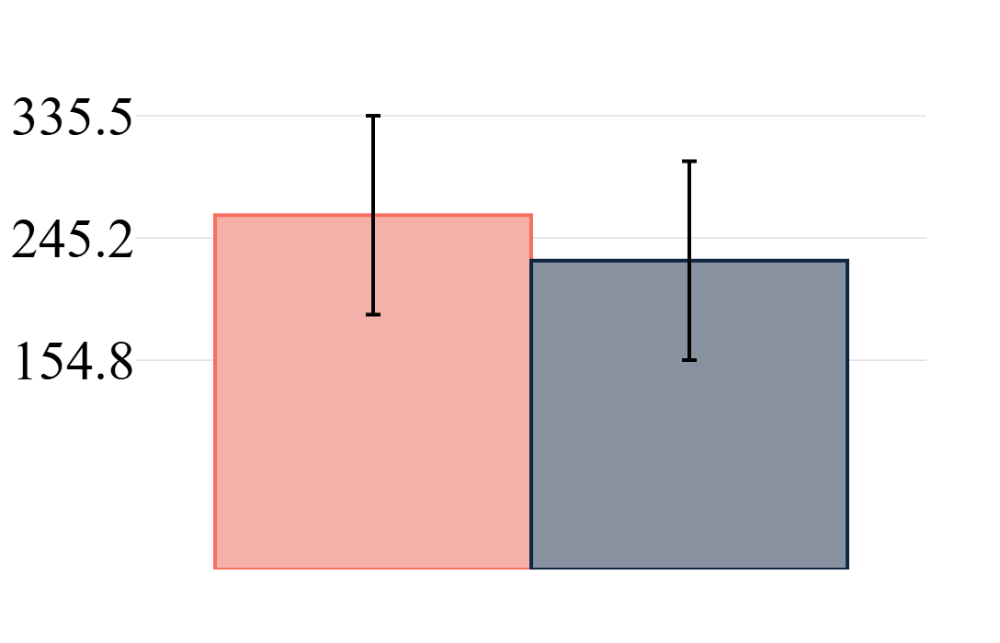

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\02JC008_counterfactual_barplot_average.svg


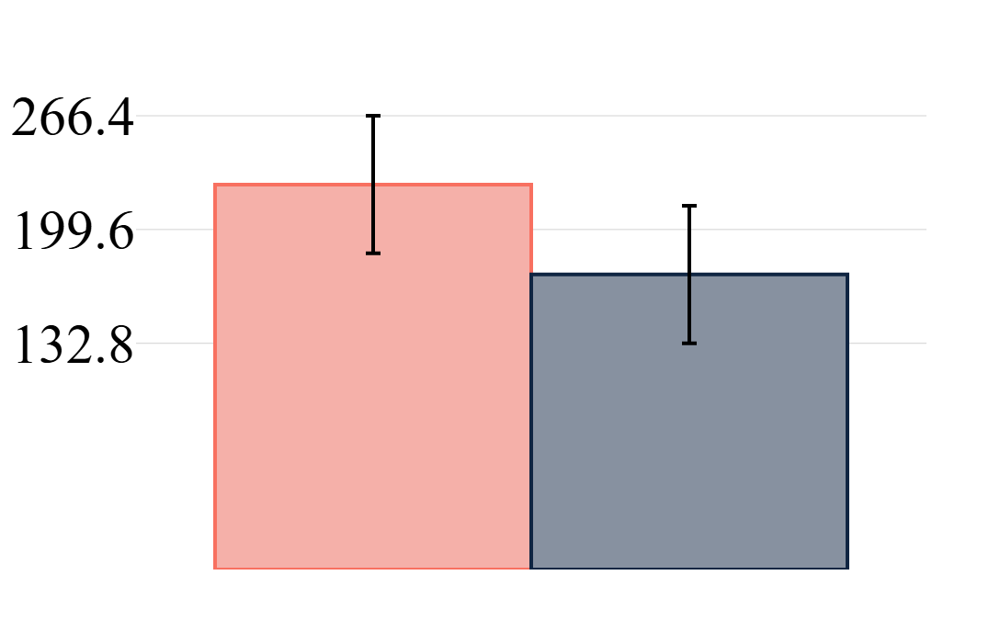

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\04GA002_counterfactual_barplot_average.svg


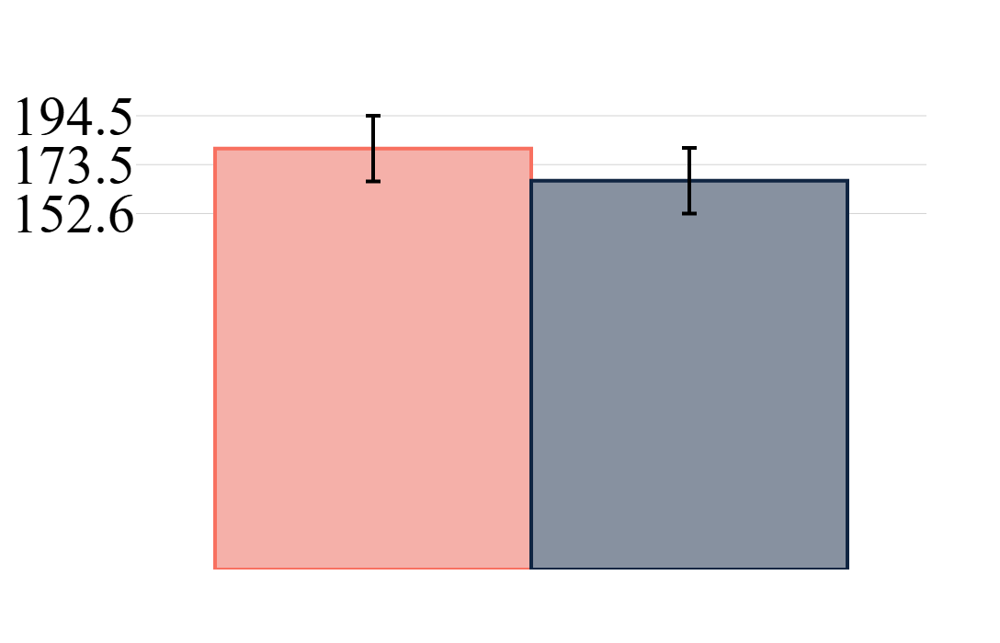

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\04JC002_counterfactual_barplot_average.svg


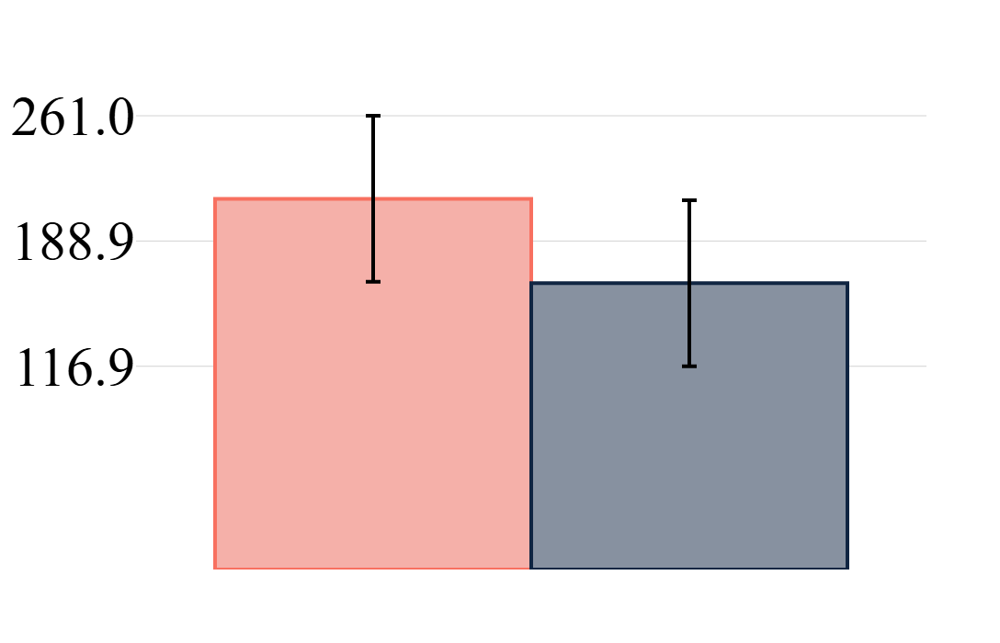

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\04JD005_counterfactual_barplot_average.svg


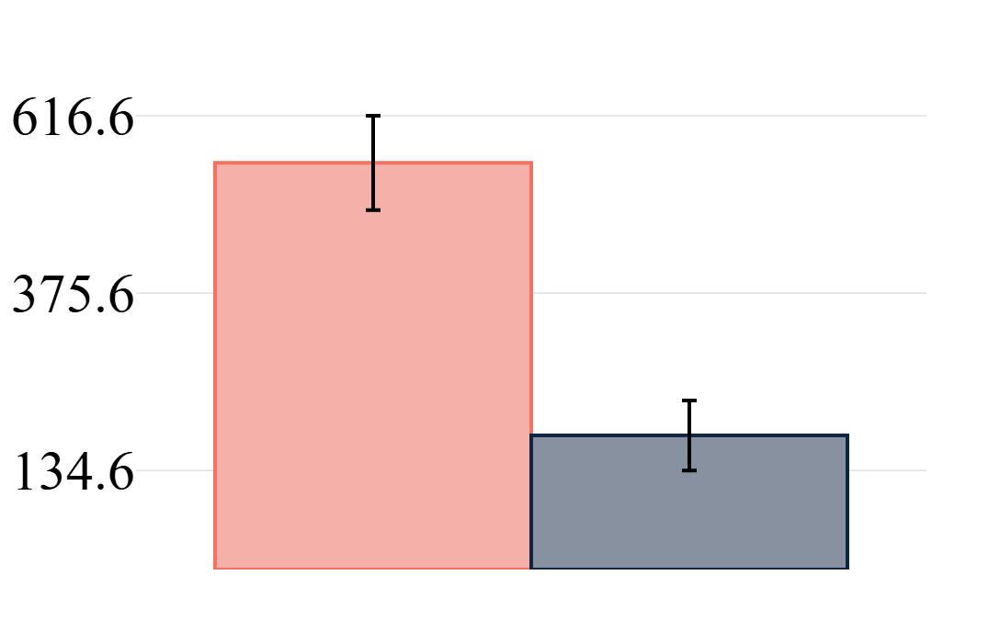

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\04LM001_counterfactual_barplot_average.svg


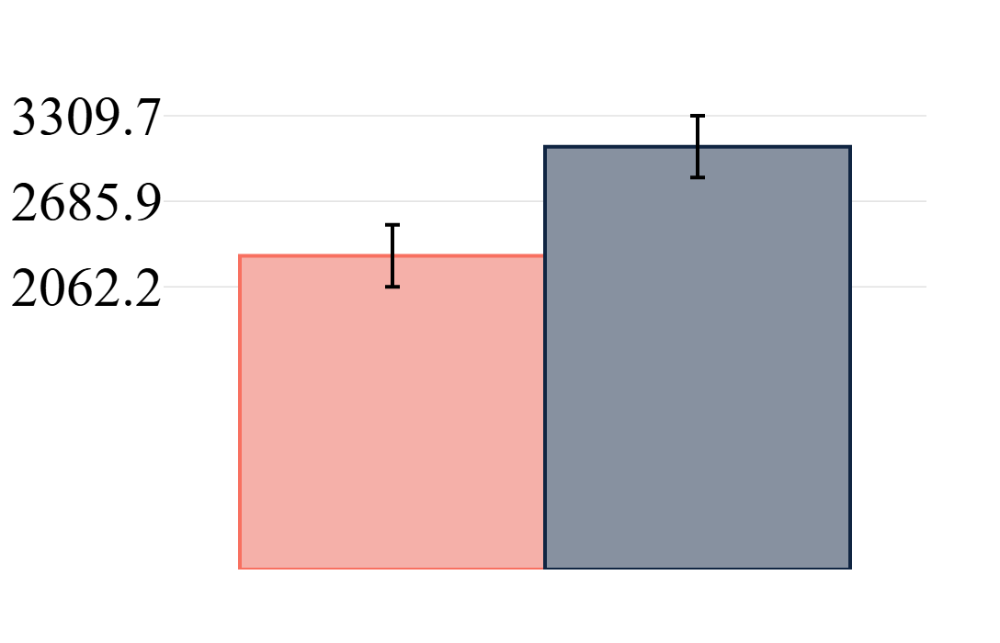

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\04MF001_counterfactual_barplot_average.svg


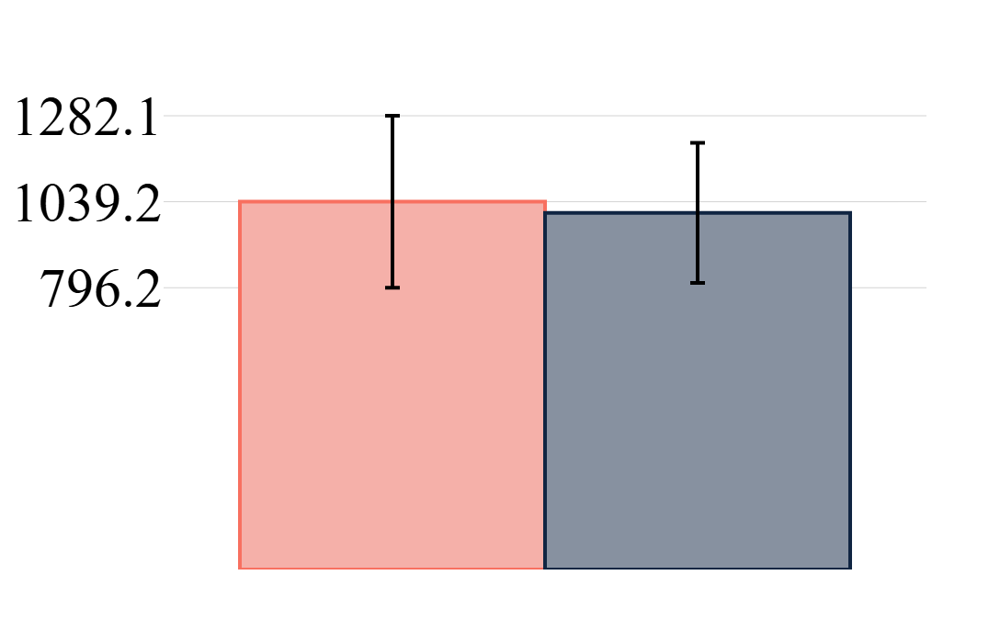

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\05QC001_counterfactual_barplot_average.svg


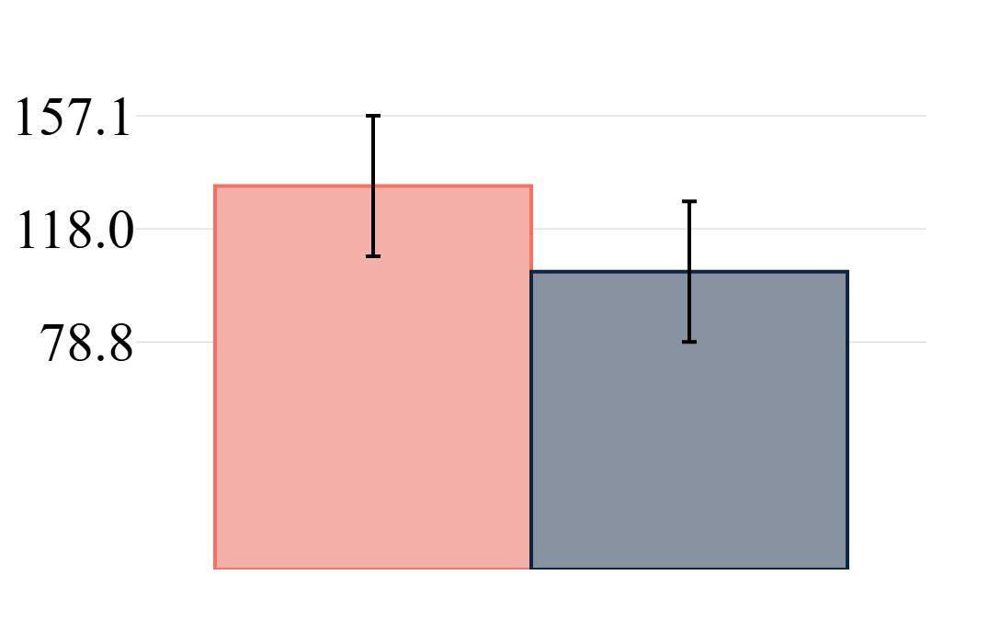

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\05QD016_counterfactual_barplot_average.svg


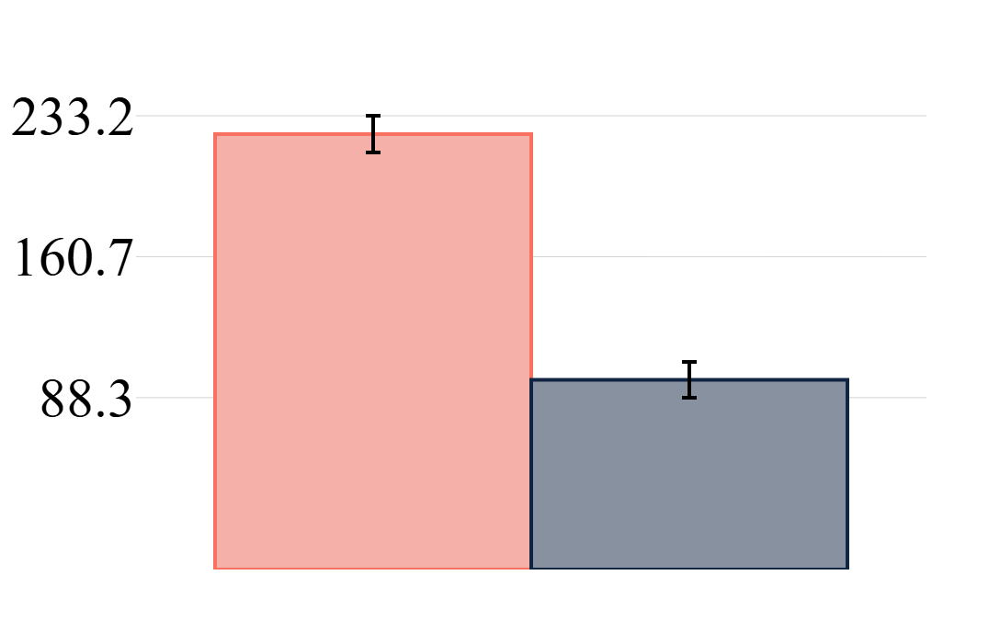

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\05QE008_counterfactual_barplot_average.svg


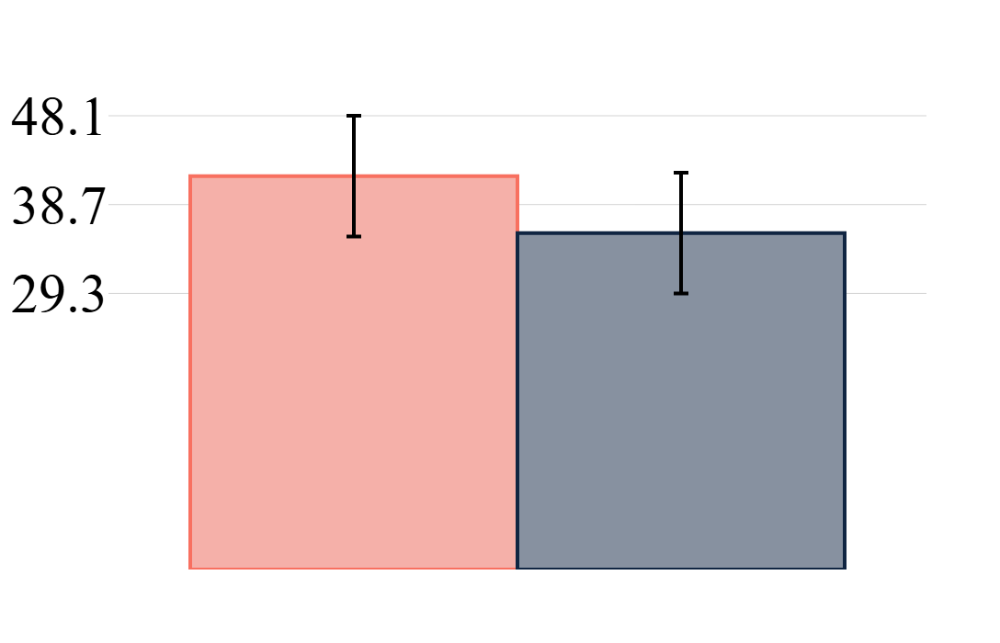

Barplot saved successfully at: C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_counterfactual_barplot\05QE009_counterfactual_barplot_average.svg


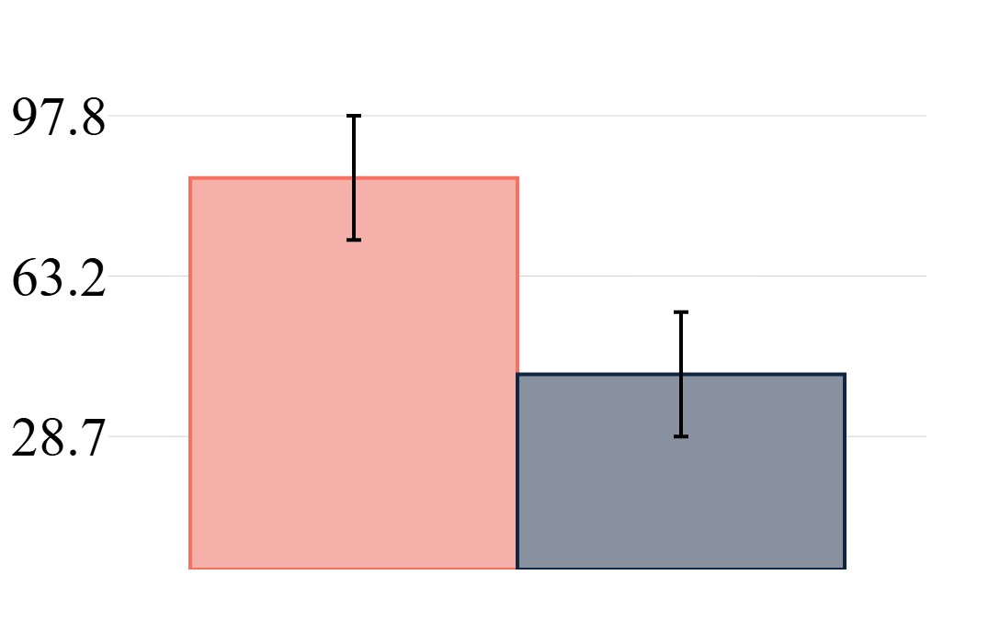

In [24]:
for station in station_list:
    # station = station_list[0]

    width = 500
    height = 700
    font_size = 60

    save = True
    save_path = save_dir2              # CHANGED (was save_dir)
    save_format = "svg"
    save_name = f"{station}_counterfactual_barplot_average"   # CHANGED

    max_df = get_dataframe(station, counter_max_dir)
    min_df = get_dataframe(station, counter_min_dir)

    # --- CHANGED: average across ALL return periods instead of one period ---
    rl_cols_max = [c for c in max_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]
    rl_cols_min = [c for c in min_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]

    max_df["_RL_avg_all_periods"] = max_df[rl_cols_max].mean(axis=1)
    min_df["_RL_avg_all_periods"] = min_df[rl_cols_min].mean(axis=1)

    # Keep the same structure you had (year series), but now it’s the avg across return periods
    eca_max_rl = max_df[["Year", "_RL_avg_all_periods"]].copy()
    eca_max_rl.rename(columns={"_RL_avg_all_periods": "Max_avg"}, inplace=True)

    eca_min_rl = min_df[["Year", "_RL_avg_all_periods"]].copy()
    eca_min_rl.rename(columns={"_RL_avg_all_periods": "Min_avg"}, inplace=True)

    merged_df = pd.merge(eca_max_rl, eca_min_rl, on="Year", how="outer")

    # --- CHANGED: bar heights + error bars computed across years ---
    max_mean = merged_df["Max_avg"].mean(skipna=True)
    min_mean = merged_df["Min_avg"].mean(skipna=True)

    max_std = merged_df["Max_avg"].std(skipna=True)
    min_std = merged_df["Min_avg"].std(skipna=True)

    # y-axis ticks similar to your old approach, but based on mean±std ranges
    y_min = min(min_mean - min_std, max_mean - max_std)
    y_max = max(min_mean + min_std, max_mean + max_std)
    y_mid = (y_min + y_max) / 2

    # --- CHANGED: Box -> Bar (keep styling) ---
    trace_min = go.Bar(
        x=[station],
        y=[min_mean],
        name="Average (Min ECA)",
        marker_color="#8791a0",                # same “fill” vibe you used for Min
        marker_line=dict(color="#102542", width=4),
        error_y=dict(type="data", array=[min_std], visible=True, thickness=4, width=8, color = "black"),
    )

    trace_max = go.Bar(
        x=[station],
        y=[max_mean],
        name="Average (Max ECA)",
        marker_color="#f5b0a9",                # same “fill” vibe you used for Max
        marker_line=dict(color="#f87060", width=4),
        error_y=dict(type="data", array=[max_std], visible=True, thickness=4, width=8, color = "black"),
    )

    fig = go.Figure(data=[trace_max, trace_min])

    fig.update_layout(
        title=None,
        font=dict(family="Times New Roman", size=font_size, color="black"),
        width=width,
        height=height,
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        barmode="group",
        xaxis=dict(
            showgrid=False,
            showticklabels=False,
            tickvals=[station],
            ticktext=[station],
            tickfont=dict(size=font_size),
        ),
        yaxis=dict(
            showgrid=True,
            gridcolor="lightgrey",
            tickvals=[y_min, y_mid, y_max],
            ticktext=[f"{y_min:.1f}", f"{y_mid:.1f}", f"{y_max:.1f}"],
            tickfont=dict(size=font_size),
        ),
        showlegend=False,
    )

    if save:
        if save_path is None or save_name is None:
            raise ValueError("To save the plot, you must specify both save_path and save_name.")
        full_save_path = os.path.join(save_path, f"{save_name}.{save_format}")
        fig.write_image(full_save_path)
        print(f"Barplot saved successfully at: {full_save_path}")

    fig.show()


In [19]:
# Mann Withney U test:
from scipy.stats import mannwhitneyu

station = "02AB006"

max_df = get_dataframe(station, counter_max_dir)
min_df = get_dataframe(station, counter_min_dir)

# --- CHANGED: average across ALL return periods instead of one period ---
rl_cols_max = [c for c in max_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]
rl_cols_min = [c for c in min_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]

max_df["_RL_avg_all_periods"] = max_df[rl_cols_max].mean(axis=1)
min_df["_RL_avg_all_periods"] = min_df[rl_cols_min].mean(axis=1)

max_rl_av_np = max_df["_RL_avg_all_periods"].to_numpy()
min_rl_av_np = min_df["_RL_avg_all_periods"].to_numpy()

statistic, p_value = mannwhitneyu(max_rl_av_np, min_rl_av_np, alternative='two-sided')

print(f"statistics = {statistic} and p-valye = {p_value}")

# # Keep the same structure you had (year series), but now it’s the avg across return periods
# eca_max_rl = max_df[["Year", "_RL_avg_all_periods"]].copy()
# eca_max_rl.rename(columns={"_RL_avg_all_periods": "Max_avg"}, inplace=True)

# eca_min_rl = min_df[["Year", "_RL_avg_all_periods"]].copy()
# eca_min_rl.rename(columns={"_RL_avg_all_periods": "Min_avg"}, inplace=True)

# merged_df = pd.merge(eca_max_rl, eca_min_rl, on="Year", how="outer")


statistics = 753.0 and p-valye = 0.001104485699374902


In [18]:
type(max_rl_av_np)

numpy.ndarray

In [21]:
results = []

for station in station_list:

    max_df = get_dataframe(station, counter_max_dir)
    min_df = get_dataframe(station, counter_min_dir)

    # --- average across ALL return periods (per year) ---
    rl_cols_max = [c for c in max_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]
    rl_cols_min = [c for c in min_df.columns if c.startswith("Return_Level_") and c.endswith("Yrs")]

    max_df["_RL_avg_all_periods"] = max_df[rl_cols_max].mean(axis=1)
    min_df["_RL_avg_all_periods"] = min_df[rl_cols_min].mean(axis=1)

    eca_max_rl = max_df[["Year", "_RL_avg_all_periods"]].copy()
    eca_max_rl.rename(columns={"_RL_avg_all_periods": "Max_avg"}, inplace=True)

    eca_min_rl = min_df[["Year", "_RL_avg_all_periods"]].copy()
    eca_min_rl.rename(columns={"_RL_avg_all_periods": "Min_avg"}, inplace=True)

    merged_df = pd.merge(eca_max_rl, eca_min_rl, on="Year", how="outer")

    # --- the exact data your boxplot would show (per-year averages) ---
    x = merged_df["Max_avg"].dropna().to_numpy()
    y = merged_df["Min_avg"].dropna().to_numpy()

    # Guard against too-few points
    if len(x) < 2 or len(y) < 2:
        results.append({
            "Station_ID": station,
            "n_Max": len(x),
            "n_Min": len(y),
            "U": np.nan,
            "p_value": np.nan,
            "alternative": "two-sided",
            "note": "Insufficient data for Mann–Whitney U (need >=2 per group).",
            "Max_mean": np.nanmean(x) if len(x) else np.nan,
            "Min_mean": np.nanmean(y) if len(y) else np.nan,
            "Max_median": np.nanmedian(x) if len(x) else np.nan,
            "Min_median": np.nanmedian(y) if len(y) else np.nan,
        })
        continue

    # Mann–Whitney U test on the per-year averages (boxplot inputs)
    # Use two-sided unless you have a pre-registered directional hypothesis.
    U, p = mannwhitneyu(x, y, alternative="two-sided", method="auto")

    results.append({
        "Station_ID": station,
        "n_Max": len(x),
        "n_Min": len(y),
        "U": U,
        "p_value": p,
        "alternative": "two-sided",
        "Max_mean": float(np.mean(x)),
        "Min_mean": float(np.mean(y)),
        "Max_median": float(np.median(x)),
        "Min_median": float(np.median(y)),
        "Delta_mean_MaxMinusMin": float(np.mean(x) - np.mean(y)),
        "Delta_median_MaxMinusMin": float(np.median(x) - np.median(y)),
        "note": ""
    })

# Final results DataFrame
mw_results_df = pd.DataFrame(results).sort_values("Station_ID").reset_index(drop=True)

# Optional: add a simple significance flag (uncorrected)
mw_results_df["sig_p<0.05"] = mw_results_df["p_value"] < 0.05

mw_results_df


,Station_ID,n_Max,n_Min,U,p_value,alternative,Max_mean,Min_mean,Max_median,Min_median,Delta_mean_MaxMinusMin,Delta_median_MaxMinusMin,note,sig_p<0.05
0,02AB006,34,30,753.0,1.104486e-03,two-sided,309.230840,243.722831,314.273120,242.551889,65.508009,71.721231,,True
1,02AC002,31,31,579.0,1.676790e-01,two-sided,147.605358,132.233943,144.330445,128.959030,15.371415,15.371415,,False
2,02AD010,28,28,587.0,1.436375e-03,two-sided,82.590421,64.005098,74.905886,56.320564,18.585322,18.585322,,True
3,02CC005,33,33,583.0,6.260247e-01,two-sided,229.536854,222.511760,241.616554,234.591460,7.025094,7.025094,,False
4,02CE002,33,33,650.0,1.781191e-01,two-sided,174.923146,156.625274,171.204187,152.906316,18.297872,18.297872,,False
5,02JC008,33,33,885.0,1.298734e-05,two-sided,225.996366,173.202417,223.794215,171.000266,52.793949,52.793949,,True
6,04JD005,33,15,495.0,3.929789e-08,two-sided,552.501189,182.141463,563.724084,183.019400,370.359726,380.704684,,True
7,04LM001,31,31,0.0,1.400201e-11,two-sided,2287.762599,3084.124261,2289.128853,3085.490515,-796.361663,-796.361663,,True
8,04MF001,31,29,506.0,4.074507e-01,two-sided,1039.152796,1007.473088,1074.404189,1059.656360,31.679708,14.747829,,False
9,05QD016,34,36,1224.0,6.687895e-13,two-sided,223.704193,97.515640,225.577014,99.424606,126.188553,126.152409,,True


## Attribution Trend and Distribution Plot

In [2]:
# RUN THIS!!
# directories
mu_sigma_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Mu_Sigma_Tables"
Flood_rl_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Attribution\Return_Levels_Fixed_Climatic_Changing_ECA"

In [3]:
station_list = [
    "02AB006",
    "02AC002",
    "02AD010",
    "02CC005",
    "02CE002",
    "02JC008",
    "04JD005",
    "04LM001",
    "04MF001",
    "05QD016",
    "05QE009"
]

### Trends

In [27]:
outdir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Trend"

In [5]:
for station in station_list:
    RL_dict = get_RL_variabe_eca_fixed_climate(station, 
                                     isolate_eca_rp_dir, 
                                     return_years=[2, 5, 10, 20, 30])
    
    plot_trend_table_with_graph(station, RL_dict, return_periods_of_interest=None, save = True, 
                                save_path = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Trend_attibution",
                                save_name = f"Trend_with_fixed_climatic_covs_{station}_station"
                               )

NameError: name 'get_RL_variabe_eca_fixed_climate' is not defined

In [28]:
os.chdir(Flood_rl_dir)
os.listdir()

['Complete_Return_Levels_table_02AB006.csv',
 'Complete_Return_Levels_table_02AC002.csv',
 'Complete_Return_Levels_table_02AD010.csv',
 'Complete_Return_Levels_table_02BA003.csv',
 'Complete_Return_Levels_table_02CC005.csv',
 'Complete_Return_Levels_table_02CE002.csv',
 'Complete_Return_Levels_table_02DC004.csv',
 'Complete_Return_Levels_table_02JC008.csv',
 'Complete_Return_Levels_table_04GA002.csv',
 'Complete_Return_Levels_table_04JC002.csv',
 'Complete_Return_Levels_table_04JD005.csv',
 'Complete_Return_Levels_table_04LM001.csv',
 'Complete_Return_Levels_table_04MF001.csv',
 'Complete_Return_Levels_table_05QC001.csv',
 'Complete_Return_Levels_table_05QD016.csv',
 'Complete_Return_Levels_table_05QE008.csv',
 'Complete_Return_Levels_table_05QE009.csv',
 'Explanation.txt',
 'XComplete_Return_Levels_table_02AD010.csv',
 'XComplete_Return_Levels_table_04JD005.csv',
 'XXComplete_Return_Levels_table_05QD016.csv']

files for 02AB006 has been saved.


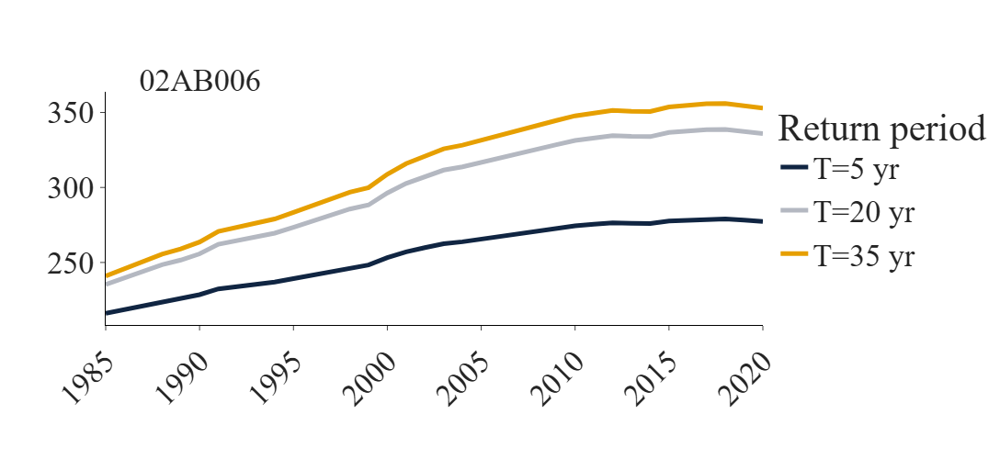

files for 02AC002 has been saved.


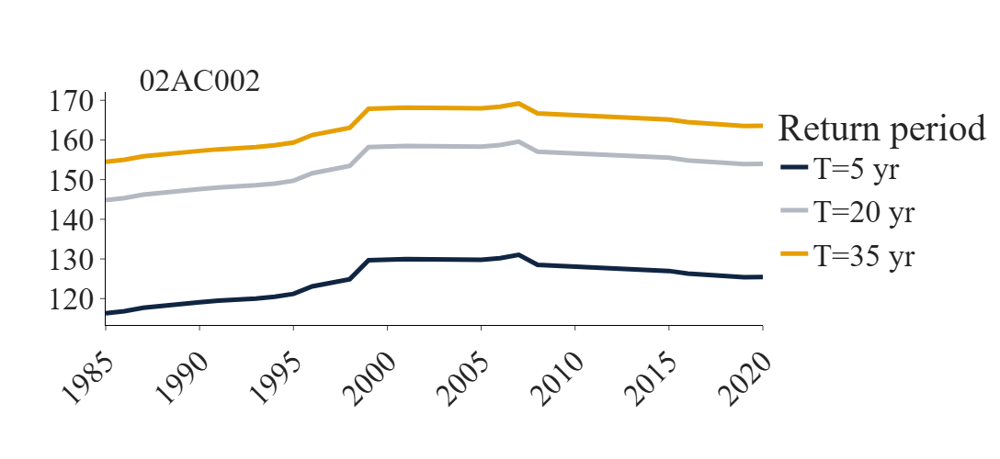

files for 02AD010 has been saved.


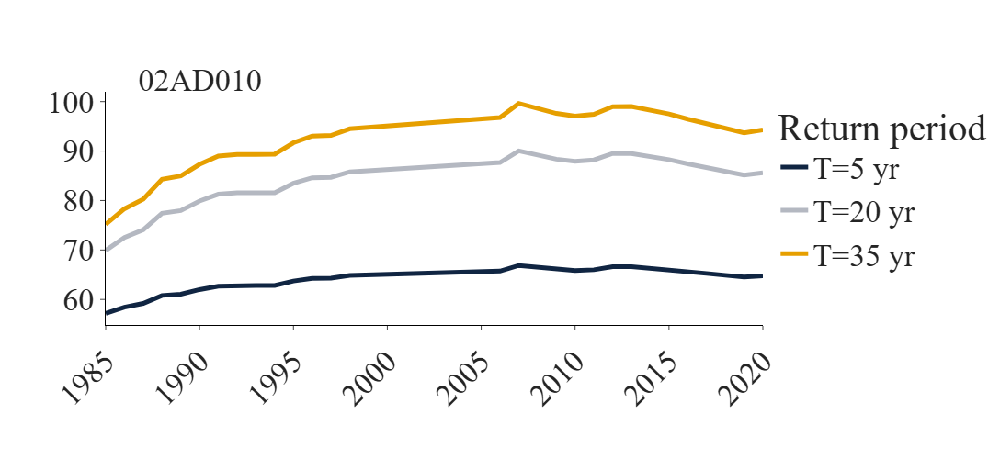

files for 02CC005 has been saved.


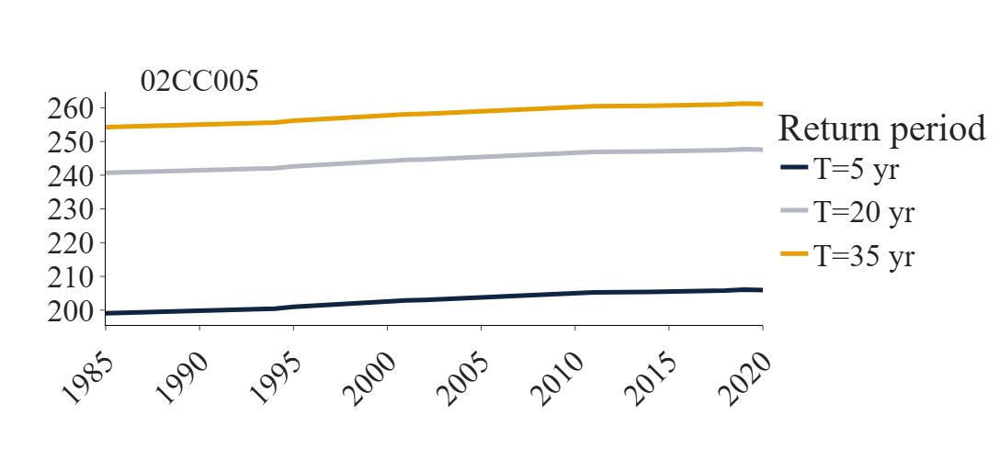

files for 02CE002 has been saved.


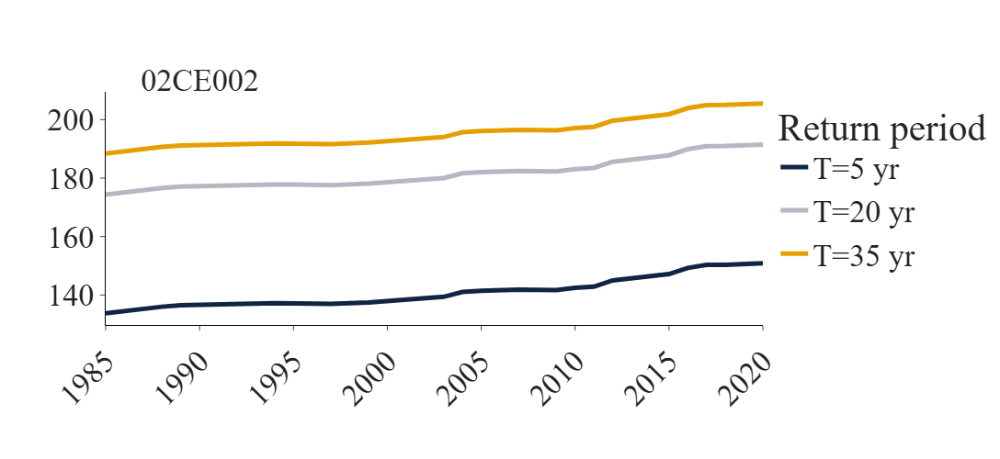

files for 02JC008 has been saved.


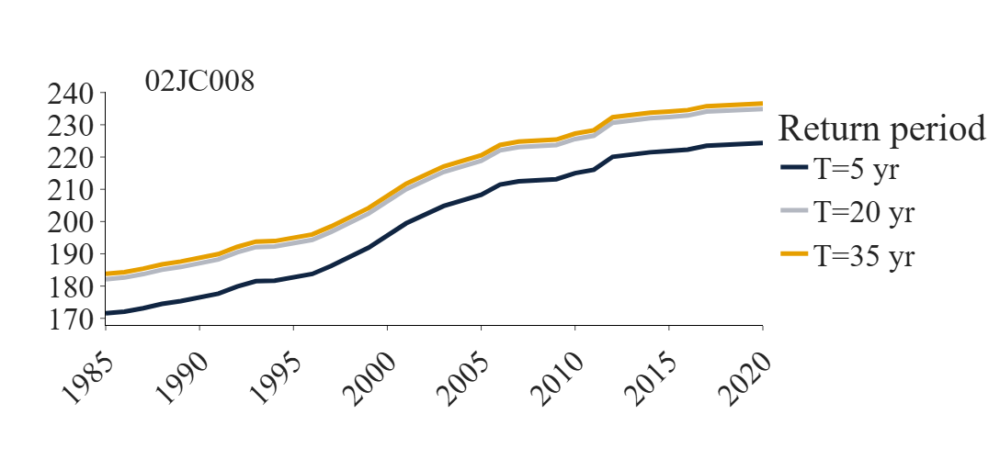

files for 04JD005 has been saved.


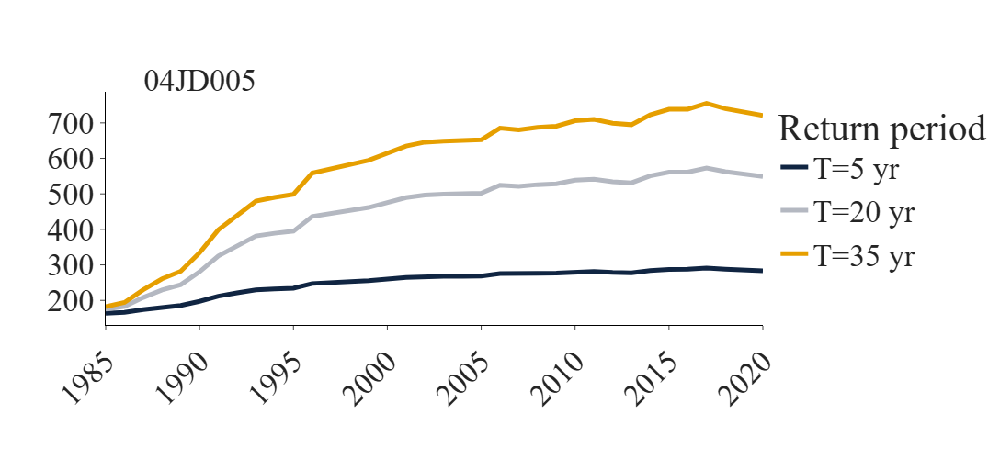

files for 04LM001 has been saved.


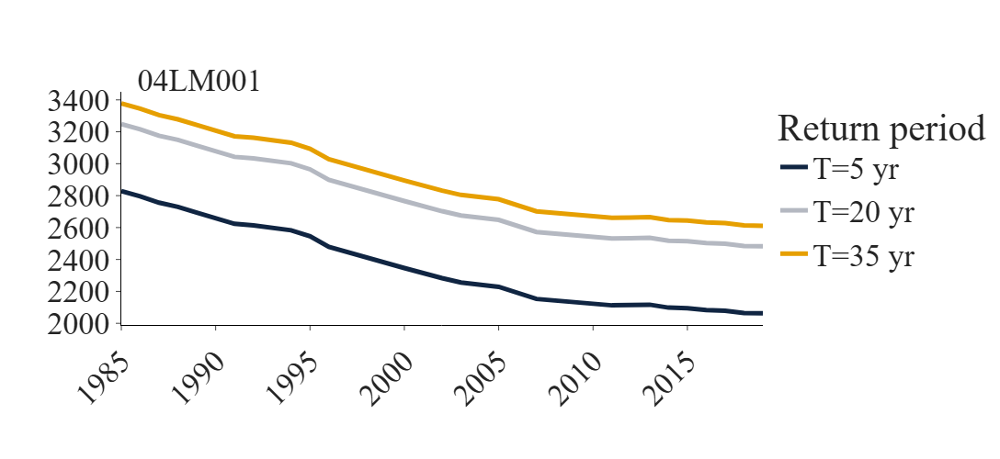

files for 04MF001 has been saved.


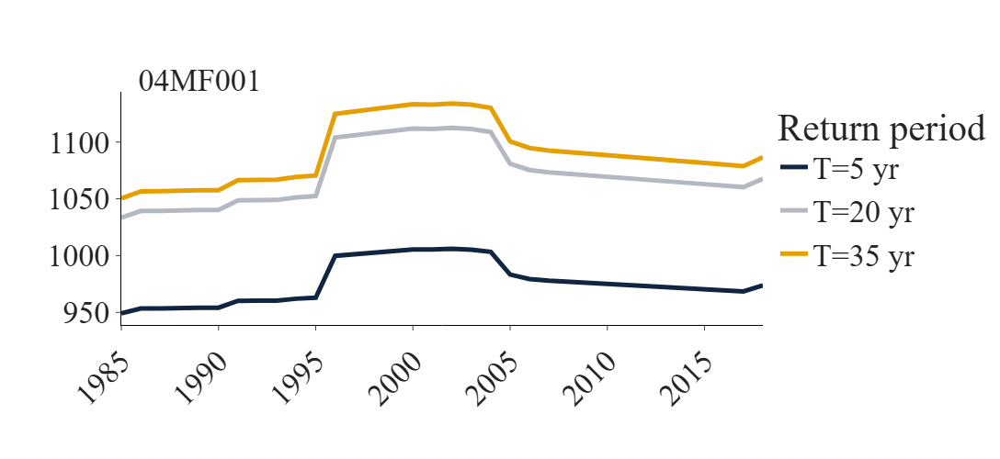

files for 05QD016 has been saved.


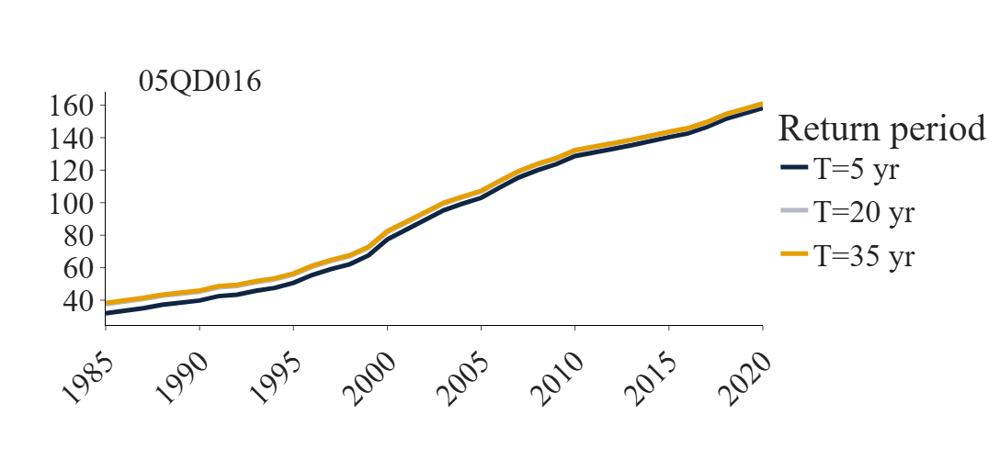

files for 05QE009 has been saved.


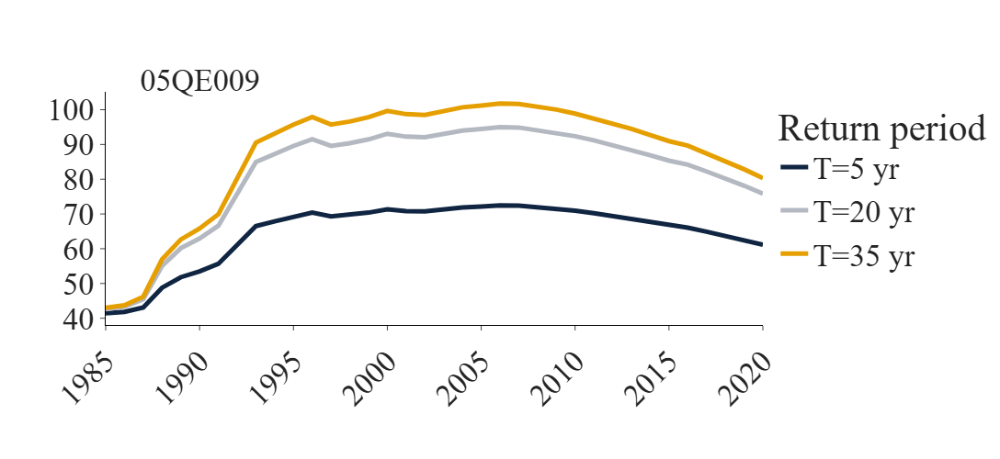

In [33]:
# ========== SETTINGS ==========
font_family     = "Times New Roman"
title_font_size = 34
axis_font_size  = 34
legend_font_sz  = 34
fig_width       = 900
fig_height      = 500
line_width      = 5   # thickness of curves

# Colors (navy, salmon, and a color-blind friendly green)
colors = ["#102542", "#b4b8c1", "#E69F00"]  
# navy, grey, salmon
# ==============================

for station in station_list:
    phrase = f"Complete_Return_Levels_table_{station}.csv"
    flood_rls_df = pd.read_csv(phrase)
    
    # Choose periods you want to show
    periods = [5, 20, 35]
    
    # Build expected column names
    cols = [f"Return_Level_{int(p)}Yrs" for p in periods]
    
    # Subset to Year + desired columns
    plot_df = flood_rls_df[["Year"] + cols].sort_values("Year").copy()
    
    # ---- Plotly figure ----
    fig = go.Figure()
    
    # Add one line per period, using settings
    for p, col, color in zip(periods, cols, colors):
        fig.add_trace(go.Scatter(
            x=plot_df["Year"],
            y=plot_df[col],
            mode="lines",   # no markers
            name=f"T={int(p)} yr",
            line=dict(color=color, width=line_width)
        ))
    
    # Layout
    fig.update_layout(
        title=dict(text=f"{station}",
                   x=0.2, xanchor="center", y=0.85, yanchor="top",
                   font=dict(family=font_family, size=title_font_size)),
        xaxis_title="",
        yaxis_title="",
        xaxis=dict(showgrid=False, showline=True, linecolor="black", linewidth=1,
                   title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size),
                   tickangle=-45,
                  ),
        yaxis=dict(showgrid=False, showline=True, linecolor="black", linewidth=1,
                   title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size)),
        legend=dict(title="Return period", font=dict(family=font_family, size=legend_font_sz)),
        template="simple_white",
        width=fig_width,
        height=fig_height
    )

    fig.write_image(os.path.join(outdir, f"Trend_fix_hC_variable_eca_{station}.svg"))
    fig.write_image(os.path.join(outdir, f"Trend_fix_hC_variable_eca_{station}.png"), scale = 3)
    print(f"files for {station} has been saved.")
    
    fig.show()

files for 02AB006 has been saved.


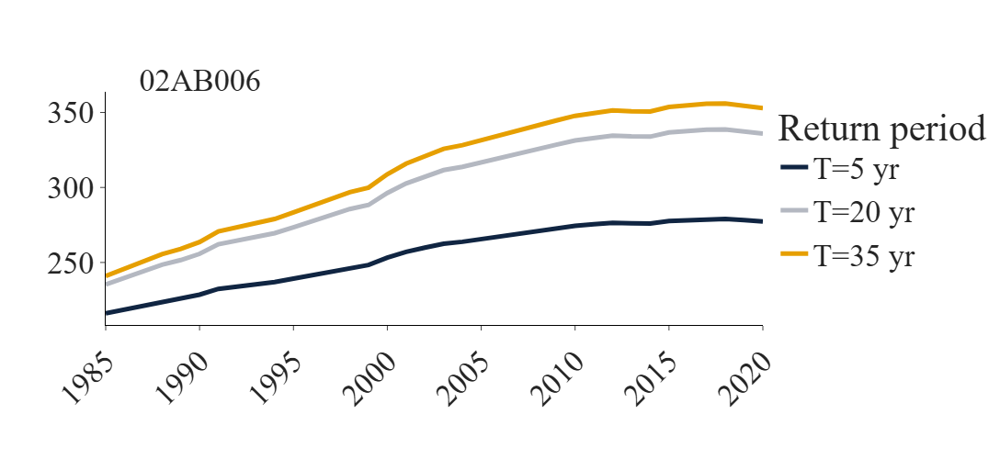

files for 02AC002 has been saved.


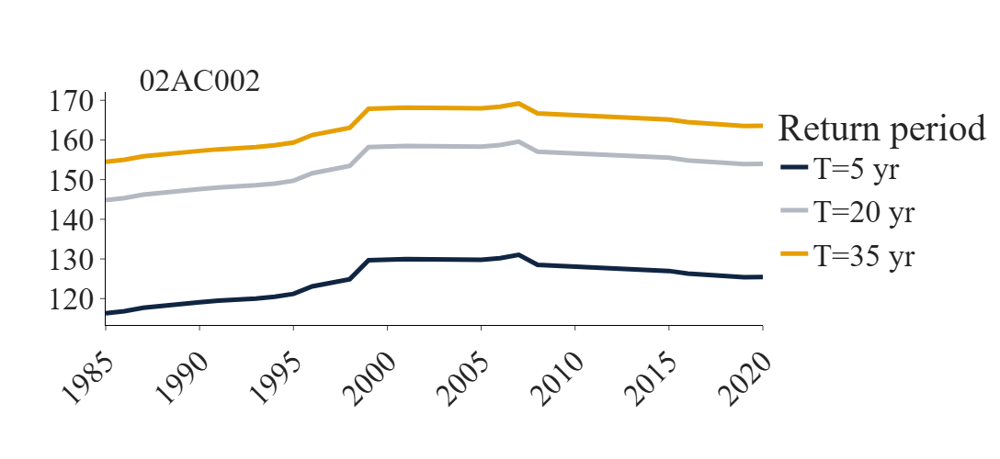

files for 02AD010 has been saved.


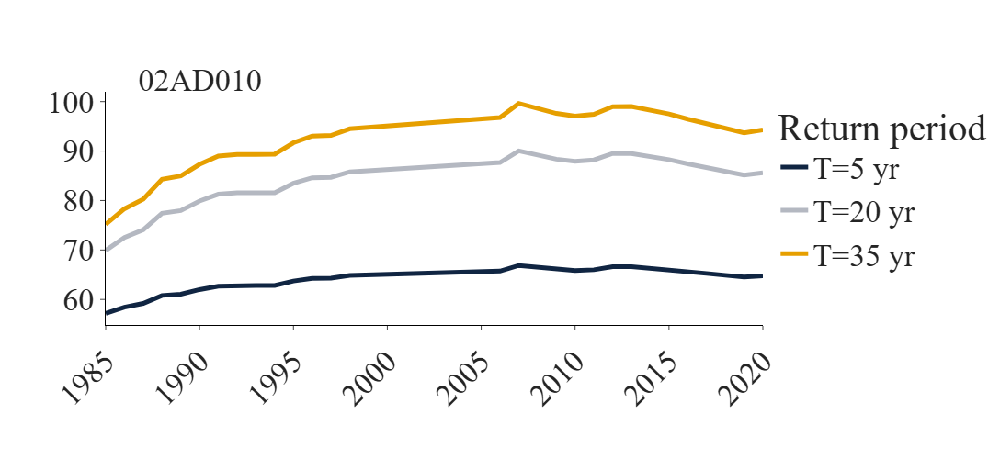

files for 02CC005 has been saved.


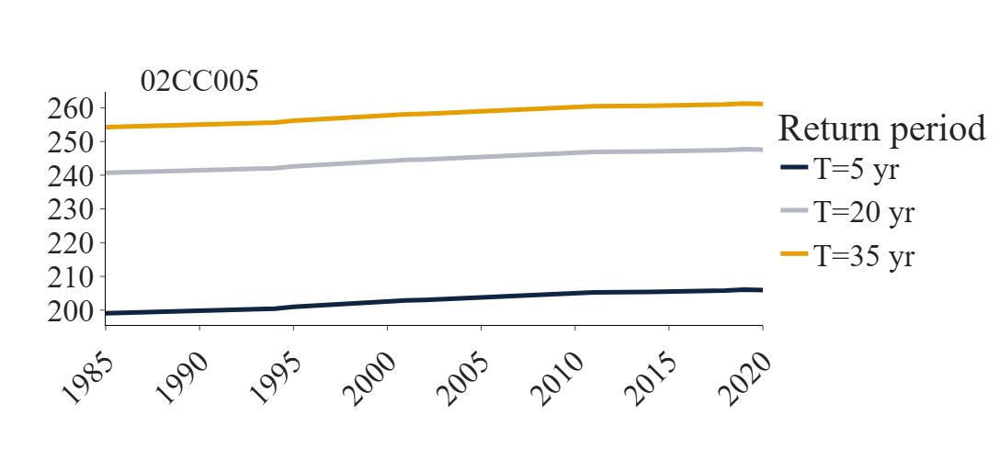

files for 02CE002 has been saved.


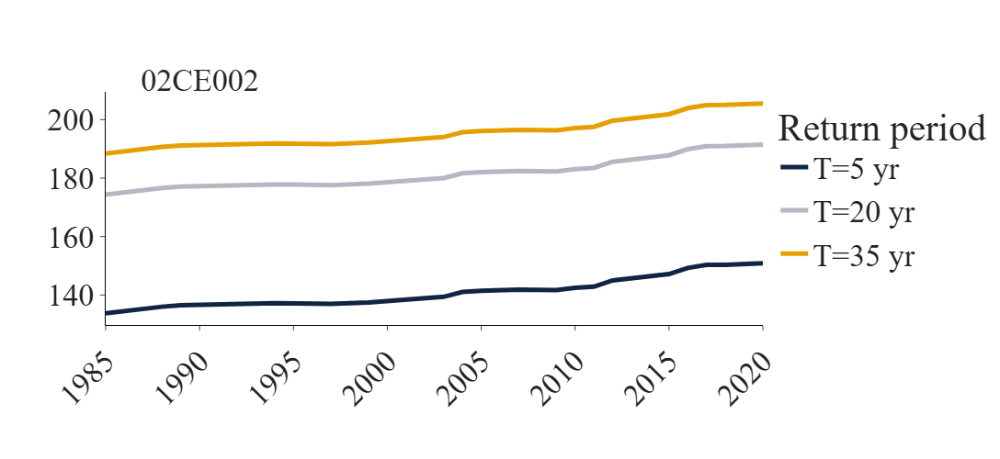

files for 02JC008 has been saved.


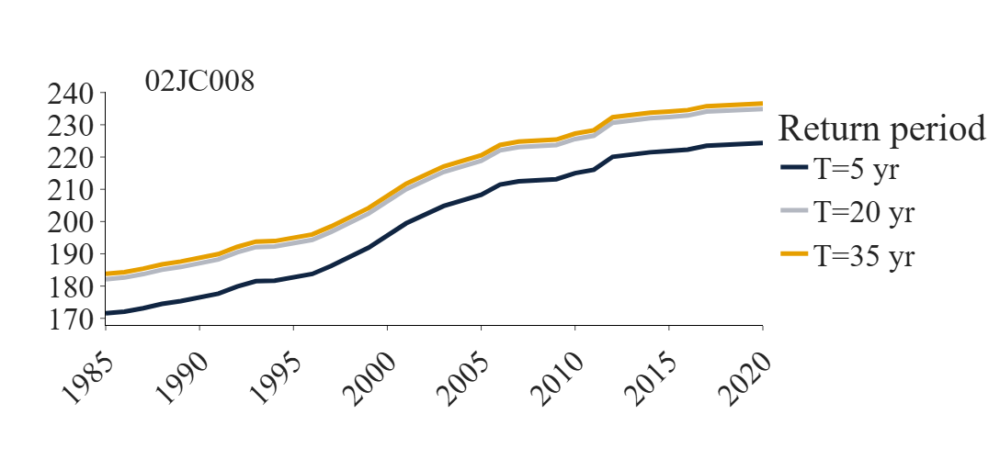

files for 04JD005 has been saved.


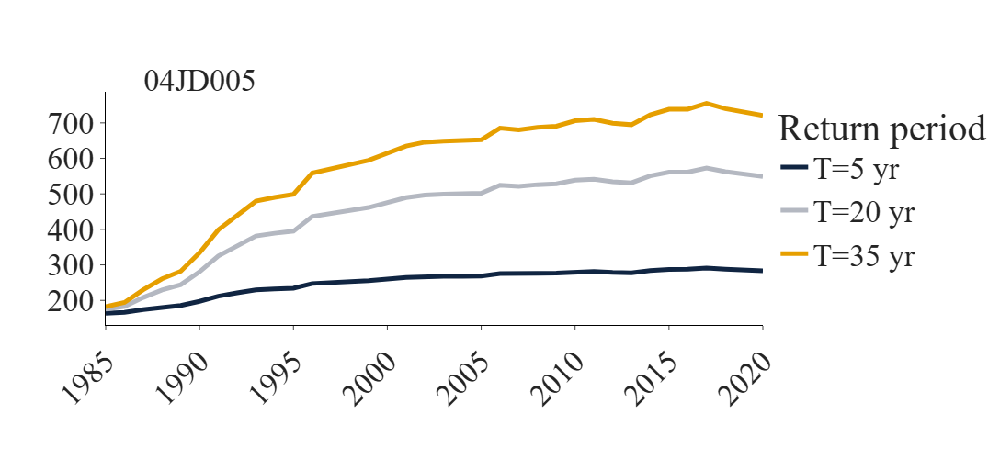

files for 04LM001 has been saved.


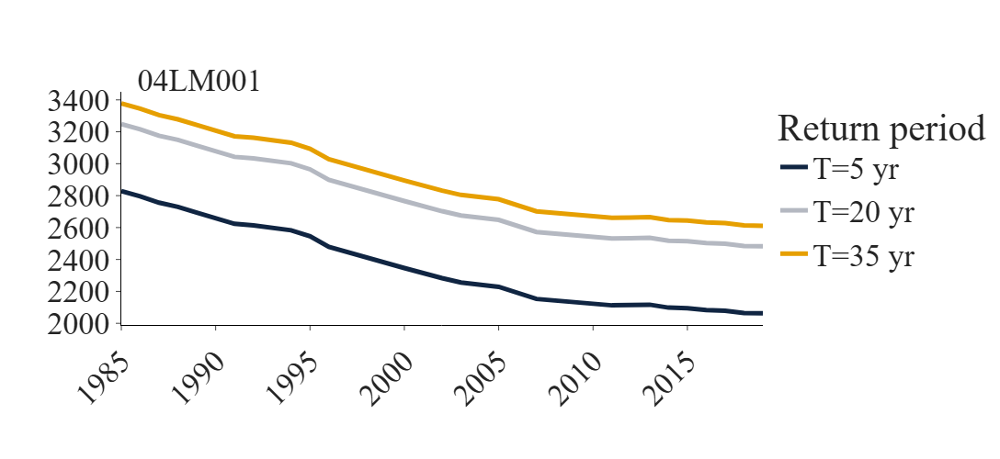

files for 04MF001 has been saved.


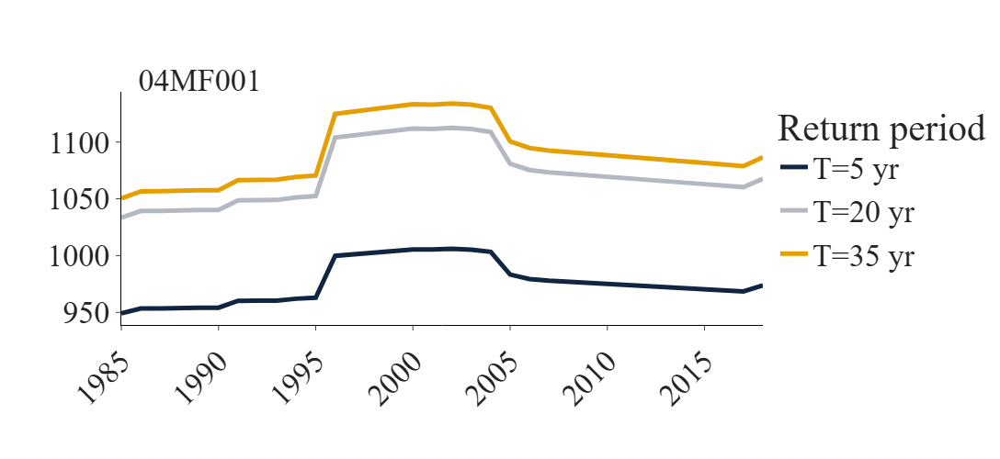

files for 05QD016 has been saved.


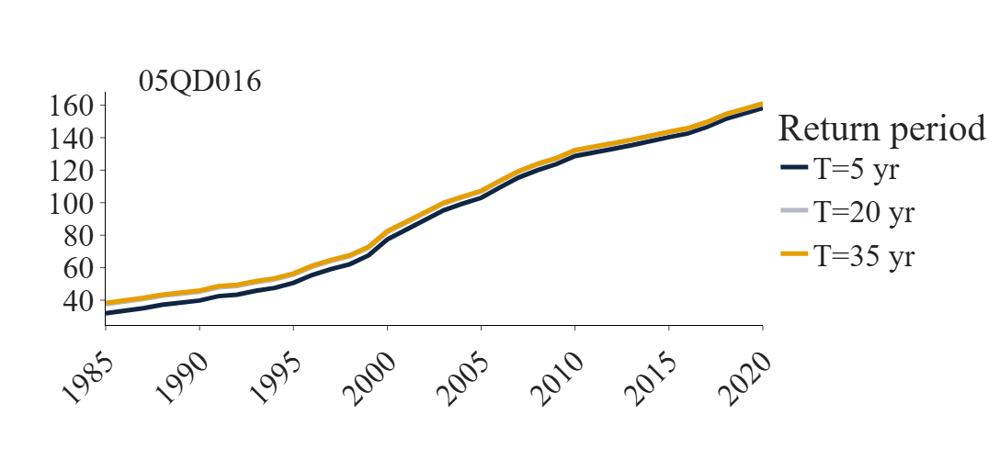

files for 05QE009 has been saved.


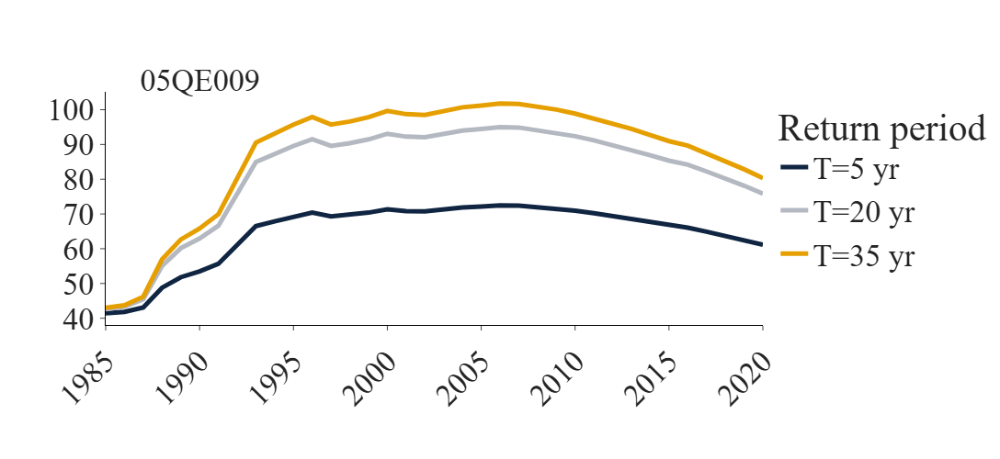

In [33]:
# ========== SETTINGS ==========
font_family     = "Times New Roman"
title_font_size = 34
axis_font_size  = 34
legend_font_sz  = 34
fig_width       = 900
fig_height      = 500
line_width      = 5   # thickness of curves

# Colors (navy, salmon, and a color-blind friendly green)
colors = ["#102542", "#b4b8c1", "#E69F00"]  
# navy, grey, salmon
# ==============================

for station in station_list:
    phrase = f"Complete_Return_Levels_table_{station}.csv"
    flood_rls_df = pd.read_csv(phrase)
    
    # Choose periods you want to show
    periods = [5, 20, 35]
    
    # Build expected column names
    cols = [f"Return_Level_{int(p)}Yrs" for p in periods]
    
    # Subset to Year + desired columns
    plot_df = flood_rls_df[["Year"] + cols].sort_values("Year").copy()
    
    # ---- Plotly figure ----
    fig = go.Figure()
    
    # Add one line per period, using settings
    for p, col, color in zip(periods, cols, colors):
        fig.add_trace(go.Scatter(
            x=plot_df["Year"],
            y=plot_df[col],
            mode="lines",   # no markers
            name=f"T={int(p)} yr",
            line=dict(color=color, width=line_width)
        ))
    
    # Layout
    fig.update_layout(
        title=dict(text=f"{station}",
                   x=0.2, xanchor="center", y=0.85, yanchor="top",
                   font=dict(family=font_family, size=title_font_size)),
        xaxis_title="",
        yaxis_title="",
        xaxis=dict(showgrid=False, showline=True, linecolor="black", linewidth=1,
                   title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size),
                   tickangle=-45,
                  ),
        yaxis=dict(showgrid=False, showline=True, linecolor="black", linewidth=1,
                   title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size)),
        legend=dict(title="Return period", font=dict(family=font_family, size=legend_font_sz)),
        template="simple_white",
        width=fig_width,
        height=fig_height
    )

    fig.write_image(os.path.join(outdir, f"Trend_fix_hC_variable_eca_{station}.svg"))
    fig.write_image(os.path.join(outdir, f"Trend_fix_hC_variable_eca_{station}.png"), scale = 3)
    print(f"files for {station} has been saved.")
    
    fig.show()

In [117]:
station = "02AB006"

phrase = f'Complete_Return_Levels_table_{station}.csv'
flood_rls_df = pd.read_csv(phrase)

periods = ["5", "20", "35"]

for period in periods:
    col_name = f'Return_Level_{period}Yrs'
    var_name = f'rl_{period}yr'
    # making variables with custom names
    globals()[var_name] = flood_rls_df[col_name]
    print(f"{var_name} has been built as a variable")

# Now making the plot
year = flood_rls_df["Year"]



rl_5yr has been built as a variable
rl_20yr has been built as a variable
rl_35yr has been built as a variable


### Distribution graphs

In [8]:
outdir_whole = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Distribution_Shift\Whole_Distribution"
outdir_flood = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Distribution_Shift\Flood_Distribution"

In [9]:
os.chdir(mu_sigma_dir)
# os.listdir()

files for 02AB006 have been saved.


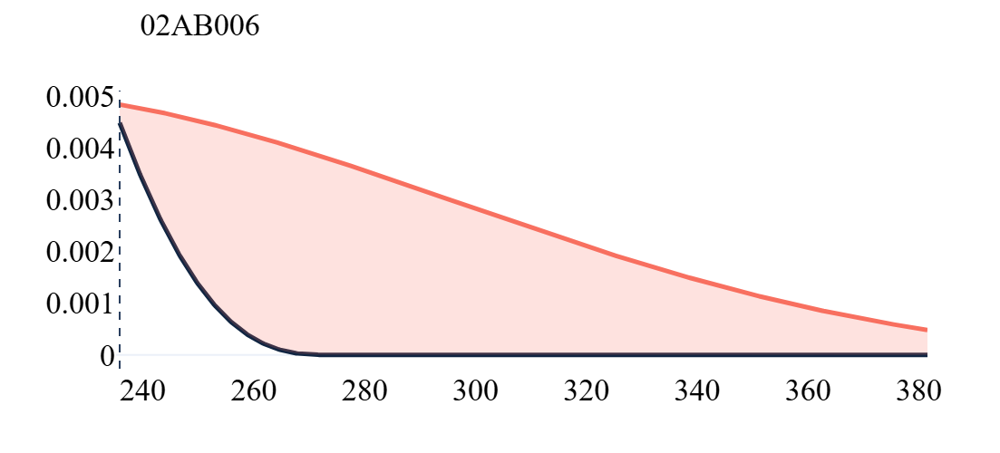

files for 02AC002 have been saved.


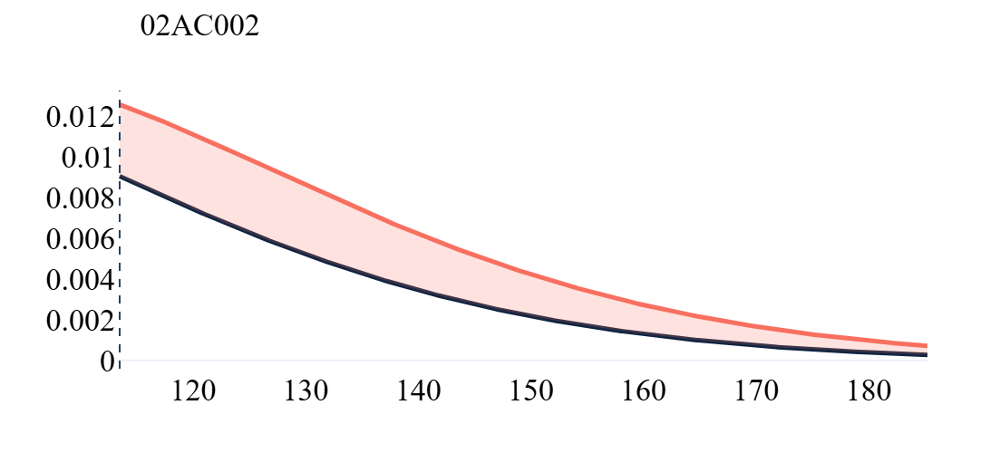

files for 02AD010 have been saved.


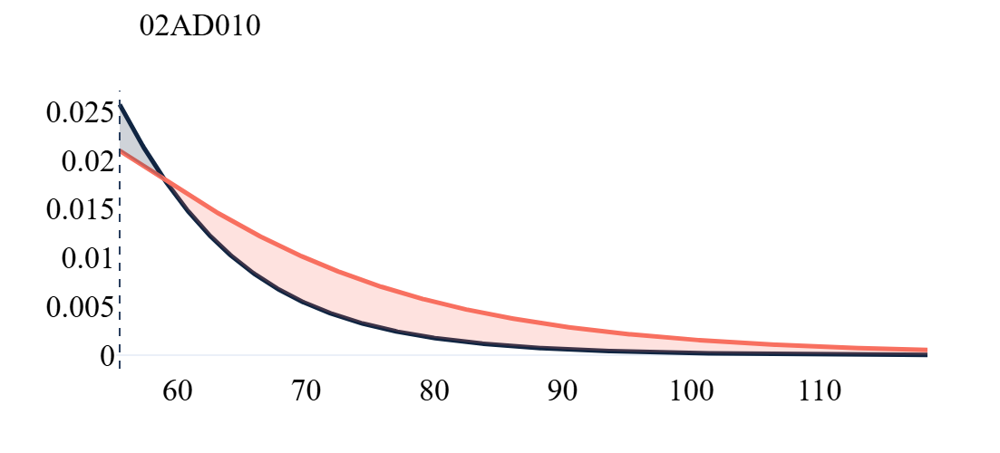

files for 02CC005 have been saved.


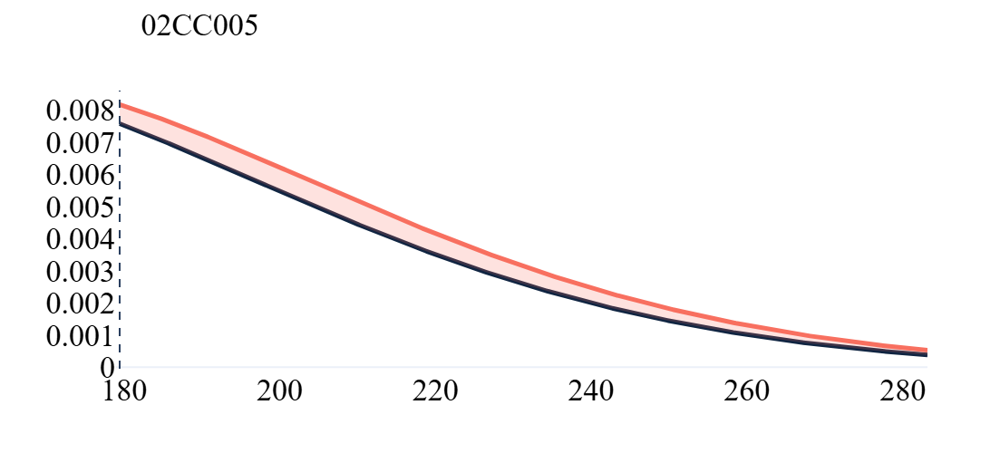

files for 02CE002 have been saved.


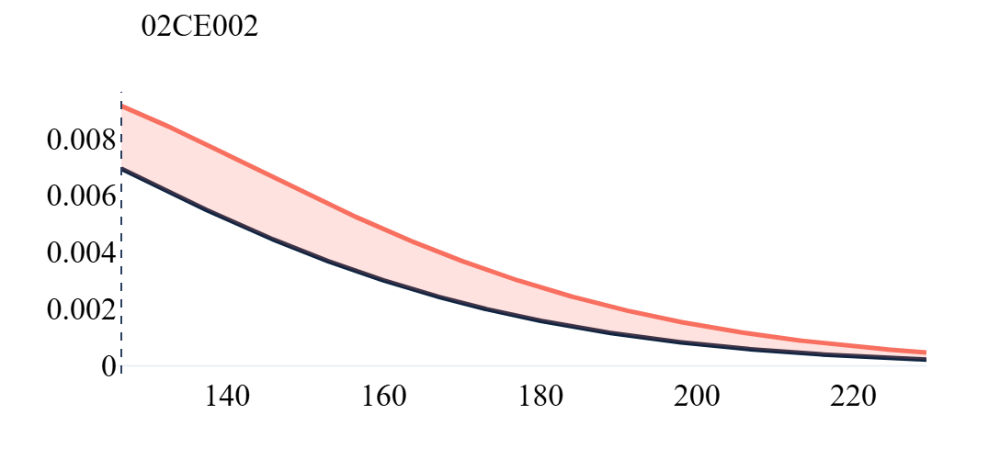

files for 02JC008 have been saved.


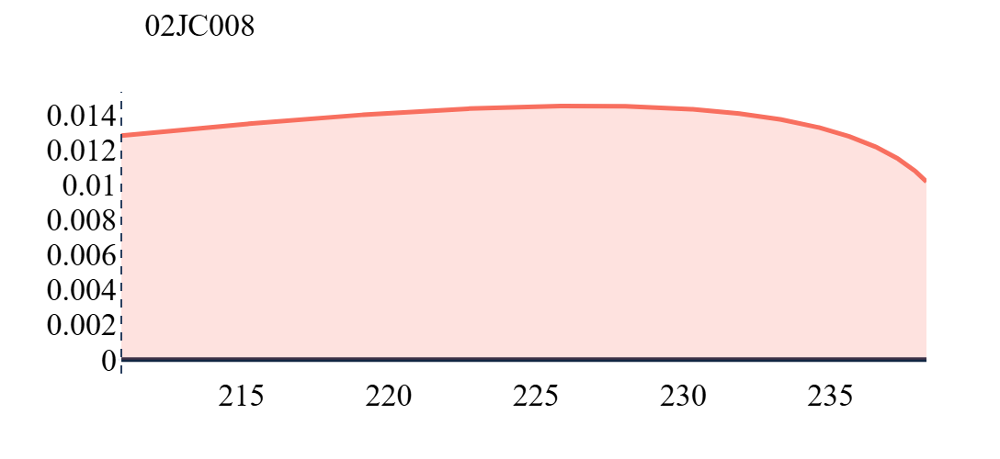

files for 04JD005 have been saved.


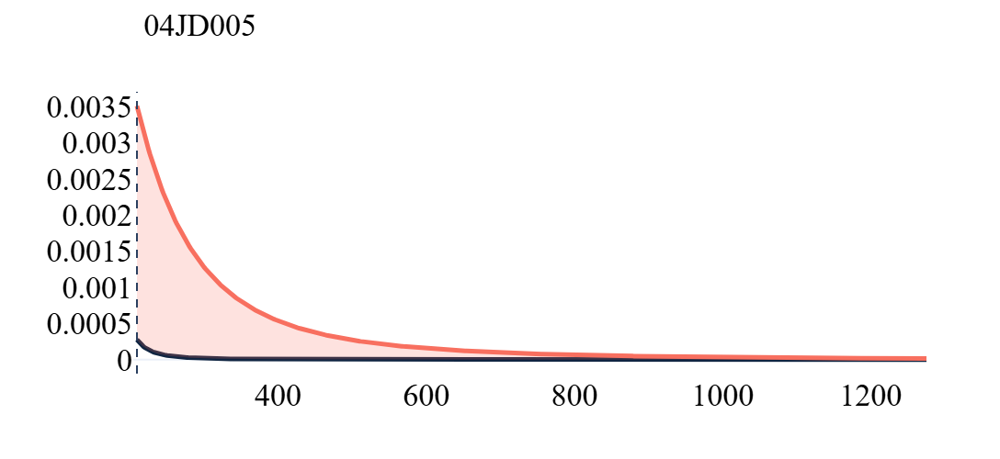

files for 04LM001 have been saved.


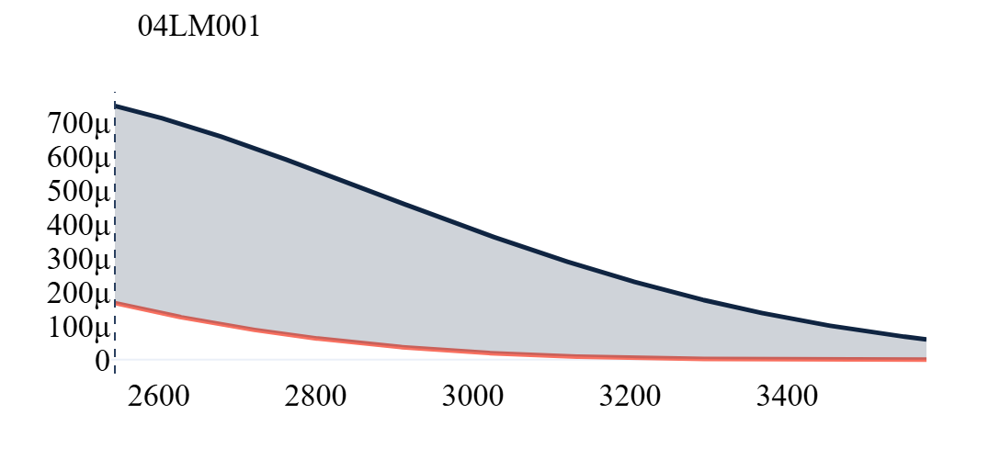

files for 04MF001 have been saved.


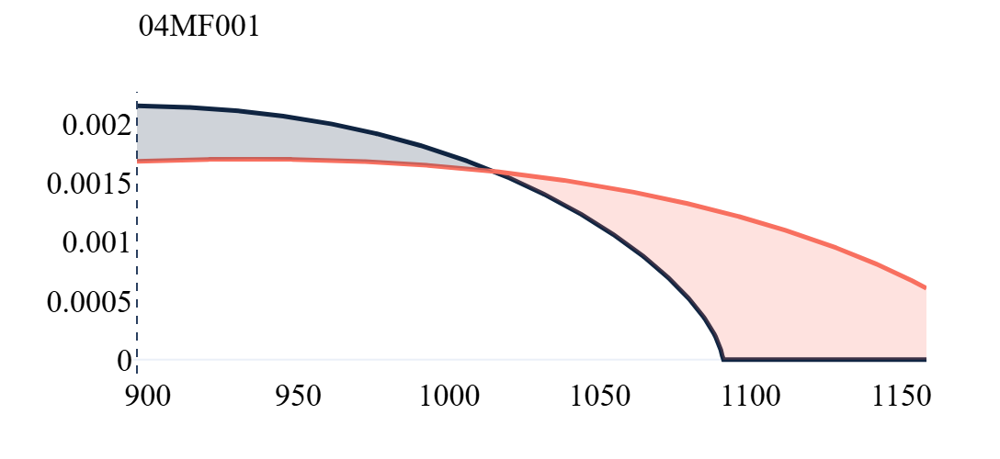

files for 05QD016 have been saved.


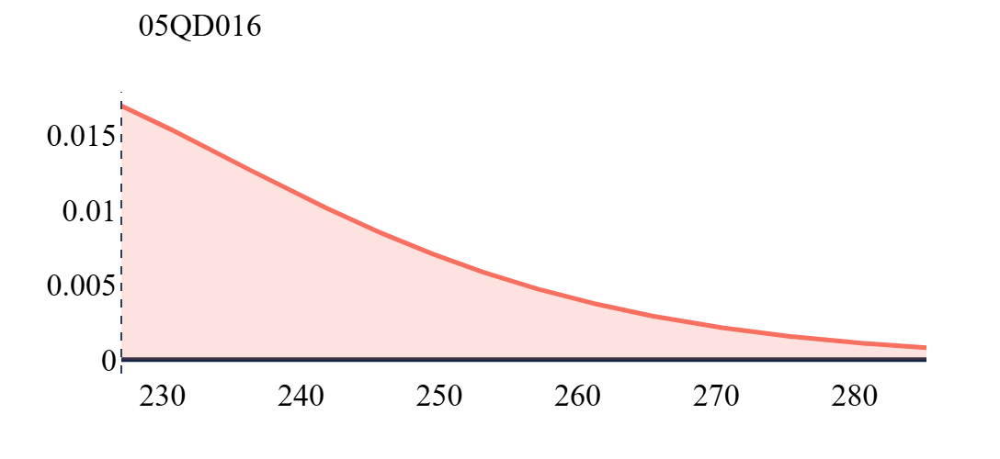

files for 05QE009 have been saved.


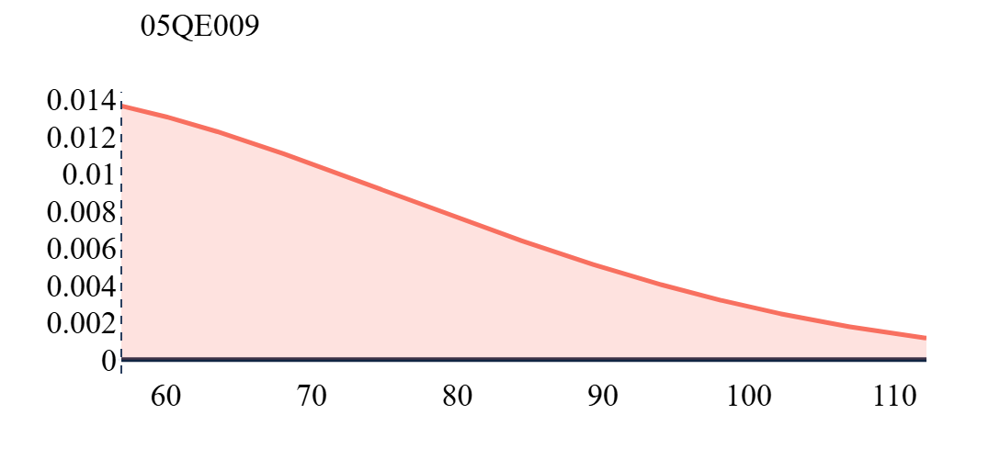

In [25]:
# ========== SETTINGS ==========
line_colour_min = "#102542"   # dark navy
line_colour_max = "#f87060"   # coral/red
fill_opacity = 0.2            # opacity for shaded difference

font_family = "Times New Roman"
title_font_size = 34
axis_font_size = 34
fig_width = 800
fig_height = 500
# ===============================

for station in station_list:
    # file for this station
    file_name_formula = f"Complete_mu_sigma_table_{station}.csv"
    mu_sig_df = pd.read_csv(file_name_formula)
    
    # min/max ECA rows
    row_min = mu_sig_df.loc[mu_sig_df["ECA"].idxmin()]
    row_max = mu_sig_df.loc[mu_sig_df["ECA"].idxmax()]
    
    # extract parameters
    mu_min, sig_min, xi_min_R = float(row_min["Mu_ECA"]), float(row_min["Sigma_ECA"]), float(row_min["Shape"])
    mu_max, sig_max, xi_max_R = float(row_max["Mu_ECA"]), float(row_max["Sigma_ECA"]), float(row_max["Shape"])
    c_min, c_max = -xi_min_R, -xi_max_R
    
    EPS = 1e-10
    c_min = 0.0 if abs(c_min) < EPS else c_min
    c_max = 0.0 if abs(c_max) < EPS else c_max
    
    rv_min = gev(c_min, loc=mu_min, scale=sig_min)
    rv_max = gev(c_max, loc=mu_max, scale=sig_max)

    # Flood threshold
    T0 = 2.6
    q0 = 1 - 1/T0
    x_lo = max(rv_min.ppf(q0), rv_max.ppf(q0))
    x_hi = max(rv_min.ppf(0.99), rv_max.ppf(0.99))
    x = np.linspace(x_lo, x_hi, 600)

    y_min = rv_min.pdf(x)
    y_max = rv_max.pdf(x)

    fig = go.Figure()

    # Main curves
    fig.add_trace(go.Scatter(x=x, y=y_min, mode="lines", name="Min ECA",
                             line=dict(color=line_colour_min, width=5)))
    fig.add_trace(go.Scatter(x=x, y=y_max, mode="lines", name="Max ECA",
                             line=dict(color=line_colour_max, width=5)))

    # Difference shading
    # region where max is higher
    fig.add_trace(go.Scatter(
        x=np.concatenate([x, x[::-1]]),
        y=np.concatenate([np.minimum(y_min, y_max), y_max[::-1]]),
        fill="toself",
        fillcolor=line_colour_max,
        opacity=fill_opacity,
        line=dict(width=0),
        hoverinfo="skip",
        showlegend=False
    ))
    # region where min is higher
    fig.add_trace(go.Scatter(
        x=np.concatenate([x, x[::-1]]),
        y=np.concatenate([np.minimum(y_min, y_max), y_min[::-1]]),
        fill="toself",
        fillcolor=line_colour_min,
        opacity=fill_opacity,
        line=dict(width=0),
        hoverinfo="skip",
        showlegend=False
    ))

    # Threshold line
    fig.add_vline(x=x_lo, line_dash="dash",
                  annotation_text="",
                  annotation_position="top left")

    # Layout
    fig.update_layout(
        title=dict(
            text=f"{station}",
            font=dict(family=font_family, size=title_font_size, color="black"),
            x=0.2,
            xanchor="center",
            y=0.97,       # raised higher (default ~0.98, was 0.85)
            yanchor="top"
        ),
        xaxis=dict(
            title="",  # add your label text here
            title_font=dict(family=font_family, size=axis_font_size, color="black"),
            tickfont=dict(family=font_family, size=axis_font_size, color="black"),
            showgrid=False
        ),
        yaxis=dict(
            title="",  # add your label text here
            title_font=dict(family=font_family, size=axis_font_size, color="black"),
            tickfont=dict(family=font_family, size=axis_font_size, color="black"),
            showgrid=False
        ),
        template="plotly_white",
        showlegend=False,
        width=fig_width,
        height=fig_height
    )

    fig.write_image(os.path.join(outdir_flood, f"flood_distribution_shift_{station}.svg"))
    fig.write_image(os.path.join(outdir_flood, f"flood_distribution_shift_{station}.png"), scale=3)
    print(f"files for {station} have been saved.")
    fig.show()


files for 02AB006 has been saved.


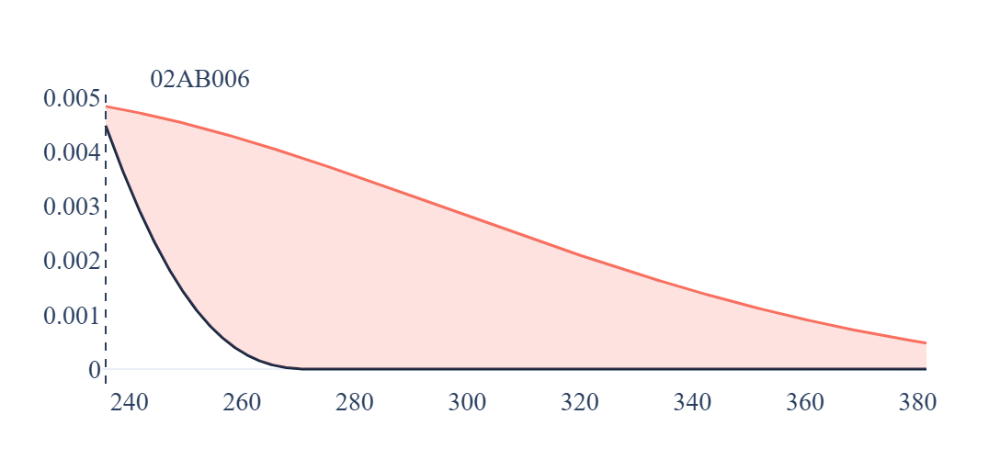

files for 02AC002 has been saved.


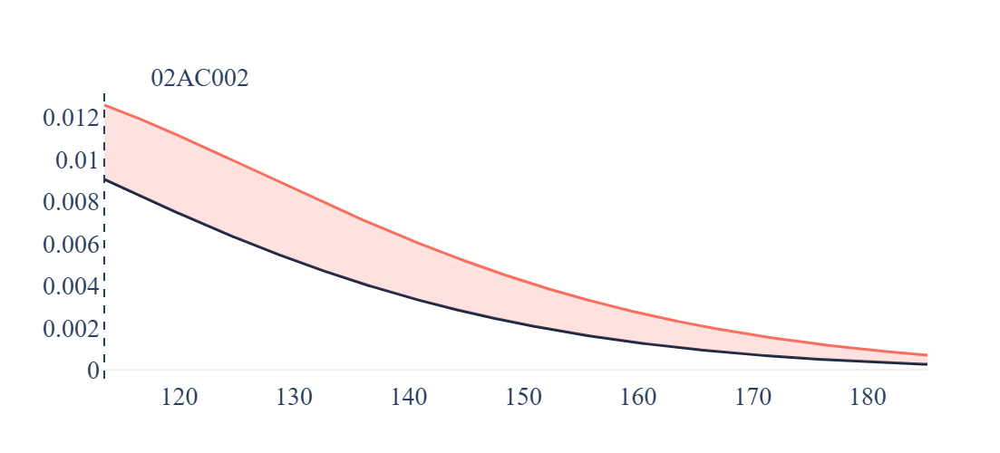

files for 02AD010 has been saved.


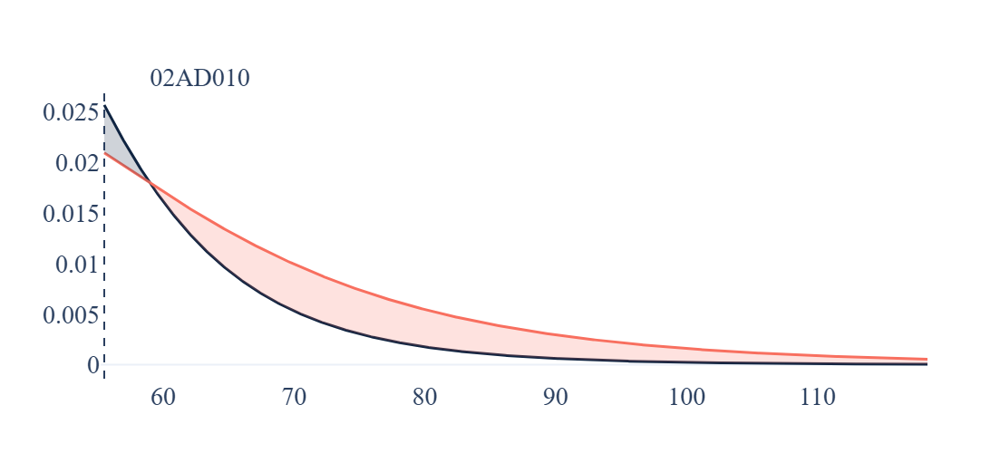

files for 02CC005 has been saved.


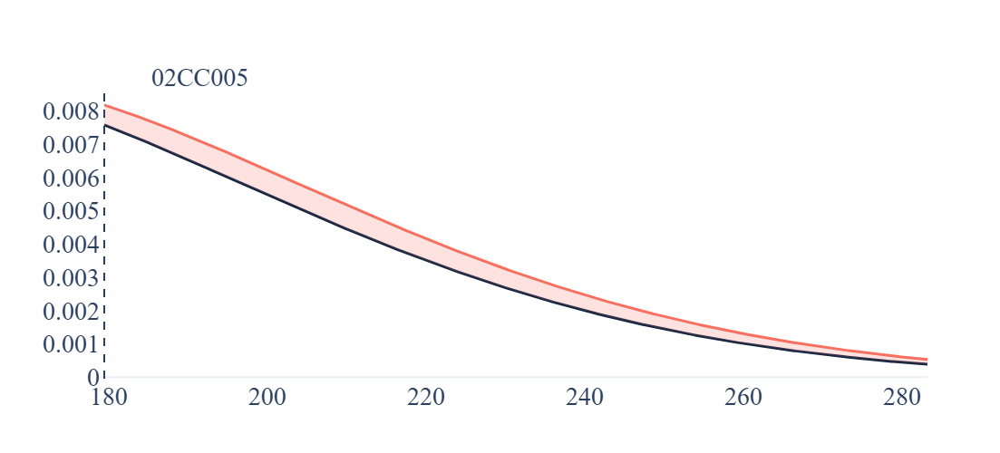

files for 02CE002 has been saved.


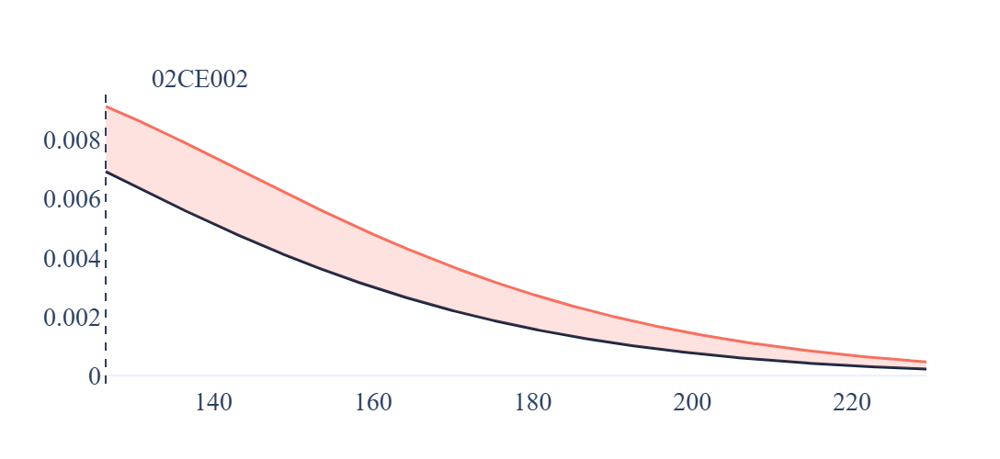

files for 02JC008 has been saved.


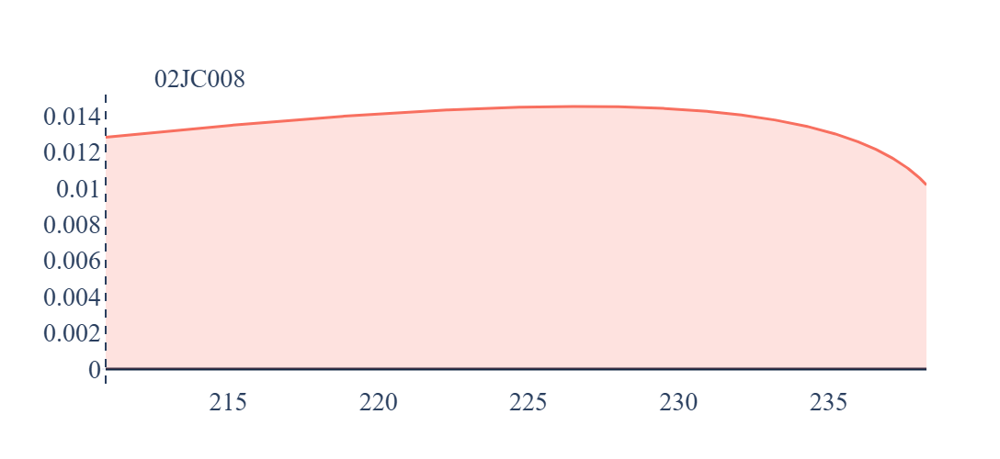

files for 04JD005 has been saved.


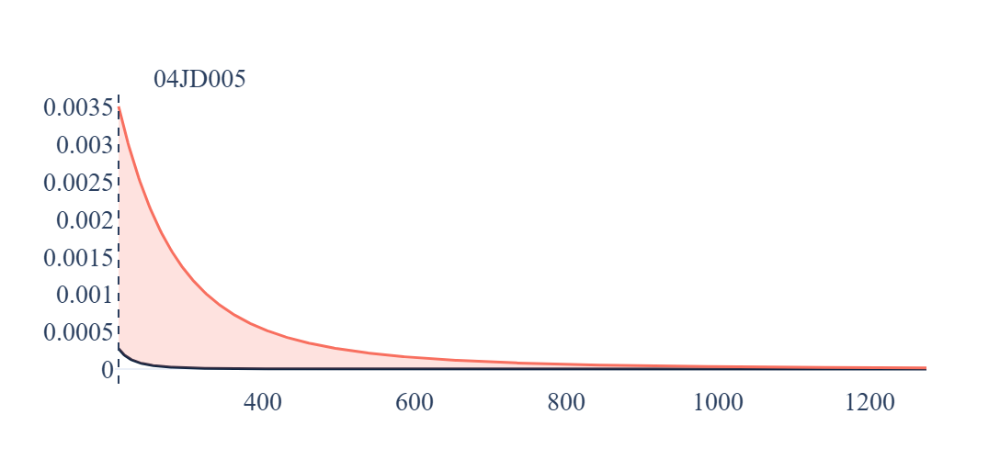

files for 04LM001 has been saved.


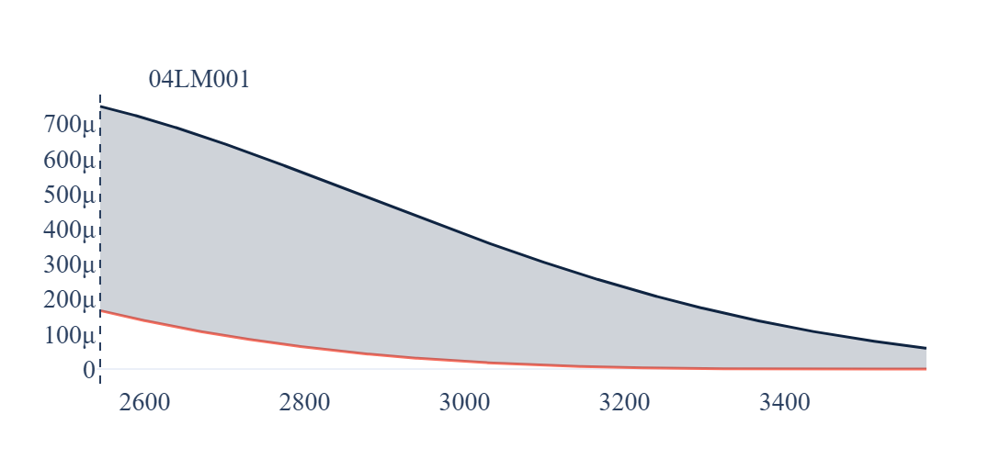

files for 04MF001 has been saved.


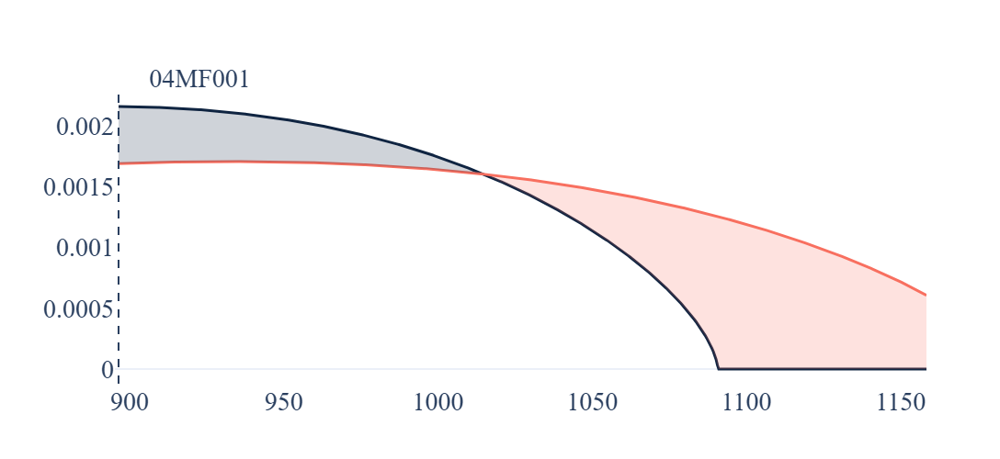

files for 05QD016 has been saved.


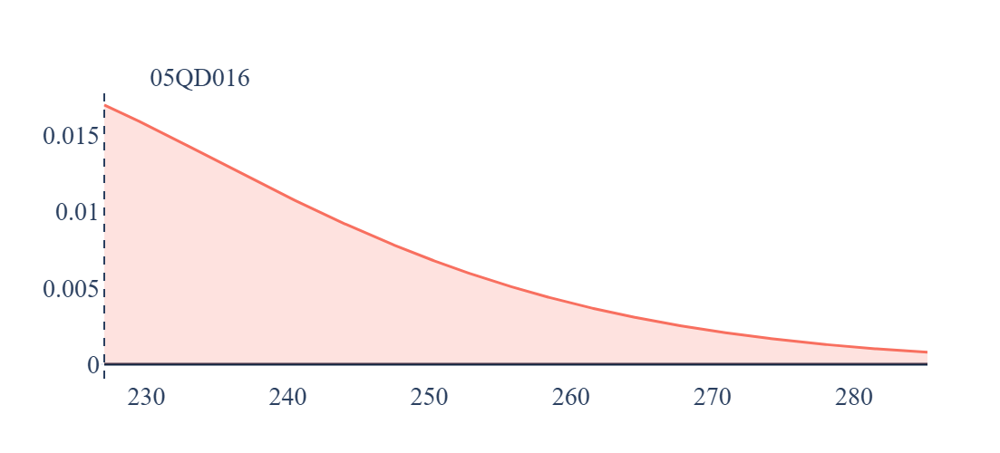

files for 05QE009 has been saved.


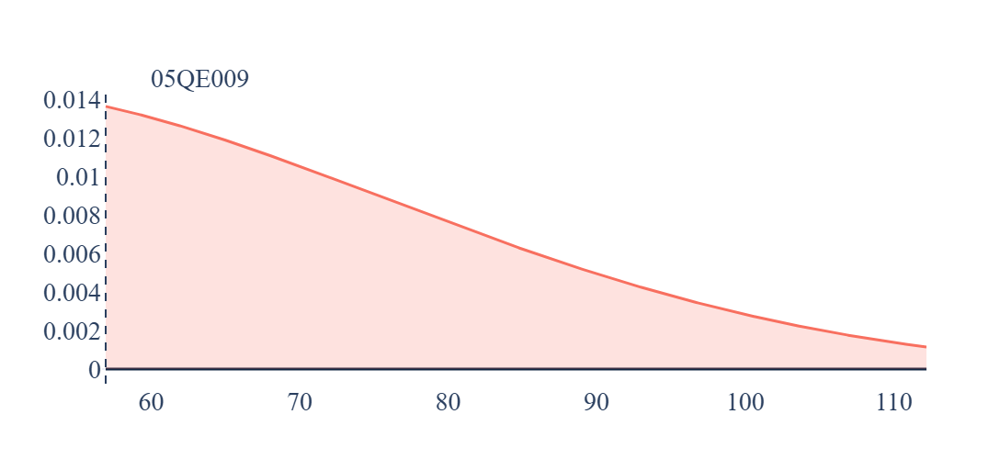

In [41]:
# ========== SETTINGS ==========
line_colour_min = "#102542"   # dark navy
line_colour_max = "#f87060"   # coral/red
fill_opacity = 0.2            # opacity for shaded difference

font_family = "Times New Roman"
title_font_size = 34
axis_font_size = 34
fig_width = 800
fig_height = 500
# ===============================

for station in station_list:
    # file for this station
    file_name_formula = f"Complete_mu_sigma_table_{station}.csv"
    mu_sig_df = pd.read_csv(file_name_formula)
    
    # min/max ECA rows
    row_min = mu_sig_df.loc[mu_sig_df["ECA"].idxmin()]
    row_max = mu_sig_df.loc[mu_sig_df["ECA"].idxmax()]
    
    # extract parameters
    mu_min, sig_min, xi_min_R = float(row_min["Mu_ECA"]), float(row_min["Sigma_ECA"]), float(row_min["Shape"])
    mu_max, sig_max, xi_max_R = float(row_max["Mu_ECA"]), float(row_max["Sigma_ECA"]), float(row_max["Shape"])
    c_min, c_max = -xi_min_R, -xi_max_R
    
    EPS = 1e-10
    c_min = 0.0 if abs(c_min) < EPS else c_min
    c_max = 0.0 if abs(c_max) < EPS else c_max
    
    rv_min = gev(c_min, loc=mu_min, scale=sig_min)
    rv_max = gev(c_max, loc=mu_max, scale=sig_max)

    # Flood threshold
    T0 = 2.6
    q0 = 1 - 1/T0
    x_lo = max(rv_min.ppf(q0), rv_max.ppf(q0))
    x_hi = max(rv_min.ppf(0.99), rv_max.ppf(0.99))
    x = np.linspace(x_lo, x_hi, 600)

    y_min = rv_min.pdf(x)
    y_max = rv_max.pdf(x)

    fig = go.Figure()

    # Main curves
    fig.add_trace(go.Scatter(x=x, y=y_min, mode="lines", name="Min ECA",
                             line=dict(color=line_colour_min, width = 3)))
    fig.add_trace(go.Scatter(x=x, y=y_max, mode="lines", name="Max ECA",
                             line=dict(color=line_colour_max, width = 3)))

    # Difference shading
    # region where max is higher
    fig.add_trace(go.Scatter(
        x=np.concatenate([x, x[::-1]]),
        y=np.concatenate([np.minimum(y_min, y_max), y_max[::-1]]),
        fill="toself",
        fillcolor=line_colour_max,
        opacity=fill_opacity,
        line=dict(width=0),
        hoverinfo="skip",
        showlegend=False
    ))
    # region where min is higher
    fig.add_trace(go.Scatter(
        x=np.concatenate([x, x[::-1]]),
        y=np.concatenate([np.minimum(y_min, y_max), y_min[::-1]]),
        fill="toself",
        fillcolor=line_colour_min,
        opacity=fill_opacity,
        line=dict(width=0),
        hoverinfo="skip",
        showlegend=False
    ))

    # Threshold line
    fig.add_vline(x=x_lo, line_dash="dash",
                  annotation_text=f"",
                  annotation_position="top left")

    # Layout
    fig.update_layout(
           title=dict(
            text=f"{station}",        # your station name
            font=dict(family=font_family, size=title_font_size),
            x=0.2,                    # center horizontally
            xanchor="center",         
            y=0.85,                   # closer to the plot (default ~0.98–1.0)
            yanchor="top"
        ),
        xaxis_title="",
        yaxis_title="",
        xaxis=dict(title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size), showgrid = False),
        yaxis=dict(title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size), showgrid = False),
        template="plotly_white",
        showlegend = False,
        # legend=dict(font=dict(family=font_family, size=axis_font_size)),
        width=fig_width,
        height=fig_height
    )

    fig.write_image(os.path.join(outdir_flood, f"flood_distribution_shift_{station}.svg"))
    fig.write_image(os.path.join(outdir_flood, f"flood_distribution_shift_{station}.png"), scale = 3)
    print(f"files for {station} has been saved.")
    fig.show()

files for 02AB006 has been saved.


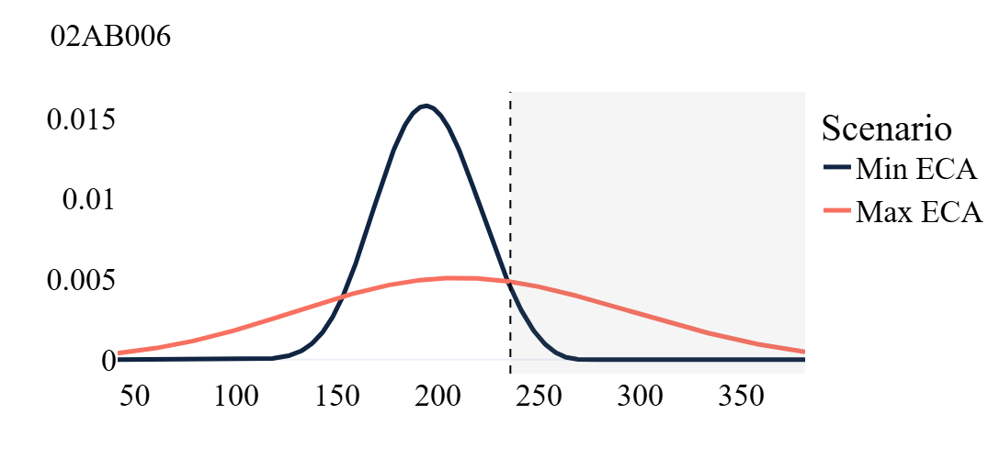

files for 02AC002 has been saved.


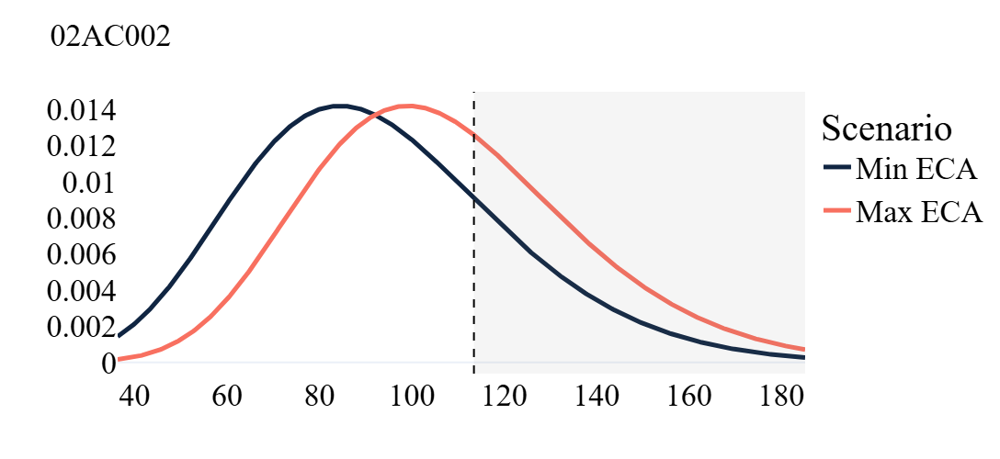

files for 02AD010 has been saved.


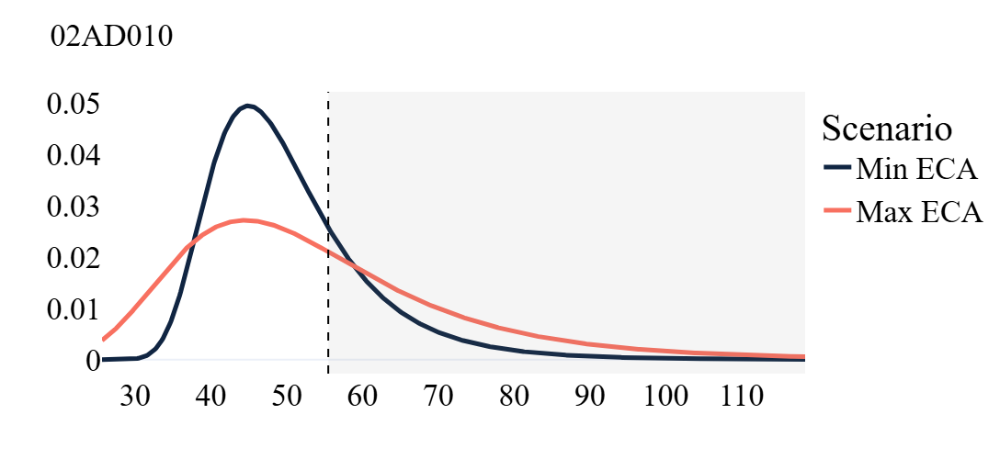

files for 02CC005 has been saved.


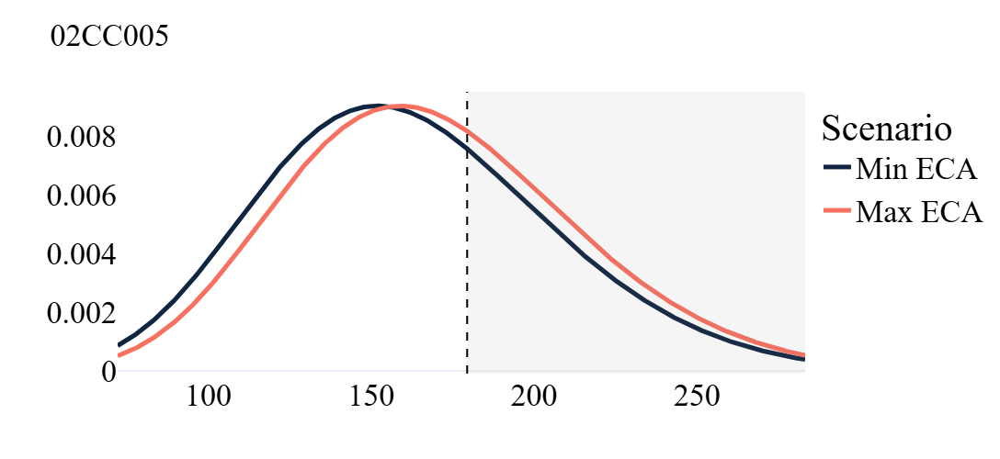

files for 02CE002 has been saved.


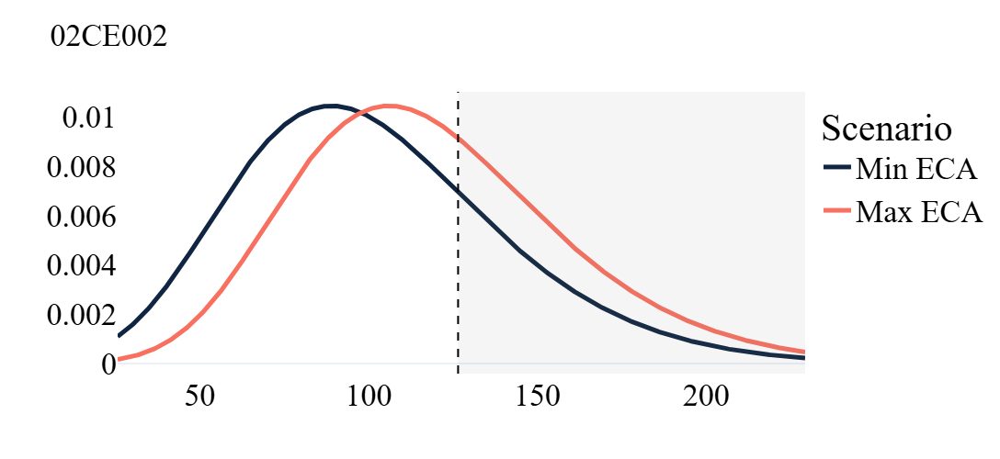

files for 02JC008 has been saved.


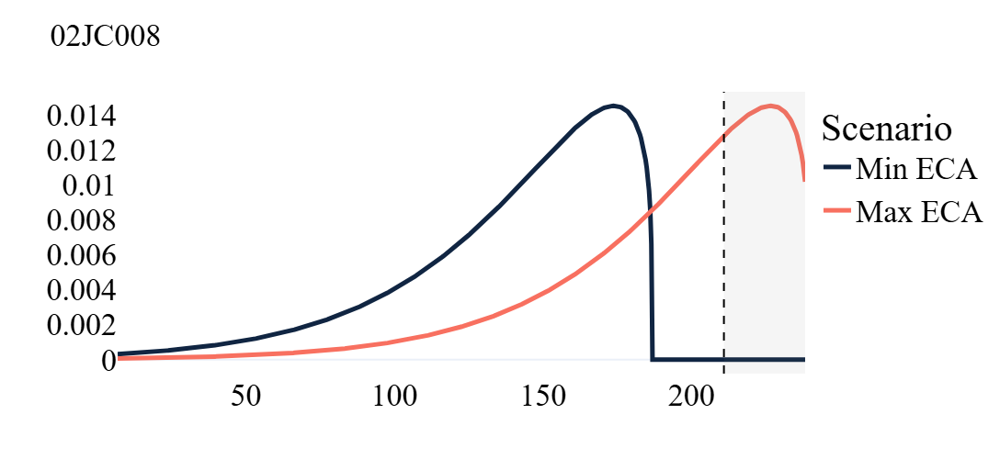

files for 04JD005 has been saved.


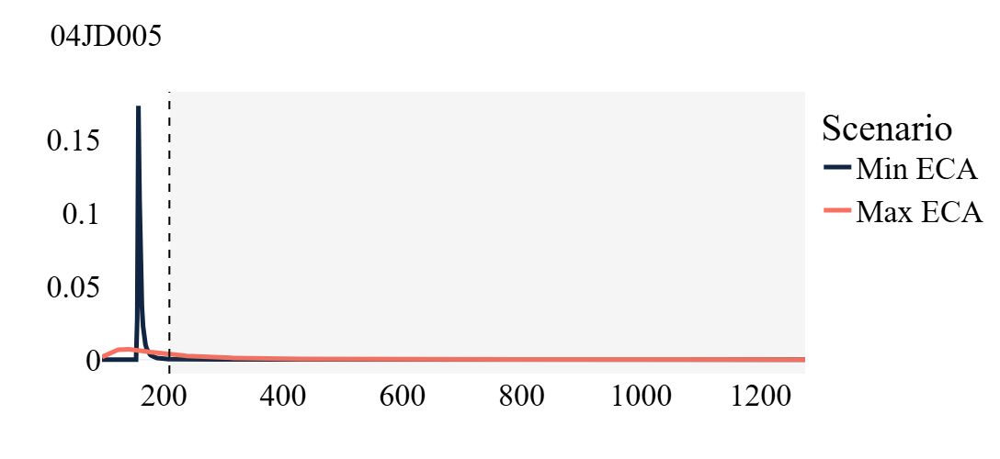

files for 04LM001 has been saved.


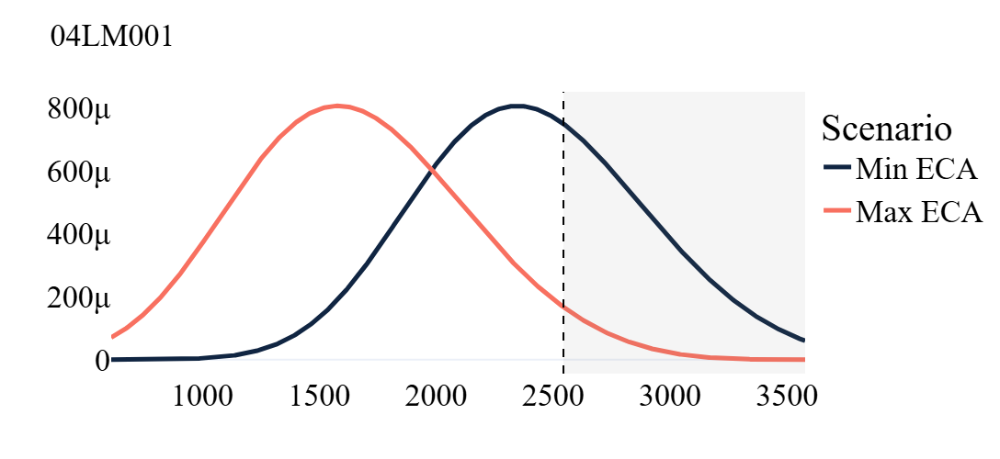

files for 04MF001 has been saved.


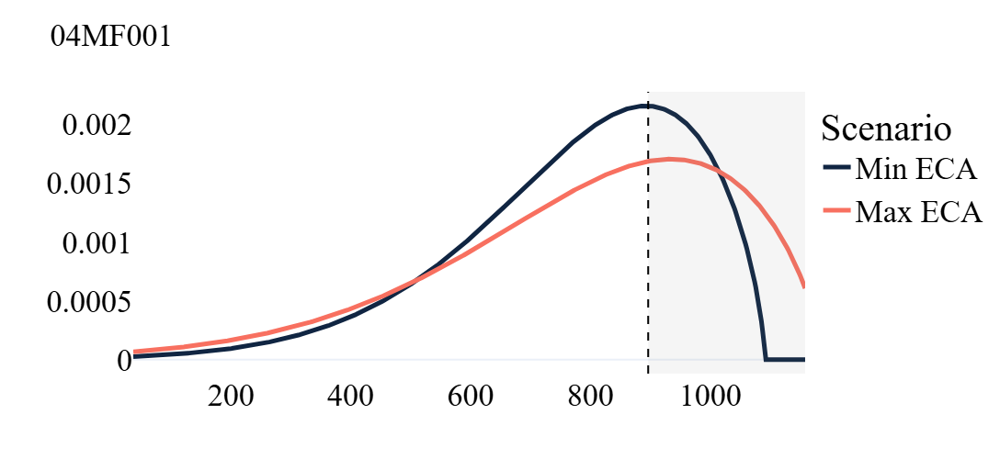

files for 05QD016 has been saved.


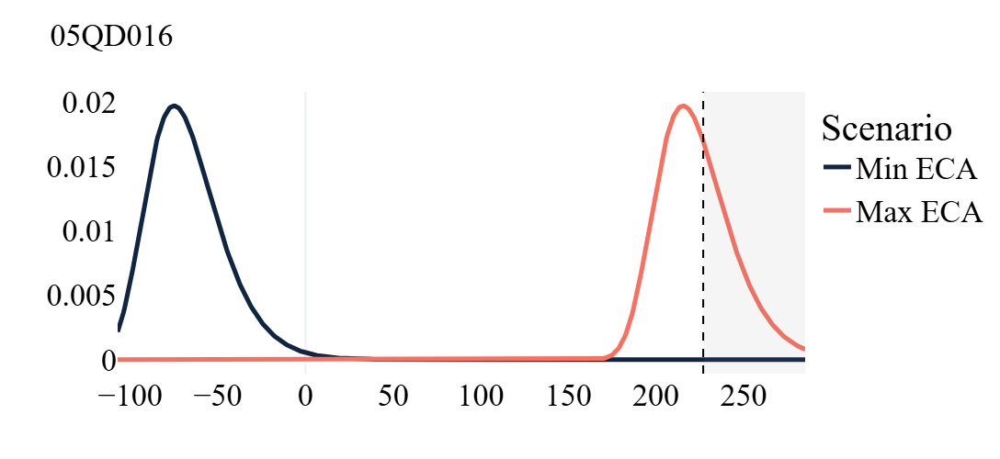

files for 05QE009 has been saved.


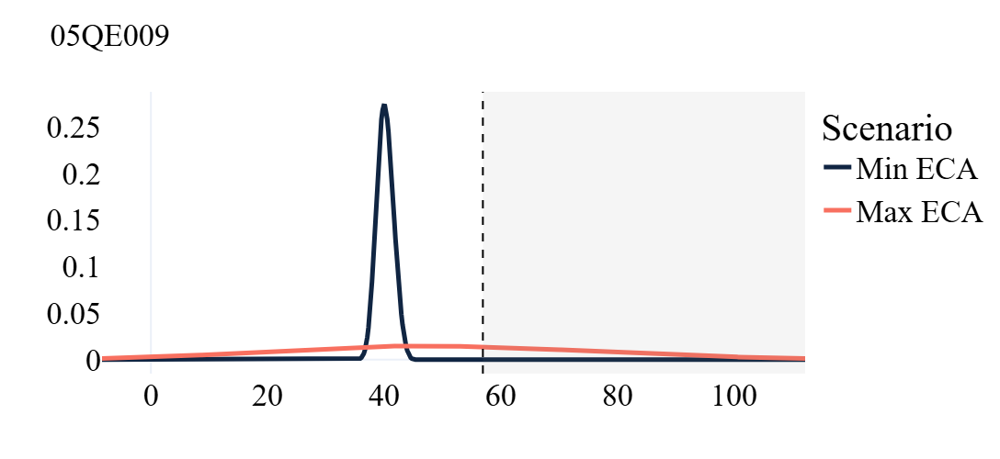

In [15]:
# ================= SETTINGS =================
line_colour_min = "#102542"   # navy (Min ECA)
line_colour_max = "#f87060"   # coral (Max ECA)
flood_fill_color = "gray"     # shaded flood region

font_family     = "Times New Roman"
title_font_size = 34
axis_font_size  = 34
legend_font_sz  = 34
fig_width       = 800
fig_height      = 500
# ============================================

T0 = 2.6  # return period for defining flood events
q0 = 1 - 1/float(T0)

for station in station_list:
    # Load file
    file_name_formula = f"Complete_mu_sigma_table_{station}.csv"
    df = pd.read_csv(file_name_formula)

    # Select rows with min/max ECA
    row_min = df.loc[df["ECA"].idxmin()]
    row_max = df.loc[df["ECA"].idxmax()]

    # Extract parameters (R → SciPy convention: c = -xi)
    mu_min, sig_min, xi_min_R = float(row_min["Mu_ECA"]), float(row_min["Sigma_ECA"]), float(row_min["Shape"])
    mu_max, sig_max, xi_max_R = float(row_max["Mu_ECA"]), float(row_max["Sigma_ECA"]), float(row_max["Shape"])
    c_min, c_max = -xi_min_R, -xi_max_R

    EPS = 1e-10
    c_min = 0.0 if abs(c_min) < EPS else c_min
    c_max = 0.0 if abs(c_max) < EPS else c_max

    rv_min = gev(c_min, loc=mu_min, scale=sig_min)
    rv_max = gev(c_max, loc=mu_max, scale=sig_max)

    # Stricter threshold
    xT_min = rv_min.ppf(q0)
    xT_max = rv_max.ppf(q0)
    xT_both = max(xT_min, xT_max)

    # Safe full-range bounds
    x_lo = min(rv_min.ppf(0.01), rv_max.ppf(0.01))
    x_hi = max(rv_min.ppf(0.99), rv_max.ppf(0.99))
    x = np.linspace(x_lo, x_hi, 600)

    # Evaluate PDFs
    y_min = rv_min.pdf(x)
    y_max = rv_max.pdf(x)

    # Build figure
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x, y=y_min, mode="lines", name="Min ECA",
                             line=dict(color=line_colour_min, width = 5)))
    fig.add_trace(go.Scatter(x=x, y=y_max, mode="lines", name="Max ECA",
                             line=dict(color=line_colour_max, width = 5)))

    # Shade flood region (>= stricter threshold)
    fig.add_vrect(x0=xT_both, x1=x_hi, fillcolor=flood_fill_color, opacity=0.08, line_width=0)

    # Vertical line at stricter threshold
    fig.add_vline(x=xT_both, line_dash="dash", line_color="black")

    # Annotate threshold
    y_annot = max(np.nanmax(y_min), np.nanmax(y_max)) * 0.95
    fig.add_annotation(
        x=xT_both, y=y_annot,
        text=f"",
        showarrow=False,
        font=dict(family=font_family, size=axis_font_size, color="black")
    )

    # Layout & styling
    fig.update_layout(
        title=f"{station}",
        title_font=dict(family=font_family, size=title_font_size, color = "black"),
        xaxis_title="",
        yaxis_title="",
        xaxis=dict(
            title_font=dict(family=font_family, size=axis_font_size),
            tickfont=dict(family=font_family, size=axis_font_size, color = "black"),
            #showline =True, linecolor = "grey", linewidth = 1,
            showgrid = False
        ),
        yaxis=dict(
            title_font=dict(family=font_family, size=axis_font_size),
            tickfont=dict(family=font_family, size=axis_font_size, color = "black"),
            #showline =True, linecolor = "grey", linewidth = 1,
            showgrid = False
        ),
        legend=dict(title="Scenario", font=dict(family=font_family, size=legend_font_sz, color = "black")),
        template="plotly_white",
        width=fig_width,
        height=fig_height
    )

    fig.write_image(os.path.join(outdir_whole, f"flood_distribution_shift_{station}.svg"))
    fig.write_image(os.path.join(outdir_whole, f"flood_distribution_shift_{station}.png"), scale = 3)
    print(f"files for {station} has been saved.")

    fig.show()

#### Prep testing code

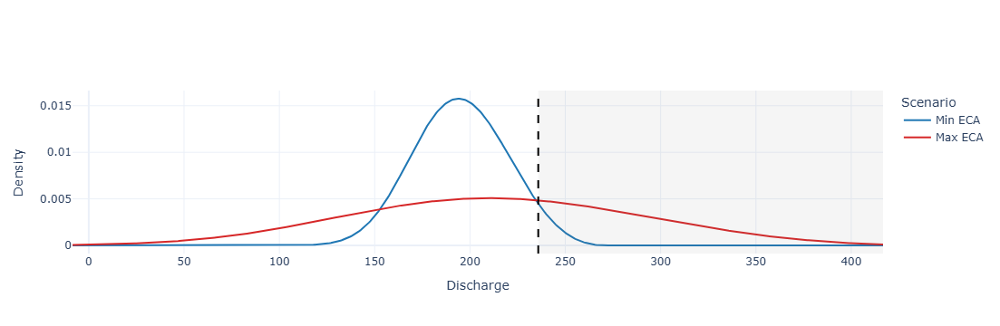

In [67]:
T0 = 2.6  # change to 5, 10, ... as needed
q0 = 1 - 1/float(T0)

# Thresholds for each scenario
xT_min = rv_min.ppf(q0)
xT_max = rv_max.ppf(q0)
xT_both = max(xT_min, xT_max)  # stricter common threshold

# Safe full-range bounds via quantiles
x_lo = min(rv_min.ppf(0.001), rv_max.ppf(0.001))
x_hi = max(rv_min.ppf(0.999), rv_max.ppf(0.999))
x = np.linspace(x_lo, x_hi, 600)

# Evaluate PDFs
y_min = rv_min.pdf(x)
y_max = rv_max.pdf(x)

fig = go.Figure()

# Curves
fig.add_trace(go.Scatter(x=x, y=y_min, mode="lines", name="Min ECA", line=dict(color="#1f77b4")))
fig.add_trace(go.Scatter(x=x, y=y_max, mode="lines", name="Max ECA", line=dict(color="#d62728")))

# Shade flood region (x >= common threshold)
fig.add_vrect(x0=xT_both, x1=x_hi, fillcolor="gray", opacity=0.08, line_width=0)

# Single vertical line at common threshold
fig.add_vline(x=xT_both, line_dash="dash", line_color="black")

# Annotate threshold
y_annot = max(np.nanmax(y_min), np.nanmax(y_max)) * 0.95
fig.add_annotation(
    x=xT_both, y=y_annot,
    text=f"",
    showarrow=False, font=dict(color="black")
)

fig.update_layout(
    title="",
    xaxis_title="Discharge",
    yaxis_title="Density",
    template="plotly_white",
    legend=dict(title="Scenario")
)

fig.show()

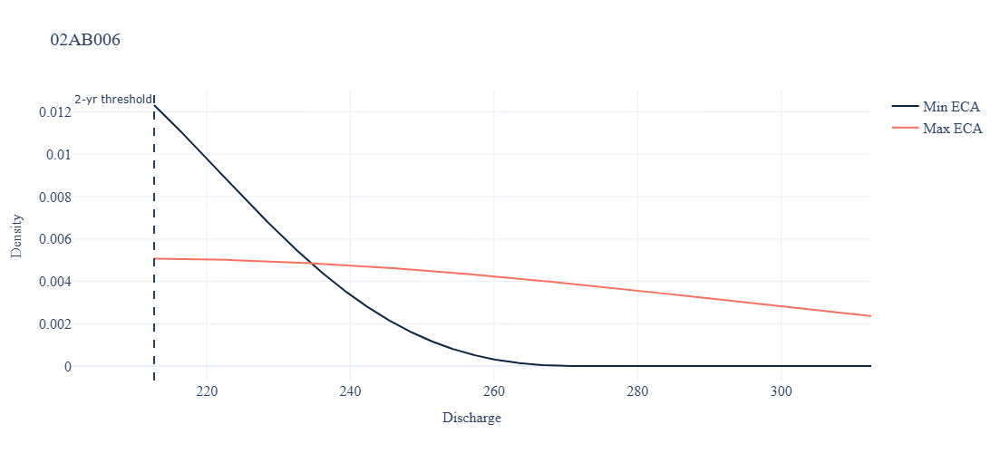

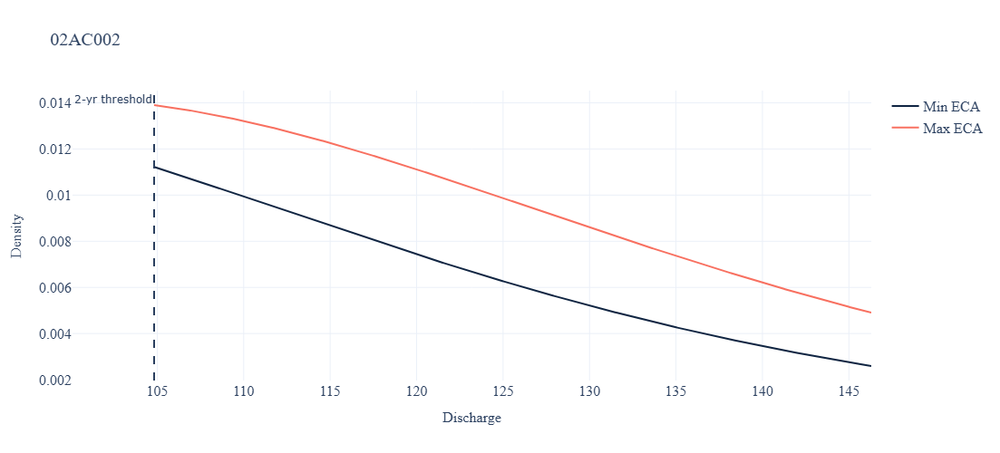

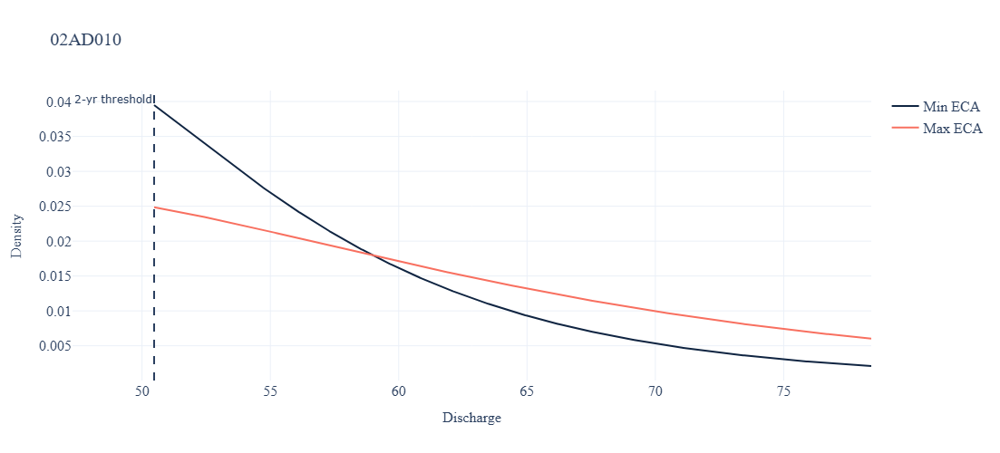

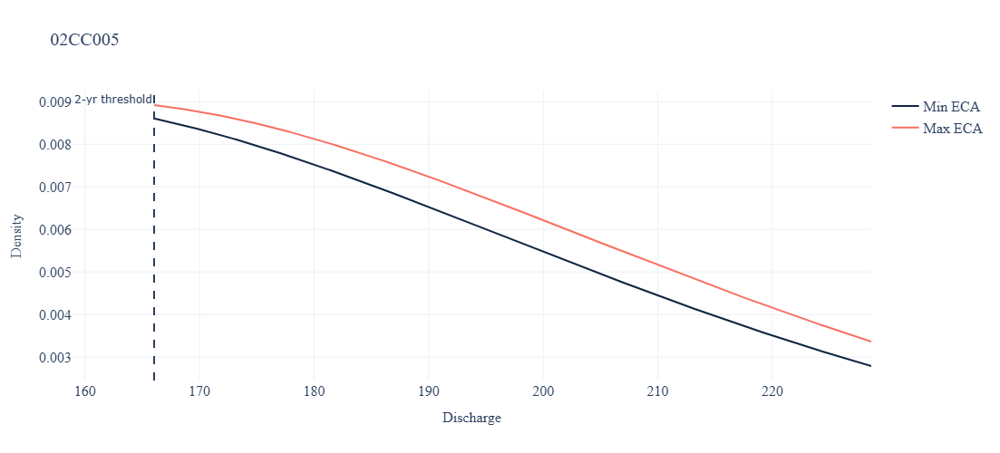

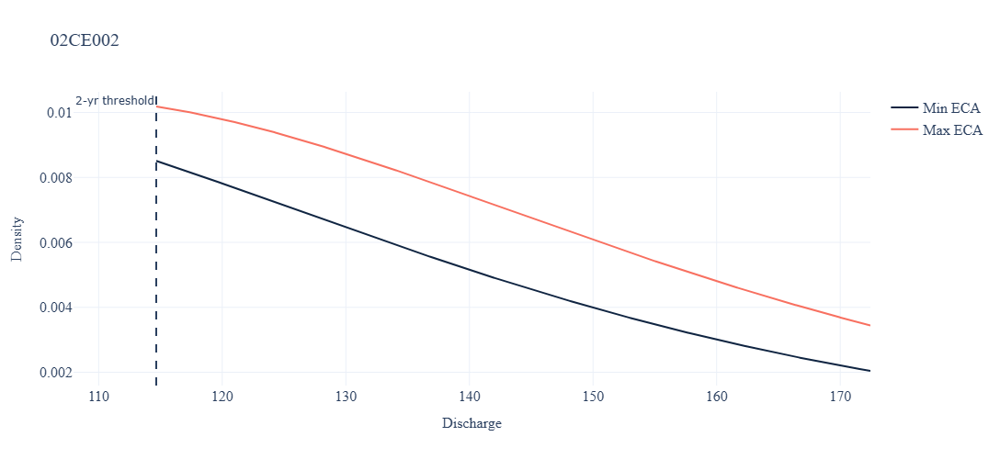

...

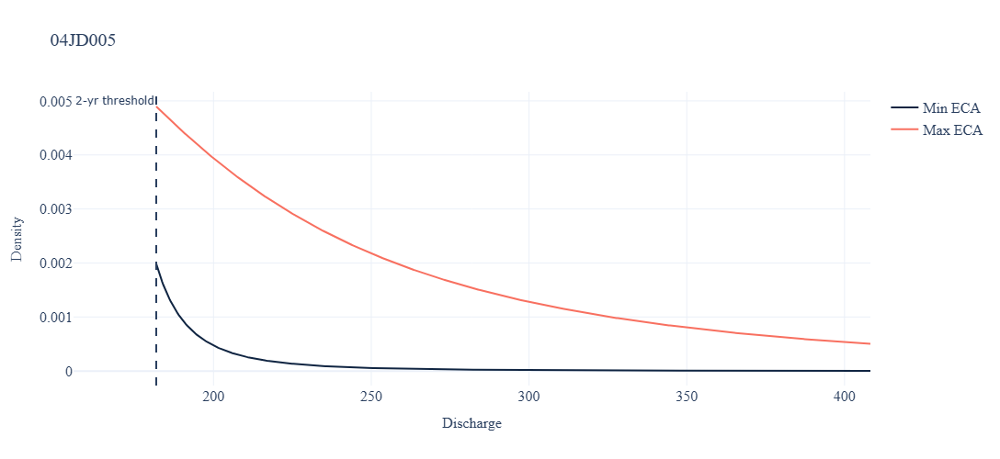

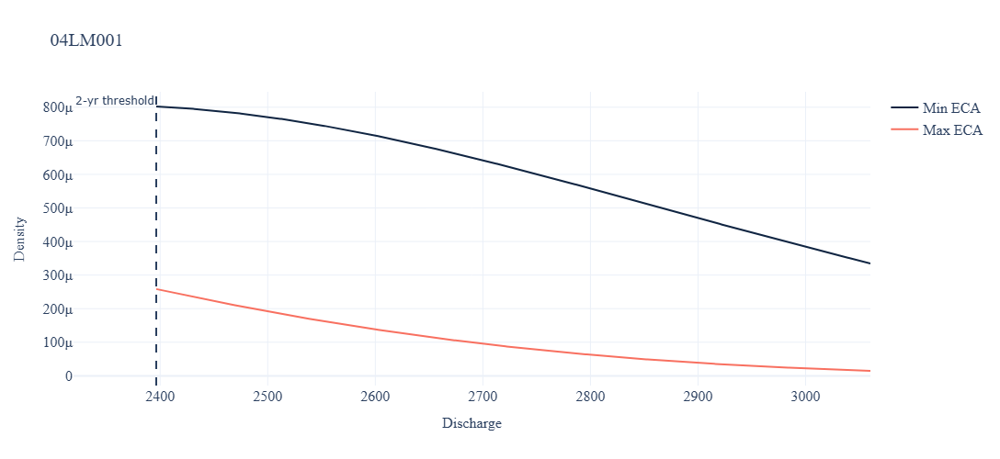

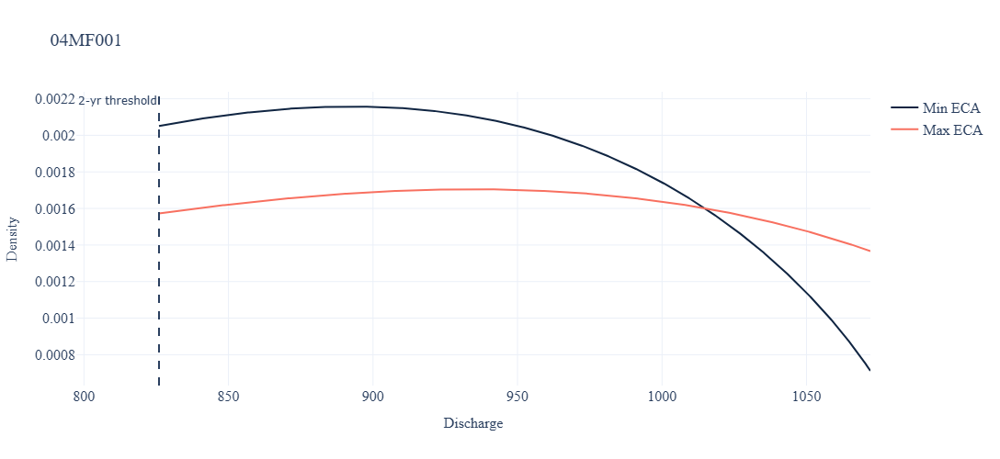

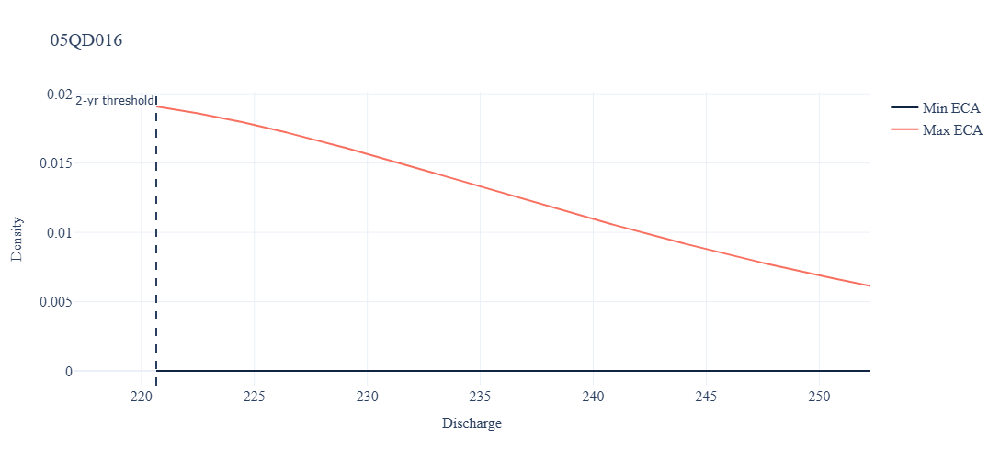

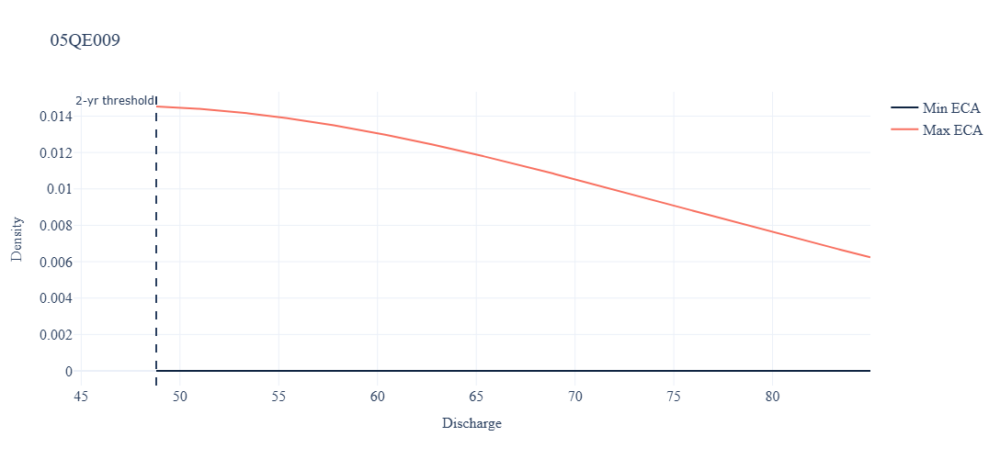

In [68]:
# ================= SETTINGS =================
line_colour_min = "#102542"   # dark blue
line_colour_max = "#f87060"   # coral/red

font_family = "Times New Roman"
title_font_size = 20          # size for title text
axis_font_size = 16           # size for x/y axis labels
fig_width = 800               # figure width in px
fig_height = 500              # figure height in px
# ============================================

for station in station_list:
    # file for this station
    file_name_formula = f"Complete_mu_sigma_table_{station}.csv"
    mu_sig_df = pd.read_csv(file_name_formula)
    
    # select rows with min/max ECA
    i_min = mu_sig_df["ECA"].idxmin()
    i_max = mu_sig_df["ECA"].idxmax()
    row_min = mu_sig_df.loc[i_min]
    row_max = mu_sig_df.loc[i_max]
    
    # extract parameters for min/max ECA
    mu_min_eca   = float(row_min["Mu_ECA"])
    sig_min_eca  = float(row_min["Sigma_ECA"])
    xi_min_R     = float(row_min["Shape"])
    c_min_eca    = -xi_min_R   
    
    mu_max_eca   = float(row_max["Mu_ECA"])
    sig_max_eca  = float(row_max["Sigma_ECA"])
    xi_max_R     = float(row_max["Shape"])
    c_max_eca    = -xi_max_R 
    
    # numerical stability near Gumbel case
    EPS = 1e-10
    c_min_eca = 0.0 if abs(c_min_eca) < EPS else c_min_eca
    c_max_eca = 0.0 if abs(c_max_eca) < EPS else c_max_eca
    
    # frozen distributions
    rv_min = gev(c_min_eca, loc=mu_min_eca, scale=sig_min_eca) 
    rv_max = gev(c_max_eca, loc=mu_max_eca, scale=sig_max_eca)

    # flood threshold
    T0 = 2
    q0 = 1 - 1/T0
    x2_min = rv_min.ppf(q0)
    x2_max = rv_max.ppf(q0)
    x_lo = max(x2_min, x2_max)
    
    # upper bound = 90th percentile (adjustable)
    x_hi = max(rv_min.ppf(0.9), rv_max.ppf(0.9))
    x = np.linspace(x_lo, x_hi, 600)
    
    # build figure
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x, y=rv_min.pdf(x), mode="lines", 
                             name="Min ECA", line=dict(color=line_colour_min)))
    fig.add_trace(go.Scatter(x=x, y=rv_max.pdf(x), mode="lines", 
                             name="Max ECA", line=dict(color=line_colour_max)))
    
    fig.add_vline(x=x_lo, line_dash="dash",
                  annotation_text=f"{T0}-yr threshold",
                  annotation_position="top left")
    
    fig.update_layout(
        title=f"{station}",
        title_font=dict(family=font_family, size=title_font_size),
        xaxis_title="Discharge",
        yaxis_title="Density",
        xaxis=dict(title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size)),
        yaxis=dict(title_font=dict(family=font_family, size=axis_font_size),
                   tickfont=dict(family=font_family, size=axis_font_size)),
        template="plotly_white",
        legend=dict(font=dict(family=font_family, size=axis_font_size)),
        width=fig_width,
        height=fig_height
    )
    
    fig.show()

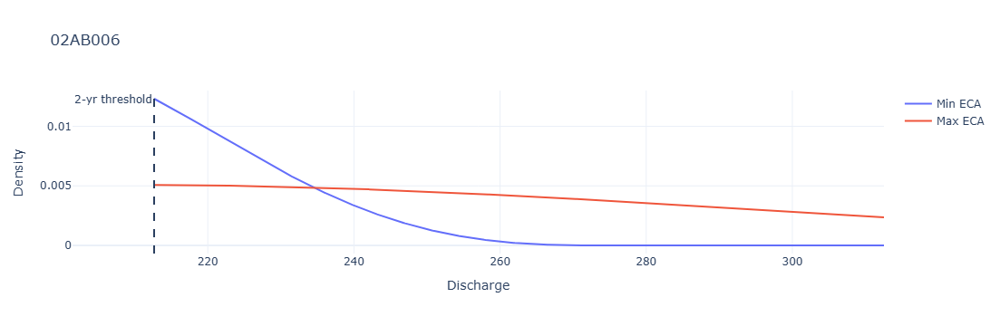

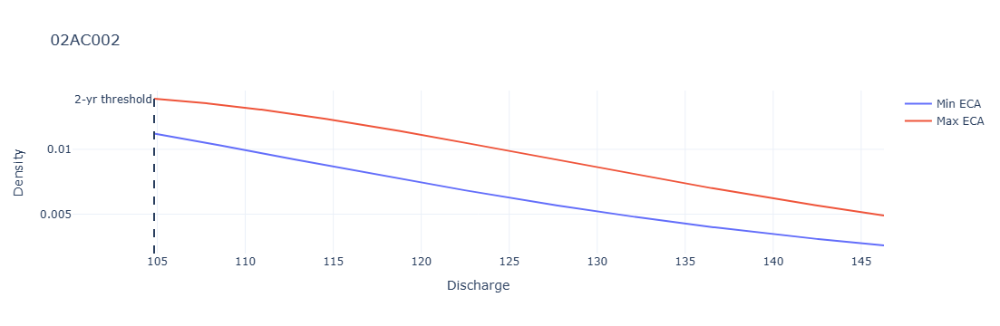

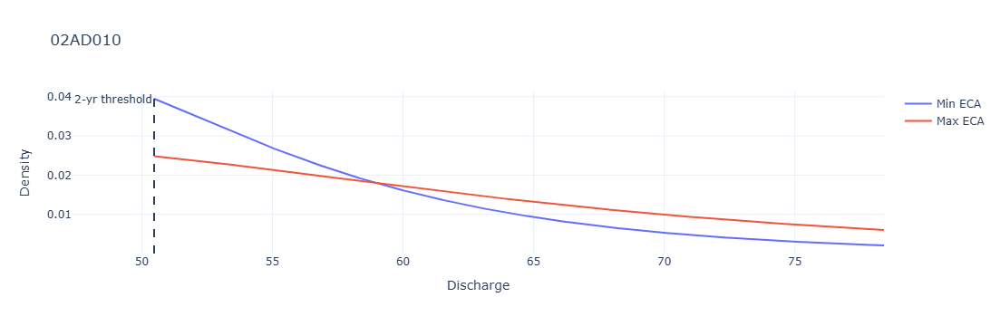

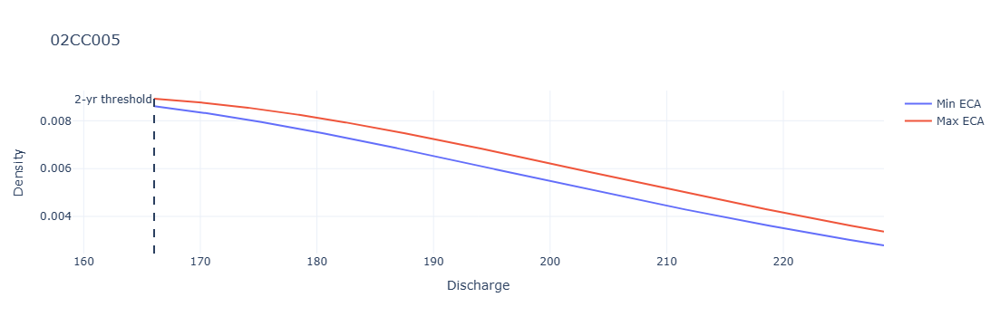

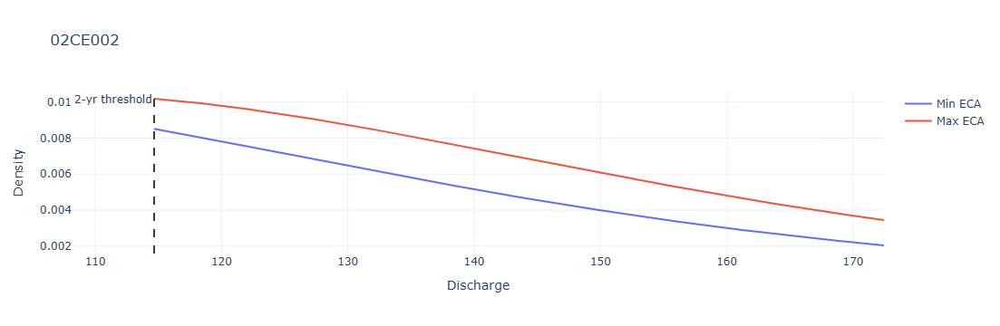

...

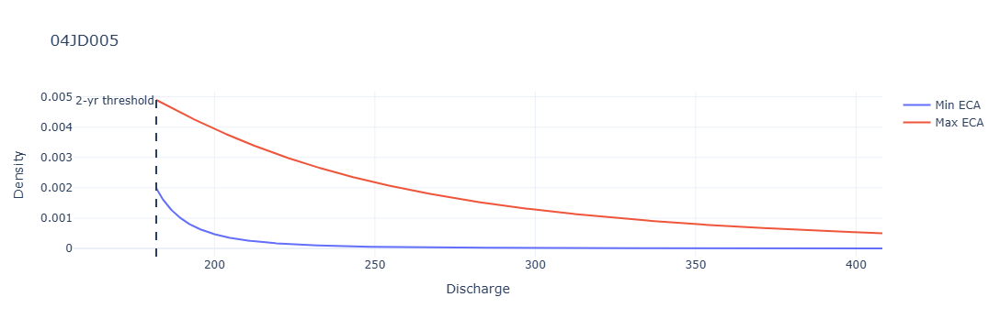

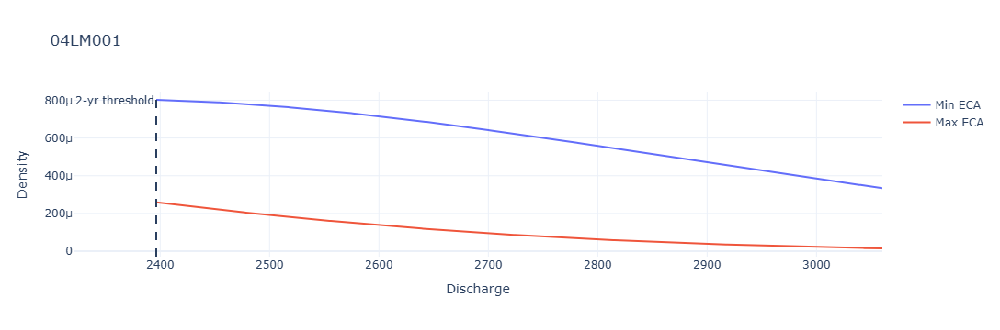

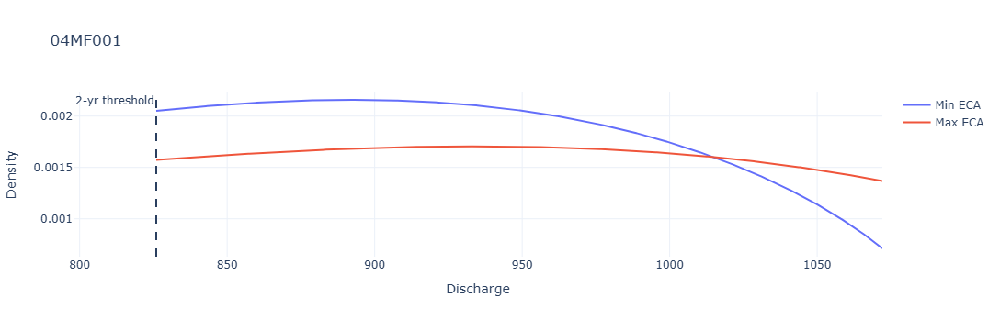

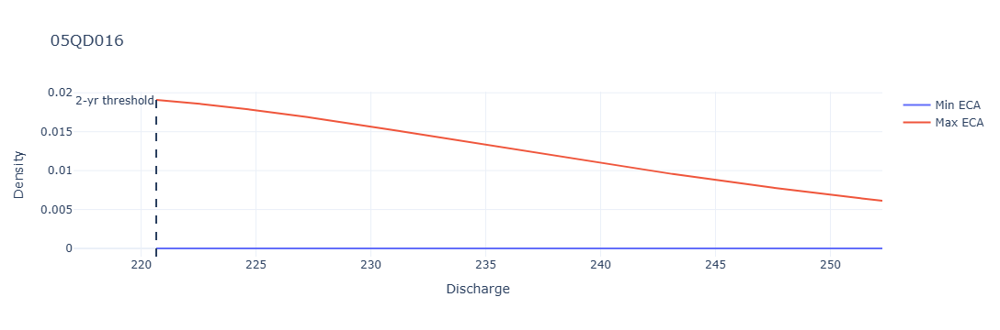

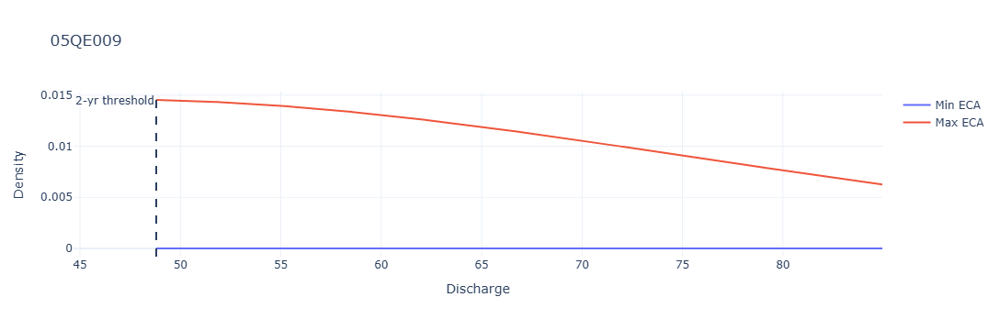

In [65]:
# settings:
line_colour_min = "#102542"

line_colour_max = "#f87060"

for station in station_list:
    # making a formula for finding the file
    file_name_formula = f"Complete_mu_sigma_table_{station}.csv"
    
    # loading the file corresponding to the station
    mu_sig_df = pd.read_csv(file_name_formula)
    
    # selecting rows with min max eca
    i_min = mu_sig_df["ECA"].idxmin()
    i_max = mu_sig_df["ECA"].idxmax()
    row_min = mu_sig_df.loc[i_min]
    row_max = mu_sig_df.loc[i_max]
    
    # extracting parameters for highest and lowest eca
    # min
    mu_min_eca   = float(row_min["Mu_ECA"])
    sig_min_eca  = float(row_min["Sigma_ECA"])
    xi_min_R     = float(row_min["Shape"])
    c_min_eca    = -xi_min_R   
    
    # MAX
    mu_max_eca   = float(row_max["Mu_ECA"])
    sig_max_eca  = float(row_max["Sigma_ECA"])
    xi_max_R     = float(row_max["Shape"])
    c_max_eca    = -xi_max_R 
    
    # Treat near-Gumbel shapes as exactly 0 for numerical stability
    EPS = 1e-10
    c_min_eca = 0.0 if abs(c_min_eca) < EPS else c_min_eca
    c_max_eca = 0.0 if abs(c_max_eca) < EPS else c_max_eca
    
    # Build SciPy GEV random object for the two cases: this is the object we can get pdf, cdf, 
        # this line is saying: 
        # Create a SciPy object representing the GEV distribution with those parameters
    rv_min = gev(c_min_eca, loc=mu_min_eca, scale=sig_min_eca) 
    rv_max = gev(c_max_eca, loc=mu_max_eca, scale=sig_max_eca)

    T0 = 2 # return period for defining flood events
    q0 = 1 - 1/T0
    
    # lower bound = 2-yr return level; take the larger so both curves are truly in the flood region
    x2_min = rv_min.ppf(q0)   # 1 - 1/2
    x2_max = rv_max.ppf(q0)
    x_lo = max(x2_min, x2_max)
    
    # upper bound: a high quantile
    x_hi = max(rv_min.ppf(0.9), rv_max.ppf(0.9))
    x = np.linspace(x_lo, x_hi, 600)
    
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x, y=rv_min.pdf(x), mode="lines", name="Min ECA"))
    fig.add_trace(go.Scatter(x=x, y=rv_max.pdf(x), mode="lines", name="Max ECA"))
    fig.add_vline(x=x_lo, line_dash="dash", annotation_text="2-yr threshold", annotation_position="top left")
    fig.update_layout(title=f"{station}", xaxis_title="Discharge", yaxis_title="Density", template="plotly_white")
    fig.show()



In [66]:
station = "02AB006" # coding test station

# making a formula for finding the file
file_name_formula = f"Complete_mu_sigma_table_{station}.csv"

# loading the file corresponding to the station
mu_sig_df = pd.read_csv(file_name_formula)

# selecting rows with min max eca
i_min = mu_sig_df["ECA"].idxmin()
i_max = mu_sig_df["ECA"].idxmax()
row_min = mu_sig_df.loc[i_min]
row_max = mu_sig_df.loc[i_max]

# extracting parameters for highest and lowest eca
# min
mu_min_eca   = float(row_min["Mu_ECA"])
sig_min_eca  = float(row_min["Sigma_ECA"])
xi_min_R     = float(row_min["Shape"])
c_min_eca    = -xi_min_R   

# MAX
mu_max_eca   = float(row_max["Mu_ECA"])
sig_max_eca  = float(row_max["Sigma_ECA"])
xi_max_R     = float(row_max["Shape"])
c_max_eca    = -xi_max_R 

# Treat near-Gumbel shapes as exactly 0 for numerical stability
EPS = 1e-10
c_min_eca = 0.0 if abs(c_min_eca) < EPS else c_min_eca
c_max_eca = 0.0 if abs(c_max_eca) < EPS else c_max_eca

# Build SciPy GEV random object for the two cases: this is the object we can get pdf, cdf, 
    # this line is saying: 
    # Create a SciPy object representing the GEV distribution with those parameters
rv_min = gev(c_min_eca, loc=mu_min_eca, scale=sig_min_eca) 
rv_max = gev(c_max_eca, loc=mu_max_eca, scale=sig_max_eca)


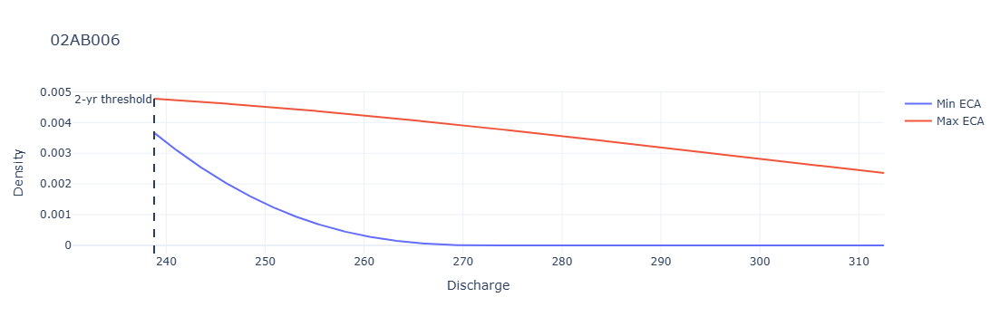

In [62]:
T0 = 2.7 # return period for defining flood events
q0 = 1 - 1/T0

# lower bound = 2-yr return level; take the larger so both curves are truly in the flood region
x2_min = rv_min.ppf(q0)   # 1 - 1/2
x2_max = rv_max.ppf(q0)
x_lo = max(x2_min, x2_max)

# upper bound: a high quantile
x_hi = max(rv_min.ppf(0.9), rv_max.ppf(0.9))
x = np.linspace(x_lo, x_hi, 600)

fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=rv_min.pdf(x), mode="lines", name="Min ECA"))
fig.add_trace(go.Scatter(x=x, y=rv_max.pdf(x), mode="lines", name="Max ECA"))
fig.add_vline(x=x_lo, line_dash="dash", annotation_text="2-yr threshold", annotation_position="top left")
fig.update_layout(title=f"{station}", xaxis_title="Discharge", yaxis_title="Density", template="plotly_white")
fig.show()

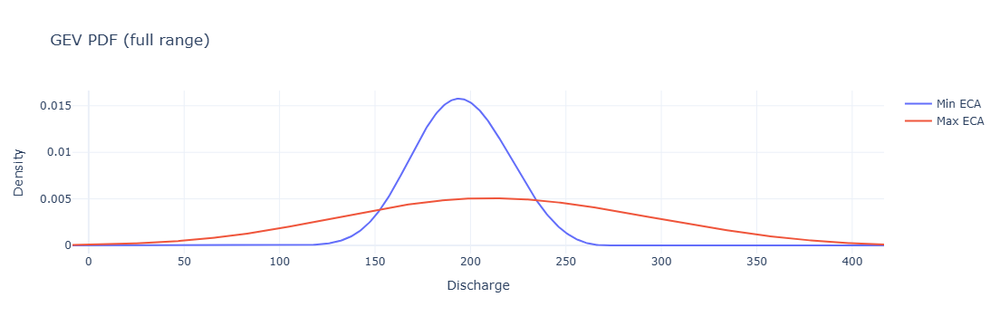

In [31]:
# choose safe bounds via quantiles
x_lo = min(rv_min.ppf(0.001), rv_max.ppf(0.001))
x_hi = max(rv_min.ppf(0.999), rv_max.ppf(0.999))
x = np.linspace(x_lo, x_hi, 600)

fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=rv_min.pdf(x), mode="lines", name="Min ECA"))
fig.add_trace(go.Scatter(x=x, y=rv_max.pdf(x), mode="lines", name="Max ECA"))
fig.update_layout(title="GEV PDF (full range)", xaxis_title="Discharge", yaxis_title="Density", template="plotly_white")
fig.show()

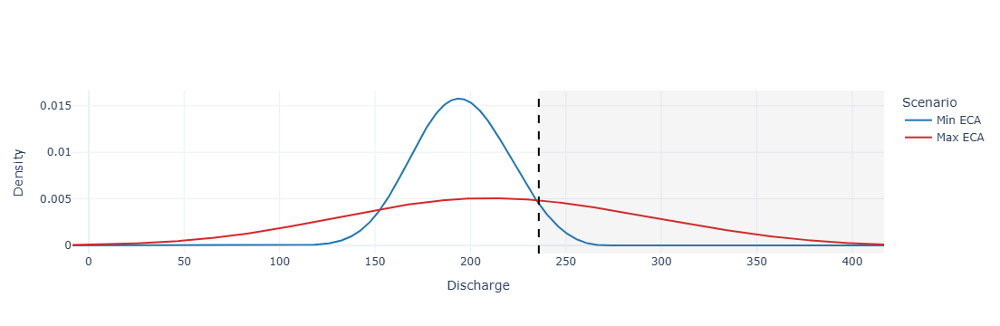

In [41]:
T0 = 2.6  # change to 5, 10, ... as needed
q0 = 1 - 1/float(T0)

# Thresholds for each scenario
xT_min = rv_min.ppf(q0)
xT_max = rv_max.ppf(q0)
xT_both = max(xT_min, xT_max)  # stricter common threshold

# Safe full-range bounds via quantiles
x_lo = min(rv_min.ppf(0.001), rv_max.ppf(0.001))
x_hi = max(rv_min.ppf(0.999), rv_max.ppf(0.999))
x = np.linspace(x_lo, x_hi, 600)

# Evaluate PDFs
y_min = rv_min.pdf(x)
y_max = rv_max.pdf(x)

fig = go.Figure()

# Curves
fig.add_trace(go.Scatter(x=x, y=y_min, mode="lines", name="Min ECA", line=dict(color="#1f77b4")))
fig.add_trace(go.Scatter(x=x, y=y_max, mode="lines", name="Max ECA", line=dict(color="#d62728")))

# Shade flood region (x >= common threshold)
fig.add_vrect(x0=xT_both, x1=x_hi, fillcolor="gray", opacity=0.08, line_width=0)

# Single vertical line at common threshold
fig.add_vline(x=xT_both, line_dash="dash", line_color="black")

# Annotate threshold
y_annot = max(np.nanmax(y_min), np.nanmax(y_max)) * 0.95
fig.add_annotation(
    x=xT_both, y=y_annot,
    text=f"",
    showarrow=False, font=dict(color="black")
)

fig.update_layout(
    title="",
    xaxis_title="Discharge",
    yaxis_title="Density",
    template="plotly_white",
    legend=dict(title="Scenario")
)

fig.show()

In [17]:
mu_sig_df

,Year,ECA,Mu_ECA,Sigma_ECA,Shape
0,1985,0.709215,186.266252,24.398688,-0.282051
1,1986,1.414290,186.266252,26.479240,-0.282051
2,1987,2.117366,186.266252,28.553891,-0.282051
3,1988,2.929261,186.266252,30.949652,-0.282051
4,1989,3.451827,186.266252,32.491650,-0.282051
5,1990,4.149322,186.266252,34.549835,-0.282051
6,1991,5.218857,186.266252,37.705844,-0.282051
7,1992,5.657440,186.266252,39.000025,-0.282051
8,1993,5.983888,186.266252,39.963315,-0.282051
9,1994,6.471207,186.266252,41.401307,-0.282051


## Quantification

In [25]:
# First RUN get dataframe function up
quant_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Processing\R Processing\Final_Detection_Attribution_Quantification\Outputs\Quantification"
# quant_df = get_dataframe(station, quant_dir)
quant_out_dir = r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification"

In [26]:
def get_dataframe(station_id, directory):
    """
    Given a station ID and directory, finds and returns the corresponding dataframe.
    """
    pattern = re.compile(rf'_(\d{{2}}[A-Z]{{2}}\d{{3}})')  # Pattern to match station ID
    
    for filename in os.listdir(directory):
        match = pattern.search(filename)
        if match and match.group(1) == station_id:
            file_path = os.path.join(directory, filename)
            return pd.read_csv(file_path)
    
    return None  # Return None if no matching file is found

In [47]:
station = "02AB006"
quant_df = get_dataframe(station, quant_dir)

In [7]:
quant_df

,Station_ID,Return_Period,Exceedance_Probability,Valid_ECA_Min,Valid_ECA_Max,Discharge_ECA_Min,Discharge_ECA_Max,ECA_Flood_Risk_Increase_Percentage
0,05QD016,1.5,0.666667,0.069875,14.017095,4.144871,145.963427,3421.543291
1,05QD016,2.0,0.500000,0.069875,14.017095,16.900003,151.606021,797.076909
2,05QD016,5.0,0.200000,0.069875,14.017095,31.909875,158.246064,395.915649
3,05QD016,7.0,0.142857,0.069875,14.017095,34.153002,159.238375,366.250014
4,05QD016,10.0,0.100000,0.069875,14.017095,35.751938,159.945710,347.376339
5,05QD016,15.0,0.066667,0.069875,14.017095,36.953896,160.477430,334.263896
6,05QD016,20.0,0.050000,0.069875,14.017095,37.543447,160.738234,328.139261
7,05QD016,30.0,0.033333,0.069875,14.017095,38.127039,160.996403,322.263068
8,05QD016,35.0,0.028571,0.069875,14.017095,38.292975,161.069810,320.624957
9,05QD016,50.0,0.020000,0.069875,14.017095,38.591198,161.201737,317.716328


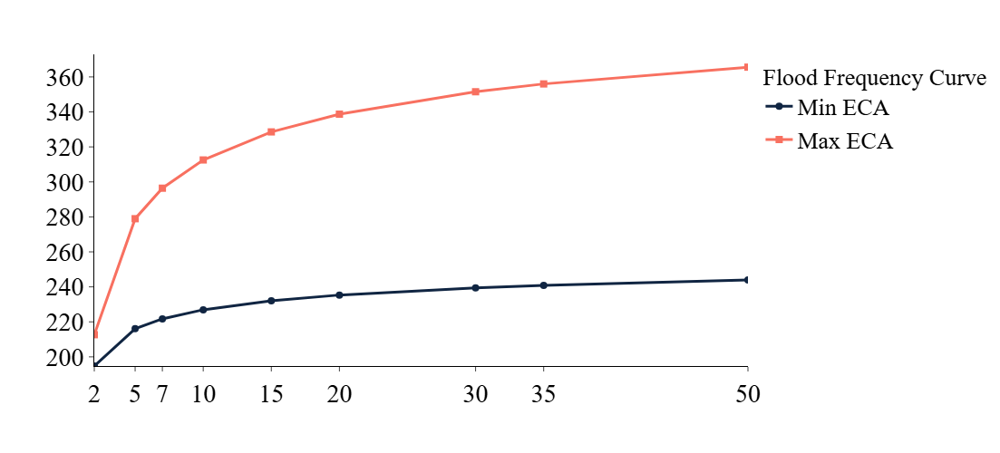

In [51]:
get_legend(
    quant_df,  # quantification_df: DataFrame where Return_Period with Discharge_ECA_Min/Max (and % increase) are stored
    station,
    return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # mapping labels (RP shift)
    show_percentage=True,      # % above the taller vertical line
    # --- legend controls (NEW) ---
    show_legend=True,         # <--- turn legend on/off
    legend_kwargs=None,        # <--- optional dict to position/style legend
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=28,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping / percentage label spacing
    mapping_y_offset=20,       # base lift for in-plot near-axis placement
    percentage_offset=30,      # base lift above taller vertical line for % text
    # --- staggering controls for % labels ---
    stagger_percentages=False, # turn staggering on/off
    percentage_stagger=18,     # extra vertical spacing step for big % labels (≥100)
    # --- soft-clearance controls (scale with data range) ---
    axis_clear_frac=0.03,      # ≥3% of span above x-axis
    line_clear_frac=0.02,      # ≥2% of span away from any line
    # --- saving controls ---
    save=True,
    save_path= r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification",
    save_name=f"legend"
)

# # now for frequency change
# plot_quantification_graph_combined(
#     quant_df,
#     station,
#     return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
#     log_y=False,
#     highlight_rps=[10, 20, 35],
#     # --- what to show ---
#     show_mapping=True,         # <new RP> yr ← <old RP> yr on right
#     show_percentage=False,      # % above the taller vertical line
#     # --- styling controls (template-consistent) ---
#     font_family="Times New Roman",
#     font_size=28,              # one size for all text
#     line_width=3,              # thickness for Min/Max curves
#     marker_size=8,             # circle/square size
#     fig_width=900,
#     fig_height=500,
#     show_titles=True,         # False => no figure/x/y titles
#     # mapping label spacing
#     mapping_y_offset=20,       # vertical spacing between right-side mapping labels
#     percentage_offset=30,      # vertical offset above tallest vertical line for % text
#     stagger_percentages=True, # turn staggering on/off
#     percentage_stagger=18,
#     # --- saving controls ---
#     save=True,
#     save_path= r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Frequency_Changes",
#     save_name=f"Frequency_Change_{station}"
# )

# plot_quantification_graph_combined(
#     quant_df,
#     station,
#     return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
#     log_y=False,
#     highlight_rps=[10, 20, 35],
#     # --- what to show ---
#     show_mapping=False,         # <new RP> yr ← <old RP> yr on right
#     show_percentage=True,      # % above the taller vertical line
#     # --- styling controls (template-consistent) ---
#     font_family="Times New Roman",
#     font_size=28,              # one size for all text
#     line_width=3,              # thickness for Min/Max curves
#     marker_size=8,             # circle/square size
#     fig_width=900,
#     fig_height=500,
#     show_titles=True,         # False => no figure/x/y titles
#     # mapping label spacing
#     mapping_y_offset=20,       # vertical spacing between right-side mapping labels
#     percentage_offset=30,      # vertical offset above tallest vertical line for % text
#     stagger_percentages=True, # turn staggering on/off
#     percentage_stagger=18,
#     # --- saving controls ---
#     save=True,
#     save_path= r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Magnitude Change",
#     save_name=f"Magnitude_Change_{station}"
# )

### Modified Functions

In [18]:
# LEGEND

def get_legend(
    df,  # quantification_df: DataFrame where Return_Period with Discharge_ECA_Min/Max (and % increase) are stored
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # mapping labels (RP shift)
    show_percentage=True,      # % above the taller vertical line
    # --- legend controls (NEW) ---
    show_legend=False,         # <--- turn legend on/off
    legend_kwargs=None,        # <--- optional dict to position/style legend
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping / percentage label spacing
    mapping_y_offset=20,       # base lift for in-plot near-axis placement
    percentage_offset=30,      # base lift above taller vertical line for % text
    # --- staggering controls for % labels ---
    stagger_percentages=False, # turn staggering on/off
    percentage_stagger=18,     # extra vertical spacing step for big % labels (≥100)
    # --- soft-clearance controls (scale with data range) ---
    axis_clear_frac=0.03,      # ≥3% of span above x-axis
    line_clear_frac=0.02,      # ≥2% of span away from any line
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"   # Dark Navy
    max_color   = "#f87060"   # Vibrant Salmon
    guide_color = "#868889"   # visible grey
    text_color  = "black"     # all text in black

    # Flexible columns (keep backwards-compat)
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))
    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves: Min (circles) & Max (squares)
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q,
        mode="lines+markers",
        name="Min ECA",  # <- changed label
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q,
        mode="lines+markers",
        name="Max ECA",  # <- changed label
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline & dynamic clearances
    y_floor = max(0, min(min_Q.min(), max_Q.min()))
    y_peak  = max(min_Q.max(), max_Q.max())
    span    = max(y_peak - y_floor, 1e-9)
    AXIS_CLEAR = axis_clear_frac * span
    LINE_CLEAR = line_clear_frac * span

    def above_axis(y0):
        return max(y0, y_floor + AXIS_CLEAR)

    # Prep mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)

    # Track top-most annotation y for % labels (to pad y-axis later)
    top_label_y_candidates = []
    perc_idx = 0

    # Conditional: put mapping labels below the axis only when both mapping & % are shown
    below_axis_mode = bool(show_mapping and show_percentage)

    # In-plot de-lining memory (when not below-axis)
    used_mapping_y_levels = []
    same_line_tol = max(0.008 * span, 0.4)
    stagger_step  = max(0.012 * span, 0.6)

    for rp in highlight_rps:
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])
        Qmax_at_rp = float(max_Q[max_rps == rp][0]) if rp in max_rps else Qmin_at_rp

        # ----- Guide lines: ALWAYS draw -----
        if show_mapping and (Q_sorted.size >= 2) and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
            # vertical baseline -> Min
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            # horizontal: from Min RP to Max RP at same Q
            rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))
            fig.add_shape(
                type="line",
                x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            # ----- Mapping label -----
            if below_axis_mode:
                fig.add_annotation(
                    x=rp, xref="x",
                    y=-0.16, yref="paper",
                    text=f"<b>{rp_in_max_for_same_Q:.1f} yr \u2190</b>",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="top",
                    align="center"
                )
            else:
                low_line, high_line = min(Qmin_at_rp, Qmax_at_rp), max(Qmin_at_rp, Qmax_at_rp)
                y_candidate = above_axis(y_floor + mapping_y_offset)
                if used_mapping_y_levels:
                    bumped = y_candidate
                    while any(abs(bumped - yy) < same_line_tol for yy in used_mapping_y_levels) and bumped <= (low_line - LINE_CLEAR):
                        bumped += stagger_step
                    y_candidate = bumped

                if y_candidate <= low_line - LINE_CLEAR:
                    y_label = y_candidate
                else:
                    between_low  = low_line  + LINE_CLEAR
                    between_high = high_line - LINE_CLEAR
                    if between_low < between_high:
                        y_label = above_axis(max(between_low, y_floor + AXIS_CLEAR))
                    else:
                        y_label = high_line + LINE_CLEAR

                used_mapping_y_levels.append(y_label)
                fig.add_annotation(
                    x=rp, y=y_label,
                    text=f"<b>{rp_in_max_for_same_Q:.1f} yr \u2190</b>",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )

        # ----- % guide lines + label -----
        if show_percentage and (rp in max_rps) and ("ECA_Flood_Risk_Increase_Percentage" in df.columns):
            fig.add_shape(type="line", x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                          line=dict(color=guide_color, width=2, dash="solid"))
            fig.add_shape(type="line", x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                          line=dict(color=guide_color, width=2, dash="solid"))

            perc_change = float(df.loc[df["Return_Period"] == rp,
                                       "ECA_Flood_Risk_Increase_Percentage"].values[0])
            base_top = max(Qmin_at_rp, Qmax_at_rp)
            tight_gap = max(0.6 * LINE_CLEAR, 0.5)
            y_top_raw = base_top + max(tight_gap, percentage_offset * 0.5)
            if stagger_percentages and abs(perc_change) >= 100:
                y_top_raw += perc_idx * percentage_stagger
                perc_idx += 1
            y_top = above_axis(y_top_raw)
            fig.add_annotation(
                x=rp, y=y_top, text=f"{abs(perc_change):.1f}%",
                showarrow=False,
                font=dict(family=font_family, size=font_size, color=text_color),
                xanchor="center", yanchor="bottom"
            )
            top_label_y_candidates.append(y_top)

    # -------- Layout --------
    title_text = "" if not show_titles else f"{station}"
    bottom_margin = max(70, int(font_size * 3.2)) if below_axis_mode else 60

    # Legend defaults (SIDE placement with title)
    _default_legend = dict(
        orientation="v",                  # vertical stack
        x=1.02, y=1, xanchor="left", yanchor="top",  # side (right) outside
        bgcolor="rgba(0,0,0,0)",
        borderwidth=0,
        title=dict(text="Flood Frequency Curve",
                   font=dict(family=font_family, size=max(font_size-2, 10))),
        font=dict(family=font_family, size=max(font_size-2, 10))
    )
    legend_config = {**_default_legend, **(legend_kwargs or {})}

    # More right margin when legend is outside
    right_margin = max(140, int(font_size * 6)) if show_legend else 80

    fig.update_layout(
        title=dict(text=title_text, x=0.2, xanchor="center", y=1, yanchor="top"),
        xaxis_title="", yaxis_title="",
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width, height=fig_height,
        showlegend=show_legend,
        legend=legend_config if show_legend else None,
        margin=dict(t=60, r=right_margin, b=bottom_margin)
    )

    # X axis: bold tick labels for highlighted RPs
    x_tickvals = return_periods
    x_ticktext = [
        f"<b>{rp}</b>" if (rp in highlight_rps) else str(rp)
        for rp in return_periods
    ]
    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=x_tickvals, ticktext=x_ticktext,
        range=[x_min_tick, x_max_tick], automargin=True
    )

    # Y axis
    if not log_y:
        y_data_top = y_peak
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_data_top
        y_top_final = max(y_data_top, y_labels_top) * 1.02
        fig.update_yaxes(showgrid=False, showline=True, linecolor="black", linewidth=1,
                         range=[y_floor, y_top_final])
    else:
        fig.update_yaxes(showgrid=False, showline=True, linecolor="black", linewidth=1, type="log")

    # Save
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        fig.write_image(os.path.join(save_path, f"{save_name}.svg"))
        fig.write_image(os.path.join(save_path, f"{save_name}.png"), scale=3)

    return fig


In [34]:
# function with guide lines + conditional below-axis mapping + bold ticks/labels

def plot_quantification_graph_combined(
    df,  # quantification_df: DataFrame where Return_Period with Discharge_ECA_Min/Max (and % increase) are stored
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # mapping labels (RP shift)
    show_percentage=True,      # % above the taller vertical line
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping / percentage label spacing
    mapping_y_offset=20,       # base lift for in-plot near-axis placement
    percentage_offset=30,      # base lift above taller vertical line for % text
    # --- staggering controls for % labels ---
    stagger_percentages=False, # turn staggering on/off
    percentage_stagger=18,     # extra vertical spacing step for big % labels (≥100)
    # --- soft-clearance controls (scale with data range) ---
    axis_clear_frac=0.03,      # ≥3% of span above x-axis
    line_clear_frac=0.02,      # ≥2% of span away from any line
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"   # Dark Navy
    max_color   = "#f87060"   # Vibrant Salmon
    guide_color = "#868889"   # visible grey
    text_color  = "black"     # all text in black

    # Flexible columns (keep backwards-compat)
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))
    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves: Min (circles) & Max (squares)
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q,
        mode="lines+markers",
        name="Min",
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q,
        mode="lines+markers",
        name="Max",
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline & dynamic clearances
    y_floor = max(0, min(min_Q.min(), max_Q.min()))
    y_peak  = max(min_Q.max(), max_Q.max())
    span    = max(y_peak - y_floor, 1e-9)
    AXIS_CLEAR = axis_clear_frac * span
    LINE_CLEAR = line_clear_frac * span

    def above_axis(y0):
        return max(y0, y_floor + AXIS_CLEAR)

    # Prep mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)

    # Track top-most annotation y for % labels (to pad y-axis later)
    top_label_y_candidates = []
    perc_idx = 0

    # Conditional: put mapping labels below the axis only when both mapping & % are shown
    below_axis_mode = bool(show_mapping and show_percentage)

    # In-plot de-lining memory (when not below-axis)
    used_mapping_y_levels = []
    same_line_tol = max(0.008 * span, 0.4)
    stagger_step  = max(0.012 * span, 0.6)

    for rp in highlight_rps:
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])
        Qmax_at_rp = float(max_Q[max_rps == rp][0]) if rp in max_rps else Qmin_at_rp

        # ----- Guide lines: ALWAYS draw (they were in your original) -----
        if show_mapping and (Q_sorted.size >= 2) and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
            # vertical baseline -> Min
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            # horizontal: from Min RP to Max RP at same Q
            rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))
            fig.add_shape(
                type="line",
                x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            # ----- Mapping label -----
            if below_axis_mode:
                # BELOW the x-axis, under tick labels, aligned with RP (bold)
                fig.add_annotation(
                    x=rp, xref="x",
                    y=-0.16, yref="paper",  # tweak to taste: -0.14 ... -0.18
                    text=f"<b>{rp_in_max_for_same_Q:.1f} yr \u2190</b>",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="top",
                    align="center"
                )
            else:
                # Adaptive in-plot placement:
                # prefer near axis; else just above lower line; else just above higher line
                low_line, high_line = min(Qmin_at_rp, Qmax_at_rp), max(Qmin_at_rp, Qmax_at_rp)

                # 1) near axis (strictly below lower line)
                y_candidate = above_axis(y_floor + mapping_y_offset)
                if used_mapping_y_levels:
                    bumped = y_candidate
                    while any(abs(bumped - yy) < same_line_tol for yy in used_mapping_y_levels) and bumped <= (low_line - LINE_CLEAR):
                        bumped += stagger_step
                    y_candidate = bumped

                if y_candidate <= low_line - LINE_CLEAR:
                    y_label = y_candidate
                else:
                    # 2) between: as low as possible (just above lower)
                    between_low  = low_line  + LINE_CLEAR
                    between_high = high_line - LINE_CLEAR
                    if between_low < between_high:
                        y_label = above_axis(max(between_low, y_floor + AXIS_CLEAR))
                    else:
                        # 3) above: just above higher
                        y_label = high_line + LINE_CLEAR

                used_mapping_y_levels.append(y_label)

                fig.add_annotation(
                    x=rp, y=y_label,
                    text=f"<b>{rp_in_max_for_same_Q:.1f} yr \u2190</b>",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )

        # ----- % guide lines + label (tight above the taller line) -----
        if show_percentage and (rp in max_rps) and ("ECA_Flood_Risk_Increase_Percentage" in df.columns):
            # vertical baseline -> Min
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            # vertical baseline -> Max
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            perc_change = float(df.loc[df["Return_Period"] == rp,
                                       "ECA_Flood_Risk_Increase_Percentage"].values[0])
            base_top = max(Qmin_at_rp, Qmax_at_rp)
            tight_gap = max(0.6 * LINE_CLEAR, 0.5)  # small but safe
            y_top_raw = base_top + max(tight_gap, percentage_offset * 0.5)

            if stagger_percentages and abs(perc_change) >= 100:
                y_top_raw += perc_idx * percentage_stagger
                perc_idx += 1

            y_top = above_axis(y_top_raw)
            fig.add_annotation(
                x=rp, y=y_top,
                text=f"{abs(perc_change):.1f}%",
                showarrow=False,
                font=dict(family=font_family, size=font_size, color=text_color),
                xanchor="center",
                yanchor="bottom"
            )
            top_label_y_candidates.append(y_top)

    # -------- Layout --------
    title_text = "" if not show_titles else f"{station}"

    # Extra room at the bottom only when below-axis labels are used
    bottom_margin = max(70, int(font_size * 3.2)) if below_axis_mode else 60

    fig.update_layout(
        title=dict(
            text=title_text, x=0.2, xanchor="center", y=1, yanchor="top",
            font=dict(family=font_family, size=font_size, color=text_color)
        ),
        xaxis_title="",   # no x title
        yaxis_title="",   # no y title
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width,
        height=fig_height,
        showlegend=False,
        margin=dict(t=60, r=80, b=bottom_margin)
    )

    # X axis: bold tick labels for highlighted RPs
    x_tickvals = return_periods
    x_ticktext = [
        f"<b>{rp}</b>" if (rp in highlight_rps) else str(rp)
        for rp in return_periods
    ]

    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=x_tickvals, ticktext=x_ticktext,
        range=[x_min_tick, x_max_tick],
        automargin=True
    )

    # Y axis: pad to include % labels (linear only)
    if not log_y:
        y_data_top = y_peak
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_data_top
        y_top_final = max(y_data_top, y_labels_top) * 1.02  # small headroom
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            range=[y_floor, y_top_final]
        )
    else:
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            type="log"
        )

    # Save both SVG & PNG (scale=3)
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        svg_path = os.path.join(save_path, f"{save_name}.svg")
        png_path = os.path.join(save_path, f"{save_name}.png")
        fig.write_image(svg_path)
        fig.write_image(png_path, scale=3)

    return fig

In [37]:
# X function with stagger + adaptive mapping label that avoids "same line" look
def plot_quantification_graph_combined(
    df,
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # mapping label prefers near x-axis; else just above lower; else above higher
    show_percentage=True,      # % above the taller vertical line (kept tight)
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,
    line_width=3,
    marker_size=8,
    fig_width=900,
    fig_height=500,
    show_titles=False,
    # mapping / percentage label spacing
    mapping_y_offset=20,
    percentage_offset=30,
    # --- staggering controls for % labels ---
    stagger_percentages=False,
    percentage_stagger=18,
    # --- soft-clearance controls (scale with data range) ---
    axis_clear_frac=0.03,      # ≥3% of span above x-axis
    line_clear_frac=0.02,      # ≥2% of span away from any line
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"
    max_color   = "#f87060"
    guide_color = "#868889"
    text_color  = "black"

    # Flexible columns
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q, mode="lines+markers", name="Min",
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q, mode="lines+markers", name="Max",
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline & dynamic clearances
    y_floor = max(0, min(min_Q.min(), max_Q.min()))
    y_peak  = max(min_Q.max(), max_Q.max())
    span    = max(y_peak - y_floor, 1e-9)
    AXIS_CLEAR = axis_clear_frac * span
    LINE_CLEAR = line_clear_frac * span

    def above_axis(y0):
        return max(y0, y_floor + AXIS_CLEAR)

    # Prep mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)
    x_right = x_max_tick + 5

    top_label_y_candidates = []
    perc_idx = 0

    # Keep track of y-levels we already used for mapping labels near the axis,
    # so they don't all sit on the exact same horizontal line
    used_mapping_y_levels = []
    same_line_tol = max(0.008 * span, 0.4)   # how close counts as "same line"
    stagger_step  = max(0.012 * span, 0.6)   # how much to bump if colliding

    for rp in highlight_rps:
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])

        # ----- (A) Mapping guides & label placement -----
        if show_mapping:
            if Q_sorted.size >= 2 and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
                rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))
                Qmax_at_rp = float(max_Q[max_rps == rp][0]) if rp in max_rps else Qmin_at_rp

                low_line  = min(Qmin_at_rp, Qmax_at_rp)
                high_line = max(Qmin_at_rp, Qmax_at_rp)

                # Guides
                fig.add_shape(type="line", x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                              line=dict(color=guide_color, width=2, dash="solid"))
                fig.add_shape(type="line", x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                              line=dict(color=guide_color, width=2, dash="solid"))

                # 1) Preferred: near x-axis (strictly below lower line by LINE_CLEAR)
                y_candidate = above_axis(y_floor + mapping_y_offset)

                # Slight de-lining: if this y is basically the same as a previously placed mapping label,
                # nudge it up by small steps — but keep it BELOW the lower curve if possible.
                if used_mapping_y_levels:
                    bumped = y_candidate
                    while any(abs(bumped - yy) < same_line_tol for yy in used_mapping_y_levels) and bumped <= (low_line - LINE_CLEAR):
                        bumped += stagger_step
                    y_candidate = bumped

                if y_candidate <= low_line - LINE_CLEAR:
                    y_label = y_candidate
                else:
                    # 2) If we can't sit below lower line, try BETWEEN:
                    # Place as low as possible while staying above the lower line by LINE_CLEAR,
                    # and below the upper line by LINE_CLEAR. This keeps it "a bit higher than the lower line".
                    between_low  = low_line  + LINE_CLEAR
                    between_high = high_line - LINE_CLEAR
                    if between_low < between_high:
                        y_label = max(above_axis(between_low), between_low)  # stay as low as allowed
                        # (No midpoint jump; we hug the lower bound of the safe gap.)
                    else:
                        # 3) No room between — place just above the higher line
                        y_label = high_line + LINE_CLEAR

                # Record used level (only for near-axis-ish labels; but harmless to record all)
                used_mapping_y_levels.append(y_label)

                fig.add_annotation(
                    x=rp,
                    y=y_label,
                    text=f"{rp_in_max_for_same_Q:.1f} yr \u2190",  # "47 yr ←"
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )
                top_label_y_candidates.append(y_label)

        # ----- (B) Percentage magnitude guides & top label (tight) -----
        if show_percentage and (rp in max_rps) and ("ECA_Flood_Risk_Increase_Percentage" in df.columns):
            Qmax_at_rp = float(max_Q[max_rps == rp][0])

            fig.add_shape(type="line", x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                          line=dict(color=guide_color, width=2, dash="solid"))
            fig.add_shape(type="line", x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                          line=dict(color=guide_color, width=2, dash="solid"))

            perc_change = float(df.loc[df["Return_Period"] == rp,
                                       "ECA_Flood_Risk_Increase_Percentage"].values[0])

            base_top = max(Qmin_at_rp, Qmax_at_rp)
            # keep % closer to the line than before
            tight_gap = max(0.6 * LINE_CLEAR, 0.5)  # very small, but safe
            y_top = above_axis(base_top + max(tight_gap, percentage_offset * 0.5))

            if stagger_percentages and abs(perc_change) >= 100:
                y_top += perc_idx * percentage_stagger
                perc_idx += 1

            fig.add_annotation(
                x=rp,
                y=y_top,
                text=f"{abs(perc_change):.1f}%",
                showarrow=False,
                font=dict(family=font_family, size=font_size, color=text_color),
                xanchor="center",
                yanchor="bottom"
            )
            top_label_y_candidates.append(y_top)

    # -------- Layout --------
    title_text = "" if not show_titles else f"{station}"
    fig.update_layout(
        title=dict(text=title_text, x=0.2, xanchor="center", y=1, yanchor="top"),
        xaxis_title="", yaxis_title="",
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width,
        height=fig_height,
        showlegend=False,
        margin=dict(t=60, r=140)
    )

    # X axis
    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=return_periods, ticktext=[str(rp) for rp in return_periods],
        range=[x_min_tick, x_right]
    )

    # Y axis
    if not log_y:
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_peak
        y_top_final = max(y_peak, y_labels_top) * 1.02
        fig.update_yaxes(showgrid=False, showline=True, linecolor="black", linewidth=1,
                         range=[y_floor, y_top_final])
    else:
        fig.update_yaxes(showgrid=False, showline=True, linecolor="black", linewidth=1,
                         type="log")

    # Save
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        svg_path = os.path.join(save_path, f"{save_name}.svg")
        png_path = os.path.join(save_path, f"{save_name}.png")
        fig.write_image(svg_path)
        fig.write_image(png_path, scale=3)

    return fig

In [23]:
#X function with stagger + clearance so labels don't hit axis/lines
def plot_quantification_graph_combined(
    df,
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # mapping label now drawn above the RP at x=rp (→ x yr)
    show_percentage=True,      # % above the taller vertical line
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping / percentage label spacing
    mapping_y_offset=20,       # base lift for mapping label above Min line at RP
    percentage_offset=30,      # base lift above taller vertical line for % text
    # --- staggering controls for % labels ---
    stagger_percentages=False, # turn staggering on/off
    percentage_stagger=18,     # extra vertical spacing step for big % labels (≥100)
    # --- NEW: soft-clearance controls (scale with data range) ---
    axis_clear_frac=0.03,      # keep labels at least 3% of span above x-axis
    line_clear_frac=0.02,      # keep labels ≥2% of span above nearest line
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"   # Dark Navy
    max_color   = "#f87060"   # Vibrant Salmon
    guide_color = "#868889"   # visible grey
    text_color  = "black"     # all text in black

    # Flexible columns
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    # Guard: if nothing matched, stop early to avoid .min() on empty arrays
    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves: Min (circles) & Max (squares)
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q,
        mode="lines+markers",
        name="Min",
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q,
        mode="lines+markers",
        name="Max",
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline for vertical guides (and compute dynamic clearances)
    y_floor = max(0, min(min_Q.min(), max_Q.min()))
    y_peak  = max(min_Q.max(), max_Q.max())
    span    = max(y_peak - y_floor, 1e-9)  # avoid zero span
    AXIS_CLEAR = axis_clear_frac * span
    LINE_CLEAR = line_clear_frac * span

    # Helper to lift labels so they don't sit on x-axis or touch lines
    def lift_label(y_candidate, nearest_line_y):
        # keep above x-axis
        y_final = max(y_candidate, y_floor + AXIS_CLEAR)
        # keep above the closest plotted line at this x
        if nearest_line_y is not None:
            y_final = max(y_final, nearest_line_y + LINE_CLEAR)
        return y_final

    # Prep for mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    # Right edge kept (range pad)
    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)
    x_right = x_max_tick + 5

    # Track top-most annotation y to pad y-axis later (so nothing clips)
    top_label_y_candidates = []

    # Iterate highlights
    perc_idx = 0  # percentage label staggering counter (only for ≥100%)

    for rp in highlight_rps:
        # Need Min at this RP
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])

        # ----- (A) RP mapping guides & label placed above RP at x=rp -----
        if show_mapping:
            if Q_sorted.size >= 2 and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
                rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))

                # vertical baseline->Min
                fig.add_shape(
                    type="line",
                    x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )
                # horizontal Min RP → Max RP at same Q
                fig.add_shape(
                    type="line",
                    x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )

                # Base label position above Min line
                y_label_raw = Qmin_at_rp + mapping_y_offset
                # Lift to avoid x-axis & touching the Min line
                y_label = lift_label(y_label_raw, nearest_line_y=Qmin_at_rp)

                fig.add_annotation(
                    x=rp,
                    y=y_label,
                    text=f"{rp_in_max_for_same_Q:.1f} yr \u2190",  # "x yr <- "
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )
                top_label_y_candidates.append(y_label)

        # ----- (B) Percentage magnitude guides & top label -----
        if show_percentage and (rp in max_rps):
            Qmax_at_rp = float(max_Q[max_rps == rp][0])

            # two vertical lines: baseline->Min and baseline->Max
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            if "ECA_Flood_Risk_Increase_Percentage" in df.columns:
                perc_change = float(df.loc[df["Return_Period"] == rp,
                                           "ECA_Flood_Risk_Increase_Percentage"].values[0])

                # base y position: above the taller of Min/Max lines
                base_top = max(Qmin_at_rp, Qmax_at_rp)
                y_top_raw = base_top + percentage_offset

                # optional stagger for big values (≥100)
                if stagger_percentages and abs(perc_change) >= 100:
                    y_top_raw += perc_idx * percentage_stagger
                    perc_idx += 1

                # Lift to avoid x-axis and touching the taller line
                y_top = lift_label(y_top_raw, nearest_line_y=base_top)

                fig.add_annotation(
                    x=rp,
                    y=y_top,
                    text=f"{abs(perc_change):.1f}%",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )
                top_label_y_candidates.append(y_top)

    # -------- Layout (unchanged look) --------
    title_text = "" if not show_titles else f"{station}"

    fig.update_layout(
        title=dict(text=title_text, x=0.2, xanchor="center", y= 1, yanchor="top"),
        xaxis_title="",   # no x title
        yaxis_title="",   # no y title
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width,
        height=fig_height,
        showlegend=False,
        margin=dict(t=60, r=140)
    )

    # X axis: ticks + keep right padding
    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=return_periods, ticktext=[str(rp) for rp in return_periods],
        range=[x_min_tick, x_right]
    )

    # Y axis: pad to include top labels (linear only)
    if not log_y:
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_peak
        y_top_final = max(y_peak, y_labels_top) * 1.02  # small headroom
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            range=[y_floor, y_top_final]
        )
    else:
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            type="log"
        )

    # Save both SVG & PNG (scale=3)
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        svg_path = os.path.join(save_path, f"{save_name}.svg")
        png_path = os.path.join(save_path, f"{save_name}.png")
        fig.write_image(svg_path)
        fig.write_image(png_path, scale=3)

    return fig


In [24]:
# Xfunction with stagger
def plot_quantification_graph_combined(
    df,
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # <new RP> yr ← <old RP> yr on right
    show_percentage=True,      # % above the taller vertical line
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping label spacing
    mapping_y_offset=20,       # vertical spacing between right-side mapping labels
    percentage_offset=30,      # vertical offset above tallest vertical line for % text
    # --- NEW: staggering controls for % labels ---
    stagger_percentages=False, # turn staggering on/off
    percentage_stagger=18,     # extra vertical spacing step for big % labels (≥100)
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"   # Dark Navy
    max_color   = "#f87060"   # Vibrant Salmon
    guide_color = "#868889"   # visible grey
    text_color  = "black"     # all text in black

    # Flexible columns
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    # Guard: if nothing matched, stop early to avoid .min() on empty arrays
    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves: Min (circles) & Max (squares)
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q,
        mode="lines+markers",
        name="Min",
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q,
        mode="lines+markers",
        name="Max",
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline for vertical guides
    y_floor = max(0, min(min_Q.min(), max_Q.min()))

    # Prep for mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    # Right edge for mapping labels (ensure we pad x-range later)
    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)
    x_right = x_max_tick + 5  # keep your offset

    # Track top-most annotation y to pad y-axis later (so nothing clips)
    top_label_y_candidates = []

    # Iterate highlights
    map_idx = 0  # separate counter for mapping label spacing
    perc_idx = 0 # NEW: percentage label staggering counter (only for ≥100%)

    for rp in highlight_rps:
        # Need Min at this RP
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])

        # ----- (A) RP mapping guides & right-side label -----
        if show_mapping:
            if Q_sorted.size >= 2 and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
                rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))

                # vertical from baseline up to Min discharge
                fig.add_shape(
                    type="line",
                    x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )
                # horizontal from Min RP over to Max RP at same Q
                fig.add_shape(
                    type="line",
                    x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )
                # right-side mapping label, staggered vertically
                y_label = Qmin_at_rp + map_idx * mapping_y_offset - 10
                fig.add_annotation(
                    x=x_right - 7,
                    y=y_label,
                    text=f"{rp_in_max_for_same_Q:.1f} yr \u2190 {rp} yr",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="left",
                    yanchor="middle"
                )
                top_label_y_candidates.append(y_label)
                map_idx += 1  # advance spacing index

        # ----- (B) Percentage magnitude guides & top label -----
        if show_percentage and (rp in max_rps):
            Qmax_at_rp = float(max_Q[max_rps == rp][0])

            # two vertical lines: baseline->Min and baseline->Max
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            # % change above taller line (if column exists)
            if "ECA_Flood_Risk_Increase_Percentage" in df.columns:
                perc_change = float(df.loc[df["Return_Period"] == rp,
                                           "ECA_Flood_Risk_Increase_Percentage"].values[0])

                # base y position
                y_top = max(Qmin_at_rp, Qmax_at_rp) + percentage_offset

                # NEW: add stagger ONLY if enabled and value is "big" (≥100)
                if stagger_percentages and abs(perc_change) >= 100:
                    y_top += perc_idx * percentage_stagger
                    perc_idx += 1  # only advance for big % labels

                fig.add_annotation(
                    x=rp,
                    y=y_top,
                    text=f"{abs(perc_change):.1f}%",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )
                top_label_y_candidates.append(y_top)

    # -------- Layout (exactly as you asked) --------
    title_text = "" if not show_titles else f"{station}"

    fig.update_layout(
        title=dict(text=title_text, x=0.2, xanchor="center", y= 1, yanchor="top"),
        xaxis_title="",   # no x title
        yaxis_title="",   # no y title
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width,
        height=fig_height,
        showlegend = False,
        margin=dict(t=60, r=140)
    )

    # X axis: show ticks you requested + include right-side labels in range
    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=return_periods, ticktext=[str(rp) for rp in return_periods],
        range=[x_min_tick, x_right]  # ensure right-side annotations are visible
    )

    # Y axis: keep no-grid + line, and pad to include top labels (linear only)
    if not log_y:
        y_data_top = max(min_Q.max(), max_Q.max())
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_data_top
        y_top_final = max(y_data_top, y_labels_top) * 1.02  # small headroom
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            range=[y_floor, y_top_final]
        )
    else:
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            type="log"
        )

    # Save both SVG & PNG (scale=3)
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        svg_path = os.path.join(save_path, f"{save_name}.svg")
        png_path = os.path.join(save_path, f"{save_name}.png")
        fig.write_image(svg_path)
        fig.write_image(png_path, scale=3)

    return fig

In [25]:
# Xfunction without stagger
def plot_quantification_graph_combined(
    df,
    station,
    return_periods=None,
    log_y=False,
    highlight_rps=None,
    # --- what to show ---
    show_mapping=True,         # <new RP> yr ← <old RP> yr on right
    show_percentage=True,      # % above the taller vertical line
    # --- styling controls (template-consistent) ---
    font_family="Times New Roman",
    font_size=18,              # one size for all text
    line_width=3,              # thickness for Min/Max curves
    marker_size=8,             # circle/square size
    fig_width=900,
    fig_height=500,
    show_titles=False,         # False => no figure/x/y titles
    # mapping label spacing
    mapping_y_offset=20,       # vertical spacing between right-side mapping labels
    percentage_offset=30,      # vertical offset above tallest vertical line for % text
    # --- saving controls ---
    save=False,
    save_path=None,
    save_name=None
):
    if return_periods is None:
        return_periods = [2, 5, 10, 20, 30, 35, 50, 100]
    if highlight_rps is None:
        highlight_rps = []

    # Colors (template)
    min_color   = "#102542"   # Dark Navy
    max_color   = "#f87060"   # Vibrant Salmon
    guide_color = "#868889"   # visible grey
    text_color  = "black"     # all text in black

    # Flexible columns
    if "Valid_ECA_Min" in df.columns:
        _min_eca = df["Valid_ECA_Min"].unique()[0]
        _max_eca = df["Valid_ECA_Max"].unique()[0]
    elif "ECA_Min_Valid" in df.columns:
        _min_eca = df["ECA_Min_Valid"].unique()[0]
        _max_eca = df["ECA_Max_Valid"].unique()[0]
    else:
        raise ValueError("Expected ECA columns not found in DataFrame.")

    # Build series for requested RPs
    min_vals, max_vals = [], []
    for rp in return_periods:
        row = df[df["Return_Period"] == rp]
        if not row.empty:
            min_vals.append((rp, row["Discharge_ECA_Min"].values[0]))
            max_vals.append((rp, row["Discharge_ECA_Max"].values[0]))

    # Guard: if nothing matched, stop early to avoid .min() on empty arrays
    if not min_vals or not max_vals:
        raise ValueError("No matching rows for the given return_periods.")

    # Arrays
    min_rps = np.array([rp for rp, _ in min_vals])
    min_Q   = np.array([val for _, val in min_vals])
    max_rps = np.array([rp for rp, _ in max_vals])
    max_Q   = np.array([val for _, val in max_vals])

    fig = go.Figure()

    # Curves: Min (circles) & Max (squares)
    fig.add_trace(go.Scatter(
        x=min_rps, y=min_Q,
        mode="lines+markers",
        name="Min",
        line=dict(color=min_color, width=line_width),
        marker=dict(symbol="circle", color=min_color, size=marker_size)
    ))
    fig.add_trace(go.Scatter(
        x=max_rps, y=max_Q,
        mode="lines+markers",
        name="Max",
        line=dict(color=max_color, width=line_width),
        marker=dict(symbol="square", color=max_color, size=marker_size)
    ))

    # Baseline for vertical guides
    y_floor = max(0, min(min_Q.min(), max_Q.min()))

    # Prep for mapping (RP as function of Q on Max)
    sort_idx = np.argsort(max_Q)
    Q_sorted = max_Q[sort_idx]
    RP_sorted = max_rps[sort_idx]

    # Right edge for mapping labels (ensure we pad x-range later)
    x_min_tick = min(return_periods)
    x_max_tick = max(return_periods)
    x_right = x_max_tick + 5  # keep your offset

    # Track top-most annotation y to pad y-axis later (so nothing clips)
    top_label_y_candidates = []

    # Iterate highlights
    map_idx = 0  # separate counter for mapping label spacing
    for rp in highlight_rps:
        # Need Min at this RP
        if rp not in min_rps:
            continue

        Qmin_at_rp = float(min_Q[min_rps == rp][0])

        # ----- (A) RP mapping guides & right-side label -----
        if show_mapping:
            if Q_sorted.size >= 2 and (Qmin_at_rp >= Q_sorted.min()) and (Qmin_at_rp <= Q_sorted.max()):
                rp_in_max_for_same_Q = float(np.interp(Qmin_at_rp, Q_sorted, RP_sorted))

                # vertical from baseline up to Min discharge
                fig.add_shape(
                    type="line",
                    x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )
                # horizontal from Min RP over to Max RP at same Q
                fig.add_shape(
                    type="line",
                    x0=rp, y0=Qmin_at_rp, x1=rp_in_max_for_same_Q, y1=Qmin_at_rp,
                    line=dict(color=guide_color, width=2, dash="solid")
                )
                # right-side mapping label, staggered vertically
                y_label = Qmin_at_rp + map_idx * mapping_y_offset - 10
                fig.add_annotation(
                    x=x_right - 7,
                    y=y_label,
                    text=f"{rp_in_max_for_same_Q:.1f} yr \u2190 {rp} yr",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="left",
                    yanchor="middle"
                )
                top_label_y_candidates.append(y_label)
                map_idx += 1  # advance spacing index

        # ----- (B) Percentage magnitude guides & top label -----
        if show_percentage and (rp in max_rps):
            Qmax_at_rp = float(max_Q[max_rps == rp][0])

            # two vertical lines: baseline->Min and baseline->Max
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmin_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )
            fig.add_shape(
                type="line",
                x0=rp, y0=y_floor, x1=rp, y1=Qmax_at_rp,
                line=dict(color=guide_color, width=2, dash="solid")
            )

            # % change above taller line (if column exists)
            if "ECA_Flood_Risk_Increase_Percentage" in df.columns:
                perc_change = float(df.loc[df["Return_Period"] == rp,
                                           "ECA_Flood_Risk_Increase_Percentage"].values[0])
                y_top = max(Qmin_at_rp, Qmax_at_rp) + percentage_offset
                fig.add_annotation(
                    x=rp,
                    y=y_top,
                    text=f"{abs(perc_change):.1f}%",
                    showarrow=False,
                    font=dict(family=font_family, size=font_size, color=text_color),
                    xanchor="center",
                    yanchor="bottom"
                )
                top_label_y_candidates.append(y_top)

    # -------- Layout (exactly as you asked) --------
    title_text = "" if not show_titles else f"{station}"

    fig.update_layout(
        title=dict(text=title_text, x=0.2, xanchor="center", y= 1, yanchor="top"),
        xaxis_title="",   # no x title
        yaxis_title="",   # no y title
        font=dict(family=font_family, size=font_size, color=text_color),
        template="simple_white",
        width=fig_width,
        height=fig_height,
        showlegend = False,
        # legend=dict(
        #     title=None,           # no legend title
        #     orientation="v",      # vertical stack
        #     x=1.02, y=1.0,        # right side, outside plot
        #     xanchor="left", yanchor="top",
        #     bgcolor="rgba(255,255,255,0.0)",  # transparent
        #     bordercolor="lightgrey", borderwidth=0,
        #     font=dict(family=font_family, size=font_size, color=text_color)
        # ),
        margin=dict(t=60, r=140)  # extra right margin so legend fits
    )

    # X axis: show ticks you requested + include right-side labels in range
    fig.update_xaxes(
        showgrid=False, showline=True, linecolor="black", linewidth=1,
        tickmode="array", tickvals=return_periods, ticktext=[str(rp) for rp in return_periods],
        range=[x_min_tick, x_right]  # ensure right-side annotations are visible
    )

    # Y axis: keep no-grid + line, and pad to include top labels (linear only)
    if not log_y:
        y_data_top = max(min_Q.max(), max_Q.max())
        y_labels_top = max(top_label_y_candidates) if top_label_y_candidates else y_data_top
        y_top_final = max(y_data_top, y_labels_top) * 1.02  # small headroom
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            range=[y_floor, y_top_final]
        )
    else:
        fig.update_yaxes(
            showgrid=False, showline=True, linecolor="black", linewidth=1,
            type="log"
        )

    # Save both SVG & PNG (scale=3)
    if save:
        if not save_path or not save_name:
            raise ValueError("Please specify both save_path and save_name if save=True.")
        os.makedirs(save_path, exist_ok=True)
        svg_path = os.path.join(save_path, f"{save_name}.svg")
        png_path = os.path.join(save_path, f"{save_name}.png")
        fig.write_image(svg_path)
        fig.write_image(png_path, scale=3)

    return fig


### Loop

In [35]:
station_list = [
    "02AB006",
    "02AC002",
    "02AD010",
    "02CC005",
    "02CE002",
    "02JC008",
    "04JD005",
    "04LM001",
    "04MF001",
    "05QD016",
    "05QE009"
]

In [24]:

for station in station_list:
    
    quant_df = get_dataframe(station, quant_dir)
    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        # --- what to show ---
        show_mapping=True,         # <new RP> yr ← <old RP> yr on right
        show_percentage=True,      # % above the taller vertical line
        # --- styling controls (template-consistent) ---
        font_family="Times New Roman",
        font_size=34,              # one size for all text
        line_width=5,              # thickness for Min/Max curves
        marker_size=8,             # circle/square size
        fig_width=900,
        fig_height=500,
        show_titles=True,         # False => no figure/x/y titles
        # mapping label spacing
        mapping_y_offset=20,       # vertical spacing between right-side mapping labels
        percentage_offset=30, 
        # vertical offset above tallest vertical line for % text
        stagger_percentages=True, # turn staggering on/off
        percentage_stagger=18,
        # --- saving controls ---
        save=True,
        save_path= r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Frequency_Magnitude",
        save_name=f"FFC_Change_{station}_Mag_Fre"
    )
    
    # now for frequency change
    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        # --- what to show ---
        show_mapping=True,         # <new RP> yr ← <old RP> yr on right
        show_percentage=False,      # % above the taller vertical line
        # --- styling controls (template-consistent) ---
        font_family="Times New Roman",
        font_size=34,              # one size for all text
        line_width=5,              # thickness for Min/Max curves
        marker_size=8,             # circle/square size
        fig_width=900,
        fig_height=500,
        show_titles=True,         # False => no figure/x/y titles
        # mapping label spacing
        mapping_y_offset=20,       # vertical spacing between right-side mapping labels
        percentage_offset=30, 
        # vertical offset above tallest vertical line for % text
        stagger_percentages=True, # turn staggering on/off
        percentage_stagger=18,
        # --- saving controls ---
        save=True,
        save_path=r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Frequency_Changes",
        save_name=f"Frequency_Change_{station}"
    )
    
    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        # --- what to show ---
        show_mapping=False,         # <new RP> yr ← <old RP> yr on right
        show_percentage=True,      # % above the taller vertical line
        # --- styling controls (template-consistent) ---
        font_family="Times New Roman",
        font_size=34,              # one size for all text
        line_width=5,              # thickness for Min/Max curves
        marker_size=8,             # circle/square size
        fig_width=900,
        fig_height=500,
        show_titles=True,         # False => no figure/x/y titles
        # mapping label spacing
        mapping_y_offset=20,       # vertical spacing between right-side mapping labels
        percentage_offset=30, 
        # vertical offset above tallest vertical line for % text
        stagger_percentages=True, # turn staggering on/off
        percentage_stagger=18,
        # --- saving controls ---
        save=True,
        save_path= r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Magnitude Change",
        save_name=f"Magnitude_Change_{station}"
    )

In [39]:
scale = 4  # <-- change this to resize everything (e.g., 0.9, 1.1, 1.25)

for station in station_list:
    
    quant_df = get_dataframe(station, quant_dir)

    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        show_mapping=True,
        show_percentage=True,

        font_family="Times New Roman",
        font_size=int(34 * scale),
        line_width=5 * scale,
        marker_size=8 * scale,
        fig_width=int(900 * scale),
        fig_height=int(500 * scale),

        show_titles=True,
        mapping_y_offset=20 * scale,
        percentage_offset=30 * scale,
        stagger_percentages=True,
        percentage_stagger=18 * scale,

        save=True,
        save_path=r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Frequency_Magnitude",
        save_name=f"FFC_Change_{station}_Mag_Fre"
    )
    
    # --- frequency change ---
    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        show_mapping=True,
        show_percentage=False,

        font_family="Times New Roman",
        font_size=int(34 * scale),
        line_width=5 * scale,
        marker_size=8 * scale,
        fig_width=int(900 * scale),
        fig_height=int(500 * scale),

        show_titles=True,
        mapping_y_offset=20 * scale,
        percentage_offset=30 * scale,
        stagger_percentages=True,
        percentage_stagger=18 * scale,

        save=True,
        save_path=r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Frequency_Changes",
        save_name=f"Frequency_Change_{station}"
    )
    
    # --- magnitude change ---
    plot_quantification_graph_combined(
        quant_df,
        station,
        return_periods=[2, 5, 7, 10, 15, 20, 30, 35, 50],
        log_y=False,
        highlight_rps=[10, 20, 35],
        show_mapping=False,
        show_percentage=True,

        font_family="Times New Roman",
        font_size=int(34 * scale),
        line_width=5 * scale,
        marker_size=8 * scale,
        fig_width=int(900 * scale),
        fig_height=int(500 * scale),

        show_titles=True,
        mapping_y_offset=20 * scale,
        percentage_offset=30 * scale,
        stagger_percentages=True,
        percentage_stagger=18 * scale,

        save=True,
        save_path=r"C:\Users\Ellie\OneDrive - University of Toronto\MSc_Thesis\Thesis_Outputs\Figures\Publication_Quantification\Magnitude Change",
        save_name=f"Magnitude_Change_{station}"
    )
